# SOBUSA · Entregable 1 — Notebook unificado

Los **19 notebooks** del proyecto, en orden y en un solo archivo. El código de cada uno va con sus celdas de texto, sin cambios
salvo los 3 ajustes de la tabla final. Los **25 scripts `.py`** están en un solo archivo, `sobusa_codigo_unificado.py`.

| Parte | Contenido | Notebook original |
|---|---|---|
| 1 | Subfase 1.1 · Inspección estructural | `subfase_1_1_inspeccion (1).ipynb` |
| 2 | Subfase 1.2 · Validez de viajes y atrición | `subfase_1_2_validez.ipynb` |
| 3 | Subfase 1.3 · Sensores, bloqueos y puertas | `subfase_1_3_sensores.ipynb` |
| 4 | Subfase 1.4 · Nulos, imputación y tablas maestras | `subfase_1_4_maestra.ipynb` |
| 5 | Subfase 2.1 · Descriptivo del objetivo | `subfase_2_1_descriptivo.ipynb` |
| 6 | Subfase 2.2 · Poisson vs Tweedie | `subfase_2_2_tweedie.ipynb` |
| 7 | Subfase 2.3 · Atípicos del objetivo | `subfase_2_3_outliers.ipynb` |
| 8 | Subfase 2.4 · Métrica de evaluación | `subfase_2_4_metrica.ipynb` |
| 9 | Módulos 3–5 · Temporal, espacial y multicolinealidad | `modulo_3_5_espaciotemporal.ipynb` |
| 10 | Subfase 6.0 · Decisiones del Módulo 6 | `subfase_6_0_decisiones.ipynb` |
| 11 | Subfase 6.1 · Features por viaje | `subfase_6_1_features.ipynb` |
| 12 | Subfase 6.2 · Lag espacial | `subfase_6_2_espacial.ipynb` |
| 13 | Subfase 6.3 · Auditoría de leakage | `subfase_6_3_auditoria.ipynb` |
| 14 | Subfase 7.1 · Partición walk-forward | `subfase_7_1_particion.ipynb` |
| 15 | Subfase 7.2 · Optuna | `subfase_7_2_optuna.ipynb` |
| 16 | Subfase 7.3 · Modelo final y holdout | `subfase_7_3_final.ipynb` |
| 17 | Subfase 8.1 · Residuos | `subfase_8_1_residuos.ipynb` |
| 18 | Subfase 8.2 · SHAP | `subfase_8_2_shap.ipynb` |
| 19 | Subfase 8.3 · Diebold-Mariano | `subfase_8_3_dm.ipynb` |
| 20 | Scripts independientes | `extraer_fecharegistro_6_0.py`, `verificar_informe_8_3.py` |

**Cómo se ejecuta:** antes de cada parte, una celda reinicia el kernel a su estado inicial con `%reset -f` y
`SOBUSA.nuevo_notebook(...)`: variables, opciones de pandas, numpy y matplotlib, y módulos importados. Así cada subfase corre
exactamente como en su notebook original, que se ejecutaba en un kernel nuevo.

**Ajustes respecto a los originales**

| Dónde | Ajuste | Motivo |
|---|---|---|
| Parte 1, Parte B (6 celdas) | Se marcan con `%%omitir_rds`. El código queda intacto, pero no se ejecuta | Consultan la RDS con contraseña (`getpass`). En el original tampoco se ejecutaron: B.1 terminó en error de conexión y las demás nunca corrieron |
| Parte 3, celdas 28 y 29 | Se adaptan a la API actual de `filtros_1_3.py`: `a_bordo` y `a_bordo_cum`, `resumen_lecturas_por_viaje(L, cfg)` y las banderas actuales. Van marcadas con `# [corregido]` | Usaban columnas y una firma de una versión anterior del script. El notebook original falla ahí con `KeyError`. Son tablas de diagnóstico: la exportación no depende de ellas |
| Parte 9, celda de configuración | `SALIDA` apunta a `entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5` | Es la carpeta desde la que la Persona 3 lee esos artefactos (Partes 10, 11 y 14). Así la cadena completa usa lo que se acaba de calcular |


In [1]:
import os
os.environ["SOBUSA_RAIZ"] = os.getcwd()
import sobusa_codigo_unificado as SOBUSA
SOBUSA.preparar_kernel()

Código unificado listo: 25 módulos registrados · raíz C:\Users\samit\AppData\Local\Temp\sobusa_unif\B


---
# Parte 1 · Subfase 1.1 · Inspección estructural
*Notebook original: `subfase_1_1_inspeccion (1).ipynb`*

In [2]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_1_1_inspeccion (1).ipynb")

── Inicio de subfase_1_1_inspeccion (1).ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 1.1 — Inspección Estructural

**Parte A** contiene, pegados tal cual, los resultados que ya obtuviste en pgAdmin (Query1 a Query9, el CSV de recaudo y las capturas). No se conecta a la base y corre en segundos.

**Parte B** ejecuta solo lo que falta. Son 5 consultas livianas: ninguna recorre completa la tabla de 41 GB.

Ejecuta las celdas en orden con `Shift + Enter`.

# Parte A · Resultados ya obtenidos

In [3]:
import io
import pandas as pd
from IPython.display import display
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 200)

TZ = "America/Bogota"

def leer(texto: str) -> pd.DataFrame:
    """Convierte la salida CSV de pgAdmin (pegada como texto) en DataFrame."""
    return pd.read_csv(io.StringIO(texto.strip()), na_values=["NULL"])

## A.1 Volumetría y estadísticas del catálogo
Fuente: captura del catálogo (`pg_stat_user_tables`) y conteo exacto de `progvehiculos`.

In [4]:
volumetria = pd.DataFrame([
    ("progvehiculos",            564_837,     0, "975 MB", "Conteo exacto"),
    ("conteo_pasajeros_destino", 175_855_828, 0, "41 GB",  "Suma de Query7 (por mes)"),
    ("rutas",                    3,           None, None,  "Query5"),
], columns=["tabla", "filas", "filas_estimadas_catalogo", "tamano_disco", "fuente"])
display(volumetria)
print("filas_estimadas_catalogo = 0 -> el motor nunca ha ejecutado ANALYZE sobre estas tablas.")

,tabla,filas,filas_estimadas_catalogo,tamano_disco,fuente
0,progvehiculos,564837,0.0,975 MB,Conteo exacto
1,conteo_pasajeros_destino,175855828,0.0,41 GB,Suma de Query7 (por mes)
2,rutas,3,NaN,None,Query5


filas_estimadas_catalogo = 0 -> el motor nunca ha ejecutado ANALYZE sobre estas tablas.


## A.2 Lecturas de sensor por mes (Query7)

In [5]:
q7 = leer("""
"mes","total_lecturas_sensor","primera_lectura_mes","ultima_lectura_mes"
"2023-01-01","4584371","2023-01-01 04:47:35","2023-01-31 15:15:40"
"2023-02-01","4613159","2023-02-01 04:17:20","2023-02-28 07:00:28"
"2023-03-01","5439089","2023-03-01 04:32:08","2023-03-31 09:47:14"
"2023-04-01","4888496","2023-04-01 04:26:10","2023-04-30 10:09:58"
"2023-05-01","5397313","2023-05-01 04:58:05","2023-05-31 16:27:32"
"2023-06-01","4845687","2023-06-01 04:26:31","2023-06-30 06:31:58"
"2023-07-01","4950058","2023-07-01 04:15:34","2023-07-31 07:55:54"
"2023-08-01","5278896","2023-08-01 04:31:44","2023-08-31 06:31:15"
"2023-09-01","5186701","2023-09-01 04:17:38","2023-09-30 08:23:30"
"2023-10-01","5066905","2023-10-01 04:53:02","2023-10-31 08:01:39"
"2023-11-01","5108660","2023-11-01 04:25:31","2023-11-30 08:04:52"
"2023-12-01","5003381","2023-12-01 04:26:40","2023-12-31 10:12:32"
"2024-01-01","4661306","2024-01-01 04:56:24","2024-01-31 08:49:22"
"2024-02-01","4946468","2024-02-01 04:25:21","2024-02-29 08:05:10"
"2024-03-01","5259538","2024-03-01 04:27:34","2024-03-31 18:08:38"
"2024-04-01","5443473","2024-04-01 04:23:35","2024-04-30 07:24:02"
"2024-05-01","5078291","2024-05-01 04:53:02","2024-05-30 19:24:37"
"2024-06-01","4150408","2024-06-01 04:23:15","2024-06-30 10:48:51"
"2024-07-01","4784729","2024-07-01 04:47:03","2024-07-31 06:59:47"
"2024-08-01","5145530","2024-08-01 04:22:13","2024-08-31 06:27:43"
"2024-09-01","4661728","2024-09-01 05:05:54","2024-09-30 08:12:03"
"2024-10-01","4941224","2024-10-01 04:24:52","2024-10-31 07:42:48"
"2024-11-01","4858798","2024-11-01 04:19:11","2024-11-30 09:17:17"
"2024-12-01","4814363","2024-12-01 05:06:00","2024-12-31 09:11:27"
"2025-01-01","4463585","2025-01-01 05:19:54","2025-01-31 09:50:30"
"2025-02-01","4797767","2025-02-01 04:26:02","2025-02-28 06:34:33"
"2025-03-01","4744071","2025-03-01 04:29:26","2025-03-31 09:16:46"
"2025-04-01","4699848","2025-04-01 04:20:41","2025-04-30 09:00:28"
"2025-05-01","5075516","2025-05-01 05:00:09","2025-05-31 13:24:40"
"2025-06-01","4542399","2025-06-01 04:52:30","2025-06-30 08:42:47"
"2025-07-01","5023993","2025-07-01 03:59:53","2025-07-31 08:44:20"
"2025-08-01","4952462","2025-08-01 04:30:15","2025-08-31 08:07:13"
"2025-09-01","4807281","2025-09-01 04:30:36","2025-09-30 09:27:36"
"2025-10-01","4744707","2025-10-01 04:17:59","2025-10-31 09:37:12"
"2025-11-01","4380801","2025-11-01 04:21:22","2025-11-30 12:12:06"
"2025-12-01","4514821","2025-12-01 04:32:44","2025-12-31 07:21:00"
"2026-01-01","5","2026-01-01 06:01:55","2026-01-15 11:42:22"
""")
q7["mes"] = pd.to_datetime(q7["mes"])
for c in ["primera_lectura_mes", "ultima_lectura_mes"]:
    q7[c] = pd.to_datetime(q7[c]).dt.tz_localize(TZ)
completos = q7[q7["mes"] < "2026-01-01"]
display(q7)
print(f"Total lecturas: {q7.total_lecturas_sensor.sum():,}")
print(f"36 meses completos -> media {completos.total_lecturas_sensor.mean():,.0f} | "
      f"mín {completos.total_lecturas_sensor.min():,} | máx {completos.total_lecturas_sensor.max():,}")
print(f"Meses cuya última lectura de sensor es antes de las 11 AM: "
      f"{(q7.ultima_lectura_mes.dt.hour < 11).sum()} de {len(q7)}")

,mes,total_lecturas_sensor,primera_lectura_mes,ultima_lectura_mes
0,2023-01-01,4584371,2023-01-01 04:47:35-05:00,2023-01-31 15:15:40-05:00
1,2023-02-01,4613159,2023-02-01 04:17:20-05:00,2023-02-28 07:00:28-05:00
2,2023-03-01,5439089,2023-03-01 04:32:08-05:00,2023-03-31 09:47:14-05:00
3,2023-04-01,4888496,2023-04-01 04:26:10-05:00,2023-04-30 10:09:58-05:00
4,2023-05-01,5397313,2023-05-01 04:58:05-05:00,2023-05-31 16:27:32-05:00
5,2023-06-01,4845687,2023-06-01 04:26:31-05:00,2023-06-30 06:31:58-05:00
6,2023-07-01,4950058,2023-07-01 04:15:34-05:00,2023-07-31 07:55:54-05:00
7,2023-08-01,5278896,2023-08-01 04:31:44-05:00,2023-08-31 06:31:15-05:00
8,2023-09-01,5186701,2023-09-01 04:17:38-05:00,2023-09-30 08:23:30-05:00
9,2023-10-01,5066905,2023-10-01 04:53:02-05:00,2023-10-31 08:01:39-05:00


Total lecturas: 175,855,828
36 meses completos -> media 4,884,884 | mín 4,150,408 | máx 5,443,473
Meses cuya última lectura de sensor es antes de las 11 AM: 30 de 37


**Conclusión (Query7 · sensores por mes)**
- 175.855.828 lecturas; 36 meses completos con media de 4,88 M/mes (mín 4,15 M en jun-2024, máx 5,44 M en abr-2024). Ene-2026 trae solo 5 lecturas → excluir.
- Tendencia a la baja: 60,4 M (2023) → 58,7 M (2024) → 56,7 M (2025), −6 % en dos años.
- En 30 de 37 meses la última lectura cae antes de las 11 AM del último día: los sensores no cubren el cierre de mes (confirmar con B.3).

## A.3 Viajes por mes y viajes sin `fechainicio` (Query2)
La fila con `mes` nulo agrupa los 3.410 viajes sin `fechainicio`. **Esto responde la consulta 1.5**: 3.377 son cancelados y los 33 restantes son viajes N/N que nunca arrancaron.

In [6]:
q2 = leer("""
"mes","total_viajes","viajes_cancelados","viajes_incompletos"
"2023-01-01 00:00:00","16127","1012","1012"
"2023-02-01 00:00:00","14688","956","956"
"2023-03-01 00:00:00","17314","924","924"
"2023-04-01 00:00:00","15828","1070","1070"
"2023-05-01 00:00:00","17166","1079","1081"
"2023-06-01 00:00:00","15689","985","985"
"2023-07-01 00:00:00","16184","1103","1103"
"2023-08-01 00:00:00","16503","1044","1044"
"2023-09-01 00:00:00","15836","900","900"
"2023-10-01 00:00:00","16105","1010","1010"
"2023-11-01 00:00:00","15915","959","959"
"2023-12-01 00:00:00","15401","1047","1047"
"2024-01-01 00:00:00","15996","911","911"
"2024-02-01 00:00:00","15439","870","871"
"2024-03-01 00:00:00","16474","1196","1196"
"2024-04-01 00:00:00","16972","1121","1121"
"2024-05-01 00:00:00","15864","1227","1228"
"2024-06-01 00:00:00","14254","1247","1247"
"2024-07-01 00:00:00","15298","1327","1327"
"2024-08-01 00:00:00","15687","1398","1398"
"2024-09-01 00:00:00","13881","1188","1188"
"2024-10-01 00:00:00","15323","1078","1078"
"2024-11-01 00:00:00","15137","1000","1001"
"2024-12-01 00:00:00","15478","1120","1120"
"2025-01-01 00:00:00","15443","1197","1197"
"2025-02-01 00:00:00","14866","1180","1180"
"2025-03-01 00:00:00","15317","1403","1403"
"2025-04-01 00:00:00","15695","1416","1416"
"2025-05-01 00:00:00","16053","1523","1524"
"2025-06-01 00:00:00","15333","1528","1529"
"2025-07-01 00:00:00","16510","1426","1427"
"2025-08-01 00:00:00","14929","1197","1197"
"2025-09-01 00:00:00","14580","1135","1135"
"2025-10-01 00:00:00","15317","1051","1052"
"2025-11-01 00:00:00","14579","951","951"
"2025-12-01 00:00:00","14238","998","998"
"2026-01-01 00:00:00","8","2","2"
NULL,"3410","3377","3410"
""")
display(q2)
sin_inicio = q2[q2["mes"].isna()].iloc[0]
print(f"Total viajes: {q2.total_viajes.sum():,}")
print(f"Sin fechainicio: {sin_inicio.total_viajes:,} -> cancelados {sin_inicio.viajes_cancelados:,}, "
      f"N/N {sin_inicio.total_viajes - sin_inicio.viajes_cancelados}")

,mes,total_viajes,viajes_cancelados,viajes_incompletos
0,2023-01-01 00:00:00,16127,1012,1012
1,2023-02-01 00:00:00,14688,956,956
2,2023-03-01 00:00:00,17314,924,924
3,2023-04-01 00:00:00,15828,1070,1070
4,2023-05-01 00:00:00,17166,1079,1081
5,2023-06-01 00:00:00,15689,985,985
6,2023-07-01 00:00:00,16184,1103,1103
7,2023-08-01 00:00:00,16503,1044,1044
8,2023-09-01 00:00:00,15836,900,900
9,2023-10-01 00:00:00,16105,1010,1010


Total viajes: 564,837
Sin fechainicio: 3,410 -> cancelados 3,377, N/N 33


**Conclusión (Query2 · viajes por mes)**
- 561.419 viajes en los 36 meses (mín 13.881 en sep-2024, máx 17.314 en mar-2023, media 15.595). Ene-2026 solo 8 → excluir.
- La cancelación sube cada año: 6,3 % (2023) → 7,4 % (2024) → 8,2 % (2025); pico 10,0 % en jun-2025.
- Los 3.410 viajes sin `fechainicio` son 3.377 cancelados + 33 N/N; el resto de la diferencia entre incompletos y cancelados (42) son los N/N.

## A.4 Rango temporal (Query8 + captura de `progvehiculos`)

In [7]:
q8 = leer("""
"origen","fecha_minima","fecha_maxima","fechas_futuras","fechas_anteriores_2020","fechas_nulas"
"conteo_pasajeros_destino (fecha)","2023-01-01 04:47:35","2026-01-15 11:42:22","0","0","0"
""")
rango = pd.concat([
    pd.DataFrame([{"origen": "progvehiculos (fechainicio)", "fecha_minima": "2023-01-01 04:46:26",
                   "fecha_maxima": "2026-01-16 12:06:14", "fechas_futuras": 0,
                   "fechas_anteriores_2020": 0, "fechas_nulas": 3410}]),
    q8,
], ignore_index=True)
display(rango)

,origen,fecha_minima,fecha_maxima,fechas_futuras,fechas_anteriores_2020,fechas_nulas
0,progvehiculos (fechainicio),2023-01-01 04:46:26,2026-01-16 12:06:14,0,0,3410
1,conteo_pasajeros_destino (fecha),2023-01-01 04:47:35,2026-01-15 11:42:22,0,0,0


**Conclusión (Query8 · rango temporal)**
- Sensores: 2023-01-01 04:47:35 → 2026-01-15 11:42:22; viajes: hasta 2026-01-16. Coinciden en ventana.
- 0 fechas futuras, 0 anteriores a 2020, 0 nulas en sensores; solo `fechainicio` tiene nulos (3.410).
- Ventana analizable: 2023-01 a 2025-12.

## A.5 Duración de viajes completados por hora de inicio (Query3)
Suma 520.639 viajes, exactamente los completados.

In [8]:
q3 = leer("""
"hora","viajes","mediana_min","pct_bajos","pct_altos"
"0","3","372.2","0.00","100.00"
"1","27","329.9","11.11","44.44"
"4","13934","196.2","1.07","1.80"
"5","62307","197.0","14.54","2.20"
"6","43868","242.6","2.93","1.80"
"7","37107","243.6","2.61","0.96"
"8","30378","237.6","3.07","0.95"
"9","30358","238.2","2.27","0.91"
"10","29806","233.8","2.10","0.76"
"11","29566","236.0","2.01","0.82"
"12","30928","238.5","2.00","0.95"
"13","32420","247.8","1.97","1.57"
"14","30365","260.5","1.87","2.50"
"15","28806","254.6","1.83","4.50"
"16","30387","237.8","1.97","7.65"
"17","28909","219.5","1.96","9.28"
"18","26146","198.9","2.16","9.93"
"19","23015","179.9","2.67","10.79"
"20","11894","172.3","3.06","14.51"
"21","227","6.0","63.44","27.31"
"22","149","5.1","70.47","28.86"
"23","39","4.3","79.49","20.51"
""")
display(q3)
print(f"Viajes: {q3.viajes.sum():,}")
print("Horas 21-23: mediana de ~5 min -> registros erróneos "
      f"({q3.loc[q3.hora >= 21, 'viajes'].sum()} viajes)")
print(f"Horas 0-1: {q3.loc[q3.hora <= 1, 'viajes'].sum()} viajes con duraciones > 5 h -> también anómalos")

,hora,viajes,mediana_min,pct_bajos,pct_altos
0,0,3,372.2,0.00,100.00
1,1,27,329.9,11.11,44.44
2,4,13934,196.2,1.07,1.80
3,5,62307,197.0,14.54,2.20
4,6,43868,242.6,2.93,1.80
5,7,37107,243.6,2.61,0.96
6,8,30378,237.6,3.07,0.95
7,9,30358,238.2,2.27,0.91
8,10,29806,233.8,2.10,0.76
9,11,29566,236.0,2.01,0.82


Viajes: 520,639
Horas 21-23: mediana de ~5 min -> registros erróneos (415 viajes)
Horas 0-1: 30 viajes con duraciones > 5 h -> también anómalos


**Conclusión (Query3 · duración por hora de inicio)**
- Las horas 5–20 concentran 506.260 de 520.639 viajes (97,2 %); el pico es a las 5 h (62.307).
- Hora 5: 14,5 % de duraciones bajas (viajes parciales de arranque). Horas 17–20: 9–14,5 % de altas (cierres tardíos).
- Horas 21–23: 415 viajes con mediana de 4–6 min y 63–79 % de bajos → erróneos. Horas 0–1: 30 viajes de >5 h → anómalos. Excluir ambos grupos.

## A.6 Inventario de columnas (Query1)
Se omiten las 88 columnas de `Procesos` (parámetros de configuración; las relevantes están en A.9).

In [9]:
q1 = leer("""
"table_name","pos","column_name","data_type","longitud","numeric_precision","is_nullable","column_default"
"conteo_pasajeros_destino",1,"id","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",2,"fecha","timestamp without time zone",NULL,NULL,"YES",NULL
"conteo_pasajeros_destino",3,"idvehiculo","character varying",NULL,NULL,"YES",NULL
"conteo_pasajeros_destino",4,"acumulada_subida","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",5,"cantidad_subida","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",6,"acumulada_bajada","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",7,"cantidad_bajada","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",8,"acumulada_bloqueo","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",9,"cantidad_bloqueo","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",10,"latitud","double precision",NULL,53,"YES",NULL
"conteo_pasajeros_destino",11,"longitud","double precision",NULL,53,"YES",NULL
"conteo_pasajeros_destino",12,"idprogramacion","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",13,"idpunto","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",14,"acumulada_bajada_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",15,"acumulada_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",16,"cantidad_subida_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",17,"cantidad_bajada_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",18,"cantidad_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",19,"acumulada_subida_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",20,"acumulada_bajada_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",21,"acumulada_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",22,"cantidad_subida_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",23,"cantidad_bajada_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",24,"cantidad_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"conteo_pasajeros_destino",25,"acumulada_subida_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",1,"idprogramacion","bigint",NULL,64,"NO","nextval('progvehiculos_idprogramacion_seq'::regclass)"
"progvehiculos",2,"idvehiculo","character varying",NULL,NULL,"NO",NULL
"progvehiculos",3,"idconductor","bigint",NULL,64,"NO",NULL
"progvehiculos",4,"idruta","bigint",NULL,64,"NO",NULL
"progvehiculos",5,"fechasalida","timestamp without time zone",NULL,NULL,"NO",NULL
"progvehiculos",6,"fecharegistro","timestamp without time zone",NULL,NULL,"NO","('now'::text)::timestamp without time zone"
"progvehiculos",7,"fechainicio","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",8,"fechafin","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",9,"finalizado","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",10,"proceso","character varying",NULL,NULL,"NO",NULL
"progvehiculos",11,"cancelada","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",12,"observacion","character varying",NULL,NULL,"YES",NULL
"progvehiculos",13,"puntoini","bigint",NULL,64,"YES",NULL
"progvehiculos",14,"ordenpunto","integer",NULL,32,"YES",NULL
"progvehiculos",15,"liquidado","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",16,"fechaliq","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",17,"grupo","character varying",NULL,NULL,"YES",NULL
"progvehiculos",18,"activa","character varying",1,NULL,"NO","'N'::character varying"
"progvehiculos",19,"geocercaact","integer",NULL,32,"YES",NULL
"progvehiculos",20,"gtransid","character varying",NULL,NULL,"YES",NULL
"progvehiculos",21,"usuario","character varying",NULL,NULL,"YES",NULL
"progvehiculos",22,"excedeplazosalida","character varying",1,NULL,"YES",NULL
"progvehiculos",23,"iddespachador","bigint",NULL,64,"YES",NULL
"progvehiculos",24,"puntofin","bigint",NULL,64,"YES",NULL
"progvehiculos",25,"ordenpuntofin","integer",NULL,32,"YES",NULL
"progvehiculos",26,"distancia_recorrida","numeric",NULL,NULL,"YES","0"
"progvehiculos",27,"torniqueteinicial","bigint",NULL,64,"YES",NULL
"progvehiculos",28,"torniquetefinal","bigint",NULL,64,"YES",NULL
"progvehiculos",29,"numeropasajeros","bigint",NULL,64,"YES",NULL
"progvehiculos",30,"excepcion","character varying",1,NULL,"YES","'N'::character varying"
"progvehiculos",31,"tipo","character varying",1,NULL,"YES",NULL
"progvehiculos",32,"idempresa","bigint",NULL,64,"YES",NULL
"progvehiculos",33,"data_log","character varying",NULL,NULL,"YES",NULL
"progvehiculos",34,"numerobajadas","bigint",NULL,64,"YES",NULL
"progvehiculos",35,"numerobloqueos","bigint",NULL,64,"YES",NULL
"progvehiculos",36,"acumulada_subida","bigint",NULL,64,"YES",NULL
"progvehiculos",37,"acumulada_bajada","bigint",NULL,64,"YES",NULL
"progvehiculos",38,"acumulada_bloqueo","bigint",NULL,64,"YES",NULL
"progvehiculos",39,"exportado","character varying",1,NULL,"YES","'N'::character varying"
"progvehiculos",40,"acumulada_subida_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",41,"acumulada_bajada_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",42,"acumulada_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",43,"cantidad_subida_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",44,"cantidad_bajada_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",45,"cantidad_bloqueo_puerta1","bigint",NULL,64,"YES",NULL
"progvehiculos",46,"acumulada_subida_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",47,"acumulada_bajada_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",48,"acumulada_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",49,"cantidad_subida_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",50,"cantidad_bajada_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",51,"cantidad_bloqueo_puerta2","bigint",NULL,64,"YES",NULL
"progvehiculos",52,"bloqueo_cond","character varying",NULL,NULL,"YES",NULL
"progvehiculos",53,"bloqueo_veh","character varying",NULL,NULL,"YES",NULL
"progvehiculos",54,"bloqueo_despacho_cond_rec","character varying",NULL,NULL,"YES",NULL
"progvehiculos",55,"bloqueo_despacho_cond_lic","character varying",NULL,NULL,"YES",NULL
"progvehiculos",56,"bloqueo_despacho_veh_rec","character varying",NULL,NULL,"YES",NULL
"progvehiculos",57,"bloqueo_despacho_veh_soat","character varying",NULL,NULL,"YES",NULL
"progvehiculos",58,"observacion_bloq","character varying",NULL,NULL,"YES",NULL
"progvehiculos",59,"recaudo_pasajeros","bigint",NULL,64,"YES",NULL
"progvehiculos",60,"viaje_culminado","boolean",NULL,NULL,"YES","false"
"progvehiculos",61,"recaudado","boolean",NULL,NULL,"YES","false"
"progvehiculos",62,"estado_amb","character varying",NULL,NULL,"YES","'N'::character varying"
"progvehiculos",63,"idtarifa","bigint",NULL,64,"YES",NULL
"progvehiculos",64,"valor_tarifa","numeric",NULL,NULL,"YES",NULL
"progvehiculos",65,"modificado_manual","boolean",NULL,NULL,"YES","false"
"progvehiculos",66,"timbradas_manuales","bigint",NULL,64,"YES","0"
"progvehiculos",67,"modificacion_observacion","character varying",NULL,NULL,"YES",NULL
"progvehiculos",68,"recaudo_manual","numeric",NULL,NULL,"YES",NULL
"progvehiculos",69,"fecha_final_manual","timestamp without time zone",NULL,NULL,"YES",NULL
"progvehiculos",70,"id_pendiente","character varying",NULL,NULL,"YES",NULL
"progvehiculos",71,"fecha_despacho_almacenado_movil","character varying",NULL,NULL,"YES",NULL
"progvehiculos",72,"apto_estadisticas_historicas","boolean",NULL,NULL,"NO","true"
"progvehiculos",73,"fecha_fin_liquidacion","timestamp without time zone",NULL,NULL,"YES",NULL
"rutas",1,"idruta","bigint",NULL,64,"NO",NULL
"rutas",2,"nombre","character varying",NULL,NULL,"NO",NULL
"rutas",3,"codigo","character varying",NULL,NULL,"YES",NULL
"rutas",4,"proceso","character varying",NULL,NULL,"NO",NULL
"rutas",5,"geom","character varying",NULL,NULL,"YES",NULL
"rutas",6,"tolerancia","integer",NULL,32,"NO","20"
"rutas",7,"penaliza","character varying",1,NULL,"NO","'N'::character varying"
"rutas",8,"manejahp","character varying",1,NULL,"NO","'N'::character varying"
"rutas",9,"tolsalida","integer",NULL,32,"NO","'-10'::integer"
"rutas",10,"tiempoplazosalida","integer",NULL,32,"NO","15"
"rutas",11,"distancia_global","numeric",NULL,NULL,"YES","0"
"rutas",12,"tiempo_global","numeric",NULL,NULL,"YES","0"
"rutas",13,"tipo","character varying",NULL,NULL,"NO","'3'::character varying"
"rutas",14,"estado_ruta","character varying",1,NULL,"NO","'A'::character varying"
"rutas",15,"idrutageo","bigint",NULL,64,"YES",NULL
"rutas",16,"idrutaequivalente","bigint",NULL,64,"YES",NULL
"rutas",17,"idempresa","bigint",NULL,64,"YES",NULL
"rutas",18,"metodo_prog","character varying",NULL,NULL,"YES",NULL
"rutas",19,"grupos_prog","character varying",NULL,NULL,"YES",NULL
"rutas",20,"cunas_prog","character varying",NULL,NULL,"YES",NULL
"rutas",21,"flotadisp_prog","character varying",NULL,NULL,"YES",NULL
"rutas",22,"flotadisp_prog_metodo","character varying",NULL,NULL,"YES",NULL
"rutas",23,"veh_respaldo","character varying",NULL,NULL,"YES",NULL
"rutas",24,"primerdespacho","time without time zone",NULL,NULL,"YES",NULL
"rutas",25,"frecuenciadespachos","character varying",NULL,NULL,"YES",NULL
"rutas",26,"tipo_asig_tiempo","character varying",NULL,NULL,"NO","'E'::character varying"
"rutas",27,"manejasensorpasajeros","character varying",1,NULL,"YES","'S'::character varying"
"rutas",28,"ruta_especial","boolean",NULL,NULL,"NO","false"
"rutas",29,"maneja_sorteo_dom_festivos","boolean",NULL,NULL,"YES","false"
"rutas",30,"reagrupar","boolean",NULL,NULL,"YES","false"
"rutas",31,"cede_vehiculos","boolean",NULL,NULL,"NO","false"
"rutas",32,"grupos_vehiculos_cedidos","smallint",NULL,16,"YES",NULL
"rutas",33,"hexcolor","character varying",NULL,NULL,"YES",NULL
"rutas",34,"maneja_zonas","boolean",NULL,NULL,"YES","false"
"rutas",35,"id_tipo_tarifa","bigint",NULL,64,"YES",NULL
"rutas",36,"maneja_tarifa","boolean",NULL,NULL,"YES","false"
"rutas",37,"colorrutapara","character varying",255,NULL,"YES",NULL
"rutas",38,"codigo_amb","character varying",NULL,NULL,"YES",NULL
"rutas",39,"tolerancia_inicial_recaudo","integer",NULL,32,"YES","0"
"rutas",40,"tolerancia_recaudo","integer",NULL,32,"YES","0"
"rutas",41,"maneja_historio_puntos","boolean",NULL,NULL,"YES","false"
"rutas",42,"idruta_sibus","character varying",50,NULL,"YES",NULL
"rutas",43,"idruta_itinerario","character varying",50,NULL,"YES",NULL
"rutas_segmentos",1,"id","bigint",NULL,64,"NO","nextval('rutas_segmentos_id_seq'::regclass)"
"rutas_segmentos",2,"id_config","bigint",NULL,64,"NO",NULL
"rutas_segmentos",3,"idruta","integer",NULL,32,"NO",NULL
"rutas_segmentos",4,"idrutageo","integer",NULL,32,"NO",NULL
"rutas_segmentos",5,"nro_segmento","integer",NULL,32,"NO",NULL
"rutas_segmentos",6,"activo","boolean",NULL,NULL,"NO","true"
"rutas_segmentos",7,"porciones_ids","text",NULL,NULL,"NO",NULL
"rutas_segmentos",8,"longitud_m","numeric",NULL,12,"NO",NULL
"rutas_segmentos",9,"geom_segmento","USER-DEFINED",NULL,NULL,"YES",NULL
""")
display(q1)

,table_name,pos,column_name,data_type,longitud,numeric_precision,is_nullable,column_default
0,conteo_pasajeros_destino,1,id,bigint,NaN,64.0,YES,NaN
1,conteo_pasajeros_destino,2,fecha,timestamp without time zone,NaN,NaN,YES,NaN
2,conteo_pasajeros_destino,3,idvehiculo,character varying,NaN,NaN,YES,NaN
3,conteo_pasajeros_destino,4,acumulada_subida,bigint,NaN,64.0,YES,NaN
4,conteo_pasajeros_destino,5,cantidad_subida,bigint,NaN,64.0,YES,NaN
5,conteo_pasajeros_destino,6,acumulada_bajada,bigint,NaN,64.0,YES,NaN
6,conteo_pasajeros_destino,7,cantidad_bajada,bigint,NaN,64.0,YES,NaN
7,conteo_pasajeros_destino,8,acumulada_bloqueo,bigint,NaN,64.0,YES,NaN
8,conteo_pasajeros_destino,9,cantidad_bloqueo,bigint,NaN,64.0,YES,NaN
9,conteo_pasajeros_destino,10,latitud,double precision,NaN,53.0,YES,NaN


**Conclusión (Query1 · inventario de columnas)**
- 5 tablas: `Procesos` (88 columnas), `progvehiculos` (73), `rutas` (43), `conteo_pasajeros_destino` (25), `rutas_segmentos` (9).
- Las 25 columnas de `conteo_pasajeros_destino` admiten nulos, incluido `id`; en `progvehiculos` son obligatorias solo las llaves, fechas de programación y banderas de estado.
- Las columnas por puerta (`puerta1`, `puerta2`) y las de recaudo no aportan a la frecuencia de despacho.

In [10]:
# Veredicto de tipos de las columnas clave
veredicto = pd.DataFrame([
    ("fechasalida / fechainicio / fechafin / fecha", "timestamp without time zone", "Aceptado: hora local, localizar America/Bogota"),
    ("rutas.primerdespacho",       "time",                 "Correcto"),
    ("idvehiculo (ambas tablas)",  "varchar ('SOBUSA215')", "Correcto: es texto, NO convertir a entero"),
    ("finalizado / cancelada",     "varchar(1) NOT NULL",  "Mapear a booleano en la limpieza"),
    ("viaje_culminado",            "boolean",              "Revisar si coincide con finalizado"),
    ("rutas.frecuenciadespachos",  "varchar",              "INCORRECTO: parsear a minutos (ver B.2)"),
    ("rutas.tiempo_global",        "numeric",              "Unidad por confirmar (ver B.2)"),
    ("distancia_recorrida",        "numeric (default 0)",  "Correcto; ojo: un 0 puede ser 'sin dato'"),
    ("latitud / longitud",         "double precision",     "Correcto; validar área (ver B.4)"),
    ("conteo_pasajeros_destino.id","bigint, admite nulos", "Sin PK: unicidad por verificar (ver B.1)"),
], columns=["columna", "tipo_declarado", "veredicto"])
display(veredicto)

,columna,tipo_declarado,veredicto
0,fechasalida / fechainicio / fechafin / fecha,timestamp without time zone,"Aceptado: hora local, localizar America/Bogota"
1,rutas.primerdespacho,time,Correcto
2,idvehiculo (ambas tablas),varchar ('SOBUSA215'),"Correcto: es texto, NO convertir a entero"
3,finalizado / cancelada,varchar(1) NOT NULL,Mapear a booleano en la limpieza
4,viaje_culminado,boolean,Revisar si coincide con finalizado
5,rutas.frecuenciadespachos,varchar,INCORRECTO: parsear a minutos (ver B.2)
6,rutas.tiempo_global,numeric,Unidad por confirmar (ver B.2)
7,distancia_recorrida,numeric (default 0),Correcto; ojo: un 0 puede ser 'sin dato'
8,latitud / longitud,double precision,Correcto; validar área (ver B.4)
9,conteo_pasajeros_destino.id,"bigint, admite nulos",Sin PK: unicidad por verificar (ver B.1)


**Conclusión (Query6 · tipos de datos)**
- Correctos: fechas, `idvehiculo` (texto), `finalizado`/`cancelada`, coordenadas y `primerdespacho`.
- Por corregir: `rutas.frecuenciadespachos` es varchar (parsear a minutos) y `tiempo_global` tiene unidad por confirmar.
- `conteo_pasajeros_destino` no tiene llave: la unicidad de `id` no está garantizada.

## A.7 Llaves e integridad
Fuente: capturas de restricciones, lecturas huérfanas y viajes sin ruta.

In [11]:
integridad = pd.DataFrame([
    ("PK declaradas",                               "solo progvehiculos_pkey (idprogramacion)"),
    ("FK declaradas",                               "ninguna"),
    ("Viajes con idruta inexistente",               "0"),
    ("Lecturas con idprogramacion inexistente",     "0 (0 viajes distintos)"),
], columns=["verificacion", "resultado"])
display(integridad)

banderas = pd.DataFrame([("N", "N", 42), ("N", "S", 44_156), ("S", "N", 520_639)],
                        columns=["finalizado", "cancelada", "viajes"])
banderas["pct"] = (100 * banderas.viajes / banderas.viajes.sum()).round(2)
display(banderas)

,verificacion,resultado
0,PK declaradas,solo progvehiculos_pkey (idprogramacion)
1,FK declaradas,ninguna
2,Viajes con idruta inexistente,0
3,Lecturas con idprogramacion inexistente,0 (0 viajes distintos)


,finalizado,cancelada,viajes,pct
0,N,N,42,0.01
1,N,S,44156,7.82
2,S,N,520639,92.18


## A.8 Los 42 viajes N/N (Query9)

In [12]:
q9 = leer("""
"idprogramacion","idvehiculo","idruta","fechasalida","fechainicio","fechafin","numeropasajeros","distancia_recorrida","recaudo_pasajeros","apto_estadisticas_historicas","duracion_calculada"
"6580772","SOBUSA419","21","2024-10-29 05:18:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6457185","SOBUSA358","16","2024-09-02 14:36:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6500845","SOBUSA215","16","2024-09-23 06:07:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5171660","SOBUSA215","16","2023-02-22 06:10:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6583268","SOBUSA215","16","2024-10-30 05:46:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6595779","SOBUSA215","16","2024-11-05 05:43:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6615526","SOBUSA237","2","2024-11-14 05:58:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6833246","SOBUSA102","2","2025-02-18 05:00:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"7181705","SOBUSA319","2","2025-07-21 04:30:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"7296141","SOBUSA106","21","2025-09-10 05:31:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5372672","SOBUSA215","16","2023-05-22 05:05:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5667517","SOBUSA215","16","2023-09-26 05:46:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5603029","SOBUSA215","16","2023-08-30 04:40:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5670073","SOBUSA215","16","2023-09-27 05:21:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5781148","SOBUSA237","2","2023-11-14 05:16:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5841125","SOBUSA215","16","2023-12-09 05:11:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"5939274","SOBUSA392","21","2024-01-22 05:08:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6054826","SOBUSA215","16","2024-03-11 05:55:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6258084","SOBUSA215","16","2024-06-06 04:55:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6126739","SOBUSA215","16","2024-04-11 04:30:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6143734","SOBUSA215","16","2024-04-18 05:43:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6146396","SOBUSA215","16","2024-04-19 05:37:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6162684","SOBUSA419","16","2024-04-25 13:24:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6191563","SOBUSA215","16","2024-05-08 06:07:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6204007","SOBUSA237","2","2024-05-14 05:54:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6254676","SOBUSA378","21","2024-06-04 13:36:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6349153","SOBUSA419","2","2024-07-17 09:16:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6396604","SOBUSA215","16","2024-08-07 06:01:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6402609","SOBUSA215","2","2024-08-09 14:52:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6425482","SOBUSA215","16","2024-08-20 04:30:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6432996","SOBUSA237","2","2024-08-23 05:00:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6455561","SOBUSA358","16","2024-09-02 05:00:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"6456317","SOBUSA358","16","2024-09-02 09:21:00",NULL,NULL,NULL,"0",NULL,True,"Sin fechafin"
"7154056","SOBUSA361","21","2025-07-09 06:20:00","2025-10-31 13:48:50",NULL,NULL,"0.00",NULL,True,"Sin fechafin"
"7177781","SOBUSA319","2","2025-07-19 05:17:00","2025-07-19 05:30:41",NULL,"3","0.10",NULL,True,"Sin fechafin"
"7131529","SOBUSA166","16","2025-06-29 06:01:00","2025-06-29 06:01:27",NULL,NULL,"1.80",NULL,True,"Sin fechafin"
"7054876","SOBUSA181","2","2025-05-26 18:00:00","2025-05-26 18:05:15",NULL,NULL,"3.00",NULL,True,"Sin fechafin"
"6510131","SOBUSA369","21","2024-09-27 05:51:00","2024-11-30 07:36:58",NULL,NULL,"0.00",NULL,True,"Sin fechafin"
"6246098","SOBUSA349","21","2024-05-31 07:12:00","2024-05-31 07:11:05",NULL,"79","21.20",NULL,True,"Sin fechafin"
"5996733","SOBUSA370","2","2024-02-16 05:12:00","2024-02-16 05:01:56",NULL,"0","0.00",NULL,True,"Sin fechafin"
"5348487","SOBUSA150","16","2023-05-11 09:56:00","2023-05-11 10:01:35",NULL,NULL,"0.00",NULL,True,"Sin fechafin"
"5331908","SOBUSA192","16","2023-05-04 09:23:00","2023-05-04 09:21:26.7053",NULL,"1","0.20",NULL,True,"Sin fechafin"
""")
for c in ["fechasalida", "fechainicio", "fechafin"]:
    q9[c] = pd.to_datetime(q9[c], format="mixed").dt.tz_localize(TZ)
display(q9)

nunca = q9.fechainicio.isna()
desfase = (q9.fechainicio - q9.fechasalida).dt.total_seconds() / 86400
print(f"Nunca arrancaron (sin fechainicio): {nunca.sum()}")
print(f"Arrancaron pero nunca cerraron: {(~nunca).sum()}")
print(f"  de ellos, con inicio > 30 días después de la salida programada: {(desfase > 30).sum()}")
print(f"Marcados como apto_estadisticas_historicas = True: {q9.apto_estadisticas_historicas.sum()} de {len(q9)}")
print("\nPor vehículo:"); print(q9.idvehiculo.value_counts().head())
print("\nPor ruta:");    print(q9.idruta.value_counts())

,idprogramacion,idvehiculo,idruta,fechasalida,fechainicio,fechafin,numeropasajeros,distancia_recorrida,recaudo_pasajeros,apto_estadisticas_historicas,duracion_calculada
0,6580772,SOBUSA419,21,2024-10-29 05:18:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
1,6457185,SOBUSA358,16,2024-09-02 14:36:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
2,6500845,SOBUSA215,16,2024-09-23 06:07:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
3,5171660,SOBUSA215,16,2023-02-22 06:10:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
4,6583268,SOBUSA215,16,2024-10-30 05:46:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
5,6595779,SOBUSA215,16,2024-11-05 05:43:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
6,6615526,SOBUSA237,2,2024-11-14 05:58:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
7,6833246,SOBUSA102,2,2025-02-18 05:00:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
8,7181705,SOBUSA319,2,2025-07-21 04:30:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin
9,7296141,SOBUSA106,21,2025-09-10 05:31:00-05:00,NaT,NaT,NaN,0.0,NaN,True,Sin fechafin


Nunca arrancaron (sin fechainicio): 33
Arrancaron pero nunca cerraron: 9
  de ellos, con inicio > 30 días después de la salida programada: 2
Marcados como apto_estadisticas_historicas = True: 42 de 42

Por vehículo:
idvehiculo
SOBUSA215    18
SOBUSA237     4
SOBUSA419     3
SOBUSA358     3
SOBUSA319     2
Name: count, dtype: int64

Por ruta:
idruta
16    24
2     11
21     7
Name: count, dtype: int64


**Conclusión (Query9 · 42 viajes N/N)**
- 33 nunca arrancaron (distancia 0, sin pasajeros) y 9 arrancaron sin cerrar; de estos, 2 iniciaron 64 y 114 días después de la salida programada y 3 iniciaron antes de la hora programada.
- Concentración: SOBUSA215 con 18 (43 %) y ruta 16 con 24 (57 %), lo que sugiere un fallo del equipo o del proceso, no un efecto aleatorio.
- Los 42 tienen `apto_estadisticas_historicas = True` y ninguno tiene `fechafin` → la bandera no sirve como filtro; excluirlos de las métricas de viajes completados.

## A.9 Recaudo (CSV de auditoría, Query4 y Query5)

In [13]:
recaudo = leer("""
"tarifa_nula","tarifa_cero_o_negativa","tarifa_minima","tarifa_maxima","recaudo_nulo","recaudo_negativo","pasajeros_sin_recaudo","descalce_recaudo_vs_teorico","recaudo_anormalmente_alto"
"564837","0",NULL,NULL,"564837","0","505509","0","0"
""")
display(recaudo)

,tarifa_nula,tarifa_cero_o_negativa,tarifa_minima,tarifa_maxima,recaudo_nulo,recaudo_negativo,pasajeros_sin_recaudo,descalce_recaudo_vs_teorico,recaudo_anormalmente_alto
0,564837,0,NaN,NaN,564837,0,505509,0,0


**Conclusión (auditoría de recaudo)**
- `valor_tarifa` y `recaudo_pasajeros` están 100 % nulos (564.837 filas), sin negativos ni descalces.
- 505.509 viajes (89,5 %) tienen pasajeros pero ningún recaudo registrado → el recaudo no es analizable.

In [14]:
q4 = leer("""
"table_schema","table_name","column_name","data_type"
"public","Procesos","maneja_recaudo_electronico","boolean"
"public","Procesos","valor_tiempo_minimo_viaje","integer"
"public","Procesos","tolerancia_inicial_recaudo","integer"
"public","Procesos","recaudo_comision_conductor","numeric"
"public","Procesos","tolerancia_recaudo","integer"
"public","Procesos","valor_operador_relacional_bloqueo_pico","numeric"
"public","progvehiculos","recaudo_pasajeros","bigint"
"public","progvehiculos","idtarifa","bigint"
"public","progvehiculos","valor_tarifa","numeric"
"public","progvehiculos","recaudo_manual","numeric"
"public","rutas","tolerancia_inicial_recaudo","integer"
"public","rutas","id_tipo_tarifa","bigint"
"public","rutas","maneja_tarifa","boolean"
"public","rutas","tolerancia_recaudo","integer"
"public","timbradas_anio_zonas","id_zona_tarifa","bigint"
"public","timbradas_consolidado_zonas","id_zona_tarifa","bigint"
""")
display(q4)

,table_schema,table_name,column_name,data_type
0,public,Procesos,maneja_recaudo_electronico,boolean
1,public,Procesos,valor_tiempo_minimo_viaje,integer
2,public,Procesos,tolerancia_inicial_recaudo,integer
3,public,Procesos,recaudo_comision_conductor,numeric
4,public,Procesos,tolerancia_recaudo,integer
5,public,Procesos,valor_operador_relacional_bloqueo_pico,numeric
6,public,progvehiculos,recaudo_pasajeros,bigint
7,public,progvehiculos,idtarifa,bigint
8,public,progvehiculos,valor_tarifa,numeric
9,public,progvehiculos,recaudo_manual,numeric


**Conclusión (Query4 · columnas de recaudo y tarifa)**
- 16 columnas relacionadas con tarifa/recaudo repartidas en `Procesos` (6), `progvehiculos` (4), `rutas` (4) y las timbradas (2): existen en el esquema pero no se usan.

In [15]:
q5 = leer("""
"total_rutas","rutas_con_tipo_tarifa","total_timbradas_anio","timbradas_anio_con_zona","total_consolidado","consolidado_con_zona","total_procesos","procesos_con_recaudo_electronico"
"3","1","0","0","0","0","1","1"
""")
display(q5)

,total_rutas,rutas_con_tipo_tarifa,total_timbradas_anio,timbradas_anio_con_zona,total_consolidado,consolidado_con_zona,total_procesos,procesos_con_recaudo_electronico
0,3,1,0,0,0,0,1,1


**Conclusión (Query5 · recaudo en el catálogo)**
- Timbradas (anual y consolidado) con 0 filas; solo 1 de 3 rutas tiene tipo de tarifa y 1 proceso tiene la bandera de recaudo electrónico.
- Con las tablas de timbradas vacías y la tarifa 100 % nula, el recaudo queda fuera de alcance.

# Parte B · Lo que falta (5 consultas livianas)

| Celda | Qué responde | Costo |
|---|---|---|
| B.1 | Índices: si `conteo_pasajeros_destino.id` tiene índice único, no hace falta buscar duplicados | Instantánea (catálogo) |
| B.2 | Catálogo de rutas: formato de `frecuenciadespachos` y unicidad de `idruta` | Instantánea (3 filas) |
| B.3 | ¿El último día de cada mes está incompleto? | Liviana: usa `progvehiculos` (975 MB), no la tabla de 41 GB |
| B.4 | Estadísticos de `numeropasajeros`, `distancia_recorrida`, `numerobloqueos` | Liviana |
| B.5 | Coordenadas fuera de Barranquilla–Soledad | Liviana: muestra del 0,1% |

Lo que **ya no se ejecuta** porque está resuelto en la Parte A: volumetría, rango temporal, tipos, restricciones, huérfanos, nulos de `fechainicio` y los 42 viajes N/N.

## B.0 Conexión
Completa `BASE` con el nombre de la base de datos.

In [16]:
%%omitir_rds
from getpass import getpass
import time
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

HOST    = "track1-experiment.crmc1hcwokb9.us-east-1.rds.amazonaws.com"
PUERTO  = 5432
BASE    = "nombre_de_la_base"   # <- completar
USUARIO = "user_uninorte_2"

engine = create_engine(
    URL.create("postgresql+psycopg2", username=USUARIO.strip(),
               password=getpass("Contraseña: ").strip(),
               host=HOST.strip(), port=PUERTO, database=BASE.strip()),
    pool_pre_ping=True,
    connect_args={"options": "-c default_transaction_read_only=on "
                             "-c statement_timeout=600000 -c search_path=public"},
)

def consultar(sql: str, nombre: str) -> pd.DataFrame:
    t0 = time.perf_counter()
    with engine.connect() as cx:
        df = pd.read_sql(text(sql), cx)
    df.to_csv(f"{nombre}.csv", index=False)
    print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
    display(df)
    return df

Celda omitida en el notebook unificado: consulta la RDS de AWS (pide contraseña con getpass). El código se conserva tal cual; en el notebook original esta Parte B tampoco llegó a ejecutarse.


## B.1 Índices de las tablas núcleo

In [17]:
%%omitir_rds
b1 = consultar("""
SELECT tablename, indexname, indexdef
FROM pg_indexes
WHERE schemaname = 'public'
  AND tablename IN ('progvehiculos', 'conteo_pasajeros_destino', 'rutas')
ORDER BY 1, 2
""", "B1_indices")

unico_en_id = b1[(b1.tablename == "conteo_pasajeros_destino")
                 & b1.indexdef.str.contains("UNIQUE")
                 & b1.indexdef.str.contains(r"\(id\)")]
print("Índice único sobre conteo_pasajeros_destino.id:", "SÍ -> no hay duplicados posibles" if len(unico_en_id)
      else "NO -> la unicidad de id queda sin verificar (ver nota al final)")

Celda omitida en el notebook unificado: consulta la RDS de AWS (pide contraseña con getpass). El código se conserva tal cual; en el notebook original esta Parte B tampoco llegó a ejecutarse.


## B.2 Catálogo de rutas

In [18]:
%%omitir_rds
b2 = consultar("""
SELECT idruta, nombre, codigo, estado_ruta, primerdespacho, frecuenciadespachos,
       tiempo_global, distancia_global, tolerancia, tiempoplazosalida
FROM rutas
ORDER BY idruta
""", "B2_rutas")
print("idruta duplicados:", b2.idruta.duplicated().sum())

Celda omitida en el notebook unificado: consulta la RDS de AWS (pide contraseña con getpass). El código se conserva tal cual; en el notebook original esta Parte B tampoco llegó a ejecutarse.


## B.3 ¿El último día de cada mes está incompleto?
En lugar de recorrer la tabla de sensores (41 GB), se usa `progvehiculos`: si los viajes del último día son normales, el corte está solo en los sensores; si también caen, el corte es de la extracción completa.

In [19]:
%%omitir_rds
b3 = consultar("""
WITH diario AS (
    SELECT fechainicio::date AS dia,
           count(*)          AS viajes,
           max(fechainicio)  AS ultimo_inicio
    FROM progvehiculos
    WHERE cancelada = 'N'
      AND fechainicio >= '2023-01-01' AND fechainicio < '2026-01-01'
    GROUP BY 1
),
mes AS (
    SELECT date_trunc('month', dia)::date                         AS mes,
           percentile_cont(0.5) WITHIN GROUP (ORDER BY viajes)    AS mediana_diaria
    FROM diario
    GROUP BY 1
)
SELECT m.mes,
       (m.mes + interval '1 month - 1 day')::date                 AS ultimo_dia_calendario,
       coalesce(d.viajes, 0)                                      AS viajes_ultimo_dia,
       round(m.mediana_diaria::numeric)                           AS mediana_diaria,
       round((100.0 * coalesce(d.viajes, 0) / m.mediana_diaria)::numeric, 1) AS pct_vs_mediana,
       d.ultimo_inicio
FROM mes m
LEFT JOIN diario d ON d.dia = (m.mes + interval '1 month - 1 day')::date
ORDER BY m.mes
""", "B3_cierre_mes")

# Cruce con la última lectura de sensor de cada mes (Query7, ya en memoria)
b3["mes"] = pd.to_datetime(b3["mes"])
cruce = b3.merge(q7[["mes", "ultima_lectura_mes"]], on="mes", how="left")
display(cruce)
print(f"Meses con último día < 80% de la mediana diaria: {(b3.pct_vs_mediana < 80).sum()} de {len(b3)}")

Celda omitida en el notebook unificado: consulta la RDS de AWS (pide contraseña con getpass). El código se conserva tal cual; en el notebook original esta Parte B tampoco llegó a ejecutarse.


## B.4 Estadísticos base (viajes completados)

In [20]:
%%omitir_rds
b4 = consultar("""
WITH completados AS (
    SELECT numeropasajeros::double precision      AS numeropasajeros,
           distancia_recorrida::double precision  AS distancia_recorrida,
           numerobloqueos::double precision       AS numerobloqueos
    FROM progvehiculos
    WHERE finalizado = 'S' AND cancelada = 'N'
),
largo AS (
    SELECT 'numeropasajeros' AS variable, numeropasajeros AS valor FROM completados
    UNION ALL SELECT 'distancia_recorrida', distancia_recorrida FROM completados
    UNION ALL SELECT 'numerobloqueos', numerobloqueos FROM completados
)
SELECT variable,
       count(*)                                            AS n_total,
       count(valor)                                        AS n_con_dato,
       count(*) FILTER (WHERE valor = 0)                   AS n_ceros,
       min(valor)                                          AS minimo,
       round(avg(valor)::numeric, 2)                       AS media,
       round(stddev_samp(valor)::numeric, 2)               AS desv_std,
       percentile_cont(0.25) WITHIN GROUP (ORDER BY valor) AS p25,
       percentile_cont(0.50) WITHIN GROUP (ORDER BY valor) AS p50,
       percentile_cont(0.75) WITHIN GROUP (ORDER BY valor) AS p75,
       percentile_cont(0.99) WITHIN GROUP (ORDER BY valor) AS p99,
       max(valor)                                          AS maximo
FROM largo
GROUP BY variable
ORDER BY variable
""", "B4_estadisticos")

Celda omitida en el notebook unificado: consulta la RDS de AWS (pide contraseña con getpass). El código se conserva tal cual; en el notebook original esta Parte B tampoco llegó a ejecutarse.


## B.5 Plausibilidad geográfica (muestra del 0,1%)
Caja Barranquilla–Soledad–Malambo: latitud 10,80 a 11,10 y longitud −74,95 a −74,70.

In [21]:
%%omitir_rds
b5 = consultar("""
SELECT count(*)                                                        AS lecturas_muestra,
       count(*) FILTER (WHERE latitud IS NULL OR longitud IS NULL)     AS sin_coordenadas,
       count(*) FILTER (WHERE latitud = 0 OR longitud = 0)             AS coordenadas_cero,
       count(*) FILTER (WHERE latitud  NOT BETWEEN 10.80  AND 11.10
                           OR longitud NOT BETWEEN -74.95 AND -74.70)  AS fuera_del_area
FROM conteo_pasajeros_destino TABLESAMPLE SYSTEM (0.1) REPEATABLE (42)
""", "B5_coordenadas")

Celda omitida en el notebook unificado: consulta la RDS de AWS (pide contraseña con getpass). El código se conserva tal cual; en el notebook original esta Parte B tampoco llegó a ejecutarse.


## Nota: duplicados en `conteo_pasajeros_destino.id`
Verificarlos exige recorrer los 41 GB completos y no hay forma de hacerlo por muestreo. Si B.1 muestra que no hay índice único, la recomendación es **no ejecutarlo ahora**: los cruces del análisis se hacen por `idprogramacion` (ya validado, 0 huérfanos), no por `id`, así que un duplicado en `id` no afecta los resultados. Se deja documentado como riesgo menor.

---
# Parte 2 · Subfase 1.2 · Validez de viajes y atrición
*Notebook original: `subfase_1_2_validez.ipynb`*

In [22]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_1_2_validez.ipynb")

── Inicio de subfase_1_2_validez.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 1.2 — Validez de viajes y atrición

**Parte 1** hace una sola extracción de solo lectura (4 consultas livianas) y la guarda local. **Parte 2** aplica todos los filtros en pandas sin volver a la RDS: cada ajuste de criterio es instantáneo.

Orden del embudo (el primer fallo define el motivo): ventana → cancelados → fantasmas → no finalizados → no aptos → tiempo incoherente → duración < mínimo → distancia.
La lógica vive en `filtros_1_2.py`; `vw_progvehiculos_validos.sql` es la versión SQL para quien tenga permisos.

# Parte 1 · Extracción (única conexión a la RDS)

In [23]:
from pathlib import Path
import pandas as pd
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
import filtros_1_2 as f

DATOS = Path("datos_1_2"); DATOS.mkdir(exist_ok=True)

# Si la extracción ya existe, la Parte 1 se salta sola (no pide contraseña ni consulta la RDS)
EXTRAER = not (DATOS / "viajes_raw.csv").exists() and not (DATOS / "viajes_raw.parquet").exists()
print("Parte 1:", "se ejecutará la extracción" if EXTRAER else "se omite, datos ya en datos_1_2/")

Parte 1: se omite, datos ya en datos_1_2/


## 1.0 Conexión
La contraseña se pide por teclado (no se guarda). Si ya existen los archivos de `datos_1_2/`, se puede saltar la Parte 1.

In [24]:
if EXTRAER:
    from getpass import getpass
    import time
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    engine = create_engine(
        URL.create("postgresql+psycopg2", username="user_uninorte_2", password=getpass("Contraseña: ").strip(),
                   host="track1-experiment.crmc1hcwokb9.us-east-1.rds.amazonaws.com", port=5432, database="dataset"),
        pool_pre_ping=True,
        connect_args={"options": "-c default_transaction_read_only=on -c statement_timeout=600000 -c search_path=public"},
    )

    def consultar(sql: str, nombre: str) -> pd.DataFrame:
        t0 = time.perf_counter()
        with engine.connect() as cx:
            df = pd.read_sql(text(sql), cx)
        df.to_csv(DATOS / f"{nombre}.csv", index=False)
        print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
        return df

## 1.1 Parámetros de proceso y rutas (pocas filas)

In [25]:
if EXTRAER:
    procesos = consultar("""
    SELECT proceso, nombre, valor_tiempo_minimo_viaje
    FROM "Procesos"
    """, "procesos")
    display(procesos)

    rutas = consultar("""
    SELECT idruta, nombre, codigo, proceso, estado_ruta, primerdespacho, frecuenciadespachos,
           tiempo_global, distancia_global, tolerancia, tolsalida, tiempoplazosalida
    FROM rutas ORDER BY idruta
    """, "rutas")
    display(rutas)

## 1.2 Banderas de estado (un solo `GROUP BY` sobre `progvehiculos`)

In [26]:
if EXTRAER:
    banderas = consultar("""
    SELECT apto_estadisticas_historicas, finalizado, cancelada, viaje_culminado, modificado_manual,
           count(*) AS viajes
    FROM progvehiculos
    GROUP BY 1, 2, 3, 4, 5
    ORDER BY viajes DESC
    """, "banderas")
    display(banderas)

## 1.3 Extracción de `progvehiculos`
Se trae toda la tabla (≈565 mil filas, 16 columnas) y la ventana 2023-01 a 2025-12 se aplica en pandas como primer paso del embudo, para que "registros iniciales" sea el total real.

In [27]:
if EXTRAER:
    viajes = consultar("""
    SELECT idprogramacion, idvehiculo, idruta, proceso, fechasalida, fechainicio, fechafin,
           finalizado, cancelada, apto_estadisticas_historicas, viaje_culminado, modificado_manual,
           distancia_recorrida, numeropasajeros, numerobloqueos, excedeplazosalida
    FROM progvehiculos
    """, "viajes_raw")
    try:
        viajes.to_parquet(DATOS / "viajes_raw.parquet", index=False)
    except ImportError:
        print("pyarrow no instalado (pip install pyarrow); se usa el CSV generado.")
    print(f"{len(viajes):,} filas")

# Parte 2 · Análisis local (sin conexión)

In [28]:
def cargar(nombre):
    p = DATOS / f"{nombre}.parquet"
    if p.exists():
        try:
            return pd.read_parquet(p)
        except ImportError:   # kernel sin pyarrow
            pass
    return pd.read_csv(DATOS / f"{nombre}.csv")

viajes   = cargar("viajes_raw")
rutas    = pd.read_csv(DATOS / "rutas.csv")
procesos = pd.read_csv(DATOS / "procesos.csv")
banderas = pd.read_csv(DATOS / "banderas.csv")
display(rutas); display(procesos)
print("Viajes sin ruta en el catálogo:", (~viajes.idruta.isin(rutas.idruta)).sum(),
      "| sin proceso:", (~viajes.proceso.isin(procesos.proceso)).sum())

,idruta,nombre,codigo,proceso,estado_ruta,primerdespacho,frecuenciadespachos,tiempo_global,distancia_global,tolerancia,tolsalida,tiempoplazosalida
0,2,SILENCIO,2,sobusa,A,04:40:00,5,0.0,62.9,-5,-15,20
1,16,CRA 54,10,sobusa,A,04:30:00,5,0.0,56.4,-5,-15,20
2,21,CL 72,15,sobusa,A,04:30:00,5,0.0,57.0,-5,-1,20


,proceso,nombre,valor_tiempo_minimo_viaje
0,sobusa,SOBUSA,NaN


Viajes sin ruta en el catálogo: 0 | sin proceso: 0


## 2.1 Banderas: ¿`viaje_culminado` duplica a `finalizado`? ¿Cuántos viajes fueron editados a mano?

In [29]:
b = banderas.copy()
for c in ["viaje_culminado", "modificado_manual", "apto_estadisticas_historicas"]:
    b[c] = b[c].astype("string")
display(b)
print("Viajes modificados a mano:", int(b.loc[b.modificado_manual.str.lower().isin(["true", "t"]), "viajes"].sum()))
print("\nfinalizado vs viaje_culminado:")
display(b.pivot_table(index="finalizado", columns="viaje_culminado", values="viajes", aggfunc="sum", fill_value=0))
print("apto_estadisticas_historicas:")
display(b.groupby("apto_estadisticas_historicas").viajes.sum())

,apto_estadisticas_historicas,finalizado,cancelada,viaje_culminado,modificado_manual,viajes
0,True,S,N,False,False,520639
1,True,N,S,False,False,44156
2,True,N,N,False,False,42


Viajes modificados a mano: 0

finalizado vs viaje_culminado:


viaje_culminado,False
finalizado,
N,44198
S,520639


apto_estadisticas_historicas:


apto_estadisticas_historicas
True    564837
Name: viajes, dtype: int64

**Conclusión 2.1 · Las banderas de estado no sirven para filtrar**
- `apto_estadisticas_historicas` = True en los 564.837 viajes (100 %). **No discrimina nada**: hasta los cancelados y los fantasmas son "aptos".
- `viaje_culminado` = False en el 100 % y `modificado_manual` = False en el 100 %: son columnas muertas, el sistema no las llena.
- La única señal de estado real es `finalizado` / `cancelada`.

## 2.2 Unidades: `distancia_recorrida` vs `distancia_global` por ruta
Define `dist_factor` antes de filtrar por distancia. Si la razón mediana ≈ 1000 (o 0,001), hay diferencia metros/km.

In [30]:
d0 = f.preparar(viajes, rutas, procesos)
unid = f.revisar_unidades(d0)
display(unid)
print("valor_tiempo_minimo_viaje:", sorted(procesos.valor_tiempo_minimo_viaje.dropna().unique()), "(se asume minutos)")

,n,recorrida_p50,recorrida_p05,recorrida_p95,distancia_global,razon_p50
idruta,,,,,,
2,144367,67.2,34.5,71.3,62.9,1.0684
16,278754,61.4,52.6,65.0,56.4,1.0887
21,90802,66.9,33.0,71.8,57.0,1.1737


valor_tiempo_minimo_viaje: [] (se asume minutos)


In [31]:
# Ajustar tras revisar la tabla anterior. Ej.: si distancia_global está en metros y distancia_recorrida en km -> 0.001
cfg = f.Config(dist_factor=1.0, dist_lo=0.5, dist_hi=1.5, retraso_extremo_min=60)

**Conclusión 2.2 · Las distancias son comparables (ambas en km)**
- Distancia recorrida mediana vs. `distancia_global`: ruta 2 = 67,2 vs 62,9 km (×1,07); ruta 16 = 61,4 vs 56,4 (×1,09); ruta 21 = 66,9 vs 57,0 (×1,17).
- Los buses recorren sistemáticamente **7 %–17 % más** que la distancia oficial: `distancia_global` está desactualizada o no incluye los desplazamientos de entrada/salida. La ruta 21 es la más desfasada.
- `valor_tiempo_minimo_viaje` está **vacío** en `"Procesos"`: el sistema no tiene duración mínima configurada.
- `tiempo_global` = 0 en las 3 rutas: tampoco hay tiempo de recorrido de referencia.

## 2.3 Puntualidad de salida: `fechainicio − fechasalida` por ruta vs `tolsalida` / `tiempoplazosalida`
Solo bandera, no filtra. Adelanto = inicio antes de `tolsalida` (negativo); retraso = después de `tiempoplazosalida`. Con esta distribución se fija `retraso_extremo_min`.

In [32]:
ret = f.resumen_retraso(d0, cfg)
display(ret)

,count,mean,std,min,1%,5%,50%,95%,99%,max,tolsalida,tiempoplazosalida,pct_adelanto,pct_tarde_plazo,pct_extremo
idruta,,,,,,,,,,,,,,,
2,146419.0,5.0,566.0,-15.0,-14.9,-14.6,-5.0,5.5,115.3,121637.9,-15,20,0.0,1.32,1.11
16,282689.0,-2.0,189.4,-15.0,-14.9,-14.6,-5.9,4.0,12.2,42023.5,-15,20,0.0,0.78,0.63
21,91540.0,12.2,717.9,-11.1,-1.0,-0.9,1.5,11.1,164.3,164608.8,-1,20,0.0,2.08,1.20


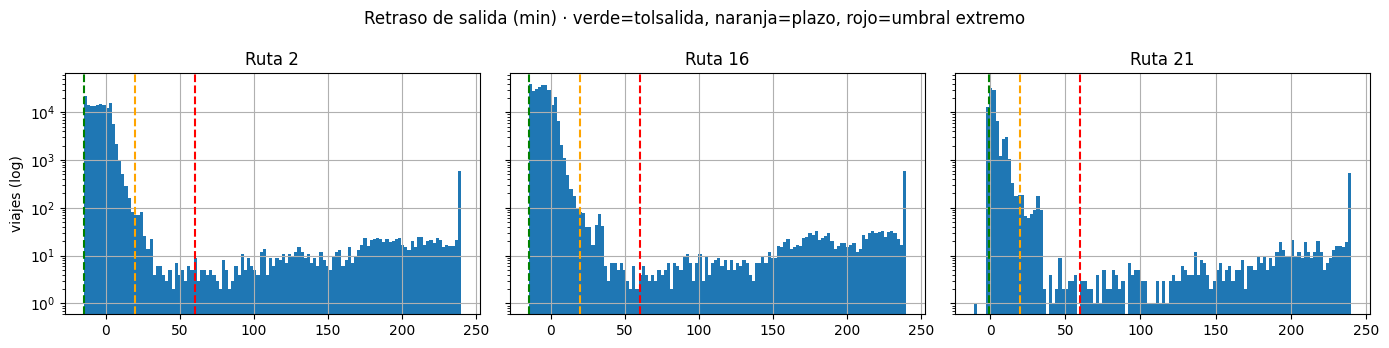

In [33]:
import matplotlib.pyplot as plt
d = d0[(d0.cancelada == "N") & d0.retraso_min.notna()]
fig, ax = plt.subplots(1, d.idruta.nunique(), figsize=(14, 3.5), sharey=True, squeeze=False)
for a, (rid, g) in zip(ax[0], d.groupby("idruta")):
    g.retraso_min.clip(-120, 240).hist(bins=120, ax=a)
    a.axvline(g.tolsalida.iloc[0], c="g", ls="--"); a.axvline(g.tiempoplazosalida.iloc[0], c="orange", ls="--")
    a.axvline(cfg.retraso_extremo_min, c="r", ls="--"); a.set_title(f"Ruta {rid}"); a.set_yscale("log")
ax[0][0].set_ylabel("viajes (log)")
fig.suptitle("Retraso de salida (min) · verde=tolsalida, naranja=plazo, rojo=umbral extremo")
plt.tight_layout(); plt.show()

**Conclusión 2.3 · La salida es casi siempre puntual; el problema son arranques registrados horas o días tarde**
- El 98,8 % de los viajes que arrancaron sale dentro de la ventana del sistema (ruta 2: 98,7 %; ruta 16: 99,2 %; ruta 21: 97,9 %).
- **Adelanto prácticamente no existe (1 viaje)**: el mínimo observado es exactamente −15 min en las rutas 2 y 16, igual a `tolsalida`. El sistema **bloquea** el despacho antes de la tolerancia, así que el adelanto no es medible.
- El retraso de más de 60 min afecta a 4.487 viajes no cancelados (0,86 %), y 320 inician más de **1 día** después de la salida programada (máximo 114 días). No son retrasos de tráfico: son registros de inicio cerrados tarde o reasignados.
- El umbral de 60 min se mantiene: separa limpio la cola (P95 ≤ 11 min, P99 entre 12 y 164 min).

## 2.4 Aplicar filtros y tabla de atrición

In [34]:
df = f.aplicar_filtros(d0, cfg)
df["puntualidad"] = f.clasificar_salida(df, cfg)
att = f.tabla_atricion(df)
display(att)
print(f"Registros iniciales: {len(df):,} | válidos: {df.valido.sum():,} ({100 * df.valido.mean():.2f} %)")

,paso,motivo,descartados,pct_de_inicial,restantes,fallan_regla_independiente
0,Fuera de ventana 2023-01 a 2025-12,fuera_ventana,0,0.00,564837,0
1,Cancelados (cancelada = 'S'),cancelado,44156,7.82,520681,44156
2,"Fantasmas (sin fechainicio, no cancelados)",fantasma_sin_inicio,33,0.01,520648,3410
3,No finalizados (finalizado <> 'S'),no_finalizado,9,0.00,520639,44198
4,No aptos históricamente,no_apto_historico,0,0.00,520639,0
5,Tiempo incoherente (fechas nulas o inicio >= fin),tiempo_incoherente,640,0.11,519999,44837
6,Duración < valor_tiempo_minimo_viaje,duracion_menor_minimo,0,0.00,519999,44290
7,Distancia <= 0 o fuera de margen vs distancia_...,distancia_invalida,22628,4.01,497371,33322


Registros iniciales: 564,837 | válidos: 497,371 (88.06 %)


**Conclusión 2.4 · Se conserva el 88,1 % (497.371 viajes); casi toda la pérdida la explican 2 reglas**
- **Cancelados: 44.156 (7,82 %)**. Ojo: no son despachos que no salieron. **40.779 tienen `fechainicio`, 40.324 tienen distancia > 0 y 38.463 llevaron pasajeros**; solo 2 tienen `fechafin`. Son viajes que **sí operaron** pero quedaron sin cierre, y el sistema los marcó como cancelados. Para medir la frecuencia real de despacho **sí cuentan como salidas**.
- **Distancia: 22.628 (4,01 %)**: 6.168 con distancia 0, 15.835 recorrieron menos del 50 % de la ruta (viajes cortados) y solo 625 superan el 150 %.
- Tiempo incoherente: 640 (547 con inicio = fin y 93 con fin antes del inicio). Fantasmas: 33. No finalizados: 9.
- No aptos, ventana y duración mínima: **0**. Esas reglas no filtran nada con estos datos.

## 2.5 Viajes fantasma y retraso extremo

In [35]:
fant_inicio = df[(df.cancelada == "N") & df.fechainicio.isna()]
fant_dur = df[(df.dur_min <= 0) & (df.distancia_recorrida.fillna(0) == 0) & (df.cancelada == "N")]
print(f"Fantasmas sin inicio (esperado 33): {len(fant_inicio)}")
print(f"Fantasmas con duración <= 0 y distancia 0: {len(fant_dur)}")
print("\nPuntualidad de salida en viajes no cancelados que arrancaron:")
arr = df[df.fechainicio.notna() & (df.cancelada == "N")]
display(arr.puntualidad.value_counts().to_frame("n").assign(pct=lambda x: (100 * x.n / x.n.sum()).round(2)))
print("Puntualidad entre los viajes válidos:")
display(df[df.valido].puntualidad.value_counts())
ext = df[df.puntualidad == "retraso_extremo"]
print(f"Retraso extremo (> {cfg.retraso_extremo_min:.0f} min): {len(ext):,} | de ellos válidos: {ext.valido.sum():,}")

Fantasmas sin inicio (esperado 33): 33
Fantasmas con duración <= 0 y distancia 0: 548

Puntualidad de salida en viajes no cancelados que arrancaron:


,n,pct
puntualidad,,
a_tiempo,514608,98.84
retraso_extremo,4487,0.86
retraso,1552,0.30
adelanto,1,0.00


Puntualidad entre los viajes válidos:


puntualidad
a_tiempo           496458
retraso               827
retraso_extremo        86
Name: count, dtype: int64

Retraso extremo (> 60 min): 5,635 | de ellos válidos: 86


**Conclusión 2.5 · Los fantasmas son pocos; los retrasos extremos casi no llegan a los válidos**
- Fantasmas sin inicio: 33, exactamente los N/N de Query9. Fantasmas con duración ≤ 0 y distancia 0: 548, que ya se excluyen por tiempo incoherente.
- De 5.635 viajes con retraso de más de 60 min, **solo 86 quedan entre los válidos**: el resto ya cayó por cancelado (1.148) o por otras reglas.
- Riesgo pendiente: los válidos todavía traen duraciones de hasta **780 min (P99)** y 7.095 por debajo de 102,6 min. La regla de duración mínima no actuó porque el parámetro está vacío; **hace falta un umbral propio** (o la bandera IQR de la Subfase 1.1).

## 2.6 Attrition Flowchart

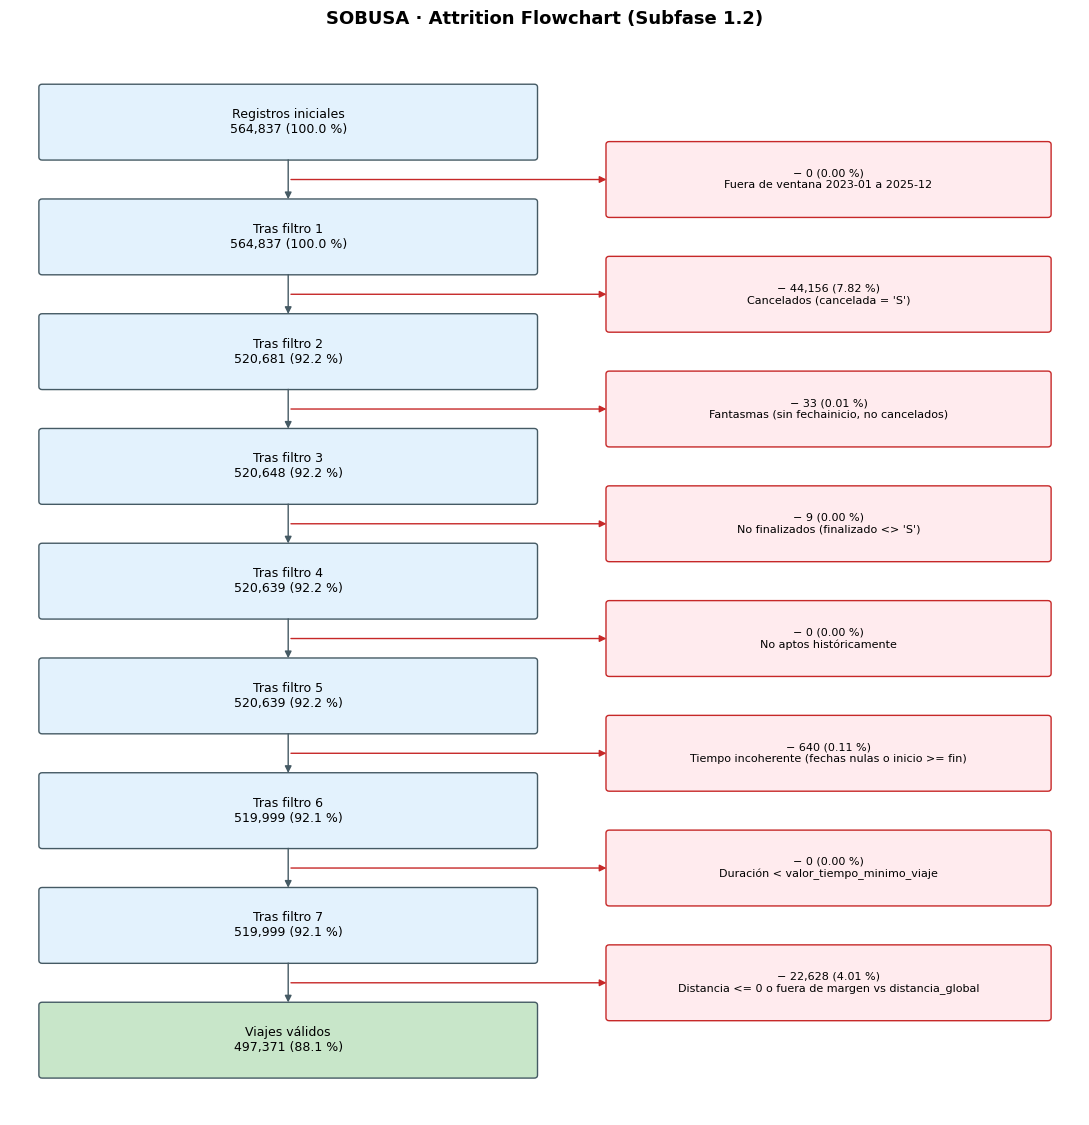

In [36]:
fig = f.flowchart(att, "attrition_flowchart_1_2.png")
plt.show()

**Conclusión final de la Subfase 1.2**
1. Base limpia: **497.371 viajes válidos (88,1 %)**: ruta 16 = 271.142, ruta 2 = 138.633, ruta 21 = 87.596.
2. Las reglas de negocio "oficiales" del sistema (apto histórico, duración mínima, tiempo global) **están vacías o son constantes**: la limpieza real la hacen `cancelada`, la distancia y la coherencia temporal.
3. **"Cancelado" no significa "no despachado"**: el 92 % de los cancelados arrancó y el 87 % llevó pasajeros. Para analizar **frecuencia de despacho** hay que usar `fechasalida`/`fechainicio` de todos los viajes no fantasma, no solo los válidos; los válidos sirven para duración, distancia y demanda.
4. La puntualidad de salida es alta (98,8 %) porque el sistema impone la ventana [−15, +20] min; el adelanto no es observable.
5. Pendiente para el modelado: definir una duración mínima/máxima y revisar el desfase de distancia en la ruta 21.

## 2.7 Exportar viajes válidos

In [37]:
validos = df[df.valido].drop(columns=[c for c in df.columns if c.startswith("falla_")] + ["motivo_descarte", "valido"])
validos.to_csv(DATOS / "viajes_validos.csv", index=False)   # CSV siempre: lo lee cualquier kernel
try:
    validos.to_parquet(DATOS / "viajes_validos.parquet", index=False)
except ImportError:
    pass
att.to_csv(DATOS / "atricion_1_2.csv", index=False)
print(f"{len(validos):,} viajes válidos guardados en {DATOS}")

497,371 viajes válidos guardados en datos_1_2


---
# Parte 3 · Subfase 1.3 · Sensores, bloqueos y puertas
*Notebook original: `subfase_1_3_sensores.ipynb`*

In [38]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_1_3_sensores.ipynb")

── Inicio de subfase_1_3_sensores.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 1.3 — Auditoría de sensores, bloqueos y puertas

**Parte 1** (solo lectura, la corres tú con la contraseña): índices (B.1), tabla de vehículos, columnas de sensor de `progvehiculos` y una muestra de lecturas de `conteo_pasajeros_destino`. Cada consulta se salta sola si su archivo ya existe en `datos_1_3/`.
**Parte 2** (sin conexión): banderas de calidad a nivel viaje y a nivel lectura. La lógica vive en `filtros_1_3.py`.

Insumos ya disponibles (pgAdmin): `QueryCapacidad.csv`, `Proporcion0BusesPorRuta.csv`, `QueryPasajerosReales.csv`, `Puertas.csv`.

# Parte 1 · Extracción (única conexión a la RDS)

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
import filtros_1_3 as f3

D12 = Path("datos_1_2")
DATOS = Path("datos_1_3"); DATOS.mkdir(exist_ok=True)

def ya(nombre):
    return (DATOS / f"{nombre}.csv").exists() or (DATOS / f"{nombre}.parquet").exists()

def leer(carpeta, nombre):
    """Lee Parquet si existe y hay motor (pyarrow); si no, el CSV. Funciona en cualquier kernel."""
    p = carpeta / f"{nombre}.parquet"
    if p.exists():
        try:
            return pd.read_parquet(p)
        except ImportError:
            pass
    return pd.read_csv(carpeta / f"{nombre}.csv", low_memory=False)

PENDIENTES = [n for n in ["indices", "tabla_vehiculos", "sensores_viaje", "lecturas"] if not ya(n)]
print("Consultas pendientes:", PENDIENTES or "ninguna, se salta la Parte 1")

Consultas pendientes: ninguna, se salta la Parte 1


## 1.0 Conexión (solo si hay consultas pendientes)

In [40]:
if PENDIENTES:
    from getpass import getpass
    import time
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    engine = create_engine(
        URL.create("postgresql+psycopg2", username="user_uninorte_2", password=getpass("Contraseña: ").strip(),
                   host="track1-experiment.crmc1hcwokb9.us-east-1.rds.amazonaws.com", port=5432, database="dataset"),
        pool_pre_ping=True,
        connect_args={"options": "-c default_transaction_read_only=on -c statement_timeout=600000 -c search_path=public"},
    )

    def consultar(sql, nombre, **params):
        t0 = time.perf_counter()
        with engine.connect() as cx:
            df = pd.read_sql(text(sql), cx, params=params or None)
        df.to_csv(DATOS / f"{nombre}.csv", index=False)
        print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
        return df

## 1.1 B.1 · Índices de las tablas núcleo (catálogo, instantánea)
Define si la muestra de lecturas puede traer viajes completos (requiere índice sobre `conteo_pasajeros_destino.idprogramacion`).

In [41]:
if not ya("indices"):
    consultar("""
    SELECT tablename, indexname, indexdef
    FROM pg_indexes
    WHERE schemaname = 'public'
      AND tablename IN ('progvehiculos', 'conteo_pasajeros_destino', 'rutas')
    ORDER BY 1, 2
    """, "indices")
indices = pd.read_csv(DATOS / "indices.csv")
display(indices)
cpd = indices[indices.tablename == "conteo_pasajeros_destino"]
HAY_INDICE_IDPROG = cpd.indexdef.str.contains(r"\(idprogramacion", regex=True).any()
UNICO_ID = (cpd.indexdef.str.contains("UNIQUE") & cpd.indexdef.str.contains(r"\(id\)", regex=True)).any()
print("Índice sobre conteo_pasajeros_destino.idprogramacion:", HAY_INDICE_IDPROG)
print("Índice único sobre conteo_pasajeros_destino.id:", UNICO_ID)

,tablename,indexname,indexdef
0,conteo_pasajeros_destino,idx_conteo_pasajeros_destino_idprog,CREATE INDEX idx_conteo_pasajeros_destino_idpr...
1,progvehiculos,fki_progVeh_desp,"CREATE INDEX ""fki_progVeh_desp"" ON public.prog..."
2,progvehiculos,fki_progveh_conductor,CREATE INDEX fki_progveh_conductor ON public.p...
3,progvehiculos,fki_usuario,CREATE INDEX fki_usuario ON public.progvehicul...
4,progvehiculos,idx_progvehiculos_fecha1,CREATE INDEX idx_progvehiculos_fecha1 ON publi...
5,progvehiculos,idx_progvehiculos_fecha2,CREATE INDEX idx_progvehiculos_fecha2 ON publi...
6,progvehiculos,idx_progvehiculos_fechafin,CREATE INDEX idx_progvehiculos_fechafin ON pub...
7,progvehiculos,idx_progvehiculos_fechainicio,CREATE INDEX idx_progvehiculos_fechainicio ON ...
8,progvehiculos,idx_progvehiculos_fechainicio_idveh,CREATE INDEX idx_progvehiculos_fechainicio_idv...
9,progvehiculos,idx_progvehiculos_finalizado,CREATE INDEX idx_progvehiculos_finalizado ON p...


Índice sobre conteo_pasajeros_destino.idprogramacion: True
Índice único sobre conteo_pasajeros_destino.id: False


## 1.2 Tabla de vehículos (modelo y capacidad por bus)
Solo las columnas necesarias de `vehiculos` (656 filas). Capacidad física = `n_sentados + n_depie`; la columna `capacidad` está en 0.

In [42]:
if not ya("tabla_vehiculos"):
    consultar("""
    SELECT idvehiculo, placa, numinterno, modelo, marca, capacidad, n_sentados, n_depie,
           estado, tipovehiculo, tipo_sensor, idruta
    FROM vehiculos
    """, "tabla_vehiculos")
display(pd.read_csv(DATOS / "tabla_vehiculos.csv").head())

,idvehiculo,placa,numinterno,modelo,marca,capacidad,n_sentados,n_depie,estado,tipovehiculo,tipo_sensor,idruta
0,SOBUSA38,UYQ358,NaN,2004,CHEVROLET NPR,0.0,0,0,N,1.0,AB,2.0
1,SOBUSA65,UYO907,NaN,2003,CHEVROLET NPR,0.0,0,0,N,1.0,AB,2.0
2,SOBUSA110,UYU006,86.0,2008,AGRALE,0.0,0,0,N,2.0,AB,12.0
3,SOBUSA584,SOBUSA584,NaN,NaN,NaN,0.0,0,0,N,NaN,NaN,NaN
4,SOBUSA134,UYP445,9115.0,2004,AGRALE,0.0,0,0,N,2.0,AB,NaN


## 1.3 Columnas de sensor de `progvehiculos` (una pasada, ≈565 mil filas)

In [43]:
if not ya("sensores_viaje"):
    s = consultar("""
    SELECT idprogramacion,
           numeropasajeros, numerobajadas, numerobloqueos, torniqueteinicial, torniquetefinal,
           acumulada_subida, acumulada_bajada, acumulada_bloqueo,
           cantidad_subida_puerta1, cantidad_bajada_puerta1, cantidad_bloqueo_puerta1,
           cantidad_subida_puerta2, cantidad_bajada_puerta2, cantidad_bloqueo_puerta2,
           acumulada_subida_puerta1, acumulada_bajada_puerta1, acumulada_bloqueo_puerta1,
           acumulada_subida_puerta2, acumulada_bajada_puerta2, acumulada_bloqueo_puerta2
    FROM progvehiculos
    """, "sensores_viaje")
    try:
        s.to_parquet(DATOS / "sensores_viaje.parquet", index=False)
    except ImportError:
        pass

## 1.4 Muestra de lecturas de `conteo_pasajeros_destino`
- **Con índice en `idprogramacion`:** viajes completos de 1.500 viajes válidos al azar (500 por ruta) + hasta 300 con cero pasajeros + 200 con más bloqueos. Permite carga a bordo y cortes de transmisión.
- **Sin índice:** `TABLESAMPLE SYSTEM (0.1)` (≈176 mil lecturas). Solo permite conteos negativos, picos y GPS; no reconstruye la secuencia del viaje.

In [44]:
if not ya("lecturas"):
    COLS = """id, idprogramacion, idvehiculo, fecha, latitud, longitud, idpunto,
              cantidad_subida, cantidad_bajada, cantidad_bloqueo,
              acumulada_subida, acumulada_bajada, acumulada_bloqueo,
              cantidad_subida_puerta1, cantidad_bajada_puerta1, cantidad_subida_puerta2, cantidad_bajada_puerta2"""
    lectura_ok = False
    if HAY_INDICE_IDPROG:
        val = leer(D12, "viajes_validos")
        sv = pd.read_csv(DATOS / "sensores_viaje.csv", usecols=["idprogramacion", "numeropasajeros", "numerobloqueos"])
        val = val[["idprogramacion", "idruta"]].merge(sv, on="idprogramacion")
        azar = val.groupby("idruta", group_keys=False).apply(lambda g: g.sample(min(500, len(g)), random_state=42))
        ceros = val[val.numeropasajeros.fillna(0) == 0]
        ceros = ceros.sample(min(300, len(ceros)), random_state=42)
        bloq = val.nlargest(200, "numerobloqueos")
        ids = pd.concat([azar, ceros, bloq]).idprogramacion.drop_duplicates().astype(int).tolist()
        pd.DataFrame({"idprogramacion": ids}).to_csv(DATOS / "muestra_ids.csv", index=False)
        try:
            consultar(f"SELECT {COLS} FROM conteo_pasajeros_destino WHERE idprogramacion = ANY(:ids) ORDER BY idprogramacion, fecha",
                      "lecturas", ids=ids)
            lectura_ok = True
        except Exception as e:
            print("Consulta por índice falló, se usa TABLESAMPLE:", str(e)[:200])
    if not lectura_ok:
        consultar(f"SELECT {COLS} FROM conteo_pasajeros_destino TABLESAMPLE SYSTEM (0.1) REPEATABLE (42)", "lecturas")

# Parte 2 · Análisis local (sin conexión)

In [45]:
cargar = leer

viajes = cargar(D12, "viajes_raw")
validos_ids = cargar(D12, "viajes_validos").idprogramacion
sensores = cargar(DATOS, "sensores_viaje")
cap_modelo = pd.read_csv("QueryCapacidad.csv")
prop_ruta = pd.read_csv("Proporcion0BusesPorRuta.csv")
pas_reales = pd.read_csv("QueryPasajerosReales.csv")
puertas_pg = pd.read_csv("Puertas.csv")

cfg = f3.Config()
df = f3.preparar(viajes[["idprogramacion", "idvehiculo", "idruta", "fechasalida", "fechainicio", "fechafin",
                         "cancelada", "finalizado", "distancia_recorrida"]], sensores, validos_ids)
print(f"{len(df):,} viajes | válidos: {df.valido.sum():,} | con numeropasajeros: {df.numeropasajeros.notna().sum():,}")

564,837 viajes | válidos: 497,371 | con numeropasajeros: 556,244


## 2.1 Capacidad física de la flota

**Hallazgos previos (consultas de pgAdmin: QueryCapacidad, QueryPasajerosReales, Proporcion0BusesPorRuta, Puertas)**
- **Capacidad física: 46–74 personas por bus** (sentados + de pie). La capacidad registrada en la base es **0 en todos los modelos**: el campo no sirve.
- **El 21–24 % de la flota de cada ruta no tiene modelo** (177 buses, 100.189 viajes); su capacidad (74) es incierta. 4 buses (modelos 1997, 1998 y 2001) tienen capacidad 0.
- Capacidad ponderada por ruta: 2 = 63,4; 16 = 64,1; 21 = 63,1. La mezcla de flota es casi idéntica entre rutas.
- **`numeropasajeros` es subidas totales del viaje, NO carga a bordo**: el promedio es ≈82 por viaje en todos los modelos, aunque la capacidad va de 46 a 74 (correlación 0,3). Un viaje de ~4 h renueva el bus 1,1–1,7 veces. **La capacidad solo se puede contrastar contra la carga simultánea** (subidas − bajadas acumuladas), no contra el total del viaje.
- **Picos imposibles confirmados:** viajes con 97.199 (modelo 2020), 28.816 (2019) y 747 (2017) pasajeros. Son errores del contador, no demanda.
- **Puertas: la hipótesis se cumple.** El 97,87 % de las subidas entra por P1 y el 99,27 % de las bajadas sale por P2. Hay 345 viajes con más subidas por P2 y 5.881 con más bajadas por P1.
- **Desbalance global:** 42,8 M de subidas frente a 44,9 M de bajadas (**+5,0 % de bajadas**). En un sistema cerrado deberían ser iguales: los sensores cuentan de más las bajadas o de menos las subidas.

In [46]:
cap_ruta = f3.capacidad_por_ruta(prop_ruta, cap_modelo)
display(cap_ruta)
pr = pas_reales.assign(subidas_por_puesto=lambda x: (x.promedio_pasajeros_por_viaje / x.capacidad_teorica_max).round(2))
display(pr[["modelo", "total_viajes", "capacidad_teorica_max", "promedio_pasajeros_por_viaje",
            "max_pasajeros_reales_en_un_viaje", "subidas_por_puesto"]].sort_values("capacidad_teorica_max", ascending=False))
print("Correlación capacidad del modelo vs pasajeros promedio por viaje:",
      round(pr[["capacidad_teorica_max", "promedio_pasajeros_por_viaje"]].corr().iloc[0, 1], 2))

# Capacidad por bus = n_sentados + n_depie. Si el bus tiene 0, se usa la capacidad de su modelo; si tampoco, 74 (cota de la flota).
veh = pd.read_csv(DATOS / "tabla_vehiculos.csv")
veh["cap_bus"] = veh.n_sentados.fillna(0) + veh.n_depie.fillna(0)
cap_mod = cap_modelo.assign(modelo=cap_modelo.modelo.astype("string")).set_index("modelo").capacidad_calculada_max
veh["cap_modelo"] = veh.modelo.astype("string").map(cap_mod)
veh["capacidad_final"] = veh.cap_bus.where(veh.cap_bus > 0, veh.cap_modelo.where(veh.cap_modelo > 0))
veh["origen_cap"] = np.select([veh.cap_bus > 0, veh.capacidad_final.notna()], ["bus", "modelo"], "flota_74")
operan = veh[veh.idvehiculo.isin(df.idvehiculo)]
print("Buses que operan:", len(operan)); display(operan.origen_cap.value_counts().to_frame("buses"))
display(operan.capacidad_final.describe().round(1).to_frame("capacidad_bus"))
CAP_BUS = veh.set_index("idvehiculo").capacidad_final.dropna().to_dict()
cap_viaje = df.idvehiculo.map(CAP_BUS)
print("Viajes con capacidad propia del bus o su modelo:", f"{cap_viaje.notna().sum():,}", "| resto usa", cfg.cap_defecto)

,buses,pct_sin_modelo,cap_ponderada,cap_ponderada_con_modelo,cap_min,cap_max
idruta,,,,,,
2,282,23.0,63.4,60.3,46,74
16,296,21.0,64.1,61.5,47,74
21,345,24.1,63.1,59.7,46,74


,modelo,total_viajes,capacidad_teorica_max,promedio_pasajeros_por_viaje,max_pasajeros_reales_en_un_viaje,subidas_por_puesto
0,NaN,100189,74,81.65,329,1.10
1,2008,23085,72,84.12,253,1.17
2,2017,16664,70,88.07,747,1.26
3,2016,83668,70,80.15,264,1.14
4,2018,48412,70,84.04,351,1.20
5,2020,85756,62,82.84,97199,1.34
6,2025,654,60,87.23,204,1.45
7,2015,1154,58,80.36,216,1.39
8,2003,5609,58,90.23,263,1.56
9,2007,11933,58,73.27,239,1.26


Correlación capacidad del modelo vs pasajeros promedio por viaje: 0.3
Buses que operan: 449


,buses
origen_cap,
bus,401
modelo,48


,capacidad_bus
count,449.0
mean,52.5
std,7.3
min,32.0
25%,49.0
50%,50.0
75%,57.0
max,74.0


Viajes con capacidad propia del bus o su modelo: 564,837 | resto usa 74.0


In [47]:
df, U = f3.auditar_viajes(df, cap_viaje, cfg)
v = df[df.valido]
print("Umbrales (sobre viajes válidos):", {k: round(x, 3) for k, x in U.items()})

Umbrales (sobre viajes válidos): {'p_bloqueo': 260.0, 'p_tasa_bloqueo': 3.284}


## 2.2 Bloqueos de barra

In [48]:
display(v.numerobloqueos.describe(percentiles=[.5, .9, .95, .99, .999]).round(2).to_frame("numerobloqueos"))
display(v.tasa_bloqueo.describe(percentiles=[.5, .9, .99]).round(3).to_frame("bloqueos_por_pasajero"))
display(f3.resumen_flags(v, ["flag_alto_bloqueo", "flag_bloqueo_severo"]))
print("Concentración por bus (bloqueo severo):"); display(f3.concentracion(v, "flag_bloqueo_severo"))
print("Bloqueo alto por hora de salida (%):")
display(v.groupby("hora").flag_alto_bloqueo.mean().mul(100).round(2).to_frame().T)

,numerobloqueos
count,496580.00
mean,55.69
std,5494.62
min,0.00
50%,0.00
90%,21.00
95%,63.00
99%,260.00
99.9%,2199.53
max,1605840.00


,bloqueos_por_pasajero
count,496404.000
mean,0.968
std,85.665
min,0.000
50%,0.000
90%,0.247
99%,3.284
max,25900.645


,viajes,pct,base
flag_alto_bloqueo,4954,1.00,497371
flag_bloqueo_severo,3803,0.76,497371


Concentración por bus (bloqueo severo):


,n_flag,viajes,pct_viajes_bus,pct_acum_del_total
idvehiculo,,,,
SOBUSA302,103,2547,4.0,2.7
SOBUSA401,58,2831,2.0,4.2
SOBUSA441,52,2358,2.2,5.6
SOBUSA262,50,1111,4.5,6.9
SOBUSA36,48,2131,2.3,8.2
SOBUSA442,48,2338,2.1,9.4
SOBUSA435,47,2536,1.9,10.7
SOBUSA475,45,2660,1.7,11.9
SOBUSA478,43,2444,1.8,13.0


Bloqueo alto por hora de salida (%):


hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
flag_alto_bloqueo,0.8,0.89,1.33,1.18,1.26,1.08,1.11,1.3,1.39,1.18,1.12,0.74,0.64,0.55,0.66,0.42,0.63


## 2.3 Puerta 1 vs Puerta 2

In [49]:
tot = v[["cantidad_subida_puerta1", "cantidad_subida_puerta2", "cantidad_bajada_puerta1", "cantidad_bajada_puerta2",
         "numeropasajeros", "numerobajadas"]].sum()
display(tot.to_frame("total_validos").T)
print(f"Subidas por P1: {100 * tot.cantidad_subida_puerta1 / (tot.cantidad_subida_puerta1 + tot.cantidad_subida_puerta2):.2f} %  |  "
      f"Bajadas por P2: {100 * tot.cantidad_bajada_puerta2 / (tot.cantidad_bajada_puerta1 + tot.cantidad_bajada_puerta2):.2f} %")
display(v.pct_sub_p1.describe(percentiles=[.01, .05, .5]).round(3).to_frame("pct_subidas_p1"))
display(f3.resumen_flags(v, ["flag_subida_p2_mayor", "flag_bajada_p1_mayor", "flag_total_inconsistente"]))
print("Concentración por bus (bajadas por P1 > P2):"); display(f3.concentracion(v, "flag_bajada_p1_mayor"))

,cantidad_subida_puerta1,cantidad_subida_puerta2,cantidad_bajada_puerta1,cantidad_bajada_puerta2,numeropasajeros,numerobajadas
total_validos,41678924.0,906921.0,273064.0,44432712.0,42084022.0,47195395.0


Subidas por P1: 97.87 %  |  Bajadas por P2: 99.39 %


,pct_subidas_p1
count,496404.000
mean,0.995
std,0.017
min,0.000
1%,0.934
5%,0.971
50%,1.000
max,1.000


,viajes,pct,base
flag_subida_p2_mayor,31,0.01,497371
flag_bajada_p1_mayor,594,0.12,497371
flag_total_inconsistente,772,0.16,497371


Concentración por bus (bajadas por P1 > P2):


,n_flag,viajes,pct_viajes_bus,pct_acum_del_total
idvehiculo,,,,
SOBUSA512,13,2156,0.6,2.2
SOBUSA265,11,2334,0.5,4.0
SOBUSA53,10,1667,0.6,5.7
SOBUSA428,9,1995,0.5,7.2
SOBUSA190,8,2278,0.4,8.6
SOBUSA221,7,2803,0.2,9.8
SOBUSA209,7,2054,0.3,10.9
SOBUSA153,7,1689,0.4,12.1
SOBUSA414,7,2413,0.3,13.3


## 2.4 Coherencia física: balance subidas − bajadas, picos y negativos

In [50]:
display(v.balance_final.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_frame("balance_final"))
print(f"Subidas totales: {v.subidas_tot.sum():,.0f} | Bajadas totales: {v.bajadas_tot.sum():,.0f} | "
      f"exceso de bajadas: {100 * (v.bajadas_tot.sum() / v.subidas_tot.sum() - 1):.2f} %")
display(f3.resumen_flags(v, ["flag_balance_negativo", "flag_balance_sobre_capacidad", "flag_pico_imposible", "flag_conteo_negativo"]))
display(v.loc[v.flag_pico_imposible, ["idprogramacion", "idvehiculo", "idruta", "fechasalida", "numeropasajeros",
                                      "subidas_tot", "bajadas_tot", "capacidad"]].sort_values("numeropasajeros", ascending=False).head(15))

,balance_final
count,497371.0
mean,-4.3
std,2035.6
min,-750370.0
1%,-20.0
5%,-9.0
25%,-2.0
50%,1.0
75%,5.0
95%,13.0


Subidas totales: 42,585,845 | Bajadas totales: 44,705,776 | exceso de bajadas: 4.98 %


,viajes,pct,base
flag_balance_negativo,32329,6.50,497371
flag_balance_sobre_capacidad,573,0.12,497371
flag_pico_imposible,123,0.02,497371
flag_conteo_negativo,0,0.00,497371


,idprogramacion,idvehiculo,idruta,fechasalida,numeropasajeros,subidas_tot,bajadas_tot,capacidad
150152,6219550,SOBUSA451,16,2024-05-20 11:36:00,97199.0,45.0,40.0,62.0
357597,7144077,SOBUSA143,16,2025-07-04 17:48:00,28816.0,638032.0,21.0,50.0
174420,6330910,SOBUSA303,21,2024-07-09 09:36:00,747.0,747.0,318.0,58.0
219745,6535573,SOBUSA475,16,2024-10-08 13:08:00,507.0,507.0,446.0,49.0
174738,6332504,SOBUSA303,21,2024-07-09 19:56:00,459.0,459.0,247.0,58.0
236764,6612771,SOBUSA475,16,2024-11-12 17:33:00,413.0,413.0,317.0,49.0
226097,6563160,SOBUSA333,16,2024-10-21 10:58:00,375.0,375.0,368.0,50.0
550956,5497571,SOBUSA420,16,2023-07-15 16:42:00,351.0,351.0,345.0,39.0
554059,5510880,SOBUSA420,16,2023-07-21 16:39:00,344.0,344.0,282.0,39.0
236355,6610507,SOBUSA475,16,2024-11-11 16:25:00,341.0,341.0,208.0,49.0


## 2.5 Ceros: falla de transmisión/sensor vs. falta de demanda
- `cero_sin_transmision`: 0 pasajeros y distancia 0 (no llegó nada del bus).
- `cero_falla_sensor`: el bus recorrió la ruta, pero no contó a nadie mientras la ruta en esa fecha y hora tenía demanda (mediana ≥ 10), o el bus tuvo todos sus viajes del día en cero.
- `cero_baja_demanda`: el bus recorrió la ruta y el contexto también tenía poca demanda.

In [51]:
display(df[df.arranco].tipo_cero.value_counts().to_frame("todos_los_que_arrancaron")
        .join(v.tipo_cero.value_counts().rename("validos")))
print("Ceros por hora de salida (válidos):")
display(pd.crosstab(v.hora, v.tipo_cero).drop(columns="con_dato", errors="ignore").T)

,todos_los_que_arrancaron,validos
tipo_cero,,
con_dato,543975,496404.0
cero_falla_sensor,10711,946.0
cero_sin_transmision,6568,NaN
cero_baja_demanda,173,21.0


Ceros por hora de salida (válidos):


hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
tipo_cero,,,,,,,,,,,,,,,,,
cero_baja_demanda,0,0,0,0,0,0,0,0,0,0,0,0,0,0,15,6,0
cero_falla_sensor,8,67,35,23,15,13,6,10,10,18,11,12,16,24,38,412,228


## 2.6 Auditoría por lectura (sensor/GPS)

In [52]:
lect = cargar(DATOS, "lecturas")
SECUENCIAS = (DATOS / "muestra_ids.csv").exists()
cap_bus = pd.Series(CAP_BUS, dtype=float) if CAP_BUS else None
L = f3.auditar_lecturas(lect, cap_bus, cfg, secuencias=SECUENCIAS)
print(f"{len(L):,} lecturas de {L.idprogramacion.nunique():,} viajes | secuencias completas: {SECUENCIAS}")
# [corregido] API actual de filtros_1_3: a_bordo (carga física, nunca < 0) y a_bordo_cum (saldo crudo subidas − bajadas)
display(L[["acumulada_subida", "acumulada_bajada"] + (["a_bordo", "a_bordo_cum"] if SECUENCIAS else [])]
        .describe(percentiles=[.01, .5, .99]).round(1))
display(f3.resumen_flags(L, [c for c in L.columns if c.startswith("flag_")]))

971,335 lecturas de 1,673 viajes | secuencias completas: True


,acumulada_subida,acumulada_bajada,a_bordo,a_bordo_cum
count,971335.0,971335.0,971335.0,971335.0
mean,383495.3,383979.1,20.5,-30.8
std,194085.3,182376.2,26.1,4656.5
min,29.0,161.0,0.0,-555739.0
1%,1541.0,4350.0,0.0,-102.0
50%,437469.0,434830.0,11.0,11.0
99%,688749.0,674360.0,118.0,118.0
max,768795.0,755003.0,215.0,213.0


,viajes,pct,base
flag_conteo_negativo,0,0.00,971335
flag_pico_lectura,12,0.00,971335
flag_gps_nulo,0,0.00,971335
flag_gps_fuera_caja,1,0.00,971335
flag_corte_transmision,517,0.05,971335


In [53]:
if SECUENCIAS:
    # [corregido] API actual de filtros_1_3: resumen_lecturas_por_viaje(d, cfg)
    RV = f3.resumen_lecturas_por_viaje(L, cfg).join(sensores.set_index("idprogramacion")[["numeropasajeros"]])
    RV["dif_vs_progvehiculos"] = RV.subidas_sensor - RV.numeropasajeros
    display(RV.describe(percentiles=[.01, .5, .99]).round(1))
    display(f3.resumen_flags(RV, ["flag_sobrecupo", "flag_carga_imposible", "flag_deriva_alta"]))   # [corregido] banderas actuales
else:
    print("Sin secuencias completas: carga a bordo y cortes de transmisión no evaluables (falta índice en idprogramacion).")

,lecturas,subidas_sensor,bajadas_sensor,max_a_bordo,deriva_min,saldo_final,capacidad,lecturas_gps_nulo,cortes_transmision,max_gap_min,ocupacion_max,numeropasajeros,dif_vs_progvehiculos
count,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1673.0,1671.0,1673.0,1671.0,1671.0
mean,580.6,155.5,1005.5,35.1,-856.3,-850.0,52.0,0.0,0.3,33.3,0.7,155.3,0.3
std,928.8,2476.1,20254.0,20.2,19578.8,19579.1,7.1,0.0,0.8,268.6,0.4,2477.6,3.4
min,1.0,0.0,0.0,0.0,-555739.0,-555739.0,32.0,0.0,0.0,0.1,0.0,0.0,0.0
1%,6.0,0.0,0.0,0.0,-109.0,-109.0,39.0,0.0,0.0,0.1,0.0,0.0,0.0
50%,341.0,79.0,77.0,34.0,0.0,1.0,50.0,0.0,0.0,2.0,0.6,79.0,0.0
99%,4576.6,173.3,170.0,100.3,1.0,98.6,74.0,0.0,4.0,616.5,2.0,173.0,2.0
max,7074.0,97199.0,555778.0,215.0,8.0,213.0,74.0,0.0,12.0,8334.8,4.3,97199.0,92.0


,viajes,pct,base
flag_sobrecupo,288,17.21,1673
flag_carga_imposible,39,2.33,1673
flag_deriva_alta,176,10.52,1673


## 2.7 Banderas de calidad finales y exportación

In [54]:
FLAGS = ["flag_sensor_ok", "flag_bloqueo_severo", "flag_incoherencia_pasajeros", "flag_alto_bloqueo",
         "flag_cero_falla", "flag_subida_p2_mayor", "flag_bajada_p1_mayor"]
display(f3.resumen_flags(v, FLAGS))
display(v.groupby("idruta")[FLAGS].mean().mul(100).round(2))
salida = v[["idprogramacion", "idvehiculo", "idruta", "fechasalida", "numeropasajeros", "numerobloqueos",
            "subidas_tot", "bajadas_tot", "balance_final", "pct_sub_p1", "tasa_bloqueo", "capacidad", "tipo_cero"]
           + [c for c in v.columns if c.startswith("flag_")]]
salida.to_csv(DATOS / "viajes_flags_1_3.csv", index=False)   # CSV siempre: lo lee cualquier kernel
try:
    salida.to_parquet(DATOS / "viajes_flags_1_3.parquet", index=False)
except ImportError:
    pass
print(f"{len(salida):,} viajes válidos con banderas guardados en {DATOS}")

,viajes,pct,base
flag_sensor_ok,460817,92.65,497371
flag_bloqueo_severo,3803,0.76,497371
flag_incoherencia_pasajeros,33013,6.64,497371
flag_alto_bloqueo,4954,1.00,497371
flag_cero_falla,946,0.19,497371
flag_subida_p2_mayor,31,0.01,497371
flag_bajada_p1_mayor,594,0.12,497371


,flag_sensor_ok,flag_bloqueo_severo,flag_incoherencia_pasajeros,flag_alto_bloqueo,flag_cero_falla,flag_subida_p2_mayor,flag_bajada_p1_mayor
idruta,,,,,,,
2,94.96,0.78,4.30,0.96,0.22,0.00,0.13
16,92.79,0.74,6.52,0.99,0.17,0.01,0.10
21,88.58,0.83,10.70,1.09,0.21,0.01,0.16


497,371 viajes válidos con banderas guardados en datos_1_3


---
# Parte 4 · Subfase 1.4 · Nulos, imputación y tablas maestras
*Notebook original: `subfase_1_4_maestra.ipynb`*

In [55]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_1_4_maestra.ipynb")

── Inicio de subfase_1_4_maestra.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 1.4 — Nulos, imputación sin leakage y tablas maestras (cierre del Módulo 1)

**Parte 1** (solo lectura, la corres tú): 3 consultas para el mapa de nulos. Ninguna recorre los 41 GB y ninguna descarga valores, solo indicadores de nulo.
**Parte 2** (sin conexión): mapa de nulos, decisiones por columna, imputación sin data leakage, las 3 tablas maestras en Parquet y la validación de cierre.

| Salida | Contenido |
|---|---|
| `maestras/tb_maestra_progvehiculos_limpia.parquet` | Viajes válidos (1.2) + banderas de sensor (1.3) + imputación + `recaudo_esperado` |
| `maestras/tb_despachos.parquet` | Todas las salidas reales, incluidos los "cancelados" que sí operaron: base para medir la frecuencia de despacho |
| `maestras/tb_maestra_conteo_destino_limpio_muestra.parquet` | Lecturas limpias de la muestra de la 1.3 (la tabla completa de 41 GB queda como vista SQL) |
| `tb_maestras_modulo1.sql` | DDL de las 3 tablas/vistas para quien tenga permisos de escritura |

La lógica vive en `filtros_1_4.py`.

# Parte 1 · Extracción para el mapa de nulos

In [56]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
import filtros_1_2 as f2
import filtros_1_4 as f4

D12, D13 = Path("datos_1_2"), Path("datos_1_3")
DATOS = Path("datos_1_4"); DATOS.mkdir(exist_ok=True)
SALIDA = Path("maestras"); SALIDA.mkdir(exist_ok=True)
cfg = f4.Config()

def ya(nombre):
    return (DATOS / f"{nombre}.csv").exists()

def leer(carpeta, nombre):
    p = carpeta / f"{nombre}.parquet"
    if p.exists():
        try:
            return pd.read_parquet(p)
        except ImportError:
            pass
    return pd.read_csv(carpeta / f"{nombre}.csv", low_memory=False)

inv = pd.read_csv("Query1.csv")
COLS_PV = inv[inv.table_name == "progvehiculos"].sort_values("pos").column_name.tolist()
COLS_CP = inv[inv.table_name == "conteo_pasajeros_destino"].sort_values("pos").column_name.drop_duplicates().tolist()
PENDIENTES = [n for n in ["nulos_progvehiculos", "indicadores_progvehiculos", "indicadores_conteo"] if not ya(n)]
print(f"progvehiculos: {len(COLS_PV)} columnas | conteo_pasajeros_destino: {len(COLS_CP)} columnas")
print("Consultas pendientes:", PENDIENTES or "ninguna, se salta la Parte 1")

progvehiculos: 73 columnas | conteo_pasajeros_destino: 25 columnas
Consultas pendientes: ninguna, se salta la Parte 1


In [57]:
if PENDIENTES:
    from getpass import getpass
    import time
    from sqlalchemy import create_engine, text
    from sqlalchemy.engine import URL

    engine = create_engine(
        URL.create("postgresql+psycopg2", username="user_uninorte_2", password=getpass("Contraseña: ").strip(),
                   host="track1-experiment.crmc1hcwokb9.us-east-1.rds.amazonaws.com", port=5432, database="dataset"),
        pool_pre_ping=True,
        connect_args={"options": "-c default_transaction_read_only=on -c statement_timeout=600000 -c search_path=public"},
    )

    def consultar(sql, nombre):
        t0 = time.perf_counter()
        with engine.connect() as cx:
            df = pd.read_sql(text(sql), cx)
        df.to_csv(DATOS / f"{nombre}.csv", index=False)
        print(f"[{nombre}] {len(df):,} filas en {time.perf_counter() - t0:.1f} s")
        return df

## 1.1 Nulos exactos por columna de `progvehiculos` (una pasada, 975 MB)

In [58]:
if not ya("nulos_progvehiculos"):
    sel = ",\n       ".join(f'count("{c}") AS "{c}"' for c in COLS_PV)
    consultar(f"SELECT count(*) AS total,\n       {sel}\nFROM progvehiculos", "nulos_progvehiculos")

## 1.2 Indicadores de nulo de `progvehiculos` (muestra del 5 %, solo 0/1, sin valores)

In [59]:
if not ya("indicadores_progvehiculos"):
    sel = ",\n       ".join(f'("{c}" IS NULL)::int AS "{c}"' for c in COLS_PV)
    consultar(f"""SELECT to_char(fechasalida, 'YYYY-MM') AS mes,
       {sel}
FROM progvehiculos TABLESAMPLE SYSTEM (5) REPEATABLE (42)""", "indicadores_progvehiculos")

## 1.3 Indicadores de nulo de `conteo_pasajeros_destino` (muestra del 0,2 %, ≈350 mil lecturas, solo 0/1)

In [60]:
if not ya("indicadores_conteo"):
    sel = ",\n       ".join(f'("{c}" IS NULL)::int AS "{c}"' for c in COLS_CP)
    extra = ',\n       COALESCE(latitud = 0 OR longitud = 0, false)::int AS "coord_cero"'
    consultar(f"""SELECT to_char(fecha, 'YYYY-MM') AS mes,
       {sel}{extra}
FROM conteo_pasajeros_destino TABLESAMPLE SYSTEM (0.2) REPEATABLE (42)""", "indicadores_conteo")

# Parte 2 · Análisis local (sin conexión)

## 2.1 Mapa de nulos de `progvehiculos`

,columnas
categoria,
completa,27
<5 %,19
5–50 %,1
"50–99,99 %",2
100 % nula,24


,no_nulos,nulos,pct_nulos,categoria
fecha_fin_liquidacion,0,564837,100.00,100 % nula
torniquetefinal,0,564837,100.00,100 % nula
data_log,0,564837,100.00,100 % nula
idempresa,0,564837,100.00,100 % nula
tipo,0,564837,100.00,100 % nula
geocercaact,0,564837,100.00,100 % nula
gtransid,0,564837,100.00,100 % nula
grupo,0,564837,100.00,100 % nula
fechaliq,0,564837,100.00,100 % nula
observacion_bloq,0,564837,100.00,100 % nula


Muestra: 27,963 viajes

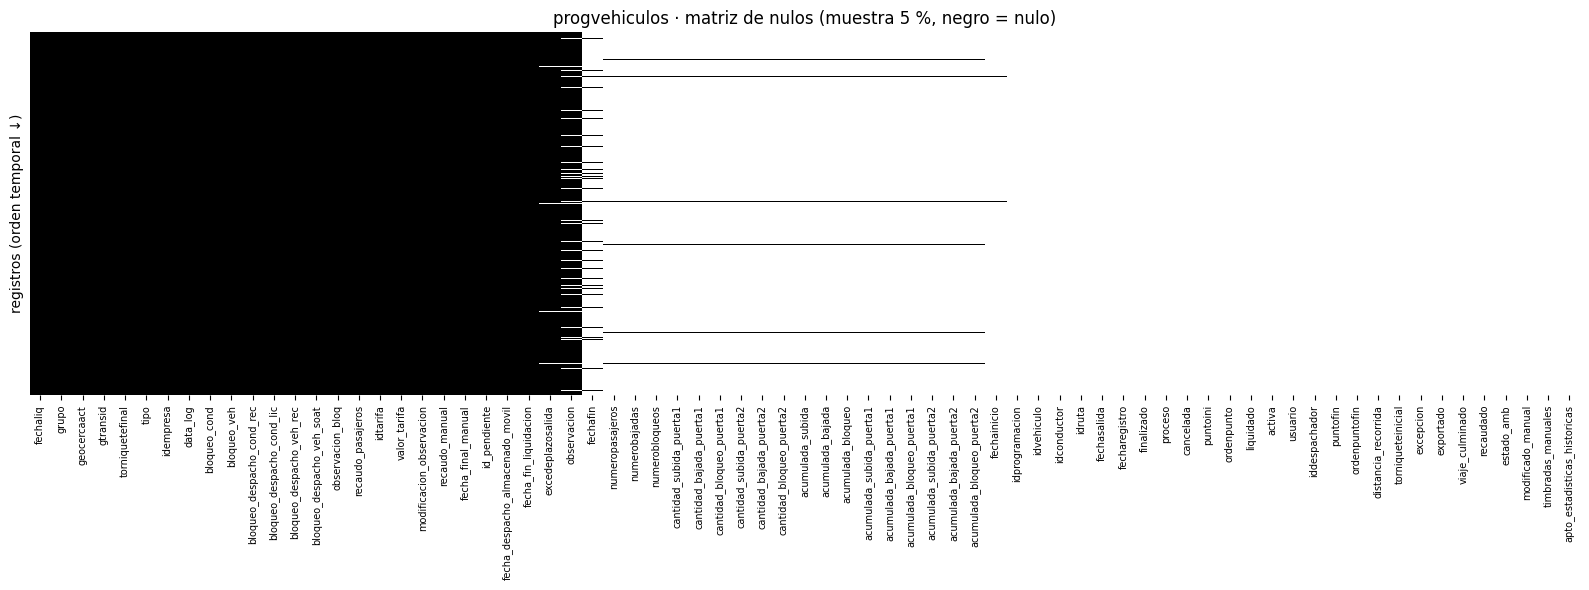

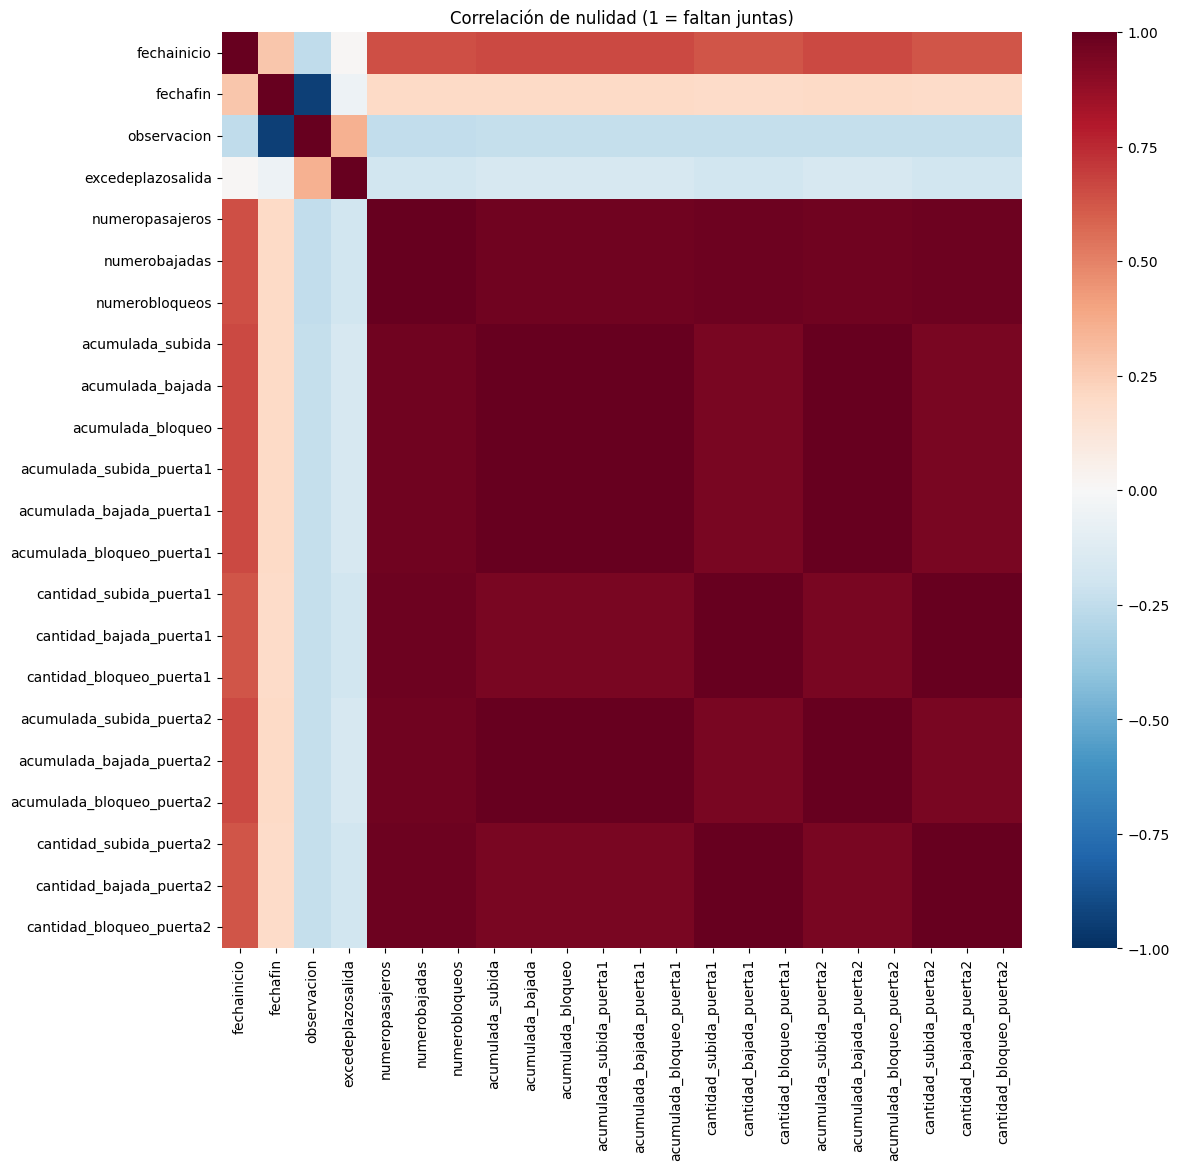

In [61]:
nulos_pv = f4.pct_nulos_exactos(pd.read_csv(DATOS / "nulos_progvehiculos.csv"))
display(nulos_pv.categoria.value_counts().sort_index().to_frame("columnas"))
display(nulos_pv[nulos_pv.pct_nulos > 0])

ind_pv = pd.read_csv(DATOS / "indicadores_progvehiculos.csv")
print(f"Muestra: {len(ind_pv):,} viajes")
fig, ax = plt.subplots(1, 1, figsize=(16, 6))
f4.matriz_nulos(ind_pv, "progvehiculos · matriz de nulos (muestra 5 %, negro = nulo)", ax=ax)
plt.tight_layout(); plt.show()
c_pv = f4.correlacion_nulos(ind_pv); plt.show()

## 2.2 Mapa de nulos de `conteo_pasajeros_destino`

Muestra: 342,414 lecturas


,pct_nulos_muestra
idpunto,90.42
id,0.00
idvehiculo,0.00
acumulada_subida,0.00
cantidad_subida,0.00
acumulada_bajada,0.00
cantidad_bajada,0.00
acumulada_bloqueo,0.00
cantidad_bloqueo,0.00
fecha,0.00


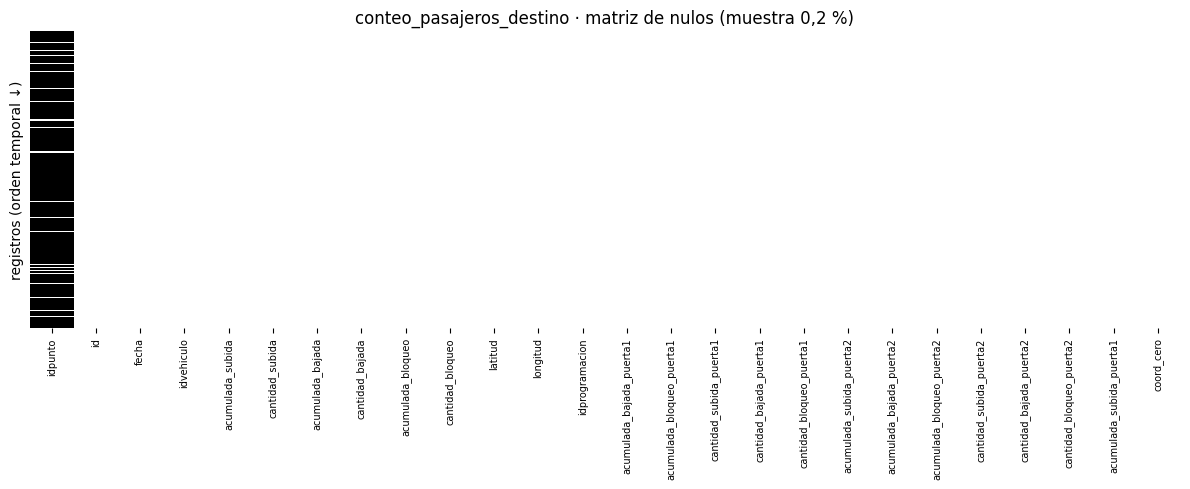

Menos de 2 columnas parcialmente nulas: no hay patrón de co-ocurrencia que graficar.
Nulos por mes (% de lecturas con alguna coordenada nula o en cero):


mes,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
sin_coord,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [62]:
ind_cp = pd.read_csv(DATOS / "indicadores_conteo.csv")
ind_cp[ind_cp.columns.drop("mes")] = ind_cp[ind_cp.columns.drop("mes")].fillna(0).astype(int)
pct_cp = (100 * ind_cp.drop(columns="mes").mean()).round(3).sort_values(ascending=False).to_frame("pct_nulos_muestra")
print(f"Muestra: {len(ind_cp):,} lecturas")
display(pct_cp)
fig, ax = plt.subplots(1, 1, figsize=(12, 5))
f4.matriz_nulos(ind_cp, "conteo_pasajeros_destino · matriz de nulos (muestra 0,2 %)", ax=ax)
plt.tight_layout(); plt.show()
c_cp = f4.correlacion_nulos(ind_cp); plt.show()
print("Nulos por mes (% de lecturas con alguna coordenada nula o en cero):")
coord = ind_cp.assign(sin_coord=(ind_cp.latitud | ind_cp.longitud | ind_cp.coord_cero).astype(bool))
display(coord.groupby("mes").sin_coord.mean().mul(100).round(3).to_frame().T)

## 2.3 Decisión por columna de `progvehiculos`

In [63]:
CONSTANTES = {"apto_estadisticas_historicas": "constante True (1.2)", "viaje_culminado": "constante False (1.2)",
              "modificado_manual": "constante False (1.2)"}
EN_MAESTRA = set(f4.COLS_MAESTRA)

def decidir(c, pct):
    if c in EN_MAESTRA:
        return "en maestra"
    if pct == 100:
        return "eliminar: 100 % nula"
    if c in CONSTANTES:
        return "eliminar: " + CONSTANTES[c]
    if c.startswith("acumulada_"):
        return "eliminar: contador de toda la vida del equipo (1.3)"
    if c in {"recaudo_pasajeros", "recaudo_manual", "valor_tarifa", "idtarifa", "recaudado", "timbradas_manuales"}:
        return "eliminar: recaudo nulo → se reemplaza por recaudo_esperado"
    return "eliminar: administrativa / fuera de alcance"

dec = nulos_pv.reindex(COLS_PV)[["pct_nulos"]].assign(decision=lambda x: [decidir(c, p) for c, p in x.pct_nulos.items()])
display(dec.decision.value_counts().to_frame("columnas"))
display(dec[dec.decision == "en maestra"])

,columnas
decision,
eliminar: 100 % nula,24
eliminar: administrativa / fuera de alcance,19
en maestra,16
eliminar: contador de toda la vida del equipo (1.3),9
eliminar: constante False (1.2),2
eliminar: recaudo nulo → se reemplaza por recaudo_esperado,2
eliminar: constante True (1.2),1


,pct_nulos,decision
idprogramacion,0.00,en maestra
idvehiculo,0.00,en maestra
idruta,0.00,en maestra
fechasalida,0.00,en maestra
fechainicio,0.60,en maestra
fechafin,7.82,en maestra
finalizado,0.00,en maestra
cancelada,0.00,en maestra
distancia_recorrida,0.00,en maestra
numeropasajeros,1.52,en maestra


## 2.4 Reglas de imputación (anti-data leakage)
| Campo | Regla |
|---|---|
| `numeropasajeros` nulo, cero por falla del sensor o pico imposible (1.3) | Mediana de los viajes de la **misma ruta × hora × tipo de día** en los **28 días anteriores** (ventana `(t − 28 d, t)`, nunca el futuro ni promedios globales). Si hay menos de 5 viajes de historia: misma ruta × hora. Si tampoco: queda nulo (`sin_historia`). Bandera `pasajeros_imputado`. |
| `numeropasajeros` = 0 con baja demanda real (1.3) | Se conserva el 0: es demanda real, no falla. |
| `numerobloqueos` nulo | No se imputa: solo se usa como bandera binaria (1.3). |
| Categóricas (`modelo`, `tipo_sensor`) nulas | `SIN_MODELO` / `SIN_DATO`. |
| Lecturas: `cantidad_*` nulas con el viaje activo | 0 (no hubo evento). Bandera `conteo_imputado_cero`. |
| Lecturas: coordenadas nulas o en 0 | Última posición conocida **del mismo viaje** (forward-fill; nunca la siguiente). `rutas_segmentos` no hace falta: ver 2.2. |
| Recaudo / tarifa (100 % nulos) | No se inventan transacciones: `recaudo_esperado = numeropasajeros × 3.700 COP` (tarifa oficial vigente, decisión de gerencia; sensor con precisión del 97 %). Es una **métrica estimada de negocio**, no recaudo real. |

Tipo de día = laboral / sábado / domingo. Los festivos no se distinguen (no está instalado el paquete `holidays`).

In [64]:
viajes = leer(D12, "viajes_raw")
validos = leer(D12, "viajes_validos")
flags13 = leer(D13, "viajes_flags_1_3")
sensores = leer(D13, "sensores_viaje")
vehiculos = pd.read_csv(D13 / "tabla_vehiculos.csv")

maestra = f4.construir_maestra(validos, flags13, sensores, vehiculos, cfg)
print(f"Maestra: {len(maestra):,} viajes x {maestra.shape[1]} columnas")
display(maestra.metodo_imputacion.value_counts().to_frame("viajes"))
imp = maestra[maestra.pasajeros_imputado]
print("Pasajeros imputados: mediana", imp.numeropasajeros.median(), "| no imputados: mediana", maestra[~maestra.pasajeros_imputado].numeropasajeros.median())

Maestra: 497,371 viajes x 43 columnas


,viajes
metodo_imputacion,
original,496302
mediana_28d_ruta_hora_tipodia,1060
mediana_28d_ruta_hora,9


Pasajeros imputados: mediana 45.0 | no imputados: mediana 82.0


## 2.5 Tabla de despachos (todas las salidas reales)

In [65]:
r12 = pd.read_csv(D12 / "rutas.csv"); p12 = pd.read_csv(D12 / "procesos.csv")
vp = f2.preparar(viajes, r12, p12)
despachos = f4.construir_despachos(vp, maestra.idprogramacion, f2.clasificar_salida(vp), cfg)
print(f"Despachos: {len(despachos):,}")
display(pd.crosstab(despachos.en_maestra, despachos.cancelada, margins=True))
print(f"Inicio no confiable (retraso > {cfg.retraso_no_confiable_min:.0f} min o adelanto fuera de tolerancia): "
      f"{despachos.flag_inicio_no_confiable.sum():,} ({100 * despachos.flag_inicio_no_confiable.mean():.2f} %)")

Despachos: 561,427


cancelada,False,True,All
en_maestra,,,
False,23277,40779,64056
True,497371,0,497371
All,520648,40779,561427


Inicio no confiable (retraso > 60 min o adelanto fuera de tolerancia): 5,636 (1.00 %)


## 2.6 Lecturas limpias (muestra de la 1.3)

In [66]:
lect = leer(D13, "lecturas")
conteo = f4.construir_conteo_limpio(lect, maestra, cfg)
print(f"{len(conteo):,} lecturas de {conteo.idprogramacion.nunique():,} viajes de la maestra")
display(conteo[["conteo_imputado_cero", "coord_imputada", "flag_fuera_area", "flag_carga_imposible"]].sum().to_frame("lecturas"))

971,335 lecturas de 1,673 viajes de la maestra


,lecturas
conteo_imputado_cero,0
coord_imputada,0
flag_fuera_area,1
flag_carga_imposible,105142


## 2.7 Guardar tablas maestras

In [67]:
maestra.to_parquet(SALIDA / "tb_maestra_progvehiculos_limpia.parquet", index=False)
despachos.to_parquet(SALIDA / "tb_despachos.parquet", index=False)
conteo.to_parquet(SALIDA / "tb_maestra_conteo_destino_limpio_muestra.parquet", index=False)
for p in sorted(SALIDA.glob("*.parquet")):
    print(f"{p.name}: {p.stat().st_size / 1e6:.1f} MB")
display(maestra.dtypes.to_frame("tipo").T)

tb_despachos.parquet: 13.1 MB
tb_maestra_conteo_destino_limpio_muestra.parquet: 20.4 MB
tb_maestra_entrenamiento.parquet: 22.9 MB
tb_maestra_progvehiculos_limpia.parquet: 22.1 MB


,idprogramacion,idvehiculo,idruta,fechasalida,fechainicio,fechafin,cancelada,finalizado,fecha,anio_mes,hora,dia_semana,tipo_dia,duracion_min,retraso_salida_min,puntualidad,flag_duracion_atipica,distancia_recorrida,razon_distancia,numeropasajeros,numeropasajeros_raw,pasajeros_imputado,metodo_imputacion,numerobajadas,numerobloqueos,cantidad_subida_puerta1,cantidad_subida_puerta2,cantidad_bajada_puerta1,cantidad_bajada_puerta2,balance_final,capacidad,modelo,tipo_sensor,recaudo_esperado,tarifa_aplicada_cop,tipo_cero,flag_sensor_ok,flag_alto_bloqueo,flag_bloqueo_severo,flag_incoherencia_pasajeros,flag_cero_falla,flag_pico_imposible,flag_balance_negativo
tipo,Int64,object,Int64,datetime64[ns],datetime64[ns],datetime64[ns],boolean,boolean,datetime64[ns],object,int16,int8,object,float64,float64,object,bool,float64,float64,Int64,Int64,bool,object,Int64,Int64,Int64,Int64,Int64,Int64,float64,float64,string[python],string[python],Int64,int64,object,bool,bool,bool,bool,bool,bool,bool


## 2.8 Validación de cierre del Módulo 1

In [68]:
val = f4.validar_cierre(maestra, despachos, conteo, cfg, n_esperado=len(validos))
val.to_csv(SALIDA / "validacion_modulo1.csv", index=False)
display(val)
print("MÓDULO 1 CERRADO: listo para la Fase 2" if (val.resultado == "PASS").all()
      else f"Hay {(val.resultado == 'FAIL').sum()} checks en FAIL")

,check,resultado,detalle
0,Maestra: 0 % nulos en claves y fechas,PASS,0 nulos
1,Maestra: idprogramacion único,PASS,"497,371 filas"
2,"Maestra: (idvehiculo, fechasalida) único",PASS,
3,Maestra: filas = viajes válidos de la 1.2,PASS,"497,371 vs 497,371"
4,Maestra: 0 % cancelados y 100 % finalizados,PASS,"cancelados=0, no finalizados=0"
5,Maestra: fechainicio < fechafin en todos,PASS,
6,Maestra: duración > 0 y distancia > 0,PASS,
7,Maestra: todo dentro de 2023-01 a 2025-12,PASS,2023-01-01 → 2025-12-31
8,Maestra: 36 meses presentes,PASS,36 meses
9,Maestra: 3 rutas presentes,PASS,"[2, 16, 21]"


MÓDULO 1 CERRADO: listo para la Fase 2


---
# Parte 5 · Subfase 2.1 · Descriptivo del objetivo
*Notebook original: `subfase_2_1_descriptivo.ipynb`*

In [69]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_2_1_descriptivo.ipynb")

── Inicio de subfase_2_1_descriptivo.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 2.1 — Estadística descriptiva del target y masa en cero

**Fuente:** `maestras/tb_maestra_progvehiculos_limpia.parquet` (497.371 viajes válidos, salida de la 1.4). La tabla no existe en la RDS por falta de permisos de escritura, así que se lee en local y no se consulta la base.
**Target:** `numeropasajeros` = subidas totales del viaje (≈4 h de recorrido), ya imputado sin leakage (1.069 viajes). Para comparar se usa `numeropasajeros_raw`, el valor antes de imputar.

Notas técnicas:
- **Tipo de día:** laboral / sábado / **domingo-festivo**, con los 53 festivos oficiales de Colombia 2023–2025 (paquete `holidays`).
- **Asimetría y curtosis:** se calculan con pandas (`skew`, `kurt` = curtosis en exceso), porque Windows bloquea una DLL de `scipy` en este equipo.

In [70]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos internos de seaborn 0.12 con pandas 2.x

SALIDA = Path("resultados_2_1"); SALIDA.mkdir(exist_ok=True)
m = pd.read_parquet("maestras/tb_maestra_progvehiculos_limpia.parquet")

festivos = holidays.Colombia(years=[2023, 2024, 2025])
es_festivo = m.fecha.dt.date.map(lambda d: d in festivos)
m["tipo_dia"] = np.select([es_festivo | (m.dia_semana == 6), m.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
ORDEN_DIA = ["laboral", "sabado", "domingo_festivo"]
y = m.numeropasajeros.astype(float)
print(f"{len(m):,} viajes | festivos en el periodo: {len(festivos)} | viajes en festivo entre semana reclasificados: "
      f"{(es_festivo & (m.dia_semana < 5)).sum():,}")
display(m.tipo_dia.value_counts().reindex(ORDEN_DIA).to_frame("viajes"))

497,371 viajes | festivos en el periodo: 53 | viajes en festivo entre semana reclasificados: 13,697


,viajes
tipo_dia,
laboral,363903
sabado,71855
domingo_festivo,61613


## 1. Tabla resumen de métricas

In [71]:
def resumen(s: pd.Series) -> dict:
    s = s.dropna().astype(float)
    q1, q3 = s.quantile([.25, .75])
    return {"n": len(s), "min": s.min(), "max": s.max(), "media": s.mean(), "mediana": s.median(),
            "varianza": s.var(), "desv_std": s.std(), "CV": s.std() / s.mean(), "P25": q1, "P75": q3, "IQR": q3 - q1,
            "asimetria": s.skew(), "curtosis_exceso": s.kurt(), "indice_dispersion": s.var() / s.mean(),
            "ceros_n": int((s == 0).sum()), "ceros_pct": 100 * (s == 0).mean()}

filas = {"TOTAL (target imputado)": resumen(y),
         "TOTAL sin imputar (raw, sin nulos)": resumen(m.numeropasajeros_raw)}
for r, g in m.groupby("idruta"):
    filas[f"ruta {r}"] = resumen(g.numeropasajeros)
for t in ORDEN_DIA:
    filas[t] = resumen(m.loc[m.tipo_dia == t, "numeropasajeros"])
tabla = pd.DataFrame(filas).T
tabla.to_csv(SALIDA / "tabla_resumen_numeropasajeros.csv")
display(tabla.style.format({c: "{:,.2f}" for c in tabla.columns if c not in ("n", "ceros_n")} | {"n": "{:,.0f}", "ceros_n": "{:,.0f}", "ceros_pct": "{:.4f}"}))

,n,min,max,media,mediana,varianza,desv_std,CV,P25,P75,IQR,asimetria,curtosis_exceso,indice_dispersion,ceros_n,ceros_pct
TOTAL (target imputado),"497,371",0.00,282.00,84.43,82.00,"1,252.38",35.39,0.42,58.00,108.00,50.00,0.42,-0.13,14.83,21,0.0042
"TOTAL sin imputar (raw, sin nulos)","496,580",0.00,"97,199.00",84.75,82.00,"21,913.97",148.03,1.75,58.00,108.00,50.00,583.29,"375,852.82",258.58,176,0.0354
ruta 2,"138,633",0.00,282.00,81.31,77.00,"1,418.32",37.66,0.46,52.00,106.00,54.00,0.54,-0.05,17.44,1,0.0007
ruta 16,"271,142",0.00,267.00,85.95,83.00,"1,135.56",33.70,0.39,61.00,109.00,48.00,0.40,-0.14,13.21,13,0.0048
ruta 21,"87,596",0.00,251.00,84.69,82.00,"1,328.76",36.45,0.43,57.00,109.00,52.00,0.34,-0.25,15.69,7,0.0080
laboral,"363,903",0.00,282.00,89.77,88.00,"1,291.68",35.94,0.40,63.00,114.00,51.00,0.28,-0.19,14.39,18,0.0049
sabado,"71,855",0.00,248.00,78.01,76.00,961.77,31.01,0.40,56.00,98.00,42.00,0.45,0.16,12.33,2,0.0028
domingo_festivo,"61,613",0.00,224.00,60.44,57.00,567.49,23.82,0.39,44.00,73.00,29.00,0.95,1.56,9.39,1,0.0016


**Conclusión 1 · La demanda por viaje está bien comportada: casi simétrica y sin colas pesadas**
- **Media 84,4 · mediana 82 · desviación 35,4 · IQR 50 (58 a 108) · rango 0 a 282 · CV 0,42.**
- **Asimetría 0,42** (leve, hacia la derecha) y **curtosis en exceso −0,13**: las colas son como las de una normal. No hay valores extremos dominantes. El máximo de 282 es 3,8 veces la capacidad del bus más grande, algo posible con unas 4 h de recorrido y renovación de pasajeros.
- **Sin la limpieza del Módulo 1 los estadísticos serían inservibles:** con los valores sin imputar, la asimetría es de 583, la curtosis de 375.853 y la varianza de 21.914 (17 veces la real). Lo causaban 123 picos fantasma, con un máximo de 97.199.
- **El día pesa más que la ruta:** laboral 89,8, sábado 78,0 y **domingo-festivo 60,4 (−33 % frente al laboral)**. Las tres rutas están entre 81 y 86. El domingo es el día más asimétrico (0,95) y con colas más pesadas (curtosis 1,56).

## 2. Diagnóstico de ceros (zero-inflation)

In [72]:
ceros = int((y == 0).sum())
print(f"Viajes con numeropasajeros = 0: {ceros:,} de {len(y):,} ({100 * ceros / len(y):.4f} %)")
print(f"Antes de imputar: {int((m.numeropasajeros_raw == 0).sum()):,} ceros y {int(m.numeropasajeros_raw.isna().sum()):,} nulos")

por_hora = (m.assign(cero=y == 0, cero_raw=m.numeropasajeros_raw == 0, nulo_raw=m.numeropasajeros_raw.isna())
              .groupby("hora").agg(viajes=("cero", "size"), ceros=("cero", "sum"), ceros_raw=("cero_raw", "sum"),
                                   nulos_raw=("nulo_raw", "sum"), mediana=("numeropasajeros", "median"))
              .reindex(range(24)))
por_hora["pct_ceros"] = 100 * por_hora.ceros / por_hora.viajes
por_hora["pct_ceros_o_nulos_raw"] = 100 * (por_hora.ceros_raw + por_hora.nulos_raw) / por_hora.viajes
print("Horas sin ningún despacho en la base limpia:", por_hora.index[por_hora.viajes.isna()].tolist())
display(por_hora.round(4))

por_dia = (m.assign(cero=y == 0).groupby("tipo_dia").agg(viajes=("cero", "size"), ceros=("cero", "sum"))
             .reindex(ORDEN_DIA).assign(pct_ceros=lambda x: (100 * x.ceros / x.viajes).round(4)))
display(por_dia)
display(pd.crosstab(m.hora, m.tipo_dia, values=(y == 0) * 100, aggfunc="mean").reindex(columns=ORDEN_DIA).round(4)
          .loc[lambda x: x.sum(axis=1) > 0])

Viajes con numeropasajeros = 0: 21 de 497,371 (0.0042 %)
Antes de imputar: 176 ceros y 791 nulos
Horas sin ningún despacho en la base limpia: [0, 1, 2, 3, 21, 22, 23]


,viajes,ceros,ceros_raw,nulos_raw,mediana,pct_ceros,pct_ceros_o_nulos_raw
hora,,,,,,,
0,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
1,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
2,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
3,NaN,NaN,<NA>,NaN,<NA>,NaN,<NA>
4,10036.0,0.0,1,7.0,98.0,0.0000,0.0797
5,55683.0,0.0,31,36.0,79.0,0.0000,0.1203
6,41556.0,0.0,7,28.0,94.0,0.0000,0.0842
7,36178.0,0.0,7,16.0,80.0,0.0000,0.0636
8,29489.0,0.0,7,8.0,89.0,0.0000,0.0509


,viajes,ceros,pct_ceros
tipo_dia,,,
laboral,363903,18,0.0049
sabado,71855,2,0.0028
domingo_festivo,61613,1,0.0016


tipo_dia,laboral,sabado,domingo_festivo
hora,,,
18,0.0645,0.0558,0.028
19,0.0356,0.0000,0.000


**Conclusión 2 · No hay masa en cero: 21 viajes de 497.371 (0,0042 %)**
- Los 21 ceros salen a las **18–19 h** (18 en día laboral, 2 en sábado y 1 en domingo-festivo). Ninguna otra hora tiene ceros.
- **Antes de imputar había 176 ceros y 791 nulos (0,19 %)**, concentrados a las **19–20 h (1,8–1,9 %)**. Eran el apagón de datos de junio de 2024 (1.3), no demanda nula, y se imputaron en la 1.4.
- **Las horas 0–3 y 21–23 no tienen despachos:** el servicio opera de 4 a 20 h. La base no puede mostrar ceros nocturnos porque de noche no hay viajes. Un valle nocturno no se mide con ceros, sino con la ausencia de oferta.

## 3. Visualizaciones

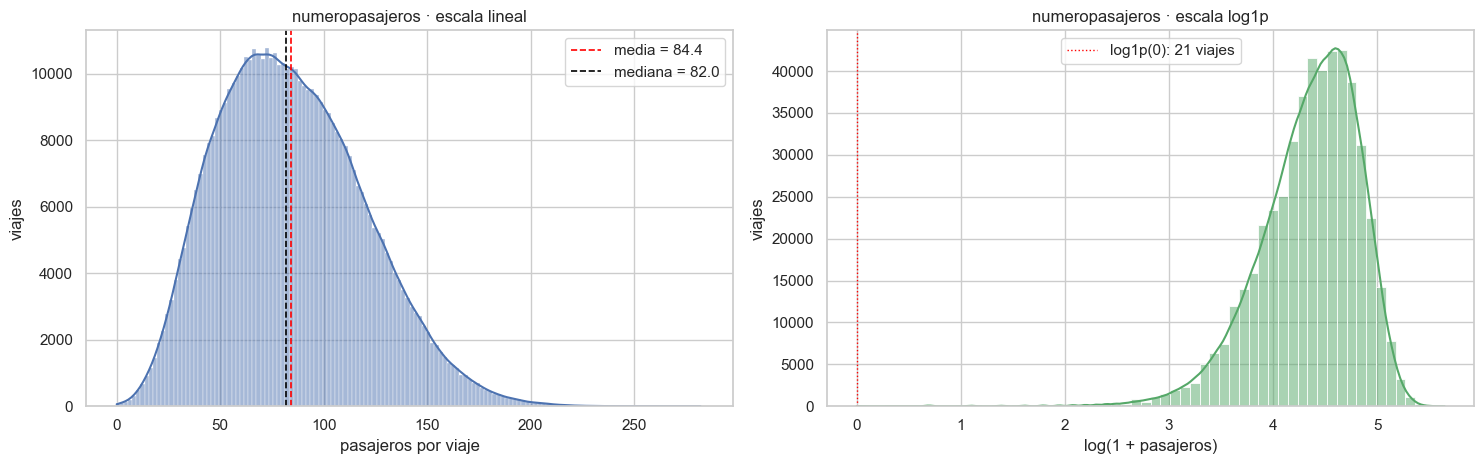

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.histplot(y, bins=np.arange(-0.5, y.max() + 2, 2), kde=True, ax=ax[0], color="#4C72B0", edgecolor=None)  # bins de 2 enteros exactos
for v, c, t in [(y.mean(), "red", "media"), (y.median(), "black", "mediana")]:
    ax[0].axvline(v, color=c, ls="--", lw=1.2, label=f"{t} = {v:.1f}")
ax[0].set(title="numeropasajeros · escala lineal", xlabel="pasajeros por viaje", ylabel="viajes"); ax[0].legend()
sns.histplot(np.log1p(y), bins=60, kde=True, ax=ax[1], color="#55A868", edgecolor=None)
ax[1].axvline(0, color="red", lw=1, ls=":", label=f"log1p(0): {ceros} viajes")
ax[1].set(title="numeropasajeros · escala log1p", xlabel="log(1 + pasajeros)", ylabel="viajes"); ax[1].legend()
plt.tight_layout(); plt.savefig(SALIDA / "histograma_kde.png", dpi=130); plt.show()

**Conclusión 3a · Distribución unimodal; log1p empeora la forma**
- En escala lineal la distribución es unimodal, con media y mediana casi iguales (84 y 82).
- **log1p sobrecorrige:** la asimetría pasa de +0,42 a **−0,94**, con una cola izquierda larga. **No conviene transformar el target con log1p.** Si un modelo lo necesitara, la raíz cuadrada deja la distribución casi simétrica (−0,15).

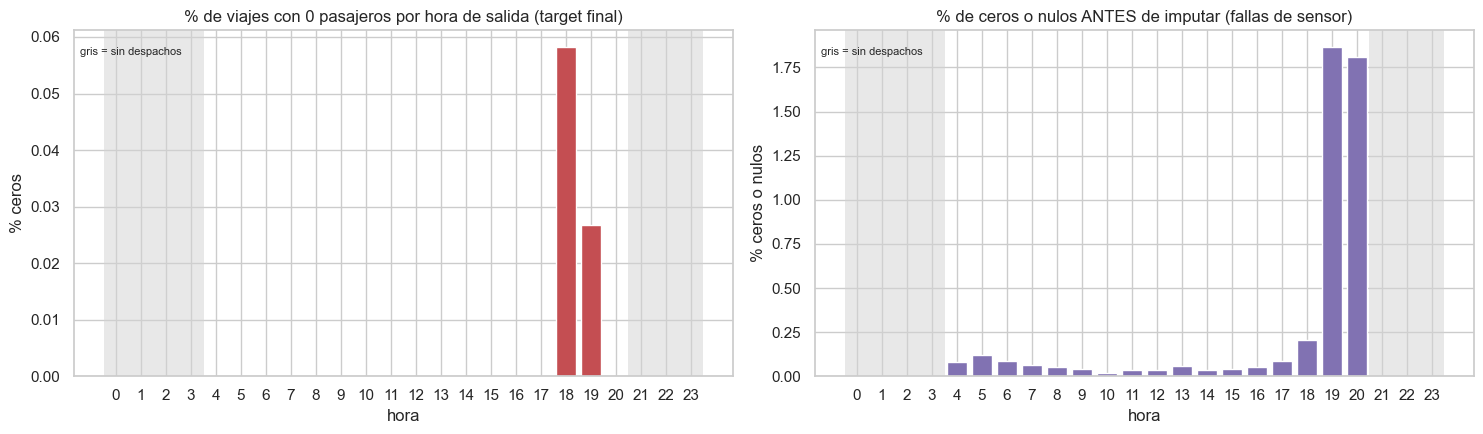

In [74]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
h = por_hora.reset_index()
ax[0].bar(h.hora, h.pct_ceros.fillna(0), color="#C44E52")
ax[0].set(title="% de viajes con 0 pasajeros por hora de salida (target final)", xlabel="hora", ylabel="% ceros", xticks=range(24))
ax[1].bar(h.hora, h.pct_ceros_o_nulos_raw.fillna(0), color="#8172B2")
ax[1].set(title="% de ceros o nulos ANTES de imputar (fallas de sensor)", xlabel="hora", ylabel="% ceros o nulos", xticks=range(24))
for a in ax:
    for hh in h.hora[h.viajes.isna()]:
        a.axvspan(hh - .5, hh + .5, color="lightgrey", alpha=.5, lw=0)
    a.text(.01, .93, "gris = sin despachos", transform=a.transAxes, fontsize=8)
plt.tight_layout(); plt.savefig(SALIDA / "pct_ceros_por_hora.png", dpi=130); plt.show()

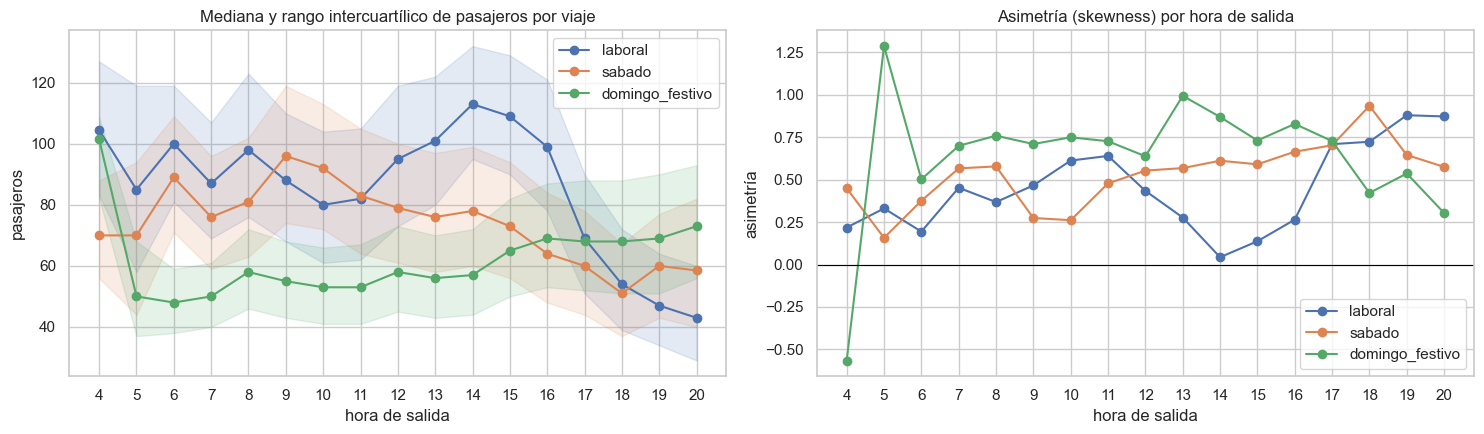

hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
tipo_dia,,,,,,,,,,,,,,,,,
laboral,104.5,85.0,100.0,87.0,98.0,88.0,80.0,82.0,95.0,101.0,113.0,109.0,99.0,69.0,54.0,47.0,43.0
sabado,70.0,70.0,89.0,76.0,81.0,96.0,92.0,83.0,79.0,76.0,78.0,73.0,64.0,60.0,51.0,60.0,58.5
domingo_festivo,101.5,50.0,48.0,50.0,58.0,55.0,53.0,53.0,58.0,56.0,57.0,65.0,69.0,68.0,68.0,69.0,73.0


In [75]:
# Asimetría de la demanda por franja horaria y tipo de día
q = (m.groupby(["tipo_dia", "hora"]).numeropasajeros
       .agg(p25=lambda s: s.quantile(.25), mediana="median", p75=lambda s: s.quantile(.75), asimetria="skew").reset_index())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for t, c in zip(ORDEN_DIA, ["#4C72B0", "#DD8452", "#55A868"]):
    d = q[q.tipo_dia == t]
    ax[0].plot(d.hora, d.mediana, marker="o", color=c, label=t)
    ax[0].fill_between(d.hora, d.p25, d.p75, color=c, alpha=.15)
    ax[1].plot(d.hora, d.asimetria, marker="o", color=c, label=t)
ax[0].set(title="Mediana y rango intercuartílico de pasajeros por viaje", xlabel="hora de salida", ylabel="pasajeros")
ax[1].axhline(0, color="black", lw=.8)
ax[1].set(title="Asimetría (skewness) por hora de salida", xlabel="hora de salida", ylabel="asimetría")
for a in ax:
    a.legend(); a.set_xticks(range(4, 21))
plt.tight_layout(); plt.savefig(SALIDA / "asimetria_hora_tipodia.png", dpi=130); plt.show()
display(q.pivot(index="tipo_dia", columns="hora", values="mediana").reindex(ORDEN_DIA))

**Conclusión 3b · Cada tipo de día tiene un perfil horario distinto**
- **Laboral:** dos máximos, a las 4 h y 6 h (medianas de 104 y 100) y a las **14 h (113)**. Cae a **43 a las 20 h (−62 %)**.
- **Sábado:** máximo a las 9 h (96) y descenso gradual.
- **Domingo-festivo:** plano en la mañana (48–58) y **sube por la tarde hasta 73 a las 20 h**. Es el único día con más demanda al cierre que en la mañana.
- **La hora es la de salida**, y cada viaje dura unas 4 h: un viaje que sale a las 14 h recoge la demanda de 14 a 18 h. El máximo de las 14 h refleja la hora pico de la tarde.
- La asimetría es positiva en casi todas las franjas (entre 0 y 1,3): siempre hay algunos viajes muy cargados. Es más marcada en domingo. El punto del domingo a las 4 h solo tiene 22 viajes y no se interpreta.

## 4. ¿Sobredispersión? ¿Ceros de más? (prueba cuantitativa)
- **Índice de dispersión** D = varianza / media. En un proceso de Poisson D = 1; con D > 1 hay sobredispersión. Se calcula global y **dentro de celdas homogéneas** (ruta × hora × tipo de día, n ≥ 30), para que la variación entre franjas no lo infle.
- **Ceros esperados vs. observados:** en cada celda se calcula la probabilidad de 0 con Poisson, P(0) = e^(−μ), y con una Binomial Negativa ajustada por momentos, P(0) = (r / (r + μ))^r con r = μ² / (σ² − μ). Si los ceros observados superan con creces a los esperados, hay inflación de ceros.

Índice de dispersión global: 14.83
Índice de dispersión dentro de celdas (150 celdas, 497,349 viajes): mediana 9.76 | P10 6.65 | P90 12.48 | mínimo 3.69


,ceros_observados,esperados_Poisson,esperados_BinomialNegativa
0,21,0.0,0.9801


,count,min,50%,max
tipo_dia,,,,
laboral,51.0,6.65,10.14,22.99
sabado,51.0,5.52,10.12,17.75
domingo_festivo,48.0,3.69,8.37,12.78


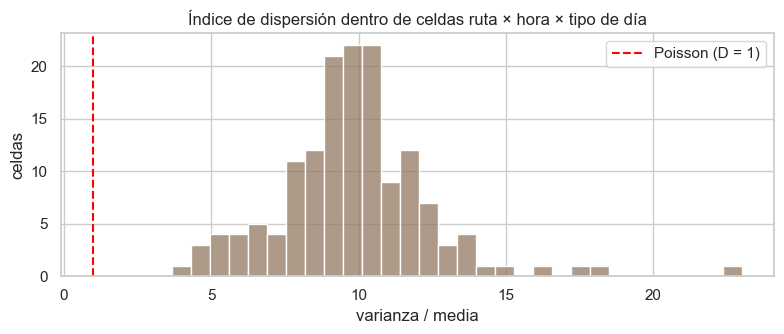

In [76]:
cel = (m.groupby(["idruta", "hora", "tipo_dia"]).numeropasajeros
         .agg(n="size", media="mean", var="var", ceros=lambda s: int((s == 0).sum())).reset_index())
cel = cel[cel.n >= 30].copy()
cel["D"] = cel["var"] / cel.media
cel["r_nb"] = cel.media ** 2 / (cel["var"] - cel.media)
cel["ceros_esp_poisson"] = cel.n * np.exp(-cel.media)
cel["ceros_esp_nb"] = cel.n * (cel.r_nb / (cel.r_nb + cel.media)) ** cel.r_nb
print(f"Índice de dispersión global: {y.var() / y.mean():.2f}")
print(f"Índice de dispersión dentro de celdas ({len(cel)} celdas, {cel.n.sum():,} viajes): mediana {cel.D.median():.2f} "
      f"| P10 {cel.D.quantile(.1):.2f} | P90 {cel.D.quantile(.9):.2f} | mínimo {cel.D.min():.2f}")
display(pd.DataFrame({"ceros_observados": [cel.ceros.sum()],
                      "esperados_Poisson": [cel.ceros_esp_poisson.sum()],
                      "esperados_BinomialNegativa": [cel.ceros_esp_nb.sum()]}).round(4))
display(cel.groupby("tipo_dia").D.describe()[["count", "min", "50%", "max"]].reindex(ORDEN_DIA).round(2))
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(cel.D, bins=30, ax=ax, color="#937860")
ax.axvline(1, color="red", ls="--", label="Poisson (D = 1)"); ax.legend()
ax.set(title="Índice de dispersión dentro de celdas ruta × hora × tipo de día", xlabel="varianza / media", ylabel="celdas")
plt.tight_layout(); plt.savefig(SALIDA / "indice_dispersion_celdas.png", dpi=130); plt.show()

**Conclusión 4 · Sobredispersión fuerte y sin inflación de ceros**
- **Sobredispersión: sí, y robusta.** El índice global es D = 14,8. **Dentro de las 150 celdas homogéneas (ruta × hora × tipo de día), la mediana es 9,8** (P10 a P90 = 6,7 a 12,5; mínimo 3,7). **Todas las celdas superan con creces D = 1.** Viajes de la misma ruta, hora y tipo de día varían unas 10 veces más de lo que permite un proceso de Poisson.
- **Inflación de ceros: no relevante.** Se observan 21 ceros frente a 0 esperados con Poisson y 0,98 con Binomial Negativa. Es un exceso relativo, pero equivale al 0,004 % de los viajes.
- **¿Se acumulan ceros en los valles nocturnos? No.** El valle de la tarde (18–20 h) baja a medianas de **43–56 pasajeros**, lejos de cero, y de 21 a 3 h no hay servicio. Los ceros que sí había en el valle eran fallas del sensor y ya se imputaron.

## Conclusión de la Subfase 2.1
1. **El target `numeropasajeros` (subidas por viaje) es un conteo grande, casi simétrico** (media 84, mediana 82, asimetría 0,42, curtosis −0,13) y **sin masa en cero** (0,0042 %).
2. **Hay sobredispersión fuerte incluso dentro de cada ruta, hora y tipo de día** (D mediano de 9,8): **Poisson no sirve** porque subestimaría la varianza unas 10 veces. La familia adecuada es la **Binomial Negativa** (o quasi-Poisson / Tweedie). **Los modelos zero-inflated (ZIP/ZINB) no hacen falta** a nivel de viaje.
3. **El tipo de día y la hora explican la mayor parte de la variación:** el domingo-festivo tiene un 33 % menos de demanda que el laboral, y el laboral cae un 62 % entre las 14 y las 20 h. **Los festivos deben tratarse como domingo** (13.697 viajes reclasificados).
4. **No transformar con log1p** (invierte la asimetría hasta −0,94).
5. **Cautela para el análisis espacial:** si se baja a tramo, parada o intervalos de 15 min, el diagnóstico de ceros debe repetirse a esa escala, donde sí aparecerán ceros estructurales.

Tabla resumen: `resultados_2_1/tabla_resumen_numeropasajeros.csv` · gráficos: `resultados_2_1/*.png`.

---
# Parte 6 · Subfase 2.2 · Poisson vs Tweedie
*Notebook original: `subfase_2_2_tweedie.ipynb`*

In [77]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_2_2_tweedie.ipynb")

── Inicio de subfase_2_2_tweedie.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 2.2 — Sobredispersión y estimación del parámetro Tweedie $p$

**Objetivo:** estimar $p$ en la relación media-varianza $\mathrm{Var}(Y)=\phi\,\mu^{p}$ de `numeropasajeros` y decidir si la pérdida Tweedie ($1<p<2$) está justificada frente a Poisson o Binomial Negativa.

**Fuente:** `maestras/tb_maestra_progvehiculos_limpia.parquet` (497.371 viajes válidos). Tipo de día con festivos (igual que en la 2.1).

**Corrección a la premisa del enunciado:** la 2.1 mostró que **no hay ceros estructurales** (21 ceros de 497.371, el 0,0042 %). Por eso aquí **Tweedie no se justifica por una masa en cero**, sino únicamente por la forma de la relación media-varianza (ver la sección 4).

Nota técnica: la regresión se hace con `numpy` (mínimos cuadrados e intervalo de confianza bootstrap), porque Windows bloquea las DLL de `scipy` y `sklearn` en este equipo.

In [78]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid"); warnings.filterwarnings("ignore", category=FutureWarning)

SALIDA = Path("resultados_2_2"); SALIDA.mkdir(exist_ok=True)
m = pd.read_parquet("maestras/tb_maestra_progvehiculos_limpia.parquet")
m["numeropasajeros"] = m.numeropasajeros.astype(float)
festivos = holidays.Colombia(years=[2023, 2024, 2025])
es_festivo = m.fecha.dt.date.map(lambda d: d in festivos)
m["tipo_dia"] = np.select([es_festivo | (m.dia_semana == 6), m.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
m["franja_15"] = m.fechasalida.dt.floor("15min").dt.strftime("%H:%M")
ORDEN_DIA = ["laboral", "sabado", "domingo_festivo"]
N_MIN = 30   # mínimo de viajes por estrato para estimar la varianza con estabilidad

def estratos(claves, n_min=N_MIN):
    g = m.groupby(claves).numeropasajeros.agg(n="size", mu="mean", var="var").reset_index()
    return g[g.n >= n_min].reset_index(drop=True)

def ols(x, y, w=None):
    """Mínimos cuadrados (ponderados si w) de y = a + b·x. Devuelve a, b, error estándar de b y R²."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    w = np.ones_like(x) if w is None else np.asarray(w, float)
    X = np.column_stack([np.ones_like(x), x]); XtW = X.T * w
    a, b = np.linalg.solve(XtW @ X, XtW @ y)
    r = y - (a + b * x); ss_res = (w * r ** 2).sum(); ss_tot = (w * (y - np.average(y, weights=w)) ** 2).sum()
    se_b = np.sqrt(ss_res / (len(x) - 2) * np.linalg.inv(XtW @ X)[1, 1])
    return a, b, se_b, 1 - ss_res / ss_tot

## 1. Estratos operacionales (ruta × franja de 15 min × tipo de día) e índice de dispersión

In [79]:
G = estratos(["idruta", "franja_15", "tipo_dia"])
G["D"] = G["var"] / G.mu
total = m.groupby(["idruta", "franja_15", "tipo_dia"]).ngroups
print(f"Estratos: {total} | con n ≥ {N_MIN}: {len(G)} | viajes cubiertos: {G.n.sum():,} de {len(m):,}")
phi_global = m.numeropasajeros.var() / m.numeropasajeros.mean()
print(f"Índice de dispersión global φ = Var/Media = {m.numeropasajeros.var():,.1f} / {m.numeropasajeros.mean():.2f} = {phi_global:.2f}"
      f"  → {'SOBREDISPERSIÓN (φ > 1)' if phi_global > 1 else 'sin sobredispersión'}")
print(f"Índice de dispersión por estrato: mediana {G.D.median():.2f} | P10 {G.D.quantile(.1):.2f} | P90 {G.D.quantile(.9):.2f} | "
      f"estratos con D > 1: {(G.D > 1).mean():.1%}")
display(G[["n", "mu", "var", "D"]].describe().round(2))
G.to_csv(SALIDA / "estratos_ruta_franja15_tipodia.csv", index=False)

Estratos: 581 | con n ≥ 30: 575 | viajes cubiertos: 497,321 de 497,371
Índice de dispersión global φ = Var/Media = 1,252.4 / 84.43 = 14.83  → SOBREDISPERSIÓN (φ > 1)
Índice de dispersión por estrato: mediana 9.60 | P10 6.18 | P90 12.79 | estratos con D > 1: 100.0%


,n,mu,var,D
count,575.00,575.00,575.00,575.00
mean,864.91,75.70,742.81,9.64
std,976.24,19.16,303.12,2.82
min,32.00,23.16,120.91,3.19
25%,243.00,59.44,537.98,8.08
50%,515.00,75.71,738.70,9.60
75%,1031.00,89.75,931.29,10.93
max,6279.00,117.78,2152.39,26.04


**Conclusión 1 · Sobredispersión confirmada en todos los estratos**
- **Índice global: φ = 1.252,4 / 84,43 = 14,83 > 1.**
- **El 100 % de los 575 estratos** (ruta × franja de 15 min × tipo de día, n ≥ 30, que cubren 497.321 viajes) tiene D > 1. La mediana es 9,6 (P10 a P90 = 6,2 a 12,8; mínimo 3,2).
- La varianza entre estratos va de 121 a 2.152 (**18 veces**), mientras la media solo va de 23 a 118 (5 veces): la varianza crece más rápido que la media.

## 2. Ajuste log-log: $\ln\sigma^2_g = \ln\phi + p\,\ln\mu_g$
Además del ajuste libre se comparan las relaciones media-varianza de los modelos candidatos, midiendo cuánto de la varianza de $\ln\sigma^2_g$ explica cada uno ($R^2$ en escala log):
| Modelo | Varianza implícita |
|---|---|
| Poisson | $\mu$ |
| quasi-Poisson ($p=1$) | $\phi\,\mu$ |
| Binomial Negativa | $\mu + \alpha\,\mu^2$ |
| Gamma ($p=2$) | $\phi\,\mu^2$ |
| **Tweedie ($p$ libre)** | $\phi\,\mu^{p}$ |

In [80]:
x, yv = np.log(G.mu.values), np.log(G["var"].values)
a, p_hat, se_p, r2 = ols(x, yv)
phi_hat = np.exp(a)
rng = np.random.default_rng(42)
boot = np.array([ols(x[i], yv[i])[1] for i in (rng.integers(0, len(x), len(x)) for _ in range(2000))])
ic_boot = np.percentile(boot, [2.5, 97.5])
print(f"p̂ = {p_hat:.3f}  (EE {se_p:.3f} · IC95 analítico [{p_hat - 1.96 * se_p:.3f}, {p_hat + 1.96 * se_p:.3f}] · "
      f"IC95 bootstrap [{ic_boot[0]:.3f}, {ic_boot[1]:.3f}])")
print(f"φ̂ = {phi_hat:.3f}  |  R² = {r2:.3f}  |  ¿1 < p̂ < 2? {'SÍ' if 1 < p_hat < 2 else 'NO'} "
      f"(el IC bootstrap {'excluye' if ic_boot[0] > 1 and ic_boot[1] < 2 else 'NO excluye'} 1 y 2)")

def r2_log(var_pred):
    r = yv - np.log(np.asarray(var_pred, float)); return 1 - (r ** 2).sum() / ((yv - yv.mean()) ** 2).sum()

alpha_nb = ((G["var"] - G.mu) * G.mu ** 2).sum() / (G.mu ** 4).sum()
comp = pd.DataFrame({
    "modelo": ["Poisson", "quasi-Poisson (p=1)", "Binomial Negativa", "Gamma (p=2)", "Tweedie (p libre)"],
    "parametros": ["φ=1", f"φ={np.exp((yv - x).mean()):.2f}", f"α={alpha_nb:.3f} (r≈{1 / alpha_nb:.1f})",
                   f"φ={np.exp((yv - 2 * x).mean()):.3f}", f"φ={phi_hat:.2f}, p={p_hat:.2f}"],
    "R2_log_varianza": [r2_log(G.mu), r2_log(np.exp((yv - x).mean()) * G.mu), r2_log(G.mu + alpha_nb * G.mu ** 2),
                        r2_log(np.exp((yv - 2 * x).mean()) * G.mu ** 2), r2_log(phi_hat * G.mu ** p_hat)]}).round(3)
display(comp)
pd.DataFrame([{"p_hat": p_hat, "se": se_p, "ic95_boot_lo": ic_boot[0], "ic95_boot_hi": ic_boot[1], "phi_hat": phi_hat,
               "R2": r2, "estratos": len(G), "phi_global": phi_global}]).to_csv(SALIDA / "estimacion_p.csv", index=False)

p̂ = 1.397  (EE 0.044 · IC95 analítico [1.310, 1.483] · IC95 bootstrap [1.294, 1.499])
φ̂ = 1.682  |  R² = 0.635  |  ¿1 < p̂ < 2? SÍ (el IC bootstrap excluye 1 y 2)


,modelo,parametros,R2_log_varianza
0,Poisson,φ=1,-22.399
1,quasi-Poisson (p=1),φ=9.23,0.584
2,Binomial Negativa,α=0.101 (r≈9.9),0.518
3,Gamma (p=2),φ=0.126,0.517
4,Tweedie (p libre),"φ=1.68, p=1.40",0.635


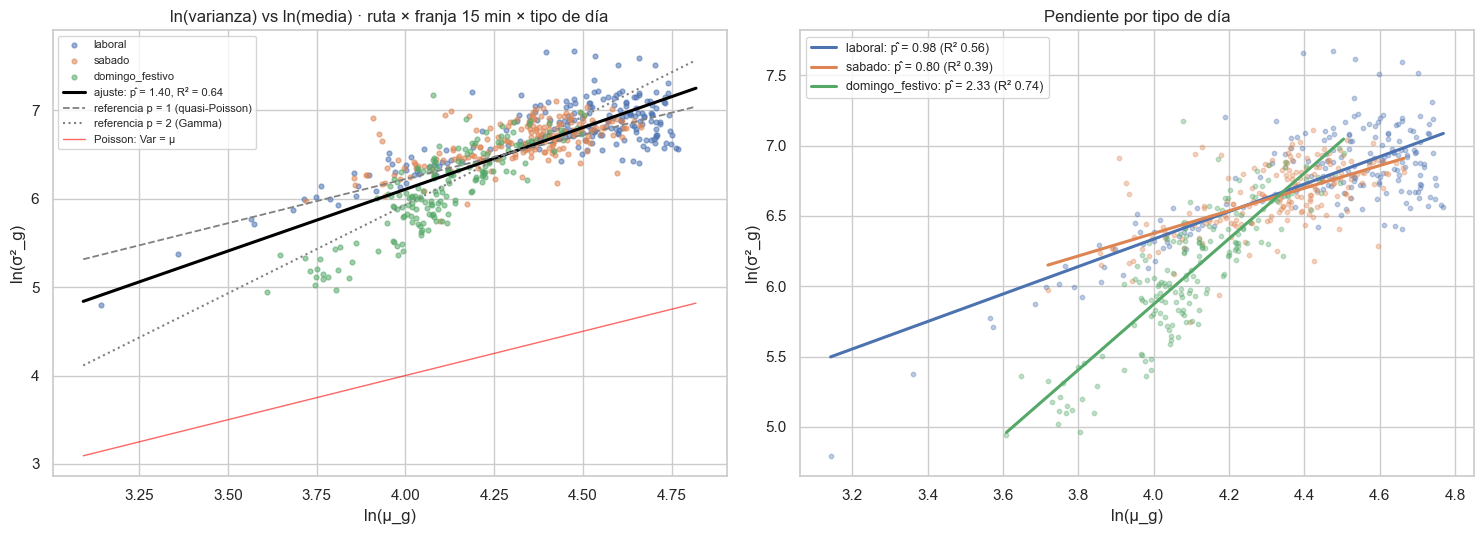

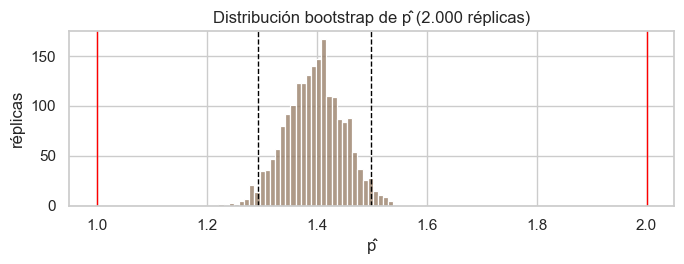

In [81]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
xs = np.linspace(x.min() - .05, x.max() + .05, 50)
xm, ym = x.mean(), yv.mean()
colores = dict(zip(ORDEN_DIA, ["#4C72B0", "#DD8452", "#55A868"]))
for t in ORDEN_DIA:
    s = G.tipo_dia == t
    ax[0].scatter(x[s], yv[s], s=12, alpha=.55, color=colores[t], label=t)
ax[0].plot(xs, a + p_hat * xs, color="black", lw=2.2, label=f"ajuste: p̂ = {p_hat:.2f}, R² = {r2:.2f}")
ax[0].plot(xs, ym + 1 * (xs - xm), "--", color="grey", lw=1.3, label="referencia p = 1 (quasi-Poisson)")
ax[0].plot(xs, ym + 2 * (xs - xm), ":", color="grey", lw=1.5, label="referencia p = 2 (Gamma)")
ax[0].plot(xs, xs, color="red", lw=1, alpha=.6, label="Poisson: Var = μ")
ax[0].set(title="ln(varianza) vs ln(media) · ruta × franja 15 min × tipo de día", xlabel="ln(μ_g)", ylabel="ln(σ²_g)")
ax[0].legend(fontsize=8, loc="upper left")
for t in ORDEN_DIA:
    s = (G.tipo_dia == t).values
    at, bt, _, rt = ols(x[s], yv[s])
    ax[1].scatter(x[s], yv[s], s=10, alpha=.35, color=colores[t])
    xx = np.linspace(x[s].min(), x[s].max(), 20)
    ax[1].plot(xx, at + bt * xx, color=colores[t], lw=2.2, label=f"{t}: p̂ = {bt:.2f} (R² {rt:.2f})")
ax[1].set(title="Pendiente por tipo de día", xlabel="ln(μ_g)", ylabel="ln(σ²_g)"); ax[1].legend(fontsize=9)
plt.tight_layout(); plt.savefig(SALIDA / "loglog_media_varianza.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(7, 2.8))
sns.histplot(boot, bins=40, ax=ax, color="#937860")
for v in ic_boot: ax.axvline(v, color="black", ls="--", lw=1)
ax.axvline(1, color="red", lw=1); ax.axvline(2, color="red", lw=1)
ax.set(title="Distribución bootstrap de p̂ (2.000 réplicas)", xlabel="p̂", ylabel="réplicas")
plt.tight_layout(); plt.savefig(SALIDA / "bootstrap_p.png", dpi=130); plt.show()

**Conclusión 2 · $\hat p$ = 1,40 está dentro de (1, 2), y la ley de potencia libre es la que mejor describe la varianza**
- **$\hat p$ = 1,397, con IC95 bootstrap de 1,29 a 1,50**: excluye tanto 1 como 2. $\hat\phi$ = 1,68 y $R^2$ = 0,64.
- **Comparación de relaciones media-varianza** ($R^2$ sobre $\ln\sigma^2$):

| Modelo | $R^2$ |
|---|---|
| **Tweedie con $p$ libre** | **0,64** |
| quasi-Poisson ($p$ = 1, φ = 9,2) | 0,58 |
| Binomial Negativa ($\alpha$ = 0,10) | 0,52 |
| Gamma ($p$ = 2) | 0,52 |
| Poisson | −22,4 |

- **Poisson queda descartado:** su recta (en rojo) está unas 2,2 unidades de log por debajo de los datos, es decir, subestima la varianza unas 9 veces.
- El panel derecho muestra que **la pendiente no es igual en todos los días:** laboral 0,98, sábado 0,80 y **domingo-festivo 2,33**. El $\hat p$ = 1,40 conjunto mezcla esos regímenes (ver la sección 3).

## 3. Robustez: ¿el valor de $p$ depende de cómo se estratifica?

In [82]:
filas = []
def agregar(etiqueta, H, w=None):
    a_, b_, se_, r_ = ols(np.log(H.mu), np.log(H["var"]), w)
    filas.append({"especificacion": etiqueta, "estratos": len(H), "viajes": int(H.n.sum()), "p_hat": b_,
                  "ic95": f"[{b_ - 1.96 * se_:.2f}, {b_ + 1.96 * se_:.2f}]", "phi": np.exp(a_), "R2": r_,
                  "mu_min": H.mu.min(), "mu_max": H.mu.max()})

agregar("BASE: ruta × franja15 × tipo_día", G)
agregar("BASE ponderada por n", G, G.n)
for t in ORDEN_DIA:
    agregar(f"solo {t}", G[G.tipo_dia == t])
for r in sorted(G.idruta.unique()):
    agregar(f"solo ruta {r}", G[G.idruta == r])
agregar("ruta × hora × tipo_día × MES (n ≥ 20)", estratos(["idruta", "hora", "tipo_dia", "anio_mes"], 20))
agregar("ruta × franja15 × tipo_día × MES (n ≥ 20)", estratos(["idruta", "franja_15", "tipo_dia", "anio_mes"], 20))
rob = pd.DataFrame(filas)
rob.to_csv(SALIDA / "robustez_p.csv", index=False)
display(rob.round(3))

,especificacion,estratos,viajes,p_hat,ic95,phi,R2,mu_min,mu_max
0,BASE: ruta × franja15 × tipo_día,575,497321,1.397,"[1.31, 1.48]",1.682,0.635,23.156,117.780
1,BASE ponderada por n,575,497321,1.108,"[1.01, 1.20]",6.058,0.474,23.156,117.780
2,solo laboral,197,363881,0.977,"[0.86, 1.10]",11.352,0.565,23.156,117.780
3,solo sabado,195,71850,0.803,"[0.66, 0.94]",23.651,0.394,41.230,106.111
4,solo domingo_festivo,183,61590,2.330,"[2.13, 2.53]",0.032,0.740,36.922,90.361
5,solo ruta 2,191,138609,1.476,"[1.36, 1.59]",1.400,0.757,28.794,114.612
6,solo ruta 16,192,271119,1.331,"[1.18, 1.48]",2.003,0.625,42.439,117.780
7,solo ruta 21,192,87593,1.510,"[1.36, 1.66]",0.989,0.671,23.156,115.574
8,ruta × hora × tipo_día × MES (n ≥ 20),4578,486181,1.258,"[1.22, 1.29]",2.810,0.497,24.399,142.014
9,ruta × franja15 × tipo_día × MES (n ≥ 20),7560,378691,1.066,"[1.04, 1.09]",6.372,0.404,14.967,143.139


**Conclusión 3 · $p$ es real pero no universal: el rango defendible es de 1,1 a 1,5**
- **Por ruta es estable:** 1,48 (ruta 2), 1,33 (ruta 16) y 1,51 (ruta 21).
- **Por tipo de día no lo es:**
  - **Laboral y sábado:** $p$ ≈ 0,8–1,0. La varianza crece proporcional a la media, con φ de 11 a 24 (comportamiento quasi-Poisson).
  - **Domingo-festivo:** $p$ ≈ 2,3. Hay más heterogeneidad relativa cuando la demanda sube.
- **Al controlar el mes**, es decir, al quitar la tendencia 2023–2025 y la estacionalidad, $p$ baja a **1,26** (estratos ruta × hora × tipo de día × mes) y a **1,07** (con franja de 15 min). **Ponderando por tamaño del estrato** queda en 1,11.
- **Lectura:** una parte del 1,40 conjunto viene de mezclar meses y días con niveles distintos. Un modelo que ya tenga como variables el tipo de día, la hora y el calendario verá una varianza residual con **$p$ más cerca de 1,1–1,3**.

## 4. Justificación teórica y configuración recomendada

**La familia Tweedie.** Es la familia de dispersión exponencial con $\mathrm{Var}(Y)=\phi\,\mu^{p}$:
- $p=1$: Poisson ($\phi=1$) o quasi-Poisson ($\phi$ libre).
- $p=2$: Gamma.
- **$1<p<2$: Poisson compuesta-Gamma**, una masa en cero más una parte continua positiva.

**Corrección importante a la premisa del enunciado.** `numeropasajeros` **no tiene masa en cero** (0,0042 %, 2.1) y es un **conteo discreto**. Por eso la distribución Poisson compuesta-Gamma **no es su modelo generativo**. Lo que sí se justifica es usar **Tweedie como función de pérdida (cuasi-verosimilitud)**:
- Un GLM o un GBM con pérdida Tweedie solo necesita que la **media** (con enlace log) y la **función de varianza** $\phi\,\mu^{p}$ estén bien especificadas, y que $y\ge 0$.
- No necesita que $Y$ sea realmente Poisson compuesta-Gamma. Es el principio de cuasi-verosimilitud de McCullagh y Nelder.

**Por qué `objective='tweedie'` en LightGBM y XGBoost:**
1. **La varianza no es constante.** Crece 18 veces entre estratos, así que MSE (`regression`), que supone varianza constante, sobrepondera los viajes de alta demanda.
2. **La varianza no es igual a la media.** Poisson la subestima unas 9 veces en nivel. En un GBM φ no cambia la predicción puntual, así que `objective='poisson'` equivale a quasi-Poisson ($p$ = 1). **La diferencia real entre las pérdidas Poisson y Tweedie es el valor de $p$**, y los datos dan $\hat p$ > 1 (IC de 1,29 a 1,50).
3. **La Binomial Negativa no está disponible** como objetivo en LightGBM ni en XGBoost, y además su varianza cuadrática ajusta peor (0,52 frente a 0,64).
4. **Ventajas del enlace log de Tweedie:** las predicciones nunca son negativas, y los efectos de hora, día y ruta se combinan de forma multiplicativa, coherente con los perfiles de la 2.1.

**Valor inicial recomendado: `tweedie_variance_power = 1.3`.** Está en el centro del rango robusto: entre el 1,40 conjunto y el 1,07–1,26 de la varianza condicional al mes. Después hay que ajustarlo con **validación temporal** (entrenar en el pasado y evaluar en meses posteriores) sobre la rejilla {1.1, 1.2, 1.3, 1.4, 1.5}, con `objective='poisson'` como línea base.

```python
# LightGBM
params_lgb = {"objective": "tweedie", "tweedie_variance_power": 1.3, "metric": ["tweedie", "mae"]}
# XGBoost
params_xgb = {"objective": "reg:tweedie", "tweedie_variance_power": 1.3, "eval_metric": ["tweedie-nloglik@1.3", "mae"]}
```

**Cautelas:**
- Como el domingo-festivo tiene $p$ ≈ 2,3, conviene **evaluar el error por tipo de día**: un $p$ único es un compromiso.
- En este equipo **`lightgbm` y `xgboost` no están instalados**, y Windows bloquea `scipy` y `sklearn`. Hay que resolverlo antes de la fase de modelado.

## Conclusión de la Subfase 2.2
1. **Sobredispersión confirmada:** φ global = 14,8 y D > 1 en el 100 % de los 575 estratos (mediana 9,6). **Poisson queda descartado.**
2. **$\hat p$ = 1,40 (IC95 de 1,29 a 1,50, $R^2$ = 0,64):** $1<\hat p<2$ se cumple y la ley de potencia libre describe la varianza mejor que quasi-Poisson, Binomial Negativa o Gamma.
3. **$p$ no es universal:** es estable entre rutas (1,33–1,51), pero cerca de 1 en laboral y sábado, cerca de 2,3 en domingo-festivo, y de 1,07–1,26 cuando se controla el mes.
4. **Recomendación:** `objective='tweedie'` con **`tweedie_variance_power = 1.3`** como valor inicial, ajustado con validación temporal en {1.1 … 1.5} y comparado con Poisson.
5. **Se justifica por la relación media-varianza, no por ceros:** el target no tiene masa en cero, así que Tweedie se usa como cuasi-verosimilitud y no como modelo generativo.

Salidas: `resultados_2_2/estimacion_p.csv`, `robustez_p.csv`, `estratos_ruta_franja15_tipodia.csv`, `loglog_media_varianza.png`, `bootstrap_p.png`.

---
# Parte 7 · Subfase 2.3 · Atípicos del objetivo
*Notebook original: `subfase_2_3_outliers.ipynb`*

In [83]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_2_3_outliers.ipynb")

── Inicio de subfase_2_3_outliers.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 2.3 — Outliers del target y capacidad física del bus

**Objetivo:** definir la regla final de filtrado o truncamiento de `numeropasajeros` para el dataset de entrenamiento, sin dejar que errores de sensor contaminen la pérdida y sin sesgar las métricas.

**Fuente:** `maestras/tb_maestra_progvehiculos_limpia.parquet` (497.371 viajes) + `datos_1_3/tabla_vehiculos.csv` (`n_sentados + n_depie`) + `datos_1_3/lecturas.csv` (secuencias de 1.673 viajes).

**Advertencia de partida:** `numeropasajeros` son las **subidas totales de un viaje de unas 4 h**, no la ocupación simultánea. La capacidad del bus limita cuántas personas van **a la vez**, no cuántas suben en todo el recorrido. Por eso la regla `numeropasajeros > 1,5 × capacidad` se audita aquí, pero no se adopta sin comprobarla.

In [84]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from IPython.display import display
import filtros_1_3 as f3
import filtros_2_3 as f23
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid"); warnings.filterwarnings("ignore", category=FutureWarning)

SALIDA = Path("resultados_2_3"); SALIDA.mkdir(exist_ok=True)
m = pd.read_parquet("maestras/tb_maestra_progvehiculos_limpia.parquet")
m["y"] = m.numeropasajeros.astype(float)
festivos = holidays.Colombia(years=[2023, 2024, 2025])
es_festivo = m.fecha.dt.date.map(lambda d: d in festivos)
m["tipo_dia"] = np.select([es_festivo | (m.dia_semana == 6), m.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
m["franja_15"] = m.fechasalida.dt.floor("15min").dt.strftime("%H:%M")

veh = pd.read_csv("datos_1_3/tabla_vehiculos.csv")
veh["cap_bus"] = veh.n_sentados.fillna(0) + veh.n_depie.fillna(0)
cap_modelo = veh[veh.cap_bus > 0].groupby(veh.modelo.astype("string").fillna("SIN_MODELO")).cap_bus.max()
m["capacidad_calculada_max"] = m.modelo.astype("string").map(cap_modelo).fillna(74)
print(f"{len(m):,} viajes | capacidad del bus: mediana {m.capacidad.median():.0f} (32–74) | "
      f"capacidad máxima del modelo: mediana {m.capacidad_calculada_max.median():.0f} (46–74)")

497,371 viajes | capacidad del bus: mediana 50 (32–74) | capacidad máxima del modelo: mediana 70 (46–74)


## 1. Auditoría de percentiles y sobreocupación
Consulta SQL (archivo `auditoria_2_3.sql`, para cuando la maestra exista en PostgreSQL):
```sql
-- =====================================================================================
-- SOBUSA · Subfase 2.3 — Auditoría de outliers del target y capacidad física
-- Requiere public.tb_maestra_progvehiculos_limpia (tb_maestras_modulo1.sql) y public.vehiculos.
-- La misma lógica corre en local en subfase_2_3_outliers.ipynb (la tabla maestra no existe aún en la RDS).
-- =====================================================================================

WITH cap_modelo AS (            -- capacidad máxima calculada por modelo: max(n_sentados + n_depie)
    SELECT COALESCE(modelo, 'SIN_MODELO') AS modelo,
           max(COALESCE(n_sentados, 0) + COALESCE(n_depie, 0)) AS capacidad_calculada_max
    FROM public.vehiculos
    WHERE COALESCE(n_sentados, 0) + COALESCE(n_depie, 0) > 0
    GROUP BY 1
), base AS (
    SELECT m.idprogramacion, m.idvehiculo, m.idruta, m.fechasalida, m.numeropasajeros,
           m.capacidad                                     AS capacidad_bus,
           COALESCE(c.capacidad_calculada_max, 74)         AS capacidad_calculada_max,
           m.pasajeros_imputado
    FROM public.tb_maestra_progvehiculos_limpia m
    LEFT JOIN cap_modelo c ON c.modelo = m.modelo
)
-- 1. Percentiles extremos globales y conteo de sobreocupación
SELECT count(*)                                                                    AS viajes,
       percentile_cont(0.95)  WITHIN GROUP (ORDER BY numeropasajeros)               AS p95,
       percentile_cont(0.99)  WITHIN GROUP (ORDER BY numeropasajeros)               AS p99,
       percentile_cont(0.995) WITHIN GROUP (ORDER BY numeropasajeros)               AS p99_5,
       percentile_cont(0.999) WITHIN GROUP (ORDER BY numeropasajeros)               AS p99_9,
       max(numeropasajeros)                                                        AS maximo,
       -- regla literal del enunciado (compara SUBIDAS DEL VIAJE con la capacidad SIMULTÁNEA: no es válida, ver notebook)
       count(*) FILTER (WHERE numeropasajeros > 1.5 * capacidad_calculada_max)     AS literal_cap_modelo,
       count(*) FILTER (WHERE numeropasajeros > 1.5 * capacidad_bus)               AS literal_cap_bus,
       -- regla física coherente: capacidad × 1,5 de carga máxima × 3,92 de renovación máxima (≈ 5,9 × capacidad)
       count(*) FILTER (WHERE numeropasajeros > capacidad_bus * 1.5 * 3.92)        AS outlier_fisico
FROM base;

-- 2. Detalle de los viajes por encima del límite físico (debe devolver 0 filas tras la 1.4)
WITH base AS (
    SELECT idprogramacion, idvehiculo, idruta, fechasalida, numeropasajeros, capacidad
    FROM public.tb_maestra_progvehiculos_limpia
)
SELECT *, round(numeropasajeros / capacidad, 2) AS subidas_por_puesto
FROM base
WHERE numeropasajeros > capacidad * 1.5 * 3.92
ORDER BY subidas_por_puesto DESC;
```
Equivalente ejecutado en local:

In [85]:
pct = m.y.quantile([.95, .99, .995, .999]).rename(lambda q: f"P{q * 100:g}")
display(pd.concat([pct, pd.Series({"máximo": m.y.max()})]).to_frame("pasajeros por viaje"))

reglas = {
    "literal: > 1,5 × capacidad máx. del modelo": m.y > 1.5 * m.capacidad_calculada_max,
    "literal: > 1,5 × capacidad del bus": m.y > 1.5 * m.capacidad,
    "> 3 × capacidad del bus": m.y > 3 * m.capacidad,
    "> 5 × capacidad del bus (pico imposible, 1.3)": m.y > 5 * m.capacidad,
}
display(pd.DataFrame({"viajes": {k: int(v.sum()) for k, v in reglas.items()},
                      "pct": {k: round(100 * v.mean(), 2) for k, v in reglas.items()}}))
display((m.y / m.capacidad).describe(percentiles=[.5, .9, .99, .999]).round(2).to_frame("subidas por puesto (y / capacidad)").T)

,pasajeros por viaje
P95,147.0
P99,174.0
P99.5,185.0
P99.9,206.0
máximo,282.0


,viajes,pct
"literal: > 1,5 × capacidad máx. del modelo",181818,36.56
"literal: > 1,5 × capacidad del bus",265648,53.41
> 3 × capacidad del bus,19167,3.85
"> 5 × capacidad del bus (pico imposible, 1.3)",0,0.00


,count,mean,std,min,50%,90%,99%,99.9%,max
subidas por puesto (y / capacidad),497371.0,1.64,0.71,0.0,1.57,2.59,3.52,4.28,5.0


**Conclusión 1 · La regla literal marcaría como imposible a más de un tercio de los viajes reales**
- **Percentiles extremos:** P95 = 147 · P99 = 174 · P99,5 = 185 · P99,9 = 206 · máximo = 282.
- `numeropasajeros > 1,5 × capacidad` marca **181.818 viajes (36,6 %)** con la capacidad máxima del modelo y **265.648 (53,4 %)** con la del bus. Con la capacidad mediana el corte cae en **105 pasajeros**, por encima de la mediana de la distribución (82).
- **En promedio, un viaje sube 1,64 veces la capacidad del bus** (P99 = 3,5; máximo = 5,0). No es error: es la renovación de pasajeros a lo largo de unas 4 h (sección 2).
- **No queda ningún viaje por encima de 5 veces la capacidad:** los 123 picos imposibles ya se detectaron en la 1.3 y se imputaron en la 1.4.

## 2. ¿Por qué las subidas del viaje superan la capacidad? Renovación de pasajeros (lecturas)

,rotacion,ocupacion_max,subidas_por_puesto
count,1440.00,1440.00,1440.00
mean,2.50,0.68,1.65
std,0.59,0.29,0.72
min,1.00,0.07,0.16
50%,2.47,0.66,1.58
90%,3.29,1.06,2.62
95%,3.54,1.16,2.88
99%,3.92,1.36,3.56
max,4.43,2.51,4.49


Límite físico de subidas por viaje = capacidad × 1.5 (carga máxima) × 3.92 (renovación P99) = 5.88 × capacidad


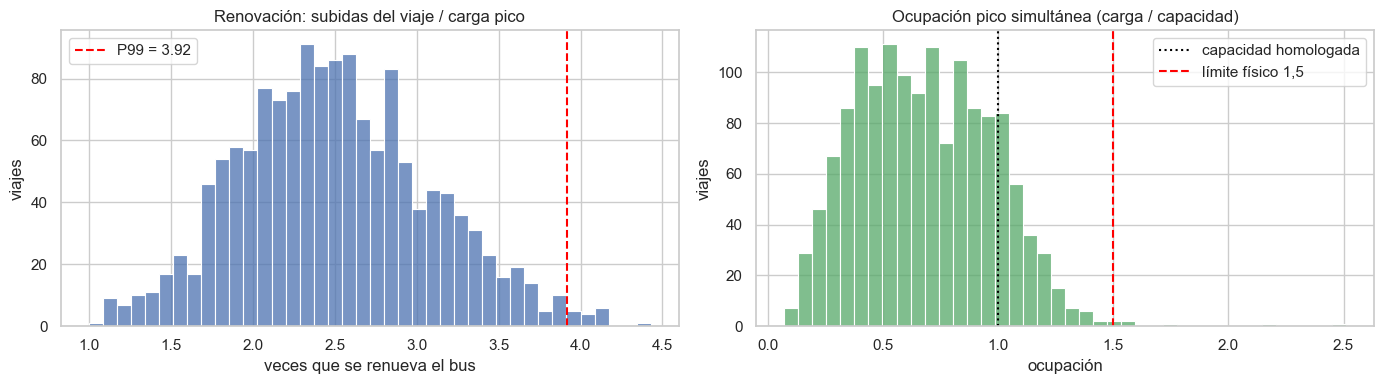

In [86]:
lect = pd.read_csv("datos_1_3/lecturas.csv", low_memory=False)
L = f3.auditar_lecturas(lect, m.drop_duplicates("idvehiculo").set_index("idvehiculo").capacidad, f3.Config(), secuencias=True)
R = f3.resumen_lecturas_por_viaje(L)
val = pd.read_parquet("datos_1_2/viajes_validos.parquet", columns=["idprogramacion", "idruta"])
ids_sv = pd.read_csv("datos_1_3/sensores_viaje.csv", usecols=["idprogramacion"])
AZAR = set(val.merge(ids_sv, on="idprogramacion").groupby("idruta", group_keys=False)
              .apply(lambda g: g.sample(min(500, len(g)), random_state=42), include_groups=False).idprogramacion)
A = R[R.index.isin(AZAR) & (R.calidad_conteo != "corrupto") & (R.max_a_bordo > 0)].copy()
A["rotacion"] = A.subidas_sensor / A.max_a_bordo          # cuántas veces se "llena" el bus en el viaje
A["subidas_por_puesto"] = A.subidas_sensor / A.capacidad
display(A[["rotacion", "ocupacion_max", "subidas_por_puesto"]].describe(percentiles=[.5, .9, .95, .99]).round(2))
regla = f23.ReglaTarget(rotacion_max=round(A.rotacion.quantile(.99), 2))
print(f"Límite físico de subidas por viaje = capacidad × {regla.factor_carga_max} (carga máxima) × {regla.rotacion_max} "
      f"(renovación P99) = {regla.multiplicador:.2f} × capacidad")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(A.rotacion, bins=40, ax=ax[0], color="#4C72B0")
ax[0].axvline(regla.rotacion_max, color="red", ls="--", label=f"P99 = {regla.rotacion_max}"); ax[0].legend()
ax[0].set(title="Renovación: subidas del viaje / carga pico", xlabel="veces que se renueva el bus", ylabel="viajes")
sns.histplot(A.ocupacion_max, bins=40, ax=ax[1], color="#55A868")
ax[1].axvline(1, color="black", ls=":", label="capacidad homologada")
ax[1].axvline(regla.factor_carga_max, color="red", ls="--", label="límite físico 1,5"); ax[1].legend()
ax[1].set(title="Ocupación pico simultánea (carga / capacidad)", xlabel="ocupación", ylabel="viajes")
plt.tight_layout(); plt.savefig(SALIDA / "renovacion_ocupacion.png", dpi=130); plt.show()

**Conclusión 2 · El bus se renueva unas 2,5 veces por viaje: por eso las subidas superan la capacidad**
- En 1.440 viajes al azar con lecturas, **las subidas del viaje equivalen a 2,47 veces la carga pico** (mediana; P99 = 3,92; máximo = 4,43). La ocupación pico simultánea tiene mediana 0,66 y P99 de 1,36.
- **El límite físico coherente para las subidas de un viaje es capacidad × 1,5 × 3,92 = 5,88 × capacidad**: la carga simultánea máxima por la renovación máxima observada. Con la capacidad mediana de 50 son 294 pasajeros, por encima del máximo observado (282).

## 3. ¿Los viajes más cargados son errores? Perfil del top 0,1 %

In [87]:
top = m.y >= m.y.quantile(.999)
perfil = pd.DataFrame({
    "viajes": [top.sum(), (~top).sum()],
    "pasajeros_mediana": [m.y[top].median(), m.y[~top].median()],
    "flag_sensor_ok_%": [100 * m.flag_sensor_ok[top].mean(), 100 * m.flag_sensor_ok[~top].mean()],
    "incoherencia_%": [100 * m.flag_incoherencia_pasajeros[top].mean(), 100 * m.flag_incoherencia_pasajeros[~top].mean()],
    "balance_desviado_>20%_%": [100 * (m.balance_final.abs() > .2 * m.y)[top].mean(), 100 * (m.balance_final.abs() > .2 * m.y)[~top].mean()],
    "duracion_mediana_min": [m.duracion_min[top].median(), m.duracion_min[~top].median()],
    "laboral_%": [100 * (m.tipo_dia[top] == "laboral").mean(), 100 * (m.tipo_dia[~top] == "laboral").mean()],
}, index=["top 0,1 % (≥ P99,9)", "resto"]).round(1)
display(perfil)
display(m[top].hora.value_counts().sort_index().to_frame("viajes top 0,1 %").T)

,viajes,pasajeros_mediana,flag_sensor_ok_%,incoherencia_%,balance_desviado_>20%_%,duracion_mediana_min,laboral_%
"top 0,1 % (≥ P99,9)",511,213.0,98.4,1.4,2.3,267.0,96.1
resto,496860,81.0,92.6,6.6,4.5,232.1,73.1


hora,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
"viajes top 0,1 %",19,90,19,9,50,20,20,25,60,67,54,32,30,12,3,1


**Conclusión 3 · Los viajes más cargados son demanda real, no errores**
- El top 0,1 % (511 viajes, ≥ 206 pasajeros) tiene **mejor calidad de sensor que el resto**: 98,4 % de `flag_sensor_ok` frente a 92,6 %, 1,4 % de incoherencia frente a 6,6 %, y menos balances desviados (2,3 % frente a 4,5 %).
- Tienen sentido operativo: el **96 % es en día laboral**, se concentran en las horas pico (5 h, 8 h, 12–14 h) y duran más (267 min frente a 232), algo coherente con buses llenos que paran más.
- **Truncarlos o borrarlos sería quitarle al modelo justamente los picos de demanda** que la planeación de frecuencias necesita anticipar.

## 4. Comparación de estrategias: impacto en las métricas de evaluación
Como LightGBM no está instalado, se usa un **modelo de referencia transparente**: la media de pasajeros por ruta × franja de 15 min × tipo de día (con respaldo ruta × hora × tipo de día). Se **entrena con 2023–2024 y se evalúa en 2025**, solo sobre viajes observados (no imputados).
- **A (truncar):** el target de entrenamiento se recorta en un umbral U.
- **A′:** se truncan **también** las etiquetas del test.
- **B (filtrar):** se excluyen del entrenamiento los viajes marcados.
- **B′:** se excluyen **también** del test.

Lo que importa no es qué estrategia da la métrica más baja, sino cuál **mide bien el error sobre la demanda real**.

Métricas: MAE, RMSE, devianza Tweedie ($p$ = 1,3, Subfase 2.2), sesgo medio (predicción − real) y error en el 1 % de viajes más cargados.

In [88]:
P_TW = 1.3
tr, te = m[m.fecha < "2025-01-01"], m[(m.fecha >= "2025-01-01") & ~m.pasajeros_imputado]
q99_global = m.y.quantile(.99)

def devianza_tweedie(y, mu, p=P_TW):
    y, mu = np.asarray(y, float), np.asarray(mu, float)
    return np.mean(2 * (np.where(y > 0, y ** (2 - p), 0) / ((1 - p) * (2 - p)) - y * mu ** (1 - p) / (1 - p) + mu ** (2 - p) / (2 - p)))

def predecir(train, test):
    k1, k2 = ["idruta", "franja_15", "tipo_dia"], ["idruta", "hora", "tipo_dia"]
    t = test.join(train.groupby(k1).y.mean().rename("p1"), on=k1).join(train.groupby(k2).y.mean().rename("p2"), on=k2)
    return t.p1.fillna(t.p2).fillna(train.y.mean()).values

def evaluar(nombre, train, test, y_test=None):
    p = predecir(train, test); yt = test.y.values if y_test is None else y_test; top_ = test.y.values >= q99_global
    return {"estrategia": nombre, "n_train": len(train), "n_test": len(test), "MAE": np.mean(np.abs(yt - p)),
            "RMSE": np.sqrt(np.mean((yt - p) ** 2)), "devianza_tweedie": devianza_tweedie(yt, p), "sesgo_medio": np.mean(p - yt),
            "MAE_top1%": np.mean(np.abs(yt[top_] - p[top_])) if top_.any() else np.nan}

lim_lit = lambda d: d.y > 1.5 * d.capacidad_calculada_max
lim_fis = lambda d: d.y > d.capacidad * regla.multiplicador
res = [evaluar("0 · Sin regla (referencia)", tr, te)]
for q in [.999, .99]:
    U = m.y.quantile(q)
    res.append(evaluar(f"A · Truncar train en P{q * 100:g} (U = {U:.0f})", tr.assign(y=tr.y.clip(upper=U)), te))
    res.append(evaluar(f"A′ · Truncar train y test en P{q * 100:g}", tr.assign(y=tr.y.clip(upper=U)), te, te.y.clip(upper=U).values))
res.append(evaluar("B literal · Filtrar train > 1,5 × cap", tr[~lim_lit(tr)], te))
res.append(evaluar("B literal′ · Filtrar train y test > 1,5 × cap", tr[~lim_lit(tr)], te[~lim_lit(te)]))
res.append(evaluar(f"B física · Filtrar > {regla.multiplicador:.2f} × cap (train y test)", tr[~lim_fis(tr)], te[~lim_fis(te)]))
comp = pd.DataFrame(res).round(2)
comp.to_csv(SALIDA / "comparacion_estrategias.csv", index=False)
display(comp)
print(f"La regla literal elimina el {100 * lim_lit(te).mean():.1f} % del test 2025 y el {100 * lim_lit(tr).mean():.1f} % del entrenamiento.")

,estrategia,n_train,n_test,MAE,RMSE,devianza_tweedie,sesgo_medio,MAE_top1%
0,0 · Sin regla (referencia),338691,158507,23.43,29.37,2.92,5.54,83.77
1,A · Truncar train en P99.9 (U = 206),338691,158507,23.42,29.37,2.92,5.53,83.81
2,A′ · Truncar train y test en P99.9,338691,158507,23.42,29.34,2.92,5.53,82.99
3,A · Truncar train en P99 (U = 174),338691,158507,23.39,29.33,2.92,5.37,84.18
4,A′ · Truncar train y test en P99,338691,158507,23.30,29.07,2.89,5.46,71.91
5,"B literal · Filtrar train > 1,5 × cap",208516,158507,24.85,32.76,3.65,-12.47,112.36
6,"B literal′ · Filtrar train y test > 1,5 × cap",208516,106901,15.65,19.28,1.91,2.67,NaN
7,B física · Filtrar > 5.88 × cap (train y test),338691,158507,23.43,29.37,2.92,5.54,83.77


La regla literal elimina el 32.6 % del test 2025 y el 38.4 % del entrenamiento.


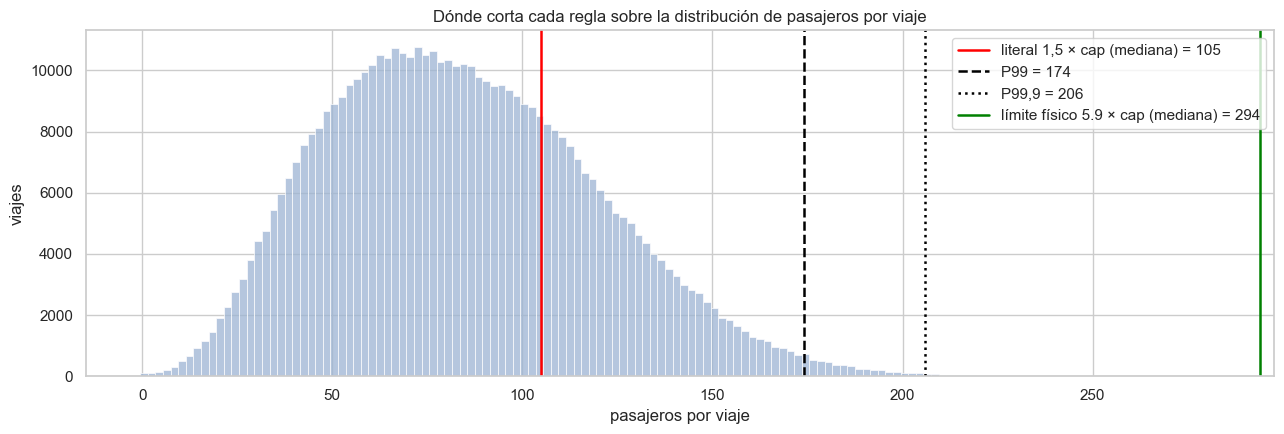

In [89]:
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.histplot(m.y, bins=np.arange(-0.5, m.y.max() + 2, 2), ax=ax, color="#9DB4D3", edgecolor=None)
lineas = [(1.5 * m.capacidad_calculada_max.median(), "red", "-", "literal 1,5 × cap (mediana)"),
          (m.y.quantile(.99), "black", "--", "P99"), (m.y.quantile(.999), "black", ":", "P99,9"),
          (regla.multiplicador * m.capacidad.median(), "green", "-", f"límite físico {regla.multiplicador:.1f} × cap (mediana)")]
for v, c, ls, t in lineas:
    ax.axvline(v, color=c, ls=ls, lw=1.8, label=f"{t} = {v:.0f}")
ax.set(title="Dónde corta cada regla sobre la distribución de pasajeros por viaje", xlabel="pasajeros por viaje", ylabel="viajes")
ax.legend(); plt.tight_layout(); plt.savefig(SALIDA / "umbrales_sobre_distribucion.png", dpi=130); plt.show()

**Conclusión 4 · Ninguna estrategia de truncamiento o filtrado mejora el error real; varias lo esconden**
- **A (truncar el entrenamiento en P99 o P99,9) no cambia nada:** MAE de 23,39–23,42 frente a 23,43. La distribución no tiene cola pesada (curtosis −0,13, 2.1), así que no hay valores extremos que estén distorsionando la pérdida.
- **A′ (truncar también el test) mejora la métrica de forma falsa:** el MAE en el top 1 % baja de 83,8 a 71,9 porque se reescriben las etiquetas reales, no porque se prediga mejor.
- **B literal (filtrar > 1,5 × capacidad) daña el modelo:** quita el **38 %** del entrenamiento, el modelo **infrapredice en 12,5 pasajeros por viaje**, el RMSE sube un 12 % (de 29,4 a 32,8) y la devianza un 25 %.
- **B literal′ es la trampa más peligrosa:** si además se filtra el test, el MAE "baja" a 15,7 (−33 %) porque se borra el **32,6 % del test 2025**, justo los viajes más cargados. La métrica parece excelente y el modelo es peor.
- **B física (> 5,88 × capacidad) no excluye ningún viaje observado:** da las mismas métricas que la referencia. Es una barrera para datos futuros, no un filtro que cambie el resultado actual.
- El sesgo de +5,5 del modelo de referencia se debe a la caída de la demanda entre 2023 y 2025 (se entrena con años de más demanda). No tiene que ver con los outliers.

## 5. Regla final aplicada al dataset de entrenamiento

In [90]:
final = f23.aplicar_regla_target(m.drop(columns=["y", "franja_15"]), regla)
display(f23.resumen_regla(final))
final.to_parquet("maestras/tb_maestra_entrenamiento.parquet", index=False)
print("Guardado: maestras/tb_maestra_entrenamiento.parquet  ·  usar  df[df.incluir_en_modelo]  para entrenar y evaluar")

,viajes,pct
viajes en la maestra,497371,100.000
outliers físicos (flag_outlier_target),123,0.025
target imputado (1.4),1069,0.215
incluidos en el modelo,496302,99.785


Guardado: maestras/tb_maestra_entrenamiento.parquet  ·  usar  df[df.incluir_en_modelo]  para entrenar y evaluar


**Conclusión 5 · Regla final**
- `flag_outlier_target` = subidas por encima de **5,88 × capacidad del bus**, o pico imposible de la 1.3. Marca **123 viajes (0,025 %)**: los picos de 97.199, 28.816, etc. Ya estaban imputados en la 1.4, así que están dentro de los 1.069 imputados.
- `incluir_en_modelo` = ni outlier ni target imputado: **496.302 viajes (99,785 %)**. Los 1.069 imputados quedan fuera del entrenamiento y de la evaluación porque no son observaciones reales.
- **Sin truncamiento:** el target conserva sus valores reales hasta 282.

## Conclusión de la Subfase 2.3 y recomendación para LightGBM
1. **No usar la regla `numeropasajeros > 1,5 × capacidad`:** compara las subidas de un viaje de 4 h con la capacidad *simultánea* del bus. Marcaría entre el 37 % y el 53 % de los viajes reales, y en la prueba infrapredice en 12,5 pasajeros por viaje y sube el RMSE un 12 %.
2. **No truncar (estrategia A):** no mejora el error real (MAE de 23,39 frente a 23,43), y si se trunca también el test la métrica mejora de forma falsa. La distribución no tiene cola pesada y los viajes extremos son demanda real con buena calidad de sensor.
3. **Aplicar la estrategia B con el límite físico coherente:**
   - **Excluir** de entrenamiento y evaluación los viajes con `flag_outlier_target` (> 5,88 × capacidad o pico imposible) y los **imputados**. Eso deja `incluir_en_modelo` = 496.302 viajes (99,8 %).
   - **Usar la misma regla en el test.** Excluir viajes es legítimo cuando el valor es físicamente imposible, no cuando es simplemente alto.
4. **Para no sesgar las métricas de LightGBM:**
   - Evaluar siempre sobre etiquetas **reales y sin modificar**, en un **corte temporal** (entrenar en el pasado y probar en el futuro).
   - Reportar también el error en el top 1 % de demanda.
   - La pérdida Tweedie ($p$ ≈ 1,3, 2.2) ya reduce el peso relativo de los viajes muy cargados, así que no hace falta truncar para protegerse de ellos.

Entregables:
- `maestras/tb_maestra_entrenamiento.parquet`, que añade `flag_outlier_target`, `limite_fisico_subidas` e `incluir_en_modelo`.
- `filtros_2_3.py` (regla reutilizable) y `auditoria_2_3.sql`.
- `resultados_2_3/comparacion_estrategias.csv` y los gráficos.

---
# Parte 8 · Subfase 2.4 · Métrica de evaluación
*Notebook original: `subfase_2_4_metrica.ipynb`*

In [91]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_2_4_metrica.ipynb")

── Inicio de subfase_2_4_metrica.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 2.4 — Métrica oficial: Devianza de Tweedie

**Entregable:** módulo `metricas_tweedie.py` (solo NumPy), listo para importar desde el walk-forward del Módulo 7. Este notebook documenta la definición, **prueba el módulo** (propiedades matemáticas, casos borde, wrappers) y lo aplica a datos reales.

## 1. Definición formal
Para una observación $y\ge 0$, una predicción $\hat y>0$ y una potencia $p\in(1,2)$, la **devianza unitaria de Tweedie** es

$$d_p(y,\hat y)=2\left(\frac{y^{2-p}}{(1-p)(2-p)}-\frac{y\,\hat y^{\,1-p}}{1-p}+\frac{\hat y^{\,2-p}}{2-p}\right)$$

y la métrica del proyecto es su promedio (opcionalmente ponderado): $\;D_p=\frac{1}{n}\sum_i d_p(y_i,\hat y_i)$, **menor es mejor**.

Casos límite que el módulo también implementa:
- $p\to1$ (Poisson): $\;d=2\,[\,y\ln(y/\hat y)-y+\hat y\,]$
- $p\to2$ (Gamma): $\;d=2\,[\ln(\hat y/y)+y/\hat y-1]$
- $p=0$ (normal): $\;d=(y-\hat y)^2$

**Propiedades que justifican usarla como métrica oficial:**
1. $d_p\ge 0$, y $d_p=0$ solo si $\hat y=y$.
2. Es la pérdida de la familia con $\mathrm{Var}(Y)=\phi\mu^p$. Penaliza cada error en proporción a la varianza esperada a ese nivel de demanda, que crece como $\mu^{1,3}$ (Subfase 2.2).
3. Es una divergencia de Bregman: la mejor predicción constante es la **media**, así que no premia predecir de menos ni de más.

**Manejo de ceros:**
- Si $y=0$, el primer término vale 0 (porque $2-p>0$) y queda $d=2\hat y^{2-p}/(2-p)$.
- Si $\hat y\to0$, $\hat y^{1-p}$ diverge; el módulo aplica $\hat y\leftarrow\max(\hat y,\varepsilon)$ con $\varepsilon=10^{-9}$.

**Valor oficial de $p$:** **1,3**, estimado en la 2.2 (rango robusto de 1,1 a 1,5). El 1,5 del enunciado es el valor por defecto de LightGBM, no el de estos datos. **$p$ debe quedar fijo en todas las comparaciones**: devianzas calculadas con distintos $p$ no son comparables entre sí.

In [92]:
import time
import numpy as np
import pandas as pd
import holidays
from IPython.display import display
import metricas_tweedie as mt
from metricas_tweedie import tweedie_deviance_score, tweedie_deviance_unit, P_OFICIAL
pd.set_option("display.width", 200)
print("p oficial:", P_OFICIAL, "| eps:", mt.EPS, "| funciones exportadas:", mt.__all__)

p oficial: 1.3 | eps: 1e-09 | funciones exportadas: ['P_OFICIAL', 'EPS', 'tweedie_deviance_unit', 'tweedie_deviance_score', 'lgb_feval', 'lgb_sklearn_eval', 'xgb_custom_metric', 'xgb_sklearn_eval', 'sklearn_scorer']


## 2. Pruebas del módulo (deben pasar todas)

In [93]:
rng = np.random.default_rng(0)
pruebas = []
def check(nombre, cond, detalle=""):
    pruebas.append({"prueba": nombre, "resultado": "PASS" if bool(cond) else "FAIL", "detalle": detalle})

# 1. Igual a la fórmula del enunciado (ejemplo a mano)
y_, mu_, p_ = 80.0, 70.0, 1.3
manual = 2 * (y_ ** (2 - p_) / ((1 - p_) * (2 - p_)) - y_ * mu_ ** (1 - p_) / (1 - p_) + mu_ ** (2 - p_) / (2 - p_))
check("Coincide con la fórmula escrita a mano", np.isclose(tweedie_deviance_unit([y_], [mu_], p_)[0], manual), f"d(80, 70) = {manual:.6f}")
# 2. Cero en predicción perfecta
y = np.array([1, 5, 50, 82, 282], float)
check("d(y, y) = 0", np.allclose(tweedie_deviance_unit(y, y), 0, atol=1e-9), f"máx {tweedie_deviance_unit(y, y).max():.1e}")
# 3. No negatividad
Y, MU = rng.integers(0, 300, 200_000).astype(float), rng.uniform(0.01, 300, 200_000)
check("d ≥ 0 en 200.000 pares aleatorios", (tweedie_deviance_unit(Y, MU) >= 0).all())
# 4. y = 0: valor cerrado
check("y = 0  →  d = 2ŷ^(2−p)/(2−p)", np.isclose(tweedie_deviance_unit([0.0], [40.0])[0], 2 * 40 ** (2 - P_OFICIAL) / (2 - P_OFICIAL)))
# 5. ŷ = 0: finito gracias a eps
v = tweedie_deviance_unit([10.0, 0.0], [0.0, 0.0])
check("ŷ = 0 no da inf ni NaN", np.isfinite(v).all(), f"d(10, 0) = {v[0]:.1f} · d(0, 0) = {v[1]:.1e}")
# 6. Límites continuos con Poisson y Gamma
Yp, MUp = rng.uniform(1, 200, 1000), rng.uniform(1, 200, 1000)
check("p → 1 converge a Poisson", np.allclose(tweedie_deviance_unit(Yp, MUp, 1 + 1e-6), tweedie_deviance_unit(Yp, MUp, 1), rtol=1e-4))
check("p → 2 converge a Gamma", np.allclose(tweedie_deviance_unit(Yp, MUp, 2 - 1e-6), tweedie_deviance_unit(Yp, MUp, 2), rtol=1e-4))
# 7. La mejor constante es la media (Bregman)
yy = rng.gamma(5, 17, 50_000)
grid = np.linspace(yy.mean() * .8, yy.mean() * 1.2, 2001)
c_opt = grid[np.argmin([tweedie_deviance_score(yy, np.full_like(yy, c)) for c in grid])]
check("argmin de la constante = media", abs(c_opt - yy.mean()) < (grid[1] - grid[0]) * 1.01, f"argmin {c_opt:.3f} · media {yy.mean():.3f}")
# 8. Ponderación
w = rng.uniform(0, 2, len(Y))
check("sample_weight = promedio ponderado", np.isclose(tweedie_deviance_score(Y, MU, sample_weight=w),
      np.average(tweedie_deviance_unit(Y, MU), weights=w)))
# 9. Validaciones de entrada
for nombre, args in [("y < 0", ([-1.0], [1.0])), ("NaN", ([np.nan], [1.0])), ("tamaños distintos", ([1.0, 2.0], [1.0])),
                     ("p fuera de dominio", ([1.0], [1.0], 2.5))]:
    try:
        tweedie_deviance_score(*args); check(f"Rechaza {nombre}", False)
    except ValueError as e:
        check(f"Rechaza {nombre}", True, str(e)[:60])
# 10. Velocidad
Yb, MUb = rng.integers(0, 300, 500_000).astype(float), rng.uniform(1, 300, 500_000)
t0 = time.perf_counter(); tweedie_deviance_score(Yb, MUb); dt = (time.perf_counter() - t0) * 1000
check("Vectorizada: 500.000 filas en < 200 ms", dt < 200, f"{dt:.0f} ms")

res = pd.DataFrame(pruebas); display(res)
assert (res.resultado == "PASS").all(), "Hay pruebas en FAIL"
print(f"{len(res)} de {len(res)} pruebas en PASS")

,prueba,resultado,detalle
0,Coincide con la fórmula escrita a mano,PASS,"d(80, 70) = 0.376502"
1,"d(y, y) = 0",PASS,máx 8.5e-14
2,d ≥ 0 en 200.000 pares aleatorios,PASS,
3,y = 0 → d = 2ŷ^(2−p)/(2−p),PASS,
4,ŷ = 0 no da inf ni NaN,PASS,"d(10, 0) = 33364.8 · d(0, 0) = 1.4e-06"
5,p → 1 converge a Poisson,PASS,
6,p → 2 converge a Gamma,PASS,
7,argmin de la constante = media,PASS,argmin 85.081 · media 85.081
8,sample_weight = promedio ponderado,PASS,
9,Rechaza y < 0,PASS,La devianza Tweedie con p ≥ 1 exige y_true ≥ 0


14 de 14 pruebas en PASS


**Conclusión 2 · El módulo es correcto y robusto: 14 de 14 pruebas en PASS**
- **Coincide con la fórmula del enunciado** (d(80, 70) = 0,3765) y vale 0 en predicción perfecta (error máximo de 8,5·10⁻¹⁴).
- **Nunca es negativa:** se comprobó en 200.000 pares aleatorios.
- **Converge sin saltos a Poisson (p → 1) y a Gamma (p → 2).**
- **La mejor predicción constante es exactamente la media** (85,081). La métrica no premia sesgos sistemáticos.
- **Ceros sin errores numéricos:** y = 0 da su valor cerrado y ŷ = 0 da un valor finito (gracias a ε), no infinito ni NaN.
- **Rechaza entradas inválidas** con un mensaje claro: y < 0, NaN, tamaños distintos o p fuera de dominio.
- **Procesa 500.000 filas en unos 106 ms.**

## 3. Wrappers para LightGBM, XGBoost y scikit-learn
`lightgbm` y `xgboost` no están instalados en este equipo, y Windows bloquea `sklearn`. Para probar los wrappers se simulan los objetos que esas librerías les entregan (`Dataset.get_label()` y `get_weight()`, `DMatrix.get_label()` y `get_weight()`), respetando exactamente sus firmas.

In [94]:
class DatasetSimulado:            # interfaz de lightgbm.Dataset usada por feval
    def __init__(self, y, w=None): self._y, self._w = np.asarray(y, float), w
    def get_label(self): return self._y
    def get_weight(self): return self._w

class DMatrixSimulada:             # interfaz de xgboost.DMatrix usada por custom_metric
    def __init__(self, y, w=None): self._y, self._w = np.asarray(y, float), np.asarray([] if w is None else w, float)
    def get_label(self): return self._y
    def get_weight(self): return self._w

y_v, mu_v = Y[:10_000], MU[:10_000]
ref = tweedie_deviance_score(y_v, mu_v)
salidas = {
    "lgb_feval (preds en escala de respuesta)": mt.lgb_feval()(mu_v, DatasetSimulado(y_v)),
    "lgb_feval (raw_score=True, preds en log)": mt.lgb_feval(raw_score=True)(np.log(mu_v), DatasetSimulado(y_v)),
    "lgb_sklearn_eval": mt.lgb_sklearn_eval()(y_v, mu_v),
    "xgb_custom_metric": mt.xgb_custom_metric()(mu_v, DMatrixSimulada(y_v)),
    "xgb_sklearn_eval": mt.xgb_sklearn_eval()(y_v, mu_v),
}
tabla = pd.DataFrame([{"wrapper": k, "salida": v, "valor": v[1] if isinstance(v, tuple) else v} for k, v in salidas.items()])
tabla["igual_a_score"] = np.isclose(tabla.valor, ref)
display(tabla)
assert tabla.igual_a_score.all()
print("Firmas: LightGBM → (nombre, valor, is_higher_better=False) · XGBoost nativo → (nombre, valor) · XGBRegressor → valor")

,wrapper,salida,valor,igual_a_score
0,lgb_feval (preds en escala de respuesta),"(tweedie_deviance@1.3, 45.964886164524074, False)",45.964886,True
1,"lgb_feval (raw_score=True, preds en log)","(tweedie_deviance@1.3, 45.964886164524074, False)",45.964886,True
2,lgb_sklearn_eval,"(tweedie_deviance@1.3, 45.964886164524074, False)",45.964886,True
3,xgb_custom_metric,"(tweedie_deviance@1.3, 45.964886164524074)",45.964886,True
4,xgb_sklearn_eval,45.964886,45.964886,True


Firmas: LightGBM → (nombre, valor, is_higher_better=False) · XGBoost nativo → (nombre, valor) · XGBRegressor → valor


**Conclusión 3 · Los 5 wrappers devuelven exactamente el mismo valor que `tweedie_deviance_score`**
- LightGBM nativo (`feval`) y sklearn (`eval_metric`) devuelven `(nombre, valor, False)`: menor es mejor.
- XGBoost nativo (`custom_metric`) devuelve `(nombre, valor)` y `XGBRegressor` un `float`. XGBoost minimiza por defecto.
- `raw_score=True` cubre el caso de un objetivo personalizado (predicciones en escala log). Con `objective='tweedie'` integrado no hace falta.
- `sklearn_scorer()` sirve para `GridSearchCV` (sklearn lo reporta con signo negativo). No pudo probarse aquí porque Windows bloquea `sklearn`.

## 4. Aplicación a datos reales: modelo de referencia, 2025
Mismo modelo de referencia de la 2.3 (media por ruta × franja de 15 min × tipo de día, entrenado con 2023–2024), evaluado sobre 2025 con la regla de la 2.3 (`incluir_en_modelo`). Se compara con un modelo ingenuo (media global de entrenamiento) para mostrar cuánto separa la métrica a un modelo útil de uno inútil, y se desglosa por tipo de día, como recomendó la 2.2.

In [95]:
d = pd.read_parquet("maestras/tb_maestra_entrenamiento.parquet")
d = d[d.incluir_en_modelo].copy()
festivos = holidays.Colombia(years=[2023, 2024, 2025])
fest = d.fecha.dt.date.map(lambda x: x in festivos)
d["tipo_dia"] = np.select([fest | (d.dia_semana == 6), d.dia_semana == 5], ["domingo_festivo", "sabado"], "laboral")
d["franja_15"] = d.fechasalida.dt.floor("15min").dt.strftime("%H:%M")
d["y"] = d.numeropasajeros.astype(float)
tr, te = d[d.fecha < "2025-01-01"], d[d.fecha >= "2025-01-01"].copy()
k1, k2 = ["idruta", "franja_15", "tipo_dia"], ["idruta", "hora", "tipo_dia"]
te = te.join(tr.groupby(k1).y.mean().rename("p1"), on=k1).join(tr.groupby(k2).y.mean().rename("p2"), on=k2)
te["pred_referencia"] = te.p1.fillna(te.p2).fillna(tr.y.mean())
te["pred_ingenuo"] = tr.y.mean()

filas = []
for nombre, col in [("ingenuo (media global)", "pred_ingenuo"), ("referencia (ruta × franja × día)", "pred_referencia")]:
    filas.append({"modelo": nombre, f"devianza_p{P_OFICIAL}": tweedie_deviance_score(te.y, te[col]),
                  "MAE": np.mean(np.abs(te.y - te[col])), "sesgo": np.mean(te[col] - te.y)})
display(pd.DataFrame(filas).round(3))

por_dia = te.groupby("tipo_dia").apply(lambda g: pd.Series({
    "viajes": len(g), "devianza_referencia": tweedie_deviance_score(g.y, g.pred_referencia),
    "devianza_ingenuo": tweedie_deviance_score(g.y, g.pred_ingenuo), "MAE_referencia": np.mean(np.abs(g.y - g.pred_referencia))}),
    include_groups=False).reindex(["laboral", "sabado", "domingo_festivo"])
display(por_dia.round(3))

sens = pd.DataFrame({p: {"ingenuo": tweedie_deviance_score(te.y, te.pred_ingenuo, p),
                         "referencia": tweedie_deviance_score(te.y, te.pred_referencia, p)} for p in [1.1, 1.2, 1.3, 1.4, 1.5]}).T
sens["mejora_%"] = 100 * (1 - sens.referencia / sens.ingenuo)
print("Sensibilidad a p: los valores absolutos cambian con p (no comparables), el ordenamiento de modelos no:")
display(sens.round(3))

,modelo,devianza_p1.3,MAE,sesgo
0,ingenuo (media global),4.244,28.846,5.663
1,referencia (ruta × franja × día),2.926,23.434,5.569


,viajes,devianza_referencia,devianza_ingenuo,MAE_referencia
tipo_dia,,,,
laboral,116160.0,3.020,4.090,24.653
sabado,22424.0,2.969,3.723,22.715
domingo_festivo,19923.0,2.326,5.733,17.133


Sensibilidad a p: los valores absolutos cambian con p (no comparables), el ordenamiento de modelos no:


,ingenuo,referencia,mejora_%
1.1,10.045,6.922,31.091
1.2,6.526,4.497,31.092
1.3,4.244,2.926,31.068
1.4,2.763,1.906,31.017
1.5,1.801,1.244,30.940


**Conclusión 4 · La métrica separa bien un modelo útil de uno inútil, y el resultado no depende de p**
- **2025 (158.507 viajes):** el modelo de referencia obtiene una **devianza de 2,926** frente a **4,244** del ingenuo (**−31 %**). El MAE pasa de 28,8 a 23,4.
- **Por tipo de día**, la mayor ganancia está en el **domingo-festivo** (2,33 frente a 5,73): el ingenuo, que usa la media global, sobrepredice los domingos. Laboral 3,02 y sábado 2,97.
- **Con p de 1,1 a 1,5 los valores absolutos cambian** (de 6,9 a 1,2 para la referencia), **pero la mejora relativa se mantiene en 31 %**. Hay que fijar p = 1,3 y no comparar devianzas calculadas con distintos p.
- El sesgo de +5,6 pasajeros (los dos modelos sobrepredicen 2025) muestra que la demanda cae entre 2023 y 2025. **Los modelos de los Módulos 6–8 necesitan variables de tendencia y calendario.**

## Conclusión de la Subfase 2.4
- **Métrica oficial del proyecto:** `tweedie_deviance_score(y_true, y_pred, p=1.3)` de `metricas_tweedie.py`. Solo depende de NumPy, está probada (14 de 14) y trae wrappers para LightGBM, XGBoost y scikit-learn.
- **Reglas de uso en el walk-forward (Módulo 7):**
  1. Fijar `p = P_OFICIAL = 1.3` para todos los modelos y folds.
  2. Evaluar solo sobre `incluir_en_modelo == True` (2.3), con etiquetas sin modificar.
  3. Reportar también por tipo de día y el MAE como métrica de negocio.
- **Resumen ejecutivo del Módulo 2:** `resumen_ejecutivo_modulo2.md`.

---
# Parte 9 · Módulos 3–5 · Temporal, espacial y multicolinealidad
*Notebook original: `entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/modulo_3_5_espaciotemporal.ipynb`*

In [96]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("modulo_3_5_espaciotemporal.ipynb")

── Inicio de modulo_3_5_espaciotemporal.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Módulos 3–5 — Dimensión temporal, dimensión espacial y multicolinealidad

**Persona 2 · Spatial-Temporal Data Scientist.** Parte de las tablas maestras cerradas en el Módulo 1 (`maestras/`, 22/22 checks en PASS) y no vuelve a la RDS.

| Módulo | Pregunta | Insumo |
|---|---|---|
| 3 · Temporal | ¿La demanda es estacionaria? ¿Qué memoria tienen t-1, t-4 y t-96? ¿Cuándo son los picos y cambian en festivos? | `tb_maestra_progvehiculos_limpia` → serie regular ruta × 15 min |
| 4 · Espacial | ¿Las subidas se agrupan en el espacio? ¿Con qué matriz de vecindad (k) medirlo? | `tb_maestra_conteo_destino_limpio_muestra` (lecturas GPS) → celdas de 250 m |
| 5 · Multicolinealidad | ¿Qué predictores son redundantes o filtran el objetivo? | maestra (nivel viaje) y panel ruta × 15 min |

**Variable de trabajo:** `pasajeros` = suma de `numeropasajeros` (ya imputado sin leakage en la 1.4) de los viajes válidos que **salen** en cada intervalo de 15 min, por ruta. Debe confirmarse con la caracterización del objetivo del Módulo 2 (Persona 1), que no está en la carpeta.

La lógica vive en `espaciotemporal_3_5.py`. Las salidas para la Persona 3 quedan en `datos_3_5/` (documentadas en `datos_3_5/LEEME_artefactos.md`). Este notebook no construye variables de entrenamiento: entrega calendario, diagnósticos, matriz de pesos y grafo.

# 0 · Configuración y carga

In [97]:
from pathlib import Path
import hashlib, platform, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import scipy, sklearn, statsmodels
from scipy import sparse
from IPython.display import display
pd.set_option("display.max_columns", None); pd.set_option("display.width", 220); pd.set_option("display.precision", 4)
import espaciotemporal_3_5 as et
from filtros_1_4 import CAJA          # caja Barranquilla–Soledad definida en la 1.4

MAESTRAS, D12, D13 = Path("maestras"), Path("datos_1_2"), Path("datos_1_3")
SALIDA = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5"); FIG = SALIDA / "figuras"   # [unificado] donde la Persona 3 lee estos artefactos; FIG.mkdir(parents=True, exist_ok=True)
cfg = et.Config()
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "font.size": 9, "axes.titlesize": 10, "font.family": "DejaVu Sans"})

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")
    plt.show()

def huella(p):   # para comprobar al final que no se modificaron los insumos de la Persona 1
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

INSUMOS = sorted(MAESTRAS.glob("*")) + [D12 / "viajes_validos.parquet", D13 / "sensores_viaje.csv"]
HUELLAS_INICIO = {str(p): huella(p) for p in INSUMOS}
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | statsmodels {statsmodels.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | networkx {nx.__version__} | matplotlib {matplotlib.__version__}")
print(cfg)

Python 3.10.0 | pandas 2.3.3 | numpy 2.2.6 | statsmodels 0.14.6 | scipy 1.15.3 | scikit-learn 1.7.2 | networkx 3.4.2 | matplotlib 3.10.3
Config(ventana_ini='2023-01-01', ventana_fin='2026-01-01', freq='15min', lags=(1, 4, 96), lag_semana=672, maxlag_adf_15min=100, alpha=0.05, umbral_dia_anomalo=0.25, celda_m=250.0, min_viajes_celda=30, ks=(2, 3, 4, 5, 6, 8, 10, 12, 15, 20), permutaciones=999, semilla=42, vif_umbrales=(5.0, 10.0), corr_umbral=0.8)


## 0.1 Insumos del Módulo 1 y columnas requeridas

In [98]:
val1 = pd.read_csv(MAESTRAS / "validacion_modulo1.csv")
assert (val1.resultado == "PASS").all(), "El Módulo 1 no está cerrado: revisar maestras/validacion_modulo1.csv"

maestra = pd.read_parquet(MAESTRAS / "tb_maestra_progvehiculos_limpia.parquet")
despachos = pd.read_parquet(MAESTRAS / "tb_despachos.parquet")
conteo = pd.read_parquet(MAESTRAS / "tb_maestra_conteo_destino_limpio_muestra.parquet")

REQ = {
    "maestra": (maestra, {"idprogramacion", "idruta", "fechasalida", "fecha", "hora", "tipo_dia", "numeropasajeros",
                          "pasajeros_imputado", "capacidad", "flag_sensor_ok", "numeropasajeros_raw"}),
    "despachos": (despachos, {"idprogramacion", "idruta", "fechasalida", "fechainicio"}),
    "conteo": (conteo, {"id", "idprogramacion", "idruta", "fecha", "latitud", "longitud", "cantidad_subida",
                        "cantidad_bajada", "a_bordo", "flag_fuera_area", "flag_carga_imposible"}),
}
for nombre, (df, cols) in REQ.items():
    faltan = cols - set(df.columns)
    assert not faltan, f"{nombre}: faltan {faltan}"
display(pd.DataFrame({n: {"filas": len(d), "columnas": d.shape[1], "requeridas": len(c)} for n, (d, c) in REQ.items()}).T)
print(f"Checks del Módulo 1 en PASS: {(val1.resultado == 'PASS').sum()} de {len(val1)}")

,filas,columnas,requeridas
maestra,497371,43,11
despachos,561427,16,4
conteo,971335,21,11


Checks del Módulo 1 en PASS: 22 de 22


## 0.2 Viajes aptos para el análisis espacial
La muestra de lecturas de la 1.3 **no es aleatoria pura**: además de 500 viajes al azar por ruta, añadió a propósito hasta 300 viajes con cero pasajeros y los 200 de más bloqueos. Se reconstruyen esos dos grupos con la misma regla determinista de la 1.3 y se excluyen, junto con los viajes con sensor no confiable, imputados o con carga imposible.

In [99]:
v12 = pd.read_parquet(D12 / "viajes_validos.parquet", columns=["idprogramacion", "idruta"])
sv13 = pd.read_csv(D13 / "sensores_viaje.csv", usecols=["idprogramacion", "numeropasajeros", "numerobloqueos"])
base13 = v12.merge(sv13, on="idprogramacion")
TOP_BLOQUEOS = set(base13.nlargest(200, "numerobloqueos").idprogramacion)               # regla exacta de la 1.3
CEROS = set(base13[base13.numeropasajeros.fillna(0) == 0].idprogramacion)               # universo del que la 1.3 muestreó 300
aptos = et.viajes_aptos_espacial(conteo, maestra, TOP_BLOQUEOS, CEROS)
display(aptos.motivo.value_counts().to_frame("viajes"))
display(pd.crosstab(aptos.idruta, aptos.motivo == "apto", margins=True).rename(columns={True: "apto", False: "excluido"}))
IDS_APTOS = set(aptos.index[aptos.motivo == "apto"])

,viajes
motivo,
apto,1335
muestra dirigida: top-200 bloqueos (1.3),192
flag_sensor_ok = False,99
muestra dirigida: cero pasajeros (1.3),42
carga a bordo imposible,5


motivo,excluido,apto,All
idruta,,,
2,74,456,530
16,161,437,598
21,103,442,545
All,338,1335,1673


# Módulo 3 · Dimensión temporal

## 3.1 Auditoría de la marca temporal
Se revisa `fechasalida` (salida programada): zona horaria, resolución, duplicados, huecos y regularidad. La serie **por viaje** no es equiespaciada (los buses salen cada pocos minutos con intervalos variables), así que ACF/PACF no pueden aplicarse sobre ella directamente.

In [100]:
aud_t = et.auditar_tiempo(maestra, cfg)
display(aud_t)
intervalos = et.intervalos_salida(maestra)
display(intervalos)
dias_anio = maestra.groupby(maestra.fechasalida.dt.year).fecha.nunique()
viajes_dia_anio = maestra.groupby([maestra.fechasalida.dt.year.rename("anio"), "idruta"]).size().unstack().div(dias_anio, axis=0)
print("Viajes válidos por día (media anual): permite ver cambios de frecuencia de despacho")
display(viajes_dia_anio.round(1))

,check,resultado,detalle
0,fechasalida sin nulos,PASS,0 nulos
1,"fechasalida naive (hora local, sin zona)",PASS,datetime64[ns]
2,America/Bogota sin cambio de horario en la ven...,PASS,offset único: UTC-5 h
3,Resolución de minuto (segundos = 0),PASS,0 con segundos
4,Ventana 2023-01 a 2025-12,PASS,2023-01-01 05:00:00 → 2025-12-31 18:30:00
5,idprogramacion único,PASS,
6,Salidas simultáneas en la misma ruta y minuto,INFO,"855 (0.17 %): buses distintos, se suman en el ..."
7,Ninguna ruta tiene días completos sin viajes,PASS,"{np.int64(2): 0, np.int64(16): 0, np.int64(21)..."


,viajes,p05,p50,p95,max_dentro_del_dia,pct_intervalo_0,cv_dentro_del_dia
idruta,,,,,,,
2,138633,2.0,6.0,16.0,178.0,0.14,0.64
16,271142,2.0,3.0,8.0,176.0,0.21,0.63
21,87596,3.0,10.0,24.0,174.0,0.12,0.62


Viajes válidos por día (media anual): permite ver cambios de frecuencia de despacho


idruta,2,16,21
anio,,,
2023,132.2,264.3,82.0
2024,124.1,243.3,80.8
2025,123.2,234.6,76.9


**Conclusión 3.1 · Las marcas de tiempo son limpias, pero la serie por viaje no es regular**
- `fechasalida` está en hora local sin zona, con resolución de minuto, y cubre 2023-01-01 → 2025-12-31. **America/Bogota no tuvo cambio de horario** en la ventana (UTC−5 fijo), así que no hay horas duplicadas ni saltadas.
- **Ninguna ruta tiene un día completo sin viajes**: no hay huecos de calendario que rellenar.
- Hay 855 salidas simultáneas (misma ruta y minuto, 0,17 %). Son buses distintos y se suman en el intervalo.
- **Los intervalos entre salidas son irregulares**. La mediana es de 6 min (ruta 2), 3 min (16) y 10 min (21), con un coeficiente de variación de ≈ 0,6. Por eso se regulariza a 15 min antes de cualquier ACF.
- La oferta baja de forma sostenida. La ruta 16 pasa de 264 viajes válidos/día en 2023 a 235 en 2025 (−11 %) y la ruta 2 de 132 a 123. Es un cambio lento de nivel, no de frecuencia de muestreo.

## 3.2 Calendario: laborales, fines de semana, festivos y Carnaval
- **Festivos nacionales** de Colombia (Ley 51 de 1983): 6 fijos, 7 trasladados al lunes siguiente y 5 ligados a la Pascua (18 por año). Ámbito nacional, aplica a Barranquilla. Se verificó fuera del notebook contra el paquete `holidays` (coincidencia exacta 2023–2025).
- **Carnaval de Barranquilla** (sábado a martes antes del Miércoles de Ceniza): evento local, **no** es festivo nacional; va en una categoría propia para no contaminar ni a los laborales ni a los festivos.
- `tipo_dia_cal` aplica la prioridad festivo > carnaval > domingo > sábado > laboral. No reemplaza el `tipo_dia` de la 1.4 (sin festivos), lo complementa.
- `dia_anomalo`: día no festivo ni de carnaval con menos del 25 % de los viajes válidos medianos de su tipo. Se excluye de las comparaciones, no de la serie.

In [101]:
cal = et.calendario(cfg, maestra.groupby("fecha").size())
fest = et.festivos_colombia(sorted(cal.fecha.dt.year.unique()))
assert fest.groupby(fest.fecha.dt.year).size().eq(18).all(), "Deben ser 18 festivos nominales por año"
resumen_cal = cal.groupby(cal.fecha.dt.year.rename("anio")).agg(
    dias=("fecha", "size"), festivos=("es_festivo", "sum"), carnaval=("es_carnaval", "sum"), anomalos=("dia_anomalo", "sum"))
resumen_cal["festivos_en_domingo"] = cal[cal.es_festivo & (cal.dia_semana == 6)].groupby(cal.fecha.dt.year).size().reindex(resumen_cal.index, fill_value=0)
display(resumen_cal)
display(pd.crosstab(cal.tipo_dia_cal, cal.fecha.dt.year, margins=True))
print("Festivos por día de la semana (0 = lunes):", cal[cal.es_festivo].dia_semana.value_counts().sort_index().to_dict())
print("Días que la 1.4 clasificaba como 'laboral' y en realidad son festivos o Carnaval:",
      int(((cal.tipo_dia_m1 == "laboral") & cal.tipo_dia_cal.isin(["festivo", "carnaval"])).sum()))
display(cal[cal.dia_anomalo][["fecha", "dia_semana", "tipo_dia_cal", "viajes_validos_dia"]])

,dias,festivos,carnaval,anomalos,festivos_en_domingo
anio,,,,,
2023,365,18,4,0,1
2024,366,18,4,1,1
2025,365,17,4,0,1


fecha,2023,2024,2025,All
tipo_dia_cal,,,,
carnaval,4,4,4,12
domingo,51,50,50,151
festivo,18,18,17,53
laboral,241,244,243,728
sabado,51,50,51,152
All,365,366,365,1096


Festivos por día de la semana (0 = lunes): {0: 34, 2: 4, 3: 7, 4: 4, 5: 1, 6: 3}
Días que la 1.4 clasificaba como 'laboral' y en realidad son festivos o Carnaval: 55


,fecha,dia_semana,tipo_dia_cal,viajes_validos_dia
614,2024-09-06,4,laboral,50


**Conclusión 3.2 · El 5 % de los días no era lo que decía `tipo_dia`**
- 53 fechas festivas en 3 años: 18 por año, pero en 2025 San Pedro y el Sagrado Corazón caen ambos el 30 de junio. **34 de los 53 son lunes**, por la Ley Emiliani.
- **55 días que la 1.4 trataba como laborales son festivos o Carnaval.** Contaminaban el grupo laboral, y también la imputación de la 1.4 por "ruta × hora × tipo de día". Esto se le avisa a la Persona 1.
- **El Carnaval** (12 días) se separa porque su demanda se parece a la de un domingo (3.7) sin ser festivo nacional.
- **Un solo día anómalo: el viernes 6 de septiembre de 2024**, con 50 viajes válidos frente a ~480 de un laboral típico. Las tres rutas caen a la vez, lo que apunta a un evento o una falla de registro. Los datos no permiten saber cuál. Queda en la serie, pero fuera de las comparaciones.

## 3.3 Serie regular ruta × 15 min
Se agregan los viajes por el intervalo de 15 min de su salida. Con esa frecuencia, **t-1 = 15 min, t-4 = 1 h y t-96 = 24 h** (96 × 15 min). Un intervalo sin salidas vale 0: no hubo servicio y no hay abordajes atribuidos. Esto es un cero real de la variable, no un hueco, porque ninguna ruta tiene días sin datos (3.1). **No se interpola nada.**

Cautela de interpretación: `numeropasajeros` acumula las subidas de todo el viaje (~4 h) y se atribuye a la hora de **salida**. Es demanda por despacho, no subidas instantáneas.

In [102]:
serie = et.serie_regular(maestra, cfg)
n_int = len(pd.date_range(cfg.ventana_ini, cfg.ventana_fin, freq=cfg.freq, inclusive="left"))
chk_serie = pd.DataFrame({
    "intervalos": serie.groupby("idruta").size(),
    "esperados": n_int,
    "pasajeros_serie": serie.groupby("idruta").pasajeros.sum(),
    "pasajeros_maestra": maestra.groupby("idruta").numeropasajeros.sum().astype("int64"),
    "viajes_serie": serie.groupby("idruta").viajes.sum(),
    "viajes_maestra": maestra.groupby("idruta").size(),
    "pct_ceros": serie.groupby("idruta").pasajeros.apply(lambda s: 100 * (s == 0).mean()),
    "pct_ceros_4a20h": serie[serie.hora.between(4, 20)].groupby("idruta").pasajeros.apply(lambda s: 100 * (s == 0).mean()),
    "pct_ceros_21a3h": serie[~serie.hora.between(4, 20)].groupby("idruta").pasajeros.apply(lambda s: 100 * (s == 0).mean()),
})
assert (chk_serie.intervalos == chk_serie.esperados).all() and (chk_serie.pasajeros_serie == chk_serie.pasajeros_maestra).all() \
    and (chk_serie.viajes_serie == chk_serie.viajes_maestra).all(), "La serie no conserva intervalos, pasajeros o viajes"
display(chk_serie.round(2))
display(serie.groupby("idruta").pasajeros.describe(percentiles=[.25, .5, .75, .95, .99]).round(1))

,intervalos,esperados,pasajeros_serie,pasajeros_maestra,viajes_serie,viajes_maestra,pct_ceros,pct_ceros_4a20h,pct_ceros_21a3h
idruta,,,,,,,,,
2,105216,105216,11272302,11272302,138633,138633,36.75,10.71,100.0
16,105216,105216,23303942,23303942,271142,271142,33.90,6.68,100.0
21,105216,105216,7418827,7418827,87596,87596,42.33,18.59,100.0


,count,mean,std,min,25%,50%,75%,95%,99%,max
idruta,,,,,,,,,,
2,105216.0,107.1,117.5,0.0,0.0,85.0,175.0,318.0,508.0,1080.0
16,105216.0,221.5,215.7,0.0,0.0,188.0,377.0,605.0,818.0,1275.0
21,105216.0,70.5,79.3,0.0,0.0,55.0,119.0,224.0,307.0,594.0


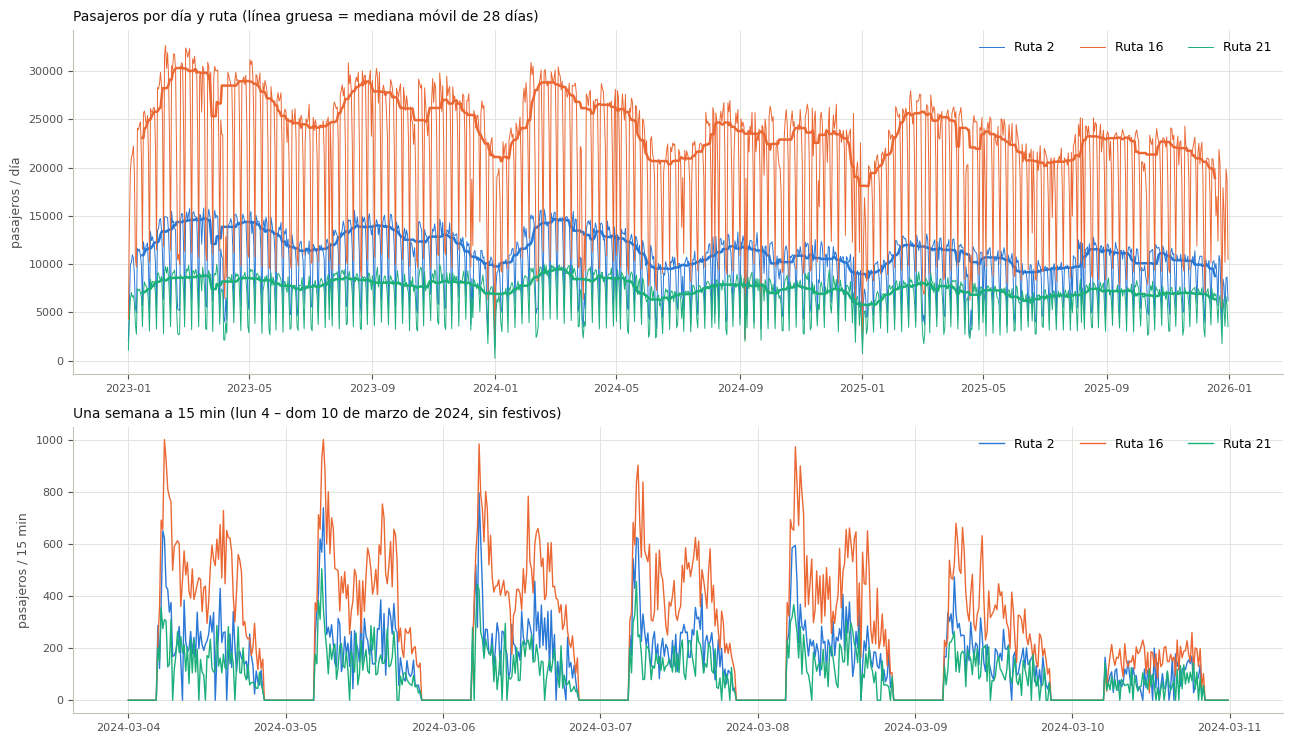

In [103]:
diario = (serie.groupby(["idruta", "fecha"], as_index=False)[["pasajeros", "viajes"]].sum()
          .merge(cal[["fecha", "dia_semana", "tipo_dia_cal", "es_festivo", "es_carnaval", "dia_anomalo"]], on="fecha"))
fig, ax = plt.subplots(2, 1, figsize=(13, 7.5), gridspec_kw={"height_ratios": [1.2, 1]})
for r, g in diario.groupby("idruta"):
    ax[0].plot(g.fecha, g.pasajeros, lw=0.7, color=et.COLOR_RUTA[r], label=f"Ruta {r}")
    ax[0].plot(g.fecha, g.pasajeros.rolling(28, center=True).median(), lw=1.8, color=et.COLOR_RUTA[r])
et.estilo_ejes(ax[0], "Pasajeros por día y ruta (línea gruesa = mediana móvil de 28 días)", None, "pasajeros / día")
ax[0].legend(frameon=False, ncol=3, loc="upper right")
semana = serie[(serie.t >= "2024-03-04") & (serie.t < "2024-03-11")]
for r, g in semana.groupby("idruta"):
    ax[1].plot(g.t, g.pasajeros, lw=1.0, color=et.COLOR_RUTA[r], label=f"Ruta {r}")
et.estilo_ejes(ax[1], "Una semana a 15 min (lun 4 – dom 10 de marzo de 2024, sin festivos)", None, "pasajeros / 15 min")
ax[1].legend(frameon=False, ncol=3, loc="upper right")
plt.tight_layout(); guardar(fig, "m3_serie_diaria_y_semana")

**Conclusión 3.3 · Serie regular completa: 3 × 105.216 intervalos sin pérdidas**
- La serie conserva exactamente los 41.995.071 pasajeros y los 497.371 viajes de la maestra.
- **Entre el 34 % y el 42 % de los intervalos valen 0.** Las 21:00–03:59 son 0 en el 100 % de los casos (no hay servicio: cero estructural). Dentro del servicio (4–20 h) los ceros son el 6,7 % (ruta 16), el 10,7 % (ruta 2) y el 18,6 % (ruta 21). Esa mezcla de ceros y valores positivos sesgados es la que motiva la comparación Poisson/Tweedie del Módulo 2.
- **La forma diaria es muy estable**: doble joroba en días laborales y meseta los domingos (figura). A escala diaria se ve la **deriva descendente** de 3.1 y caídas puntuales en festivos, Carnaval y fin de año.

## 3.4 Prueba ADF (y KPSS como contraste complementario)
ADF contrasta **H0: la serie tiene raíz unitaria** (no estacionaria en media) frente a H1: estacionaria alrededor de la parte determinística. Se usa α = 5 %.
- **15 min, `c` (constante):** la serie oscila en un ciclo diario estable sin deriva visible a esa escala; los rezagos aumentados se eligen por AIC hasta 100 para cubrir el ciclo de 96. La versión `ct` reusa ese mismo número de rezagos.
- **Diaria, `c` y `ct`:** a escala diaria sí se ve una deriva lenta (3.3); por eso se reporta también con tendencia lineal.
- **KPSS** invierte las hipótesis (H0: estacionaria). Si ADF rechaza y KPSS no, la evidencia es coherente; si ambos rechazan, hay persistencia o cambios de nivel que ningún test resume solo.

In [104]:
filas = []
for r, g in serie.groupby("idruta"):
    x = g.sort_values("t").pasajeros.to_numpy(float)
    a = et.adf_resumen(x, "c", cfg.maxlag_adf_15min, "AIC", cfg.alpha)
    filas.append({"idruta": r, "serie": "15 min", "n": len(x), "regresion": "c", "seleccion_rezagos": f"AIC, máx {cfg.maxlag_adf_15min}", **a,
                  **et.kpss_resumen(x, "c", cfg.alpha)})
    rob = et.adf_resumen(x, "c", 2 * 96, None, cfg.alpha)        # robustez: AIC tocó el máximo permitido
    filas.append({"idruta": r, "serie": "15 min", "n": len(x), "regresion": "c", "seleccion_rezagos": "fijo = 192 (2 días, robustez)", **rob,
                  **et.kpss_resumen(x, "c", cfg.alpha)})
    b = et.adf_resumen(x, "ct", a["rezagos_usados"], None, cfg.alpha)
    filas.append({"idruta": r, "serie": "15 min", "n": len(x), "regresion": "ct", "seleccion_rezagos": f"fijo = {a['rezagos_usados']}", **b,
                  **et.kpss_resumen(x, "ct", cfg.alpha)})
for r, g in diario.groupby("idruta"):
    x = g.sort_values("fecha").pasajeros.to_numpy(float)
    for reg in ["c", "ct"]:
        filas.append({"idruta": r, "serie": "diaria", "n": len(x), "regresion": reg, "seleccion_rezagos": "AIC, máx por defecto",
                      **et.adf_resumen(x, reg, None, "AIC", cfg.alpha), **et.kpss_resumen(x, reg, cfg.alpha)})
adf = pd.DataFrame(filas)
display(adf[["idruta", "serie", "regresion", "n", "seleccion_rezagos", "rezagos_usados", "nobs_usadas", "estadistico", "p_valor",
             "vc_1%", "vc_5%", "vc_10%", "conclusion", "kpss_estadistico", "kpss_p_valor", "kpss_p_acotado", "kpss_conclusion"]].round(4))

,idruta,serie,regresion,n,seleccion_rezagos,rezagos_usados,nobs_usadas,estadistico,p_valor,vc_1%,vc_5%,vc_10%,conclusion,kpss_estadistico,kpss_p_valor,kpss_p_acotado,kpss_conclusion
0,2,15 min,c,105216,"AIC, máx 100",100,105115,-14.1989,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,6.4565,0.0100,True,rechaza H0 (estacionariedad) al 5%
1,2,15 min,c,105216,"fijo = 192 (2 días, robustez)",192,105023,-16.0412,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,6.4565,0.0100,True,rechaza H0 (estacionariedad) al 5%
2,2,15 min,ct,105216,fijo = 100,100,105115,-14.9433,0.0000,-3.9589,-3.4105,-3.1271,rechaza H0 (raíz unitaria) al 5%,0.1313,0.0773,False,no rechaza H0 al 5%
3,16,15 min,c,105216,"AIC, máx 100",100,105115,-17.1282,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,5.0319,0.0100,True,rechaza H0 (estacionariedad) al 5%
4,16,15 min,c,105216,"fijo = 192 (2 días, robustez)",192,105023,-17.4561,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,5.0319,0.0100,True,rechaza H0 (estacionariedad) al 5%
5,16,15 min,ct,105216,fijo = 100,100,105115,-17.8044,0.0000,-3.9589,-3.4105,-3.1271,rechaza H0 (raíz unitaria) al 5%,0.0513,0.1000,True,no rechaza H0 al 5%
6,21,15 min,c,105216,"AIC, máx 100",100,105115,-14.1394,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,3.3467,0.0100,True,rechaza H0 (estacionariedad) al 5%
7,21,15 min,c,105216,"fijo = 192 (2 días, robustez)",192,105023,-16.5835,0.0000,-3.4304,-2.8616,-2.5668,rechaza H0 (raíz unitaria) al 5%,3.3467,0.0100,True,rechaza H0 (estacionariedad) al 5%
8,21,15 min,ct,105216,fijo = 100,100,105115,-14.5137,0.0000,-3.9589,-3.4105,-3.1271,rechaza H0 (raíz unitaria) al 5%,0.1157,0.1000,True,no rechaza H0 al 5%
9,2,diaria,c,1096,"AIC, máx por defecto",21,1074,-3.0267,0.0325,-3.4365,-2.8642,-2.5682,rechaza H0 (raíz unitaria) al 5%,5.9573,0.0100,True,rechaza H0 (estacionariedad) al 5%


**Conclusión 3.4 · Sin evidencia de raíz unitaria, con tendencia determinística lenta**
- **ADF rechaza H0 en las 15 pruebas.** A 15 min el estadístico va de −14,1 a −17,8, frente a un valor crítico de −2,86 (`c`) o −3,41 (`ct`) al 5 %. En la serie diaria va de −3,03 a −5,38 (p ≤ 0,033).
- **AIC eligió 100 rezagos, el máximo permitido**, lo que indica que la dinámica es larga. Con 192 rezagos fijos (2 días) el estadístico sigue entre −16,0 y −17,5: la conclusión no depende de esa frontera.
- **KPSS matiza el resultado.** Con solo constante (`c`) rechaza la estacionariedad en todas las series (p ≤ 0,01, cota inferior de statsmodels). Con tendencia (`ct`) no la rechaza (p ≥ 0,077). La lectura conjunta es **estacionaria alrededor de una tendencia lineal suave** más un ciclo diario y semanal determinístico. No hace falta diferenciar para eliminar una raíz unitaria, pero sí modelar la tendencia y la estacionalidad.
- **Límites:** ADF no prueba estacionariedad en varianza ni ausencia de cambios estructurales. Con n ≈ 105 mil, rechazar es casi seguro ante cualquier reversión a la media; por eso se informa también la versión diaria. La serie diaria tiene una sola realización de 3 años.

## 3.5 ACF y PACF en t-1, t-4 y t-96
La frecuencia real es exactamente 15 min (3.3), así que los rezagos pedidos tienen el significado previsto. Se añade t-672 (una semana) solo como referencia. Bandas al 95 %: Bartlett para la ACF y ±1,96/√n para la PACF. Con n ≈ 105 mil, cualquier |r| > 0,006 sale "significativo": se interpreta la **magnitud**, no solo la significancia.

La versión **desestacionalizada** resta el perfil medio ruta × día de semana × intervalo (diagnóstico exploratorio que usa toda la muestra; no es una variable para entrenar) y muestra cuánta dependencia queda fuera del ciclo determinístico.

In [105]:
LAGS = list(cfg.lags) + [cfg.lag_semana]
serie["pasajeros_desest"] = et.desestacionalizar(serie)
tablas, curvas = [], {}
for r, g in serie.groupby("idruta"):
    g = g.sort_values("t")
    for nombre, col in [("original", "pasajeros"), ("desestacionalizada", "pasajeros_desest")]:
        t, a, p = et.acf_pacf_tabla(g[col].to_numpy(float), LAGS, nlags_acf=700, nlags_pacf=100)
        tablas.append(t.assign(idruta=r, serie=nombre))
        curvas[(r, nombre)] = (a, p, et.bandas_bartlett(a, len(g)), 1.959964 / np.sqrt(len(g)))
acf_tab = pd.concat(tablas, ignore_index=True)[["idruta", "serie", "rezago", "intervalo_real", "acf", "banda_bartlett_95",
                                                "acf_significativa", "pacf", "banda_ruido_blanco_95", "pacf_significativa"]]
display(acf_tab.round(4))

,idruta,serie,rezago,intervalo_real,acf,banda_bartlett_95,acf_significativa,pacf,banda_ruido_blanco_95,pacf_significativa
0,2,original,t-1,15 min,0.7334,0.0060,True,0.7334,0.006,True
1,2,original,t-4,1 h,0.5696,0.0119,True,0.0164,0.006,True
2,2,original,t-96,1 día(s),0.6951,0.0222,True,0.1446,0.006,True
3,2,original,t-672,7 día(s),0.7543,0.0549,True,NaN,0.006,NaN
4,2,desestacionalizada,t-1,15 min,0.2540,0.0060,True,0.2540,0.006,True
5,2,desestacionalizada,t-4,1 h,0.2248,0.0072,True,0.1045,0.006,True
6,2,desestacionalizada,t-96,1 día(s),0.1870,0.0113,True,0.0768,0.006,True
7,2,desestacionalizada,t-672,7 día(s),0.1243,0.0154,True,NaN,0.006,NaN
8,16,original,t-1,15 min,0.8731,0.0060,True,0.8731,0.006,True
9,16,original,t-4,1 h,0.7498,0.0138,True,0.0090,0.006,True


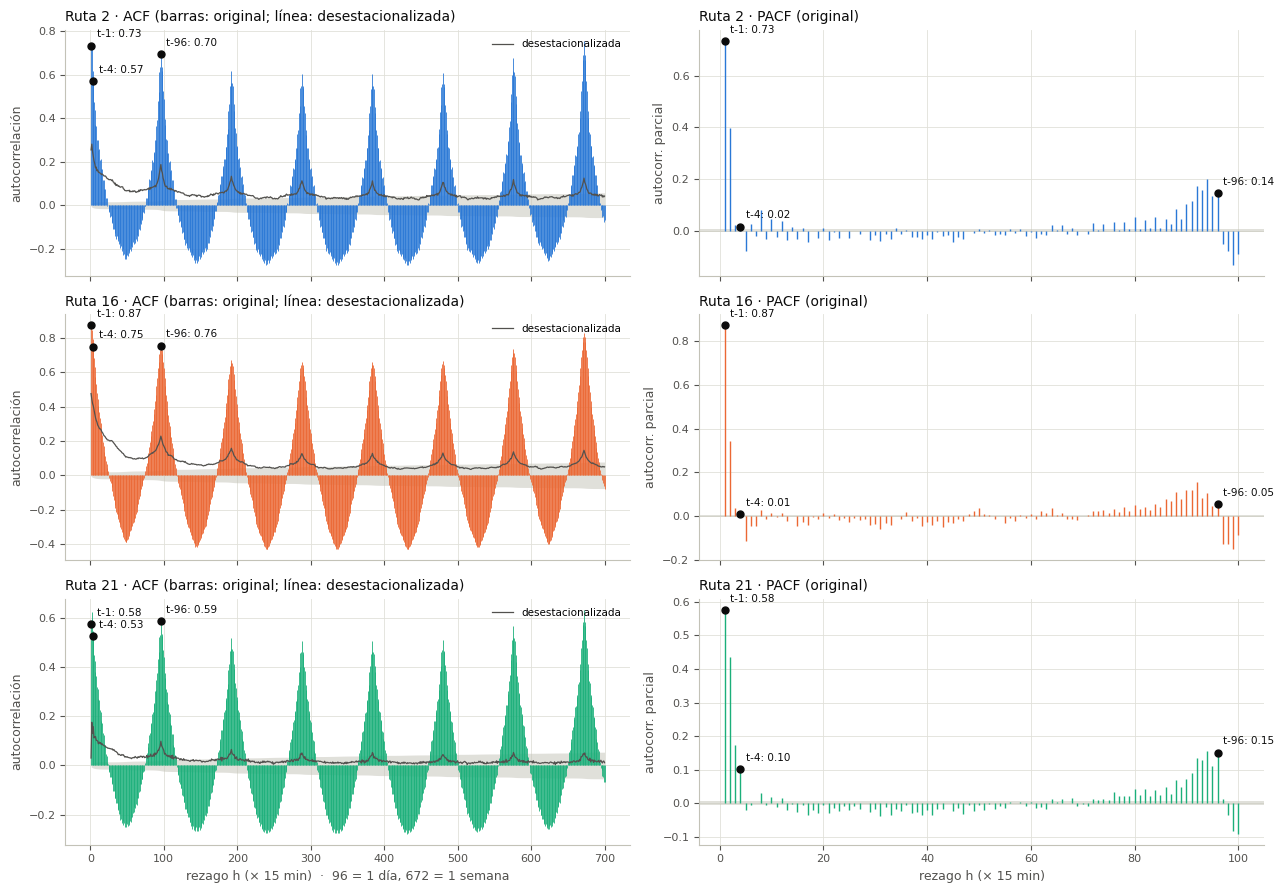

In [106]:
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex="col")
for i, r in enumerate(sorted(serie.idruta.unique())):
    a, p, bart, blanco = curvas[(r, "original")]
    h = np.arange(len(a))
    ax[i, 0].vlines(h[1:], 0, a[1:], color=et.COLOR_RUTA[r], lw=0.6)
    ax[i, 0].fill_between(h[1:], -bart[1:], bart[1:], color="#c3c2b7", alpha=0.5, lw=0)
    ad, *_ = curvas[(r, "desestacionalizada")]
    ax[i, 0].plot(h[1:], ad[1:], color=et.INK2, lw=0.9, label="desestacionalizada")
    hp = np.arange(len(p))
    ax[i, 1].vlines(hp[1:], 0, p[1:], color=et.COLOR_RUTA[r], lw=1.0)
    ax[i, 1].axhspan(-blanco, blanco, color="#c3c2b7", alpha=0.5, lw=0)
    for L in cfg.lags:
        for j, (arr, hh) in enumerate([(a, h), (p, hp)]):
            if L < len(arr):
                ax[i, j].plot(L, arr[L], "o", ms=5, color=et.INK, zorder=3)
                ax[i, j].annotate(f"t-{L}: {arr[L]:.2f}", (L, arr[L]), xytext=(4, 6), textcoords="offset points", fontsize=7.5, color=et.INK)
    et.estilo_ejes(ax[i, 0], f"Ruta {r} · ACF (barras: original; línea: desestacionalizada)", None, "autocorrelación")
    et.estilo_ejes(ax[i, 1], f"Ruta {r} · PACF (original)", None, "autocorr. parcial")
    ax[i, 0].legend(frameon=False, loc="upper right", fontsize=7.5)
ax[2, 0].set_xlabel("rezago h (× 15 min)  ·  96 = 1 día, 672 = 1 semana", fontsize=9, color=et.INK2)
ax[2, 1].set_xlabel("rezago h (× 15 min)", fontsize=9, color=et.INK2)
plt.tight_layout(); guardar(fig, "m3_acf_pacf")

**Conclusión 3.5 · t-1 y t-96 dominan; t-4 casi no aporta información propia**

| Ruta | ACF t-1 (15 min) | ACF t-4 (1 h) | ACF t-96 (24 h) | PACF t-1 | PACF t-4 | PACF t-96 |
|---|---|---|---|---|---|---|
| 2 | 0,73 | 0,57 | 0,70 | 0,73 | 0,02 | 0,14 |
| 16 | 0,87 | 0,75 | 0,76 | 0,87 | 0,01 | 0,05 |
| 21 | 0,58 | 0,53 | 0,59 | 0,58 | 0,10 | 0,15 |

- **ACF:** la dependencia es fuerte a corto plazo y casi igual de fuerte a 24 h, con picos en cada múltiplo de 96 y el máximo en t-672 (0,63–0,83). El ciclo semanal es aún más fuerte que el diario. Las correlaciones negativas a ~12 h son el reflejo del ciclo día/noche, no un efecto de demanda.
- **PACF:** casi todo lo de t-4 ya lo explican t-1 a t-3 (PACF de 0,01–0,10). **t-96 conserva información propia** (0,05–0,15) junto a un bloque de rezagos en 90–100: hay memoria estacional diaria.
- **Al desestacionalizar**, la ACF cae a 0,03–0,48 en t-1 y a 0,10–0,23 en t-96. La mayor parte de la autocorrelación cruda es **ciclo determinístico**. Lo que queda (sobre todo en la ruta 16) es la persistencia de choques de demanda.
- Todo es "significativo" por el tamaño muestral (bandas de ±0,006 a ±0,075). Lo informativo es la magnitud.

## 3.6 Perfiles horarios, picos y valles
Unidad: pasajeros por **ruta × fecha × hora de salida** (suma de los cuatro intervalos de la hora). Para cada tipo de día se resumen media, mediana, cuartiles y coeficiente de variación entre días. Hora pico = mayor mediana; valle = menor mediana entre las 6 y las 19 h (los bordes 4–5 h y 20 h son arranque y cierre de servicio). Se excluyen los días anómalos.

,idruta,tipo_dia_cal,dias,hora_pico,mediana_pico,pico_manana,pico_tarde,mediana_pico_tarde,hora_valle,mediana_valle,razon_pico_valle,hora_max_pasajeros_por_viaje
0,2,carnaval,12,15,507.0,5,15,507.0,19,255.0,1.99,17
1,2,domingo,151,16,426.0,8,16,426.0,19,284.0,1.50,17
2,2,festivo,53,16,416.0,5,16,416.0,19,235.0,1.77,16
3,2,laboral,727,5,1857.0,5,14,868.0,19,295.0,6.29,4
4,2,sabado,152,5,1072.5,5,13,570.0,19,312.5,3.43,6
5,16,carnaval,12,16,838.5,6,16,838.5,19,354.0,2.37,17
6,16,domingo,151,16,770.0,8,16,770.0,19,557.0,1.38,4
7,16,festivo,53,16,771.0,5,16,771.0,19,432.0,1.78,4
8,16,laboral,727,5,2688.0,5,14,1913.0,19,676.0,3.98,14
9,16,sabado,152,6,2078.0,6,12,1397.5,19,593.0,3.50,9


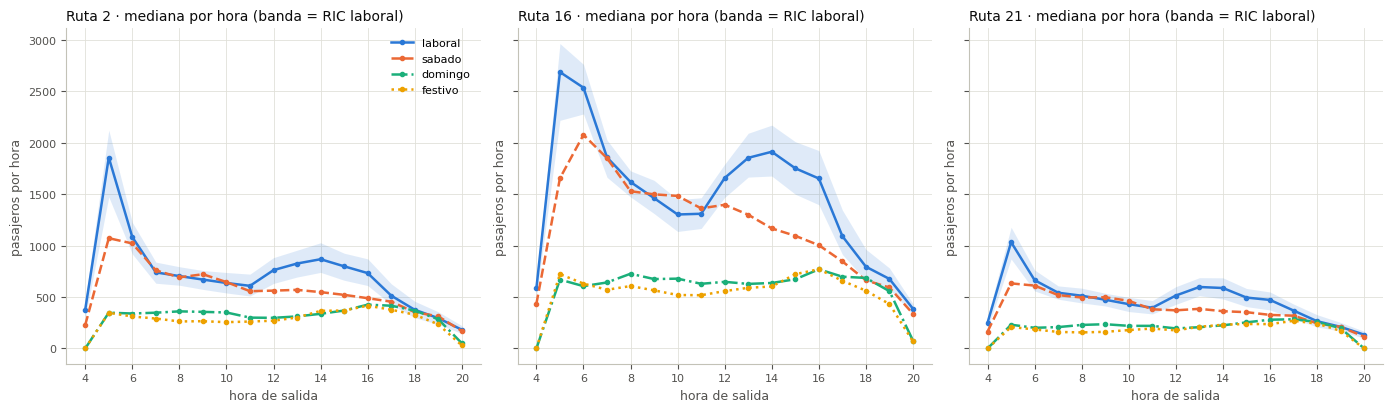

In [107]:
ph = et.pasajeros_hora(serie, cal)
perfil = et.perfil_horario(ph)
picos = et.picos_valles(perfil)
display(picos.round(2))
GRUPOS = ["laboral", "sabado", "domingo", "festivo"]
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for a, (r, g) in zip(ax, perfil.groupby("idruta")):
    for t in GRUPOS:
        gt = g[g.tipo_dia_cal == t]
        a.plot(gt.hora, gt.mediana, ls=et.ESTILO_DIA[t], color=et.COLOR_DIA[t], lw=1.8, marker="o", ms=3, label=t)
        if t == "laboral":
            a.fill_between(gt.hora, gt.p25, gt.p75, color=et.COLOR_DIA[t], alpha=0.15, lw=0)
    et.estilo_ejes(a, f"Ruta {r} · mediana por hora (banda = RIC laboral)", "hora de salida", "pasajeros por hora")
    a.set_xticks(range(4, 21, 2))
ax[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); guardar(fig, "m3_perfiles_horarios")

**Contraste con la hora real de abordaje.** En las lecturas GPS de los viajes aptos (0.2) cada subida tiene su propia marca de tiempo. Comparar su distribución horaria con la hora de salida mide cuánto desplaza el pico atribuir todo el viaje a la salida.

,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
pct_por_hora_real_de_subida,0.32,3.80,7.78,7.69,5.71,6.23,5.34,5.19,5.74,5.45,6.20,6.08,7.56,8.28,6.99,4.53,3.82,2.43,0.85,0.02
pct_por_hora_de_salida,2.64,10.59,9.27,5.75,6.85,4.77,6.37,5.92,6.05,7.60,8.71,8.04,5.28,5.06,3.32,2.68,1.09,0.00,0.00,0.00


Viajes aptos usados: 1,335 | pico por hora real: 17 h | pico por hora de salida: 5 h


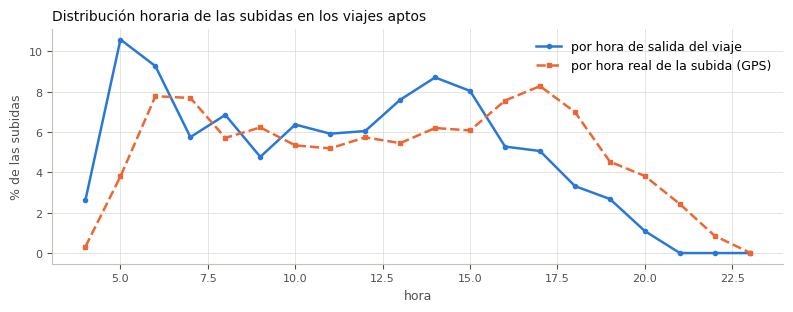

In [108]:
lect_aptas = conteo[conteo.idprogramacion.isin(IDS_APTOS)]
sub_hora_real = lect_aptas.groupby(lect_aptas.fecha.dt.hour).cantidad_subida.sum()
m_aptos = maestra[maestra.idprogramacion.isin(IDS_APTOS)]
sub_hora_salida = m_aptos.groupby("hora").numeropasajeros.sum().astype(float)
comp_hora = pd.DataFrame({"pct_por_hora_real_de_subida": 100 * sub_hora_real / sub_hora_real.sum(),
                          "pct_por_hora_de_salida": 100 * sub_hora_salida / sub_hora_salida.sum()}).fillna(0).round(2)
display(comp_hora.T)
print(f"Viajes aptos usados: {m_aptos.idprogramacion.nunique():,} | pico por hora real: {comp_hora.pct_por_hora_real_de_subida.idxmax()} h | "
      f"pico por hora de salida: {comp_hora.pct_por_hora_de_salida.idxmax()} h")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(comp_hora.index, comp_hora.pct_por_hora_de_salida, color=et.COLOR_RUTA[2], lw=1.8, marker="o", ms=3, label="por hora de salida del viaje")
ax.plot(comp_hora.index, comp_hora.pct_por_hora_real_de_subida, color=et.COLOR_RUTA[16], lw=1.8, ls="--", marker="s", ms=3, label="por hora real de la subida (GPS)")
et.estilo_ejes(ax, "Distribución horaria de las subidas en los viajes aptos", "hora", "% de las subidas")
ax.legend(frameon=False); plt.tight_layout(); guardar(fig, "m3_hora_salida_vs_hora_real")

**Conclusión 3.6 · Los días laborales tienen pico a las 5 h por hora de salida; la demanda real llega a las 6–7 h y a las 16–17 h**
- **Laborales:** pico a las 5 h en las tres rutas y segundo pico a las 13–14 h. La razón pico/valle es de 4,0 (ruta 16) a 6,3 (ruta 2). El valle está a las 19 h.
- **Sábados:** pico de 5–6 h, más bajo. **Domingos y festivos:** sin pico de madrugada, con una meseta y un máximo suave a las 16–17 h (razón pico/valle de 1,4–1,8).
- **La hora de salida desplaza el pico.** En los 1.335 viajes aptos, el 10,6 % de las subidas se asigna a viajes que salen a las 5 h, pero solo el 3,8 % ocurre realmente a esa hora. Por hora real de la subida, los picos son a las 6–7 h (7,8 %) y a las 16–17 h (7,6–8,3 %). Un viaje de ~4 h que sale a las 5 h recoge la hora punta de la mañana.
- **Implicación para el modelo:** si el objetivo es "pasajeros por despacho", la hora de salida es la correcta. Si el objetivo es "pasajeros en la vía", habría que usar las lecturas, que solo existen como muestra.

## 3.7 ¿Difieren laborales, sábados, domingos y festivos?
- **Unidad = día** (pasajeros diarios por ruta), no el intervalo de 15 min: 96 intervalos del mismo día no son 96 observaciones independientes.
- **Kruskal-Wallis** y **Mann-Whitney** por pares (sin suponer normalidad; corrección de Holm dentro de cada ruta), con el δ de Cliff como tamaño de efecto.
- Los días siguen autocorrelacionados (tendencia y ciclo semanal), así que esos valores p son **optimistas**. El contraste principal festivo–laboral usa un **diseño emparejado**: cada festivo entre semana contra el mismo día de la semana 7 días antes y después (Wilcoxon de rangos con signo sobre el log de la razón).
- La **forma** del perfil (proporción del total diario en cada hora) se compara hora a hora con Holm.

In [109]:
from statsmodels.tsa.stattools import acf as _acf
dep = pd.DataFrame({r: _acf(g.sort_values("fecha").pasajeros, nlags=7)[[1, 7]] for r, g in diario.groupby("idruta")}, index=["acf_lag1_dia", "acf_lag7_dias"]).T
print("Dependencia entre días (pasajeros diarios):"); display(dep.round(3))
diario_ok = diario[~diario.dia_anomalo & ~diario.es_carnaval]
kw, pares = et.comparar_tipos_dia(diario_ok)
display(kw.round(4)); display(pares.round(4))

Dependencia entre días (pasajeros diarios):


,acf_lag1_dia,acf_lag7_dias
2,0.380,0.664
16,0.324,0.659
21,0.329,0.630


,idruta,H,p_valor,n_laboral,n_sabado,n_domingo,n_festivo
0,2,619.3156,0.0,727,152,151,53
1,16,643.9098,0.0,727,152,151,53
2,21,641.3114,0.0,727,152,151,53


,idruta,grupo_a,grupo_b,mediana_a,mediana_b,razon_medianas,delta_cliff,p_valor,p_holm
0,2,laboral,sabado,11827.0,9536.5,1.2402,0.7097,0.0000,0.0000
1,2,laboral,domingo,11827.0,5201.0,2.2740,0.9976,0.0000,0.0000
2,2,laboral,festivo,11827.0,4825.0,2.4512,0.9990,0.0000,0.0000
3,2,sabado,domingo,9536.5,5201.0,1.8336,0.9925,0.0000,0.0000
4,2,sabado,festivo,9536.5,4825.0,1.9765,0.9960,0.0000,0.0000
5,2,domingo,festivo,5201.0,4825.0,1.0779,0.3125,0.0007,0.0007
6,16,laboral,sabado,24905.0,20291.5,1.2274,0.7729,0.0000,0.0000
7,16,laboral,domingo,24905.0,9845.0,2.5297,0.9987,0.0000,0.0000
8,16,laboral,festivo,24905.0,9229.0,2.6986,0.9995,0.0000,0.0000
9,16,sabado,domingo,20291.5,9845.0,2.0611,0.9967,0.0000,0.0000


,idruta,pares,mediana_razon_festivo_laboral,p25_razon,p75_razon,W,p_valor,p_holm
0,2,48,0.4061,0.3542,0.4656,0.0,0.0,0.0
1,16,48,0.3725,0.3417,0.4158,0.0,0.0,0.0
2,21,48,0.3963,0.3416,0.4492,0.0,0.0,0.0


Horas en que la PROPORCIÓN horaria difiere entre laboral y festivo (p de Holm < 0,05):


,idruta,hora,prop_mediana_laboral,prop_mediana_festivo,delta_cliff,p_valor,p_holm
0,2,5,0.1501,0.0730,-0.9704,0.0000,0.0000
1,2,6,0.0882,0.0671,-0.7010,0.0000,0.0000
10,2,15,0.0667,0.0787,0.4109,0.0000,0.0000
11,2,16,0.0624,0.0848,0.7461,0.0000,0.0000
12,2,17,0.0440,0.0771,0.8867,0.0000,0.0000
13,2,18,0.0322,0.0674,0.8859,0.0000,0.0000
14,2,19,0.0248,0.0524,0.8781,0.0000,0.0000
15,16,5,0.1050,0.0802,-0.7079,0.0000,0.0000
16,16,6,0.1003,0.0640,-0.9625,0.0000,0.0000
17,16,7,0.0735,0.0632,-0.5475,0.0000,0.0000


Carnaval (12 días, descriptivo):


,mediana_carnaval,mediana_laboral,mediana_domingo,razon_carnaval_laboral
idruta,,,,
2,5326.5,11827.0,5201.0,0.45
16,9853.5,24905.0,9845.0,0.40
21,2746.5,7874.0,3389.0,0.35


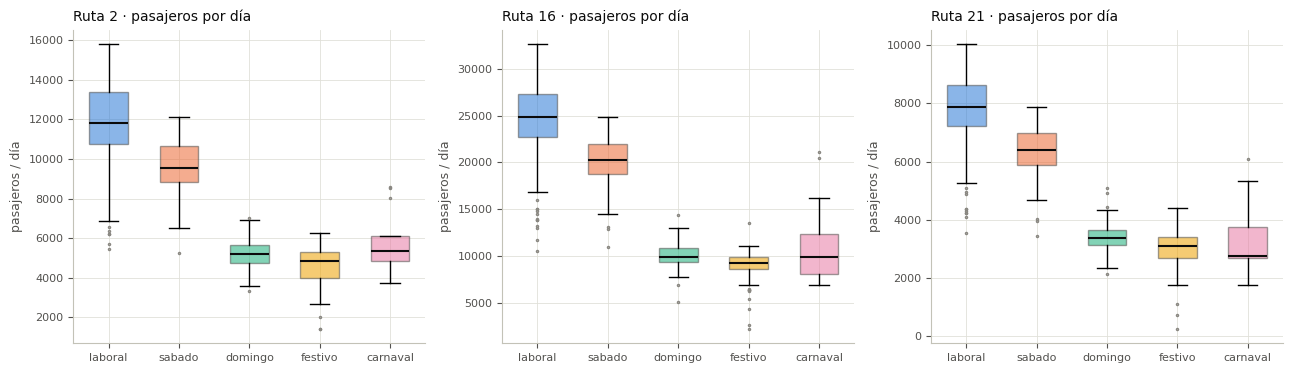

In [110]:
emp = et.festivo_emparejado(diario[~diario.dia_anomalo], cal)
wil = et.wilcoxon_por_ruta(emp)
display(wil.round(4))
forma = et.comparar_forma_horaria(ph)
print("Horas en que la PROPORCIÓN horaria difiere entre laboral y festivo (p de Holm < 0,05):")
display(forma[forma.p_holm < cfg.alpha].round(4))
carn = diario[diario.es_carnaval].groupby("idruta").pasajeros.median().to_frame("mediana_carnaval")
carn["mediana_laboral"] = diario_ok[diario_ok.tipo_dia_cal == "laboral"].groupby("idruta").pasajeros.median()
carn["mediana_domingo"] = diario_ok[diario_ok.tipo_dia_cal == "domingo"].groupby("idruta").pasajeros.median()
carn["razon_carnaval_laboral"] = carn.mediana_carnaval / carn.mediana_laboral
print("Carnaval (12 días, descriptivo):"); display(carn.round(2))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
orden = ["laboral", "sabado", "domingo", "festivo", "carnaval"]
for a, (r, g) in zip(ax, diario[~diario.dia_anomalo].groupby("idruta")):
    datos = [g.loc[g.tipo_dia_cal == t, "pasajeros"] for t in orden]
    bp = a.boxplot(datos, tick_labels=orden, widths=0.55, patch_artist=True, medianprops={"color": et.INK, "lw": 1.5},
                   flierprops={"marker": ".", "ms": 3, "markeredgecolor": et.MUTED})
    for patch, t in zip(bp["boxes"], orden):
        patch.set_facecolor(et.COLOR_DIA[t]); patch.set_alpha(0.55); patch.set_edgecolor(et.INK2)
    et.estilo_ejes(a, f"Ruta {r} · pasajeros por día", None, "pasajeros / día")
    a.tick_params(axis="x", labelsize=8)
plt.tight_layout(); guardar(fig, "m3_pasajeros_diarios_por_tipo_dia")

**Conclusión 3.7 · Un festivo entre semana mueve ≈ 40 % de los pasajeros de un laboral normal**
- **Por pares (diseño principal):** 48 festivos entre semana por ruta, cada uno frente al mismo día de la semana anterior y la siguiente. La mediana de la razón festivo/laboral es **0,41 (ruta 2), 0,37 (16) y 0,40 (21)**, con un RIC de ≈ 0,34–0,47. Wilcoxon da W = 0 en las tres rutas, porque **todos** los festivos quedaron por debajo de su referencia; p de Holm < 0,001.
- **Por grupos (descriptivo, p optimistas):** la mediana diaria de los laborales es 2,3–2,7 veces la de domingos y festivos. Los sábados están ≈ 19 % por debajo de los laborales. Festivo y domingo son parecidos: el festivo es 6–9 % más bajo, con un δ de Cliff de 0,31–0,37 (efecto pequeño-moderado). **No se deben fusionar sin más.**
- **Cambia la forma, no solo el nivel.** En festivo, la proporción del día a las 5 h cae a la mitad (δ de Cliff de −0,71 a −0,97) y la de las 16–19 h casi se duplica (δ de +0,61 a +0,89; Holm < 0,001 en las tres rutas).
- **Carnaval:** 0,35–0,45 de un laboral, al nivel de un domingo.
- **Por qué no basta con un test independiente:** los días están autocorrelacionados (ACF de 0,32–0,38 a 1 día y de 0,63–0,66 a 7 días). Las pruebas por grupos tratan los días como independientes y exageran la significancia. Por eso la conclusión cuantitativa se apoya en el diseño emparejado.

# Módulo 4 · Dimensión espacial

## 4.1 Validación de coordenadas
Coordenadas en grados decimales; el GPS de los buses entrega WGS84 (EPSG:4326), lo que se confirma porque el 99,9999 % cae en la caja Barranquilla–Soledad de la 1.4. Una fila **no** es una ubicación: hay ~580 lecturas por viaje y muchas repetidas mientras el bus está detenido.

In [111]:
la, lo = conteo.latitud, conteo.longitud
caja = la.between(CAJA["lat_min"], CAJA["lat_max"]) & lo.between(CAJA["lon_min"], CAJA["lon_max"])
val_coord = pd.Series({
    "lecturas": len(conteo), "viajes": conteo.idprogramacion.nunique(),
    "lat_o_lon_nulas": int((la.isna() | lo.isna()).sum()), "lat_o_lon_en_cero": int(((la == 0) | (lo == 0)).sum()),
    "fuera_rango_geografico (|lat|>90 o |lon|>180)": int(((la.abs() > 90) | (lo.abs() > 180)).sum()),
    "fuera_caja_Barranquilla_Soledad": int((~caja).sum()),
    "pct_coordenadas_exactas_repetidas": round(100 * conteo.duplicated(["latitud", "longitud"]).mean(), 2),
    "lecturas_repetidas (viaje, fecha)": int(conteo.duplicated(["idprogramacion", "fecha"]).sum()),
    "id_duplicado": int(conteo.id.duplicated().sum()),
}).to_frame("valor")
display(val_coord)
display(conteo.loc[~caja, ["id", "idprogramacion", "fecha", "latitud", "longitud"]])
c = conteo[caja].sort_values(["idprogramacion", "fecha", "id"])
mismo = c.idprogramacion.values[1:] == c.idprogramacion.values[:-1]
paso_m = et.haversine_m(c.latitud.values[:-1], c.longitud.values[:-1], c.latitud.values[1:], c.longitud.values[1:])[mismo]
paso_s = np.diff(c.fecha.values).astype("timedelta64[s]").astype(float)[mismo]
cadencia = pd.DataFrame({"paso_m": paso_m, "cadencia": np.where(paso_s >= 30, "≥ 30 s (periódica)", "< 30 s (por evento)")})
display(cadencia.groupby("cadencia").paso_m.describe(percentiles=[.25, .5, .75, .9]).round(1))

,valor
lecturas,971335.0
viajes,1673.0
lat_o_lon_nulas,0.0
lat_o_lon_en_cero,0.0
fuera_rango_geografico (|lat|>90 o |lon|>180),0.0
fuera_caja_Barranquilla_Soledad,1.0
pct_coordenadas_exactas_repetidas,21.4
"lecturas_repetidas (viaje, fecha)",48111.0
id_duplicado,0.0


,id,idprogramacion,fecha,latitud,longitud
799024,1319697319,7251857,2025-08-21 07:00:24,89.0,4.5


,count,mean,std,min,25%,50%,75%,90%,max
cadencia,,,,,,,,,
< 30 s (por evento),630164.0,20.5,32.0,0.0,0.0,10.5,27.0,50.3,561.7
≥ 30 s (periódica),339497.0,254.5,203.3,0.0,112.1,226.2,355.0,496.3,16393.4


**Conclusión 4.1 · Coordenadas válidas; una sola lectura imposible**
- 971.335 lecturas de 1.673 viajes: 0 nulas, 0 en cero. **Solo 1 está fuera de la caja** (lat 89,0, lon 4,5, en el Ártico: un error del GPS) y se excluye. El resto está en el rango de Barranquilla–Soledad, coherente con WGS84 en grados decimales.
- El 21,4 % de las coordenadas se repite exactamente (bus detenido) y hay 48.111 lecturas con el mismo viaje y segundo. **Una lectura no es una ubicación**: la unidad espacial hay que construirla.
- **El GPS tiene dos cadencias.** Una periódica (≥ 30 s), con un paso mediano de 226 m (p75 = 355 m). Otra por evento (< 30 s, al subir o bajar alguien), con una mediana de 10,5 m. Una celda de 250 m queda cerca del paso típico entre lecturas periódicas.

## 4.2 Unidades espaciales: celdas de 250 m
No hay paraderos georreferenciados (`idpunto` está nulo en el 90 % según la 1.4), así que la unidad espacial se **construye**: una malla regular de 250 m (proyección local solo para agrupar; las distancias entre celdas se miden con Haversine). 250 m ≈ el paso típico entre dos lecturas periódicas (4.1), de modo que casi todo viaje que cruza una celda deja al menos una lectura en ella.

Variable: **`subidas_por_viaje`** = subidas registradas en la celda / viajes distintos que pasan por ella (exposición). Se exigen ≥ 30 viajes para que la tasa sea estable. Cada celda es **una** unidad: las lecturas repetidas de un mismo lugar no cuentan como unidades independientes. Es un análisis **exploratorio** de la estructura espacial de la demanda, no una variable de entrenamiento.

In [112]:
LECT_ESP = conteo[conteo.idprogramacion.isin(IDS_APTOS) & ~conteo.flag_fuera_area]
celdas_todas, lect_celda, LAT_REF = et.construir_celdas(LECT_ESP, cfg)
celdas = celdas_todas[celdas_todas.apta].sort_values(["cy", "cx"]).reset_index(drop=True)
celdas.insert(0, "celda_id", np.arange(len(celdas)))
print(f"Lecturas usadas: {len(LECT_ESP):,} de {LECT_ESP.idprogramacion.nunique():,} viajes | celdas con lecturas: {len(celdas_todas):,} | "
      f"celdas aptas (≥ {cfg.min_viajes_celda} viajes): {len(celdas):,}")
print(f"Las celdas aptas concentran el {100 * celdas.subidas.sum() / celdas_todas.subidas.sum():.2f} % de las subidas y el "
      f"{100 * celdas.n_lecturas.sum() / celdas_todas.n_lecturas.sum():.2f} % de las lecturas")
assert celdas[["latitud", "longitud"]].duplicated().sum() == 0, "Centroides coincidentes"
display(celdas[["n_viajes", "n_lecturas", "subidas", "subidas_por_viaje", "bajadas_por_viaje", "n_rutas"]].describe().round(2))
display(celdas.n_rutas.value_counts().sort_index().to_frame("celdas por nº de rutas que la usan"))

Lecturas usadas: 452,967 de 1,335 viajes | celdas con lecturas: 816 | celdas aptas (≥ 30 viajes): 364
Las celdas aptas concentran el 99.91 % de las subidas y el 99.14 % de las lecturas


,n_viajes,n_lecturas,subidas,subidas_por_viaje,bajadas_por_viaje,n_rutas
count,364.00,364.00,364.00,364.00,364.00,364.00
mean,489.81,1233.68,315.27,0.56,0.59,2.09
std,333.39,1223.88,391.05,0.51,0.48,0.88
min,30.00,32.00,0.00,0.00,0.00,1.00
25%,271.00,386.75,51.50,0.20,0.26,1.00
50%,411.50,906.50,193.50,0.45,0.52,2.00
75%,647.25,1607.75,428.00,0.80,0.78,3.00
max,1331.00,9329.00,3155.00,2.77,3.13,3.00


,celdas por nº de rutas que la usan
n_rutas,
1,125
2,81
3,158


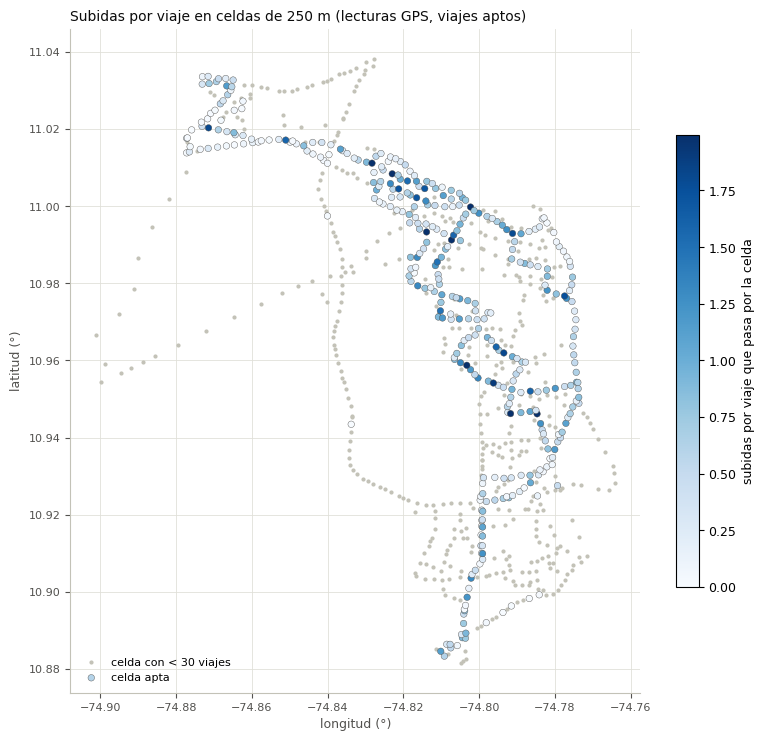

In [113]:
ASPECTO = 1 / np.cos(np.radians(LAT_REF))
fig, ax = plt.subplots(figsize=(8, 8))
no_apt = celdas_todas[~celdas_todas.apta]
ax.scatter(no_apt.longitud, no_apt.latitud, s=4, color="#c3c2b7", label=f"celda con < {cfg.min_viajes_celda} viajes")
sc = ax.scatter(celdas.longitud, celdas.latitud, c=celdas.subidas_por_viaje, cmap="Blues", s=22, edgecolor=et.INK2, lw=0.3,
                vmin=0, vmax=celdas.subidas_por_viaje.quantile(.98), label="celda apta")
fig.colorbar(sc, ax=ax, shrink=0.6, label="subidas por viaje que pasa por la celda")
ax.set_aspect(ASPECTO); et.estilo_ejes(ax, "Subidas por viaje en celdas de 250 m (lecturas GPS, viajes aptos)", "longitud (°)", "latitud (°)")
ax.legend(frameon=False, loc="lower left", fontsize=8); plt.tight_layout(); guardar(fig, "m4_mapa_celdas")

**Conclusión 4.2 · 364 celdas aptas describen los corredores de las 3 rutas**
- Entraron 452.967 lecturas de 1.335 viajes. Se excluyeron 338 viajes: 192 de la muestra dirigida de bloqueos, 42 de la de ceros, 99 con sensor no confiable y 5 con carga imposible.
- Hay 816 celdas con lecturas y **364 con ≥ 30 viajes**. Esas 364 concentran el 99,9 % de las subidas, así que las descartadas son bordes y desvíos con poca exposición.
- La mediana es de 0,45 subidas por viaje que pasa (máximo 2,77). **158 celdas son compartidas por las 3 rutas** y 125 son exclusivas de una.
- El mapa muestra tramos con muchas subidas contiguos a otros con muchas subidas: indicio visual de autocorrelación positiva, que se mide en 4.3.

## 4.3 KNN con distancia Haversine y selección de k con el índice de Moran
Convención fija para todo el módulo:
- **A_k**: matriz binaria dirigida, `A[i, j] = 1` si j es uno de los k vecinos más cercanos de i por Haversine (se excluye i). En general A ≠ Aᵀ.
- **Moran** se calcula con **W = A_k estandarizada por filas** (cada fila suma 1, S0 = n), la convención habitual de PySAL. Inferencia: 999 permutaciones con semilla 42 (p unilateral en la dirección observada) y la aproximación normal bajo aleatorización.
- **Grafo y conectividad**: versión simétrica por **unión** (i~j si cualquiera es vecino del otro). La intersección (vecindades mutuas) se reporta como diagnóstico.

**Regla de elección de k (no se maximiza Moran):** entre los k cuya unión es un grafo conexo, cuyo k-ésimo vecino mediano está a ≤ 500 m (escala de caminata a un paradero) y sin empates en la k-ésima distancia, se toma el **mayor**, porque más vecinos estabilizan el rezago espacial sin salir de la escala local.

In [114]:
eval_k = et.evaluar_k(celdas, "subidas_por_viaje", cfg)
display(eval_k[["k", "matriz", "n_ubicaciones", "I", "E_I", "z_aleatorizacion", "p_aleatorizacion", "z_permutacion", "p_permutacion",
                "I_union_sim", "pct_vecindades_mutuas", "componentes_union", "aislados_union", "componentes_interseccion",
                "grado_medio_union", "grado_max_union", "dist_k_mediana_m", "dist_k_p95_m", "dist_k_max_m", "empates_k"]].round(4))
candidatos = eval_k[(eval_k.componentes_union == 1) & (eval_k.dist_k_mediana_m <= 500) & (eval_k.empates_k == 0)]
K = int(candidatos.k.max())
print(f"k candidatos: {candidatos.k.tolist()} → k elegido = {K}")
print(f"Rango de I para k entre 3 y 8: {eval_k[eval_k.k.between(3, 8)].I.min():.3f} – {eval_k[eval_k.k.between(3, 8)].I.max():.3f}")

,k,matriz,n_ubicaciones,I,E_I,z_aleatorizacion,p_aleatorizacion,z_permutacion,p_permutacion,I_union_sim,pct_vecindades_mutuas,componentes_union,aislados_union,componentes_interseccion,grado_medio_union,grado_max_union,dist_k_mediana_m,dist_k_p95_m,dist_k_max_m,empates_k
0,2,"KNN binaria dirigida, estandarizada por filas",364,0.2610,-0.0028,5.3086,0.0,5.2604,0.001,0.2581,82.4176,6,0,78,2.3516,4,225.1958,307.7188,3537.9597,0
1,3,"KNN binaria dirigida, estandarizada por filas",364,0.2173,-0.0028,5.4082,0.0,5.3233,0.001,0.2139,84.0659,1,0,18,3.4780,6,286.6016,482.8227,3614.7586,0
2,4,"KNN binaria dirigida, estandarizada por filas",364,0.2106,-0.0028,6.0338,0.0,5.9723,0.001,0.2017,85.8516,1,0,7,4.5659,7,359.2262,528.2968,3665.8498,1
3,5,"KNN binaria dirigida, estandarizada por filas",364,0.1912,-0.0028,6.1444,0.0,6.2234,0.001,0.1855,85.8242,1,0,6,5.7088,9,415.3373,609.6931,3740.3828,0
4,6,"KNN binaria dirigida, estandarizada por filas",364,0.1755,-0.0028,6.1912,0.0,6.2407,0.001,0.1769,86.0806,1,0,4,6.8352,10,480.0400,680.3943,3782.0353,0
5,8,"KNN binaria dirigida, estandarizada por filas",364,0.1495,-0.0028,6.1347,0.0,6.0381,0.001,0.1441,85.5082,1,0,3,9.1593,15,560.4779,804.5011,3890.4048,0
6,10,"KNN binaria dirigida, estandarizada por filas",364,0.1315,-0.0028,6.0531,0.0,5.9966,0.001,0.1238,86.3736,1,0,3,11.3626,18,655.8958,935.8836,3983.1855,1
7,12,"KNN binaria dirigida, estandarizada por filas",364,0.1251,-0.0028,6.3313,0.0,6.2109,0.001,0.1163,86.5385,1,0,3,13.6154,20,738.1886,1090.4141,4052.6667,0
8,15,"KNN binaria dirigida, estandarizada por filas",364,0.1275,-0.0028,7.2431,0.0,7.0746,0.001,0.1268,86.5201,1,0,3,17.0220,25,859.0184,1257.5502,4155.1197,0
9,20,"KNN binaria dirigida, estandarizada por filas",364,0.1220,-0.0028,8.0848,0.0,7.9209,0.001,0.1200,86.2912,1,0,3,22.7418,42,1044.8548,1574.4270,4274.9366,0


k candidatos: [3, 5, 6] → k elegido = 6
Rango de I para k entre 3 y 8: 0.150 – 0.217


,banda_m,dist_media_m,celdas_con_vecinos,pares,I,z_permutacion,p_permutacion
0,"(0, 300]",150.0,355,1014,0.2273,4.8935,0.001
1,"(300, 600]",450.0,362,2104,0.1509,4.6821,0.001
2,"(600, 900]",750.0,362,2820,0.0825,2.7564,0.007
3,"(900, 1200]",1050.0,360,3268,0.1283,4.7564,0.001
4,"(1200, 1800]",1500.0,363,6932,0.0926,5.2823,0.001
5,"(1800, 2400]",2100.0,363,7406,0.0771,4.2703,0.001
6,"(2400, 3600]",3000.0,364,16542,0.0406,3.6001,0.001
7,"(3600, 5000]",4300.0,364,18480,0.0005,0.2847,0.386
8,"(5000, 7500]",6250.0,364,27782,-0.0495,-6.1357,0.001
9,"(7500, 10000]",8750.0,364,20834,-0.0868,-9.2983,0.001


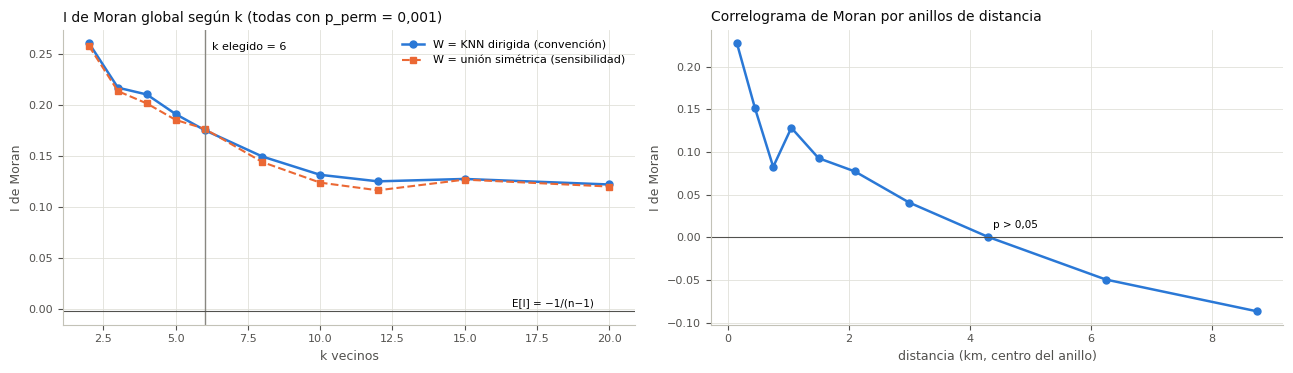

In [115]:
correlo = et.correlograma_distancia(celdas, "subidas_por_viaje", [0, 300, 600, 900, 1200, 1800, 2400, 3600, 5000, 7500, 10000], cfg)
display(correlo.round(4))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(eval_k.k, eval_k.I, color=et.COLOR_RUTA[2], lw=1.8, marker="o", ms=5, label="W = KNN dirigida (convención)")
ax[0].plot(eval_k.k, eval_k.I_union_sim, color=et.COLOR_RUTA[16], lw=1.5, ls="--", marker="s", ms=4, label="W = unión simétrica (sensibilidad)")
ax[0].axvline(K, color=et.MUTED, lw=1); ax[0].annotate(f"k elegido = {K}", (K, eval_k.I.max()), xytext=(5, -5), textcoords="offset points", fontsize=8)
ax[0].axhline(eval_k.E_I.iloc[0], color=et.INK2, lw=0.8); ax[0].annotate("E[I] = −1/(n−1)", (eval_k.k.max(), eval_k.E_I.iloc[0]), xytext=(-70, 4), textcoords="offset points", fontsize=7.5)
et.estilo_ejes(ax[0], "I de Moran global según k (todas con p_perm = 0,001)", "k vecinos", "I de Moran"); ax[0].legend(frameon=False, fontsize=8)
ax[1].plot(correlo.dist_media_m / 1000, correlo.I, color=et.COLOR_RUTA[2], lw=1.8, marker="o", ms=5)
ax[1].axhline(0, color=et.INK2, lw=0.8)
for _, r in correlo[correlo.p_permutacion > cfg.alpha].iterrows():
    ax[1].annotate("p > 0,05", (r.dist_media_m / 1000, r.I), xytext=(4, 6), textcoords="offset points", fontsize=7.5)
et.estilo_ejes(ax[1], "Correlograma de Moran por anillos de distancia", "distancia (km, centro del anillo)", "I de Moran")
plt.tight_layout(); guardar(fig, "m4_moran_k_y_correlograma")

### Matriz elegida: comprobaciones de dimensión, diagonal, vecinos y simetría

In [116]:
IDX, DIST = et.knn_haversine(celdas.latitud.values, celdas.longitud.values, K)
A = et.matriz_knn(IDX, len(celdas))
W = et.estandarizar_filas(A)
U = et.simetrizar(A, "union")
n = len(celdas)
chk_W = pd.Series({
    "dimension": f"{A.shape[0]} × {A.shape[1]}", "n_ubicaciones": n,
    "diagonal_nula": bool(A.diagonal().sum() == 0),
    "vecinos_por_fila_min_max": f"{int(A.sum(1).min())} – {int(A.sum(1).max())}",
    "filas_W_suman_1": bool(np.allclose(np.asarray(W.sum(1)).ravel(), 1)),
    "A_simetrica": bool((A != A.T).nnz == 0),
    "pct_vecindades_mutuas": round(100 * A.multiply(A.T).nnz / A.nnz, 2),
    "aristas_no_dirigidas_union": int(U.nnz // 2),
    "empates_en_k": et.empates_k(celdas.latitud.values, celdas.longitud.values, K),
    "dist_vecino_k_mediana_m": round(float(np.median(DIST[:, -1])), 1),
    "dist_vecino_1_mediana_m": round(float(np.median(DIST[:, 0])), 1),
}).to_frame("valor")
display(chk_W)
grado_U = np.asarray(U.sum(1)).ravel()
display(pd.Series(grado_U).value_counts().sort_index().to_frame("celdas por grado en la unión").T)
moran_K = et.moran_global(celdas.subidas_por_viaje.values, W, cfg.permutaciones, cfg.semilla)
display(pd.Series({k: v for k, v in moran_K.items() if not k.startswith("_")}).to_frame(f"Moran · k = {K}").round(5))

,valor
dimension,364 × 364
n_ubicaciones,364
diagonal_nula,True
vecinos_por_fila_min_max,6 – 6
filas_W_suman_1,True
A_simetrica,False
pct_vecindades_mutuas,86.08
aristas_no_dirigidas_union,1244
empates_en_k,0
dist_vecino_k_mediana_m,480.0


,6.0,7.0,8.0,9.0,10.0
celdas por grado en la unión,173,110,56,18,7


,Moran · k = 6
I,0.1755
E_I,-0.0027
z_normal,6.1647
p_normal,0.0000
z_aleatorizacion,6.1912
p_aleatorizacion,0.0000
p_permutacion,0.0010
I_perm_media,-0.0028
I_perm_desv,0.0286
z_permutacion,6.2407


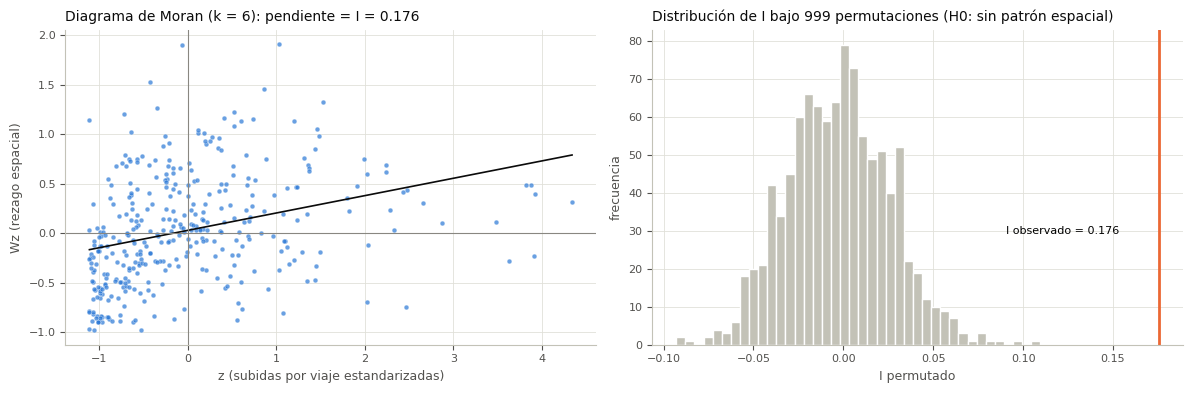

In [117]:
z = celdas.subidas_por_viaje.values - celdas.subidas_por_viaje.mean()
z = z / z.std()
wz = W @ z
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(z, wz, s=12, color=et.COLOR_RUTA[2], alpha=0.7, edgecolor="white", lw=0.3)
b = np.polyfit(z, wz, 1)
xs = np.linspace(z.min(), z.max(), 50); ax[0].plot(xs, b[0] * xs + b[1], color=et.INK, lw=1.2)
ax[0].axhline(0, color=et.MUTED, lw=0.8); ax[0].axvline(0, color=et.MUTED, lw=0.8)
et.estilo_ejes(ax[0], f"Diagrama de Moran (k = {K}): pendiente = I = {b[0]:.3f}", "z (subidas por viaje estandarizadas)", "Wz (rezago espacial)")
ax[1].hist(moran_K["_I_perm"], bins=40, color="#c3c2b7", edgecolor="white")
ax[1].axvline(moran_K["I"], color=et.COLOR_RUTA[16], lw=2); ax[1].annotate(f"I observado = {moran_K['I']:.3f}", (moran_K["I"], 0), xytext=(-110, 80), textcoords="offset points", fontsize=8)
et.estilo_ejes(ax[1], f"Distribución de I bajo {cfg.permutaciones} permutaciones (H0: sin patrón espacial)", "I permutado", "frecuencia")
plt.tight_layout(); guardar(fig, "m4_diagrama_moran_y_permutaciones")

### Sensibilidad: tamaño de celda, exposición mínima y transformación de la variable

In [118]:
sens = []
for lado in [200, 250, 300, 400]:
    for min_v in [30, 50]:
        cfg_s = et.Config(celda_m=lado, min_viajes_celda=min_v)
        cs, _, _ = et.construir_celdas(LECT_ESP, cfg_s, lat_ref=LAT_REF)
        cs = cs[cs.apta].reset_index(drop=True)
        ix, _ = et.knn_haversine(cs.latitud.values, cs.longitud.values, K)
        Ws = et.estandarizar_filas(et.matriz_knn(ix, len(cs)))
        for var, y in [("subidas_por_viaje", cs.subidas_por_viaje), ("log1p(subidas_por_viaje)", np.log1p(cs.subidas_por_viaje)),
                       ("bajadas_por_viaje", cs.bajadas_por_viaje)]:
            mr = et.moran_global(y.values, Ws, cfg.permutaciones, cfg.semilla)
            sens.append({"celda_m": lado, "min_viajes": min_v, "variable": var, "n_celdas": len(cs), "k": K, "I": mr["I"],
                         "z_permutacion": mr["z_permutacion"], "p_permutacion": mr["p_permutacion"]})
_, d1 = et.knn_haversine(celdas.latitud.values, celdas.longitud.values, 1)
cer = celdas[d1[:, 0] <= 1000].reset_index(drop=True)
ixc, _ = et.knn_haversine(cer.latitud.values, cer.longitud.values, K)
mr = et.moran_global(cer.subidas_por_viaje.values, et.estandarizar_filas(et.matriz_knn(ixc, len(cer))), cfg.permutaciones, cfg.semilla)
sens.append({"celda_m": cfg.celda_m, "min_viajes": cfg.min_viajes_celda, "variable": "subidas_por_viaje (sin celdas a > 1 km de su vecina)",
             "n_celdas": len(cer), "k": K, "I": mr["I"], "z_permutacion": mr["z_permutacion"], "p_permutacion": mr["p_permutacion"]})
print(f"Celdas cuya vecina más cercana está a más de 1 km: {(d1[:, 0] > 1000).sum()} → sin ellas, I = {mr['I']:.4f} (p = {mr['p_permutacion']:.3f})")
display(celdas.loc[d1[:, 0] > 1000, ["celda_id", "latitud", "longitud", "n_viajes", "subidas_por_viaje", "rutas"]])
sens = pd.DataFrame(sens)
display(sens.pivot_table(index=["celda_m", "min_viajes", "n_celdas"], columns="variable", values="I").round(3))
print("Máximo p por permutación en toda la tabla:", sens.p_permutacion.max())

Celdas cuya vecina más cercana está a más de 1 km: 2 → sin ellas, I = 0.1783 (p = 0.001)


,celda_id,latitud,longitud,n_viajes,subidas_por_viaje,rutas
76,76,10.9434,-74.8338,31,0.0000,"2,16,21"
230,230,10.9974,-74.8400,31,0.0323,"2,16,21"


variable                     bajadas_por_viaje  log1p(subidas_por_viaje)  subidas_por_viaje  subidas_por_viaje (sin celdas a > 1 km de su vecina)
celda_m min_viajes n_celdas                                                                                                                      
200.0   30         447                   0.208                     0.216              0.166                                                NaN   
        50         426                   0.229                     0.223              0.170                                                NaN   
250.0   30         362                     NaN                       NaN                NaN                                              0.178   
                   364                   0.185                     0.233              0.176                                                NaN   
        50         349                   0.196                     0.225              0.169                                                NaN   
300.0   30         291                   0.192                     0.256              0.196                                                NaN   
        50         269                   0.236                     0.255              0.193                                                NaN   
400.0   30         228                   0.203                     0.294              0.190                                                NaN   
        50         198                   0.154                     0.156              0.091                                                NaN

Máximo p por permutación en toda la tabla: 0.013


**Conclusión 4.3 · Autocorrelación espacial positiva y robusta; k = 6 por regla, no por máximo**
- **Para todo k de 2 a 20, el I de Moran es positivo y significativo** (z por permutación de 5,3 a 7,9; p = 0,001, el mínimo posible con 999 permutaciones). Hay agrupamiento de celdas con muchas subidas.
- **I decrece al aumentar k**: 0,26 (k = 2), 0,18 (k = 6), 0,12 (k = 20). Más vecinos implican vecindades más amplias y más heterogéneas. **Maximizar I llevaría a k = 2, que parte el grafo en 6 componentes**: por eso no se usa ese criterio.
- **Regla aplicada:** conexo (k ≥ 3), vecino k-ésimo mediano ≤ 500 m y sin empates. Candidatos: 3, 5 y 6 (en k = 4 hay un empate). Se eligió **k = 6**: vecino 6.º mediano a 480 m, 86 % de vecindades mutuas, un solo componente. Entre k = 3 y k = 8, I se mueve en 0,15–0,22, así que la elección no cambia la conclusión.
- **Escala:** el correlograma es positivo hasta ~3,6 km (0,23 en 0–300 m; 0,04 en 2,4–3,6 km), no significativo en 3,6–5 km y negativo a más de 5 km. Las zonas de alta demanda se extienden a lo largo de 2–3 km de corredor.
- **Robustez:** con celdas de 200 a 400 m, exposición mínima de 30 o 50, o la transformación log1p, I va de 0,09 a 0,29, siempre con p ≤ 0,013. Sin las 2 celdas apartadas (su vecina más cercana está a más de 1 km), I = 0,178.
- **Límite:** la muestra es de 1.335 viajes en 3 años. Las tasas de las celdas con poca exposición son ruidosas y no se corrigieron por Bayes empírico. El I describe la **estructura**, no un valor poblacional preciso.

## 4.4 Grafo espacial con NetworkX
Nodo = celda apta (atributos: latitud, longitud, rutas, viajes, subidas por viaje). Arista = vecindad KNN en la versión simétrica por unión; atributos: `distancia_m` (Haversine), `peso` = 1 (la matriz es binaria) y `mutua` (si la vecindad va en ambos sentidos).

In [119]:
G = et.grafo_espacial(celdas, A, (IDX, DIST))
assert G.number_of_nodes() == n and G.number_of_edges() == U.nnz // 2, "El grafo no coincide con la matriz de la unión"
met_G = et.metricas_grafo(G)
display(met_G)
grado = pd.Series(dict(G.degree()))
nodos_alto_grado = celdas.set_index("celda_id").loc[grado[grado >= grado.quantile(.99)].index, ["latitud", "longitud", "rutas", "subidas_por_viaje"]]
print("Celdas con grado en el percentil 99 (cruces o tramos donde convergen corredores):"); display(nodos_alto_grado.assign(grado=grado))

,valor
nodos,364
aristas,1244
densidad,0.0188
componentes_conexos,1
tamano_componentes,[364]
nodos_aislados,0
grado_min,6
grado_medio,6.8352
grado_max,10
clustering_medio,0.5951


Celdas con grado en el percentil 99 (cruces o tramos donde convergen corredores):


,latitud,longitud,rutas,subidas_por_viaje,grado
6,10.8881,-74.8044,"2,16,21",0.9107,10
26,10.9084,-74.7991,"2,16,21",0.2838,10
96,10.9525,-74.7913,"2,21",0.9459,10
103,10.9535,-74.7758,"2,16",0.6508,10
138,10.9683,-74.8001,"2,21",0.6441,10
166,10.9767,-74.7774,16,1.7494,10
362,11.0331,-74.8669,"2,16,21",0.2170,10


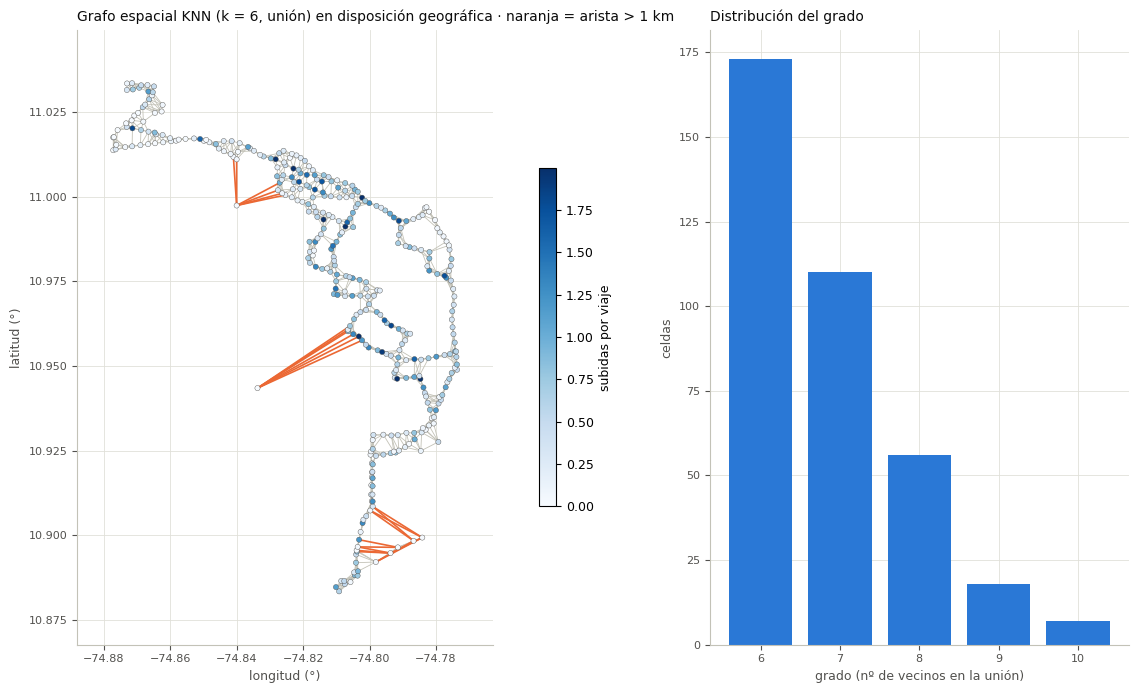

In [120]:
fig, ax = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2.2, 1]})
pos = {i: (d["longitud"], d["latitud"]) for i, d in G.nodes(data=True)}
largas = [(u, v) for u, v, d in G.edges(data=True) if d["distancia_m"] > 1000]
nx.draw_networkx_edges(G, pos, ax=ax[0], edgelist=[e for e in G.edges() if e not in set(largas)], edge_color="#c3c2b7", width=0.6)
nx.draw_networkx_edges(G, pos, ax=ax[0], edgelist=largas, edge_color=et.COLOR_RUTA[16], width=1.2)
nodos = nx.draw_networkx_nodes(G, pos, ax=ax[0], node_size=14, node_color=[d["subidas_por_viaje"] for _, d in G.nodes(data=True)],
                               cmap="Blues", vmin=0, vmax=celdas.subidas_por_viaje.quantile(.98), edgecolors=et.INK2, linewidths=0.3)
fig.colorbar(nodos, ax=ax[0], shrink=0.55, label="subidas por viaje")
ax[0].set_aspect(ASPECTO); ax[0].tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
et.estilo_ejes(ax[0], f"Grafo espacial KNN (k = {K}, unión) en disposición geográfica · naranja = arista > 1 km", "longitud (°)", "latitud (°)")
vc = grado.value_counts().sort_index()
ax[1].bar(vc.index, vc.values, color=et.COLOR_RUTA[2], width=0.8)
et.estilo_ejes(ax[1], "Distribución del grado", "grado (nº de vecinos en la unión)", "celdas")
plt.tight_layout(); guardar(fig, "m4_grafo_espacial")

**Conclusión 4.4 · Un solo componente, que sigue los corredores**
- 364 nodos y 1.244 aristas (densidad 0,019). **1 componente conexo, 0 aislados**. El grado va de 6 a 10 (media 6,8): KNN garantiza al menos k vecinos y la unión añade los que te eligen a ti.
- **Clustering medio de 0,60** y **diámetro de 53 saltos** (camino medio de 16,6): es un grafo "largo" y local, como corresponde a celdas sobre vías. No es una red de mundo pequeño.
- La arista mediana mide 350 m (p95 = 645 m). **24 aristas superan 1 km.** Salen de unos pocos puntos apartados del corredor (desvíos o puntos de maniobra con ~0 subidas y 31 viajes). KNN los obliga a tener 6 vecinos aunque estén lejos. Es una limitación conocida de KNN frente a un umbral de distancia.
- Las celdas de grado 10 (p99) son cruces donde convergen 2–3 rutas. Allí el rezago espacial mezcla corredores distintos.

# Módulo 5 · Multicolinealidad

## 5.1 Roles de las columnas de la maestra
Antes de medir redundancia se separa lo que **no** es predictor: el objetivo, sus derivados exactos, identificadores, marcas de tiempo y las mediciones que solo existen **al cerrar el viaje** (riesgo de leakage si se pronostica en el momento de la salida).

In [121]:
ROLES = {
    "idprogramacion": ("identificador", "no", "—"), "idvehiculo": ("identificador", "sí (asignación)", "bajo"),
    "idruta": ("categórica", "sí", "—"), "fechasalida": ("marca temporal (programada)", "sí", "—"),
    "fechainicio": ("marca temporal (real)", "no", "alto"), "fechafin": ("marca temporal (real)", "no", "alto"),
    "fecha": ("marca temporal", "sí", "—"), "anio_mes": ("marca temporal", "sí", "—"), "hora": ("calendario", "sí", "—"),
    "dia_semana": ("calendario", "sí", "—"), "tipo_dia": ("calendario (sin festivos)", "sí", "—"),
    "cancelada": ("constante en la maestra", "—", "—"), "finalizado": ("constante en la maestra", "—", "—"),
    "duracion_min": ("operación post-viaje", "no", "alto"), "retraso_salida_min": ("operación al iniciar", "no (se conoce al arrancar)", "medio"),
    "puntualidad": ("categórica post-salida", "no", "medio"), "flag_duracion_atipica": ("bandera post-viaje", "no", "alto"),
    "distancia_recorrida": ("operación post-viaje", "no", "alto"), "razon_distancia": ("derivada post-viaje", "no", "alto"),
    "numeropasajeros": ("OBJETIVO (imputado sin leakage)", "no", "es el objetivo"),
    "numeropasajeros_raw": ("objetivo crudo", "no", "copia del objetivo"),
    "pasajeros_imputado": ("bandera de calidad del objetivo", "no", "alto"), "metodo_imputacion": ("bandera de calidad del objetivo", "no", "alto"),
    "numerobajadas": ("sensor post-viaje", "no", "alto"), "numerobloqueos": ("sensor post-viaje", "no", "alto"),
    "cantidad_subida_puerta1": ("sensor: componente del objetivo", "no", "copia del objetivo"),
    "cantidad_subida_puerta2": ("sensor: componente del objetivo", "no", "copia del objetivo"),
    "cantidad_bajada_puerta1": ("sensor post-viaje", "no", "alto"), "cantidad_bajada_puerta2": ("sensor post-viaje", "no", "alto"),
    "balance_final": ("derivada exacta de puertas", "no", "alto"), "capacidad": ("flota (bus asignado)", "sí (si se conoce la asignación)", "bajo"),
    "modelo": ("categórica de flota", "sí (si se conoce la asignación)", "bajo"), "tipo_sensor": ("categórica de flota", "sí", "bajo"),
    "recaudo_esperado": ("derivada exacta del objetivo (× 3.700)", "no", "copia del objetivo"),
    "tarifa_aplicada_cop": ("constante", "—", "—"), "tipo_cero": ("diagnóstico del objetivo", "no", "alto"),
}
roles = pd.DataFrame([(c, *ROLES.get(c, ("bandera de calidad del sensor", "no", "alto"))) for c in maestra.columns],
                     columns=["columna", "rol", "conocida_antes_de_la_salida", "riesgo_leakage"])
assert set(roles.columna) == set(maestra.columns)
display(roles)

,columna,rol,conocida_antes_de_la_salida,riesgo_leakage
0,idprogramacion,identificador,no,—
1,idvehiculo,identificador,sí (asignación),bajo
2,idruta,categórica,sí,—
3,fechasalida,marca temporal (programada),sí,—
4,fechainicio,marca temporal (real),no,alto
5,fechafin,marca temporal (real),no,alto
6,cancelada,constante en la maestra,—,—
7,finalizado,constante en la maestra,—,—
8,fecha,marca temporal,sí,—
9,anio_mes,marca temporal,sí,—


## 5.2 Correlaciones a nivel viaje (maestra)
Se usa **Spearman** como medida principal: los conteos de sensor tienen colas extremas (p. ej. `numerobloqueos` llega a 1,6 millones), que distorsionan Pearson. Pearson se reporta al lado. Antes se comprueban las relaciones exactas que la 1.3 y la 1.4 construyeron por definición.

In [122]:
NUM_VIAJE = ["numeropasajeros", "numeropasajeros_raw", "recaudo_esperado", "cantidad_subida_puerta1", "cantidad_subida_puerta2",
             "numerobajadas", "cantidad_bajada_puerta1", "cantidad_bajada_puerta2", "balance_final", "numerobloqueos",
             "duracion_min", "retraso_salida_min", "distancia_recorrida", "razon_distancia", "capacidad", "hora", "dia_semana"]
Xv = maestra[NUM_VIAJE].astype(float)
diag_v = et.diagnostico_columnas(maestra[NUM_VIAJE + ["tarifa_aplicada_cop"]].astype(float))
display(diag_v.round(3))
cc = Xv.dropna()
rel = pd.Series({
    "recaudo_esperado − 3700·numeropasajeros (máx |dif|)": float((cc.recaudo_esperado - 3700 * cc.numeropasajeros).abs().max()),
    "balance_final − (sub_p1 + sub_p2 − baj_p1 − baj_p2) (máx |dif|)": float((cc.balance_final - (cc.cantidad_subida_puerta1 + cc.cantidad_subida_puerta2
                                                                              - cc.cantidad_bajada_puerta1 - cc.cantidad_bajada_puerta2)).abs().max()),
    "% viajes con numeropasajeros = raw": 100 * float((cc.numeropasajeros == cc.numeropasajeros_raw).mean()),
    "% viajes con raw = sub_p1 + sub_p2": 100 * float((cc.numeropasajeros_raw == cc.cantidad_subida_puerta1 + cc.cantidad_subida_puerta2).mean()),
    "filas completas usadas": len(cc),
}).to_frame("valor")
display(rel.round(4))
corr_v_s = Xv.corr("spearman"); corr_v_p = Xv.corr("pearson")
fuertes_v = et.pares_fuertes(corr_v_s, cfg.corr_umbral).merge(
    corr_v_p.where(np.triu(np.ones(corr_v_p.shape, bool), 1)).stack().rename("pearson").reset_index().rename(columns={"level_0": "var_a", "level_1": "var_b"}),
    on=["var_a", "var_b"], how="left").rename(columns={"rho": "spearman"})
display(fuertes_v.round(3))

,nulos,pct_nulos,varianza,distintos,pct_moda,constante,casi_constante
numeropasajeros,0,0.000,1.2524e+03,256,1.094,False,False
numeropasajeros_raw,791,0.159,2.1914e+04,277,1.091,False,False
recaudo_esperado,0,0.000,1.7145e+10,256,1.094,False,False
cantidad_subida_puerta1,798,0.160,1.2234e+03,258,1.095,False,False
cantidad_subida_puerta2,798,0.160,8.1970e+05,75,75.152,False,False
numerobajadas,791,0.159,7.8570e+06,293,1.146,False,False
cantidad_bajada_puerta1,798,0.160,5.4420e+00,117,72.408,False,False
cantidad_bajada_puerta2,798,0.160,3.3315e+06,283,1.141,False,False
balance_final,0,0.000,4.1436e+06,306,8.628,False,False
numerobloqueos,791,0.159,3.0191e+07,1880,69.539,False,False


,valor
recaudo_esperado − 3700·numeropasajeros (máx |dif|),0.0000
balance_final − (sub_p1 + sub_p2 − baj_p1 − baj_p2) (máx |dif|),0.0000
% viajes con numeropasajeros = raw,99.9452
% viajes con raw = sub_p1 + sub_p2,99.3491
filas completas usadas,496573.0000


,var_a,var_b,spearman,pearson
0,numeropasajeros,recaudo_esperado,1.000,1.000
1,numeropasajeros,numeropasajeros_raw,0.999,0.239
2,numeropasajeros_raw,recaudo_esperado,0.999,0.239
3,numeropasajeros_raw,cantidad_subida_puerta1,0.999,0.237
4,numeropasajeros,cantidad_subida_puerta1,0.999,0.997
5,recaudo_esperado,cantidad_subida_puerta1,0.999,0.997
6,numerobajadas,cantidad_bajada_puerta2,0.998,0.908
7,numeropasajeros_raw,numerobajadas,0.976,0.137
8,cantidad_subida_puerta1,numerobajadas,0.975,0.010
9,recaudo_esperado,numerobajadas,0.975,0.010


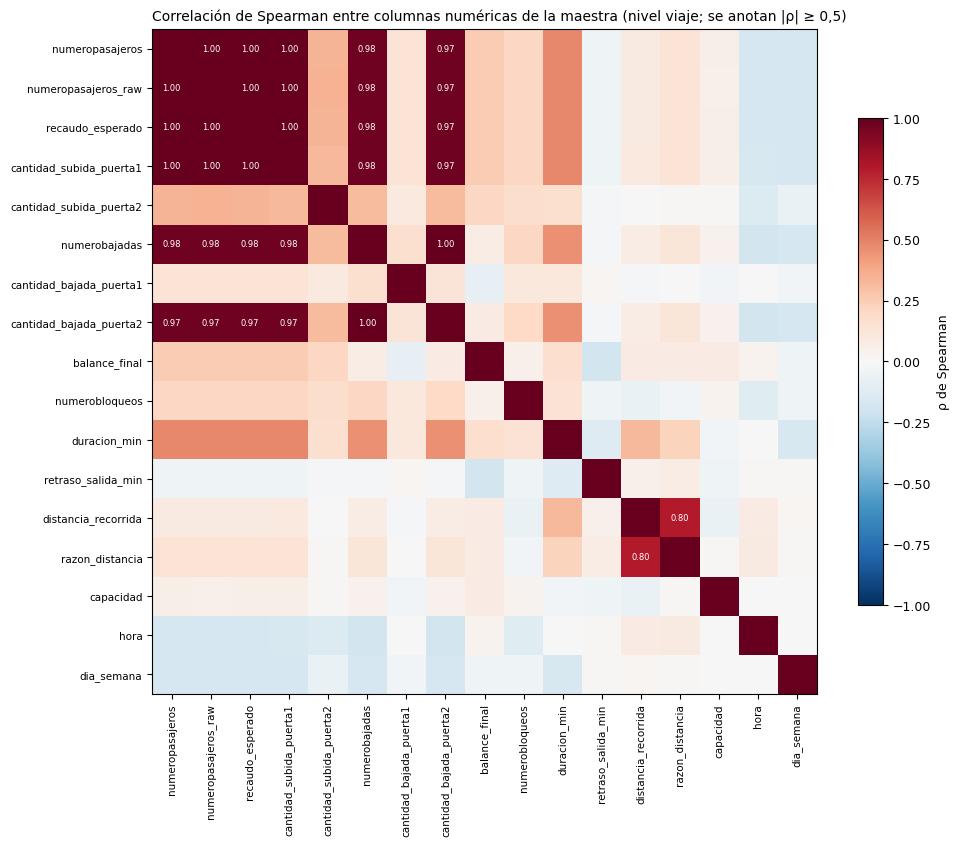

In [123]:
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr_v_s.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_VIAJE))); ax.set_xticklabels(NUM_VIAJE, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(NUM_VIAJE))); ax.set_yticklabels(NUM_VIAJE, fontsize=7.5)
for i in range(len(NUM_VIAJE)):
    for j in range(len(NUM_VIAJE)):
        v = corr_v_s.values[i, j]
        if abs(v) >= 0.5 and i != j:
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.75 else et.INK)
fig.colorbar(im, ax=ax, shrink=0.7, label="ρ de Spearman")
ax.set_title("Correlación de Spearman entre columnas numéricas de la maestra (nivel viaje; se anotan |ρ| ≥ 0,5)", fontsize=10, loc="left")
plt.tight_layout(); guardar(fig, "m5_correlacion_viaje_spearman")

## 5.3 VIF a nivel viaje (variables operativas)
Conjunto de diagnóstico: variables operativas no derivadas del objetivo, más `hora` y dos indicadoras de ruta (base = ruta 2). `numerobloqueos` entra como `log1p` porque su cola extrema dominaría la regresión auxiliar. Ojo: casi todas son **post-viaje** (5.1). Se miden para saber si son redundantes entre sí, no para recomendarlas como predictores ex ante.

In [124]:
Xop = maestra[["duracion_min", "retraso_salida_min", "distancia_recorrida", "razon_distancia", "capacidad", "hora"]].astype(float).copy()
Xop["log1p_bloqueos"] = np.log1p(maestra.numerobloqueos.astype(float))
Xop["ruta_16"] = (maestra.idruta == 16).astype(float); Xop["ruta_21"] = (maestra.idruta == 21).astype(float)
Xop = Xop.dropna()
print(f"Filas completas: {len(Xop):,} de {len(maestra):,}")
display(et.diagnostico_columnas(Xop).round(3))
print("Matriz de diseño:", et.dependencias_exactas(Xop))
vif_viaje = et.vif_tabla(Xop, cfg)
display(vif_viaje.round(3))

Filas completas: 496,580 de 497,371


,nulos,pct_nulos,varianza,distintos,pct_moda,constante,casi_constante
duracion_min,0,0.0,27749.980,25567,0.075,False,False
retraso_salida_min,0,0.0,47.497,2656,0.218,False,False
distancia_recorrida,0,0.0,44.897,651,3.628,False,False
razon_distancia,0,0.0,0.012,1644,3.509,False,False
capacidad,0,0.0,50.673,27,27.630,False,False
hora,0,0.0,21.684,17,11.206,False,False
log1p_bloqueos,0,0.0,2.041,1880,69.650,False,False
ruta_16,0,0.0,0.248,2,54.522,False,False
ruta_21,0,0.0,0.145,2,82.391,False,False


Matriz de diseño: {'columnas_con_constante': 10, 'rango': 10, 'numero_condicion': 52.06770468096002}


,variable,VIF,R2_auxiliar,lectura
0,distancia_recorrida,508.153,0.998,alta (≥ 10)
1,razon_distancia,471.513,0.998,alta (≥ 10)
2,ruta_16,133.052,0.992,alta (≥ 10)
3,ruta_21,67.113,0.985,alta (≥ 10)
4,retraso_salida_min,1.293,0.227,baja (< 5)
5,hora,1.059,0.056,baja (< 5)
6,duracion_min,1.030,0.030,baja (< 5)
7,log1p_bloqueos,1.024,0.024,baja (< 5)
8,capacidad,1.008,0.007,baja (< 5)


**Conclusión 5.3 · A nivel viaje la redundancia es de construcción, no de comportamiento**
- **Relaciones exactas confirmadas:**
  - `recaudo_esperado` = 3.700 × `numeropasajeros` (diferencia máxima 0).
  - `balance_final` = subidas − bajadas por puerta (diferencia 0).
  - `numeropasajeros` = `numeropasajeros_raw` en el 99,95 % de los viajes, y `raw` = subidas P1 + P2 en el 99,35 %.

  Son **copias del objetivo**: ninguna puede ser predictora.
- **Spearman frente a Pearson:** `numeropasajeros` vs `raw` da ρ = 0,999 pero r = 0,24. Los 123 picos imposibles de la 1.3 bastan para destruir la correlación lineal. Por eso se usa Spearman.
- **`numerobajadas` ~ objetivo (ρ = 0,975)**: es la otra cara del mismo viaje y solo se conoce al cerrarlo, así que hay leakage.
- **VIF:** `distancia_recorrida` y `razon_distancia` superan 470 (R² auxiliar = 0,998). `razon_distancia` es la distancia dividida por la distancia oficial de la ruta, por lo que junto a las indicadoras de ruta es casi una recombinación lineal. Esto infla también las indicadoras (VIF de 67 y 133). **Basta con una de las dos.** Las demás (duración, retraso, capacidad, hora, bloqueos) tienen VIF ≤ 1,3.

## 5.4 VIF en el panel ruta × 15 min (nivel del modelo)
Variables candidatas que **sí se conocen antes de cada intervalo**: oferta programada (`despachos` de `tb_despachos`, `capacidad_ofrecida`), calendario codificado (hora en seno/coseno, día de la semana en 6 indicadoras con base lunes, festivo, Carnaval, mes en seno/coseno, tendencia) y ruta. Se incluye `es_fin_semana` a propósito para mostrar cómo se detecta una dependencia lineal exacta.

Los rezagos `y(t-1)`, `y(t-4)`, `y(t-96)`, `y(t-672)` se calculan **aquí solo como diagnóstico**, sin exportarlos: su construcción definitiva y sin leakage es de la Persona 3.

In [125]:
pan = serie[["idruta", "t", "fecha", "intervalo_dia", "pasajeros", "viajes"]].merge(
    cal[["fecha", "dia_semana", "es_festivo", "es_carnaval", "es_fin_semana"]], on="fecha", how="left")
desp15 = despachos.assign(t=despachos.fechasalida.dt.floor(cfg.freq)).groupby(["idruta", "t"]).size().rename("despachos")
cap15 = maestra.assign(t=maestra.fechasalida.dt.floor(cfg.freq)).groupby(["idruta", "t"]).capacidad.sum().rename("capacidad_ofrecida")
pan = pan.join(desp15, on=["idruta", "t"]).join(cap15, on=["idruta", "t"])
pan[["despachos", "capacidad_ofrecida"]] = pan[["despachos", "capacidad_ofrecida"]].fillna(0)
ang = 2 * np.pi * pan.intervalo_dia / 96
pan["hora_sin"], pan["hora_cos"] = np.sin(ang), np.cos(ang)
angm = 2 * np.pi * (pan.t.dt.month - 1) / 12
pan["mes_sin"], pan["mes_cos"] = np.sin(angm), np.cos(angm)
pan["tendencia_dias"] = (pan.fecha - pan.fecha.min()).dt.days.astype(float)
for d, nom in zip(range(1, 7), ["mar", "mie", "jue", "vie", "sab", "dom"]):
    pan[f"dow_{nom}"] = (pan.dia_semana == d).astype(float)
pan["ruta_16"], pan["ruta_21"] = (pan.idruta == 16).astype(float), (pan.idruta == 21).astype(float)
for c in ["es_festivo", "es_carnaval", "es_fin_semana"]:
    pan[c] = pan[c].astype(float)
pan = pan.sort_values(["idruta", "t"])
for L in LAGS:
    pan[f"y_lag{L}"] = pan.groupby("idruta").pasajeros.shift(L)   # SOLO diagnóstico (no se exporta)

BASE = ["despachos", "capacidad_ofrecida", "hora_sin", "hora_cos", "dow_mar", "dow_mie", "dow_jue", "dow_vie", "dow_sab", "dow_dom",
        "es_festivo", "es_carnaval", "mes_sin", "mes_cos", "tendencia_dias", "ruta_16", "ruta_21"]
display(et.diagnostico_columnas(pan[BASE + ["es_fin_semana"]]).round(4))
dep_con = et.dependencias_exactas(pan[BASE + ["es_fin_semana"]])
dep_sin = et.dependencias_exactas(pan[BASE])
print("Con es_fin_semana:", dep_con)
print("Sin es_fin_semana:", dep_sin)
assert dep_con["rango"] < dep_con["columnas_con_constante"] and dep_sin["rango"] == dep_sin["columnas_con_constante"]
print("→ es_fin_semana = dow_sab + dow_dom exactamente: se excluye (la información queda en las indicadoras).")

,nulos,pct_nulos,varianza,distintos,pct_moda,constante,casi_constante
despachos,0,0.0,3.6175,16,34.9468,False,False
capacidad_ofrecida,0,0.0,8675.1645,579,37.6603,False,False
hora_sin,0,0.0,0.5000,86,2.0833,False,False
hora_cos,0,0.0,0.5000,89,2.0833,False,False
dow_mar,0,0.0,0.1227,2,85.6752,False,False
dow_mie,0,0.0,0.1227,2,85.6752,False,False
dow_jue,0,0.0,0.1221,2,85.7664,False,False
dow_vie,0,0.0,0.1221,2,85.7664,False,False
dow_sab,0,0.0,0.1221,2,85.7664,False,False
dow_dom,0,0.0,0.1227,2,85.6752,False,False


Con es_fin_semana: {'columnas_con_constante': 19, 'rango': 18, 'numero_condicion': 152321813404598.28}
Sin es_fin_semana: {'columnas_con_constante': 18, 'rango': 18, 'numero_condicion': 8.356579201590467}
→ es_fin_semana = dow_sab + dow_dom exactamente: se excluye (la información queda en las indicadoras).


In [126]:
vif_panel = et.vif_tabla(pan[BASE], cfg).assign(conjunto="A · calendario + oferta (todas las horas)")
servicio = pan.t.dt.hour.between(4, 20)
vif_serv = et.vif_tabla(pan.loc[servicio, BASE], cfg).assign(conjunto="A' · calendario + oferta (solo 4–20 h)")
pan_l = pan.dropna(subset=[f"y_lag{L}" for L in LAGS])
vif_lags = et.vif_tabla(pan_l[BASE + [f"y_lag{L}" for L in LAGS]], cfg).assign(conjunto="B · A + rezagos (diagnóstico)")
vif_todo = pd.concat([vif_panel, vif_serv, vif_lags], ignore_index=True)
display(vif_todo.pivot_table(index="variable", columns="conjunto", values="VIF").sort_values("B · A + rezagos (diagnóstico)", ascending=False).round(2))
COLS_CORR_P = ["pasajeros", "viajes", "despachos", "capacidad_ofrecida", "hora_sin", "hora_cos", "es_festivo", "tendencia_dias"] + [f"y_lag{L}" for L in LAGS]
corr_p_s = pan_l[COLS_CORR_P].corr("spearman")
display(et.pares_fuertes(corr_p_s, cfg.corr_umbral).round(3))

conjunto,A · calendario + oferta (todas las horas),A' · calendario + oferta (solo 4–20 h),B · A + rezagos (diagnóstico)
variable,,,
despachos,13.38,9.01,14.93
capacidad_ofrecida,13.29,9.17,13.77
y_lag1,NaN,NaN,4.66
y_lag672,NaN,NaN,4.08
y_lag96,NaN,NaN,3.56
y_lag4,NaN,NaN,2.99
dow_dom,1.86,1.89,2.14
dow_sab,1.84,1.84,2.01
dow_mie,1.83,1.83,1.95


,var_a,var_b,rho
0,viajes,capacidad_ofrecida,0.992
1,viajes,despachos,0.964
2,pasajeros,viajes,0.958
3,despachos,capacidad_ofrecida,0.957
4,pasajeros,capacidad_ofrecida,0.951
5,pasajeros,despachos,0.921
6,despachos,y_lag672,0.850
7,pasajeros,y_lag672,0.847
8,pasajeros,y_lag1,0.836
9,despachos,y_lag96,0.835


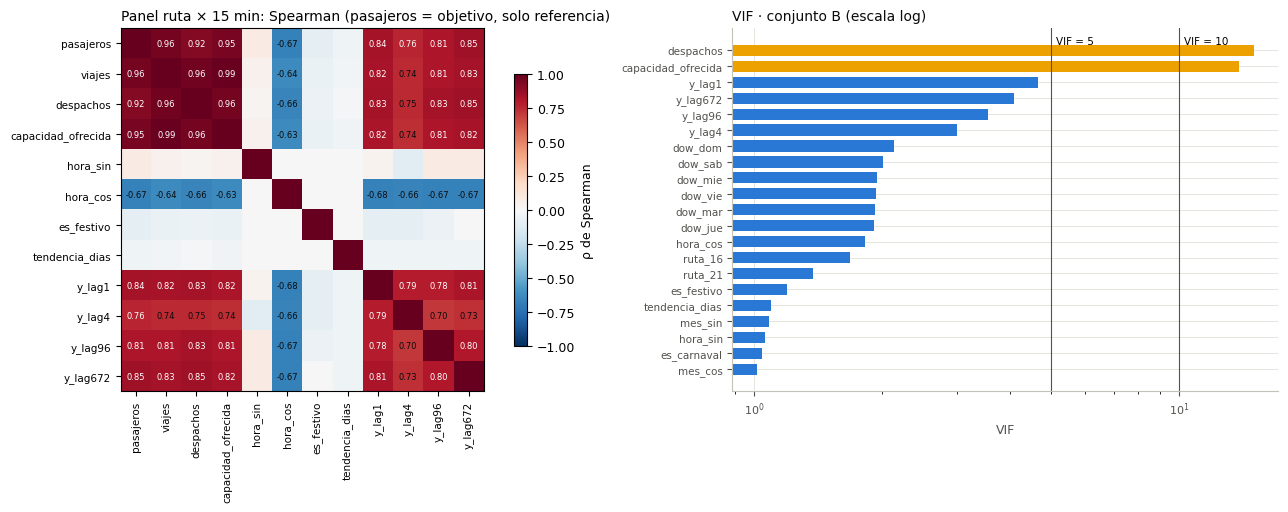

In [127]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
im = ax[0].imshow(corr_p_s.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(COLS_CORR_P))); ax[0].set_xticklabels(COLS_CORR_P, rotation=90, fontsize=7.5)
ax[0].set_yticks(range(len(COLS_CORR_P))); ax[0].set_yticklabels(COLS_CORR_P, fontsize=7.5)
for i in range(len(COLS_CORR_P)):
    for j in range(len(COLS_CORR_P)):
        if i != j and abs(corr_p_s.values[i, j]) >= 0.5:
            ax[0].text(j, i, f"{corr_p_s.values[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(corr_p_s.values[i, j]) > 0.75 else et.INK)
fig.colorbar(im, ax=ax[0], shrink=0.75, label="ρ de Spearman")
ax[0].set_title("Panel ruta × 15 min: Spearman (pasajeros = objetivo, solo referencia)", fontsize=10, loc="left")
vb = vif_lags.sort_values("VIF")
ax[1].barh(vb.variable, vb.VIF, color=[et.COLOR_DIA["festivo"] if v >= 10 else (et.COLOR_RUTA[16] if v >= 5 else et.COLOR_RUTA[2]) for v in vb.VIF], height=0.7)
for x, lbl in [(5, "5"), (10, "10")]:
    ax[1].axvline(x, color=et.INK2, lw=0.8); ax[1].annotate(f"VIF = {lbl}", (x, len(vb) - 0.6), xytext=(3, 0), textcoords="offset points", fontsize=7.5)
ax[1].set_xscale("log"); et.estilo_ejes(ax[1], "VIF · conjunto B (escala log)", "VIF", None); ax[1].tick_params(axis="y", labelsize=7.5)
plt.tight_layout(); guardar(fig, "m5_panel_correlacion_y_vif")

**Conclusión 5.4 · En el panel, la oferta es la única redundancia relevante**
- **Dependencia exacta detectada y resuelta:** `es_fin_semana` = `dow_sab` + `dow_dom`. Con ella el rango es 18 de 19 columnas (número de condición ≈ 1,5 × 10¹⁴). Sin ella, el rango es completo y el número de condición es 8,4.
- **`despachos` y `capacidad_ofrecida`: VIF ≈ 13** (≈ 9 si solo se toman las horas de servicio). Spearman entre ellas: 0,96. `viajes` y `capacidad_ofrecida`: 0,99. **Miden lo mismo** (cuántos buses salen). Conviene elegir una o combinarlas, por ejemplo como capacidad media por despacho.
- **Calendario sin problemas:** día de la semana, festivo, Carnaval, mes y tendencia tienen VIF ≤ 2,1. La codificación seno/coseno de la hora tiene VIF ≤ 1,8.
- **Rezagos (solo diagnóstico):** VIF de 3,0–4,7 junto al resto. Están correlacionados entre sí (ρ ≈ 0,80–0,81 de t-672 con t-1 y con t-96), pero **no son redundantes**. La PACF (3.5) muestra que t-1 y t-96 aportan información propia y t-4 poca.
- **Aviso de leakage:** `pasajeros` vs `viajes` válidos da ρ = 0,96, y vs `capacidad_ofrecida` 0,95. Pero `viajes` y `capacidad_ofrecida` se construyen con los viajes **válidos**, una condición que solo se conoce después del viaje. La versión ex ante es `despachos` programados.

## 5.5 Recomendaciones para la Persona 3
| Tema | Recomendación | Estado |
|---|---|---|
| **Copias del objetivo** | Excluir `numeropasajeros_raw`, `recaudo_esperado`, `cantidad_subida_puerta1/2` y `tipo_cero` | Cerrado: leakage directo |
| **Variables post-viaje** | `numerobajadas`, bajadas por puerta, `balance_final`, `numerobloqueos`, `duracion_min`, `distancia_recorrida`, `razon_distancia`, `fechainicio`/`fechafin` y banderas de sensor **no se conocen al despachar**. Solo sirven como rezagos de viajes ya cerrados | Cerrado si el pronóstico es ex ante |
| **Oferta** | Usar `despachos` programados (ex ante), no `viajes` válidos. Elegir entre `despachos` y `capacidad_ofrecida` (VIF ≈ 13), o combinarlas | Abierto: decidir con validación temporal |
| **Distancia** | Si se usa a nivel viaje, quedarse con `distancia_recorrida` **o** `razon_distancia`, no ambas | Abierto |
| **Calendario** | Usar `calendario_dias.csv`: festivo y Carnaval como indicadoras separadas, sin `es_fin_semana` junto a las indicadoras de día. Revisar la imputación de la 1.4, que no distingue festivos | Listo para usar |
| **Rezagos temporales** | Priorizar t-1 y t-96, más t-672. t-4 aporta poco una vez está t-1. Construirlos **dentro** de cada pliegue walk-forward | Abierto (Persona 3) |
| **Rezagos espaciales** | Hay estructura espacial (I = 0,18 con k = 6), pero solo en la muestra de lecturas. El objetivo por ruta × 15 min no tiene dimensión espacial. Un rezago espacial solo aplica si se modela a nivel de celda o tramo, con `W_knn_k6_binaria.npz` y `parametros_malla_espacial.json` | Abierto |
| **Escala del VIF** | Los umbrales 5 y 10 son referencias, no reglas. No eliminar por VIF sin comparar el error de pronóstico en validación temporal | Abierto |
| **Días a vigilar** | 2024-09-06 (anómalo) y junio de 2024 (apagón imputado en la 1.4): marcarlos en la evaluación | Aviso |

# Síntesis de hallazgos
| Módulo | Hallazgo | Evidencia |
|---|---|---|
| 3 | La serie por viaje es irregular; la de 15 min es completa y conserva todo | 3 × 105.216 intervalos, sumas idénticas a la maestra |
| 3 | Sin raíz unitaria; estacionaria alrededor de una tendencia suave + ciclos | ADF entre −14 y −18 (15 min) y entre −3,0 y −5,4 (diaria); KPSS rechaza con `c` y no con `ct` |
| 3 | Memoria a 15 min y a 24 h; t-4 casi redundante | ACF t-1 de 0,58–0,87 y t-96 de 0,59–0,76; PACF t-4 de 0,01–0,10 |
| 3 | El pico de las 5 h es un efecto de atribución a la salida | Hora real de subida: picos a las 6–7 h y 16–17 h |
| 3 | Un festivo entre semana mueve ≈ 0,4 de un laboral y desplaza el pico a la tarde | Wilcoxon emparejado (48 pares por ruta), W = 0 |
| 4 | Las subidas se agrupan en el espacio a escala de 2–3 km | Moran I = 0,18 (k = 6), p = 0,001; positivo para todo k y celda |
| 4 | Grafo conexo, local y alargado (corredores) | 1 componente, diámetro 53, clustering 0,60 |
| 5 | Redundancias por construcción y leakage, no colinealidad sutil | Relaciones exactas; VIF de oferta ≈ 13; calendario ≤ 2,1 |

# Exportación para la Persona 3
Todo va a `datos_3_5/`. Estructura, claves, unidades y uso de cada archivo: `datos_3_5/LEEME_artefactos.md`.

In [128]:
cal.to_csv(SALIDA / "calendario_dias.csv", index=False)
serie.drop(columns="pasajeros_desest").to_parquet(SALIDA / "serie_15min_ruta.parquet", index=False)
aud_t.to_csv(SALIDA / "auditoria_temporal.csv", index=False)
adf.to_csv(SALIDA / "adf_kpss.csv", index=False)
acf_tab.to_csv(SALIDA / "acf_pacf_rezagos.csv", index=False)
pd.DataFrame([{"idruta": r, "serie": s, "h": h, "acf": a[h], "banda_bartlett_95": b[h], "pacf": p[h] if h < len(p) else np.nan,
               "banda_ruido_blanco_95": bl} for (r, s), (a, p, b, bl) in curvas.items() for h in range(len(a))]
             ).to_csv(SALIDA / "acf_pacf_curvas.csv", index=False)
perfil.to_csv(SALIDA / "perfil_horario.csv", index=False)
picos.to_csv(SALIDA / "picos_valles.csv", index=False)
pd.concat([kw.assign(prueba="kruskal_wallis"), pares.assign(prueba="mann_whitney_holm")], ignore_index=True).to_csv(SALIDA / "contrastes_tipo_dia.csv", index=False)
emp.to_csv(SALIDA / "festivo_emparejado_detalle.csv", index=False)
wil.to_csv(SALIDA / "festivo_emparejado_wilcoxon.csv", index=False)
forma.to_csv(SALIDA / "forma_horaria_laboral_vs_festivo.csv", index=False)

celdas.to_csv(SALIDA / "celdas_espaciales.csv", index=False)
pd.Series({"celda_m": cfg.celda_m, "lat_ref": LAT_REF, "radio_tierra_m": et.RADIO_TIERRA_M, "min_viajes_celda": cfg.min_viajes_celda,
           "k": K, "regla_celda": "cx = floor(rad(lon)·R·cos(rad(lat_ref)) / celda_m); cy = floor(rad(lat)·R / celda_m)"}
          ).to_json(SALIDA / "parametros_malla_espacial.json", force_ascii=False, indent=2)
sparse.save_npz(SALIDA / f"W_knn_k{K}_binaria.npz", A)
ids = celdas.celda_id.to_numpy()
pd.DataFrame({"origen": ids[np.repeat(np.arange(n), K)], "destino": ids[IDX.ravel()], "orden_vecino": np.tile(np.arange(1, K + 1), n),
              "distancia_m": DIST.ravel(), "peso_binario": 1.0, "peso_fila": 1.0 / K,
              "mutua": np.asarray(A.multiply(A.T)[np.repeat(np.arange(n), K), IDX.ravel()]).ravel().astype(bool)}
             ).to_csv(SALIDA / f"vecinos_knn_k{K}.csv", index=False)
eval_k.to_csv(SALIDA / "moran_evaluacion_k.csv", index=False)
correlo.to_csv(SALIDA / "moran_correlograma.csv", index=False)
sens.to_csv(SALIDA / "moran_sensibilidad.csv", index=False)
nx.write_graphml(G, SALIDA / f"grafo_espacial_k{K}.graphml")
met_G.to_csv(SALIDA / "metricas_grafo.csv")

roles.to_csv(SALIDA / "roles_variables_maestra.csv", index=False)
corr_v_s.to_csv(SALIDA / "correlacion_viaje_spearman.csv"); corr_v_p.to_csv(SALIDA / "correlacion_viaje_pearson.csv")
fuertes_v.to_csv(SALIDA / "pares_fuertes_viaje.csv", index=False)
vif_viaje.to_csv(SALIDA / "vif_viaje.csv", index=False)
vif_todo.to_csv(SALIDA / "vif_panel.csv", index=False)
corr_p_s.to_csv(SALIDA / "correlacion_panel_spearman.csv")
for p in sorted(SALIDA.glob("*.*")):
    print(f"{p.name:45s} {p.stat().st_size / 1e3:10.1f} kB")

acf_pacf_curvas.csv                                366.4 kB
acf_pacf_rezagos.csv                                 2.9 kB
adf_kpss.csv                                         3.9 kB
auditoria_temporal.csv                               0.6 kB
calendario_dias.csv                                 66.3 kB
celdas_espaciales.csv                               50.8 kB
contrastes_tipo_dia.csv                              2.9 kB
correlacion_panel_spearman.csv                       2.8 kB
correlacion_viaje_pearson.csv                        6.4 kB
correlacion_viaje_spearman.csv                       6.1 kB
festivo_emparejado_detalle.csv                      10.0 kB
festivo_emparejado_wilcoxon.csv                      0.4 kB
forma_horaria_laboral_vs_festivo.csv                 5.0 kB
grafo_espacial_k6.graphml                          251.3 kB
LEEME_artefactos.md                                  7.0 kB
metricas_grafo.csv                                   0.5 kB
moran_correlograma.csv                  

# Comprobaciones finales de reproducibilidad

In [129]:
chk = []
def ok(nombre, cond, detalle=""):
    chk.append({"check": nombre, "resultado": "PASS" if bool(cond) else "FAIL", "detalle": detalle})

s2 = pd.read_parquet(SALIDA / "serie_15min_ruta.parquet")
ok("Serie: 3 rutas × intervalos esperados", (s2.groupby("idruta").size() == n_int).all() and s2.idruta.nunique() == 3, f"{n_int:,} por ruta")
ok("Serie: conserva pasajeros y viajes de la maestra", s2.pasajeros.sum() == maestra.numeropasajeros.sum() and s2.viajes.sum() == len(maestra))
ok("Serie: sin nulos ni negativos", s2[["pasajeros", "viajes"]].notna().all().all() and (s2[["pasajeros", "viajes"]] >= 0).all().all())
c2 = pd.read_csv(SALIDA / "calendario_dias.csv", parse_dates=["fecha"])
ok("Calendario: 1 fila por día de la ventana", len(c2) == 1096 and c2.fecha.is_unique, f"{len(c2)} días")
ok("Calendario: 4 días de Carnaval por año", c2.groupby(c2.fecha.dt.year).es_carnaval.sum().eq(4).all())
ok("Calendario: festivos ≠ fines de semana como categoría", not ((c2.tipo_dia_cal == "festivo") & ~c2.es_festivo).any())
a2 = pd.read_csv(SALIDA / "adf_kpss.csv")
ok("ADF: 15 pruebas sin nulos", len(a2) == 15 and a2[["estadistico", "p_valor", "nobs_usadas"]].notna().all().all())
r2 = pd.read_csv(SALIDA / "acf_pacf_rezagos.csv")
ok("ACF/PACF: t-1, t-4, t-96 en las 3 rutas", set(r2.rezago) >= {"t-1", "t-4", "t-96"} and r2.groupby("serie").idruta.nunique().eq(3).all())
A2 = sparse.load_npz(SALIDA / f"W_knn_k{K}_binaria.npz")
ok("W: cuadrada n × n con n = celdas", A2.shape == (len(celdas), len(celdas)), str(A2.shape))
ok("W: diagonal nula", A2.diagonal().sum() == 0)
ok("W: exactamente k vecinos por fila", (np.asarray(A2.sum(1)).ravel() == K).all(), f"k = {K}")
ok("W: estandarizada por filas suma 1", np.allclose(np.asarray(et.estandarizar_filas(A2).sum(1)).ravel(), 1))
G2 = nx.read_graphml(SALIDA / f"grafo_espacial_k{K}.graphml")
ok("Grafo: nodos = celdas y aristas = unión", G2.number_of_nodes() == len(celdas) and G2.number_of_edges() == U.nnz // 2,
   f"{G2.number_of_nodes()} nodos, {G2.number_of_edges()} aristas")
ok("Grafo: componentes = conectividad de la matriz", nx.number_connected_components(G2) == et.conectividad(U)["componentes"])
mk = pd.read_csv(SALIDA / "moran_evaluacion_k.csv")
ok("Moran: I recalculado con la W exportada coincide", np.isclose(et.moran_global(celdas.subidas_por_viaje.values, et.estandarizar_filas(A2), 9, 1)["I"],
                                                                   mk.loc[mk.k == K, "I"].iloc[0]))
ok("Moran: permutaciones y semilla documentadas", mk.permutaciones.eq(cfg.permutaciones).all() and mk.semilla.eq(cfg.semilla).all())
v2 = pd.read_csv(SALIDA / "vif_panel.csv")
ok("VIF: finitos en todos los conjuntos", np.isfinite(v2.VIF).all(), f"máx = {v2.VIF.max():.1f}")
ok("VIF: no se exportan rezagos como variables", not any(c.startswith("y_lag") for c in s2.columns))
HUELLAS_FIN = {str(p): huella(p) for p in INSUMOS}
ok("Insumos de la Persona 1 sin modificar", HUELLAS_INICIO == HUELLAS_FIN, f"{len(HUELLAS_FIN)} archivos con el mismo MD5")
ok("LEEME de artefactos presente", (SALIDA / "LEEME_artefactos.md").exists())
val35 = pd.DataFrame(chk)
val35.to_csv(SALIDA / "validacion_modulo3_5.csv", index=False)
display(val35)
print("MÓDULOS 3–5 VALIDADOS" if (val35.resultado == "PASS").all() else f"Hay {(val35.resultado == 'FAIL').sum()} checks en FAIL")

,check,resultado,detalle
0,Serie: 3 rutas × intervalos esperados,PASS,"105,216 por ruta"
1,Serie: conserva pasajeros y viajes de la maestra,PASS,
2,Serie: sin nulos ni negativos,PASS,
3,Calendario: 1 fila por día de la ventana,PASS,1096 días
4,Calendario: 4 días de Carnaval por año,PASS,
5,Calendario: festivos ≠ fines de semana como ca...,PASS,
6,ADF: 15 pruebas sin nulos,PASS,
7,"ACF/PACF: t-1, t-4, t-96 en las 3 rutas",PASS,
8,W: cuadrada n × n con n = celdas,PASS,"(364, 364)"
9,W: diagonal nula,PASS,


MÓDULOS 3–5 VALIDADOS


---
# Parte 10 · Subfase 6.0 · Decisiones del Módulo 6
*Notebook original: `subfase_6_0_decisiones.ipynb`*

In [130]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_6_0_decisiones.ipynb")

── Inicio de subfase_6_0_decisiones.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 6.0 — Decisiones previas al Módulo 6

**Persona 3 · MLOps & Model Evaluation.** Antes de construir features hay que fijar qué se predice, cuándo se emite el pronóstico, qué rezagos son admisibles y qué se corrige de los Módulos 1–5. Esta subfase **no construye features ni entrena modelos**: produce decisiones con cifras, una matriz espacial entre rutas y una tabla de checks.

| Paso | Pregunta |
|---|---|
| 0 | ¿Qué datos quedan congelados como holdout? |
| 1 | ¿Qué entorno hay? |
| 2 | ¿Cuándo se emite el pronóstico y qué rezago mínimo es admisible? |
| 3 | ¿El target es por viaje o ruta × 15 min? |
| 4 | ¿Qué rezagos se permiten? (corrección de la Conclusión 3.5) |
| 5 | ¿Qué W espacial se puede construir con lo que ya hay? |
| 6 | Reglas de datos para la 6.1 y el Módulo 7 |
| 7 | Checks de cierre |

**Parte 1 (extracción RDS):** una sola consulta liviana, `extraer_fecharegistro_6_0.py` (solo `progvehiculos`: `idprogramacion`, `idruta`, `fechasalida`, `fecharegistro`). Pide la contraseña con `getpass` y escribe `datos_6/fecharegistro.csv`; si el archivo ya existe, no consulta. De `conteo_pasajeros_destino` solo se usa lo ya derivado de la muestra (`celdas_espaciales.csv`).

**Insumos:** `datos_6/fecharegistro.csv` (Parte 1), `maestras/tb_maestra_entrenamiento.parquet`, `maestras/tb_despachos.parquet`, `datos_1_2/viajes_raw.csv`, `metricas_tweedie.py` y, de la Persona 2, `serie_15min_ruta.parquet`, `calendario_dias.csv`, `celdas_espaciales.csv`. **Salidas:** `datos_6/`.

## Parte 2 · Análisis offline

In [131]:
import importlib
import math
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)

P2 = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5")
SALIDA = Path("datos_6"); SALIDA.mkdir(exist_ok=True)
TRAIN_FIN = pd.Timestamp("2025-01-01")   # 2025 = holdout final (coherente con la 2.4)
SEMILLA = 42
INTERVALO = 15                           # minutos por intervalo de la serie
RUTAS = [2, 16, 21]
CHECKS: List[Dict] = []
USO_TRAIN: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


def leer(ruta, fechas: List[str] = ()) -> pd.DataFrame:
    """Parquet con respaldo a CSV (mismo nombre) si pyarrow no está disponible."""
    ruta = Path(ruta)
    if ruta.suffix == ".parquet":
        try:
            return pd.read_parquet(ruta)
        except Exception as e:
            alt = ruta.with_suffix(".csv")
            print(f"Parquet no disponible ({e.__class__.__name__}); leyendo {alt}")
            df = pd.read_csv(alt)
    else:
        df = pd.read_csv(ruta)
    for c in fechas:
        df[c] = pd.to_datetime(df[c], format="mixed")
    return df


def solo_train(df: pd.DataFrame, col: str, nombre: str) -> pd.DataFrame:
    """Filtra a 2023–2024 y registra el uso: toda ESTIMACIÓN de esta subfase pasa por aquí."""
    d = df[df[col] < TRAIN_FIN]
    USO_TRAIN.append({"estimacion": nombre, "columna_fecha": col, "fecha_min": d[col].min(),
                      "fecha_max": d[col].max(), "filas": len(d)})
    return d


def ols(x, y):
    """y = a + b·x por mínimos cuadrados. Devuelve a, b, EE(b) y R² (igual que en la 2.2)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    X = np.column_stack([np.ones_like(x), x])
    a, b = np.linalg.solve(X.T @ X, X.T @ y)
    r = y - (a + b * x)
    se_b = np.sqrt((r ** 2).sum() / (len(x) - 2) * np.linalg.inv(X.T @ X)[1, 1])
    return a, b, se_b, 1 - (r ** 2).sum() / ((y - y.mean()) ** 2).sum()


def r2_lstsq(X: np.ndarray, y: np.ndarray) -> float:
    b = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ b
    return float(1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum())

## 0 · Partición congelada

**2023–2024 = entrenamiento y validación walk-forward; 2025 = holdout final**, el mismo año de prueba de la 2.4. Todo lo que se *estima* en esta subfase (percentiles, umbrales, p̂, ACF) pasa por `solo_train()`, que filtra y deja registro; el paso 7 verifica que ninguna estimación tocó 2025. La única tabla que incluye 2025 es la descriptiva del hecho 3 (3.4), que mide exclusiones de datos y no alimenta ningún parámetro.

In [132]:
m = leer("maestras/tb_maestra_entrenamiento.parquet")
desp = leer("maestras/tb_despachos.parquet")
serie = leer(P2 / "serie_15min_ruta.parquet")
cal = pd.read_csv(P2 / "calendario_dias.csv", parse_dates=["fecha"])

filas = []
for nombre, df, col, filtro in [("maestra (incluir_en_modelo)", m, "fechasalida", m.incluir_en_modelo),
                                ("tb_despachos", desp, "fechasalida", None),
                                ("serie 15 min (ruta × t)", serie, "t", None)]:
    d = df if filtro is None else df[filtro]
    filas.append({"tabla": nombre, "desde": d[col].min(), "hasta": d[col].max(),
                  "filas_2023_2024": int((d[col] < TRAIN_FIN).sum()), "filas_2025_holdout": int((d[col] >= TRAIN_FIN).sum())})
particion = pd.DataFrame(filas)
display(particion)

,tabla,desde,hasta,filas_2023_2024,filas_2025_holdout
0,maestra (incluir_en_modelo),2023-01-01 05:00:00,2025-12-31 18:30:00,337795,158507
1,tb_despachos,2023-01-01 05:00:00,2025-12-31 19:00:00,378562,182865
2,serie 15 min (ruta × t),2023-01-01 00:00:00,2025-12-31 23:45:00,210528,105120


**Conclusión 0 · Partición congelada: 2023–2024 para estimar y validar, 2025 intacto**
- **2023–2024:** 337.795 viajes con `incluir_en_modelo`, 378.562 salidas reales y 210.528 filas de la serie (3 rutas × 731 días × 96 intervalos).
- **2025 (holdout):** 158.507 viajes, 182.865 salidas y 105.120 filas. Ninguna estimación de esta subfase los usa (check del paso 7).
- 337.795 + 158.507 = 496.302: cuadra con `incluir_en_modelo` del Módulo 2.

## 1 · Entorno

In [133]:
ent = [{"paquete": "python", "version": platform.python_version(), "importa": True}]
for p in ["pandas", "numpy", "pyarrow", "matplotlib", "sklearn", "scipy", "statsmodels", "lightgbm", "xgboost"]:
    try:
        mod = importlib.import_module(p)
        ent.append({"paquete": p, "version": getattr(mod, "__version__", "?"), "importa": True})
    except Exception as e:
        ent.append({"paquete": p, "version": f"— ({e.__class__.__name__})", "importa": False})
entorno = pd.DataFrame(ent)
display(entorno)
faltan = entorno.loc[~entorno.importa, "paquete"].tolist()
check("Entorno registrado", True, f"Python {platform.python_version()}, pandas {pd.__version__}, numpy {np.__version__}; no importan: {faltan}", info=True)

,paquete,version,importa
0,python,3.10.0,True
1,pandas,2.3.3,True
2,numpy,2.2.6,True
3,pyarrow,25.0.1,True
4,matplotlib,3.10.3,True
5,sklearn,1.7.2,True
6,scipy,1.15.3,True
7,statsmodels,0.14.6,True
8,lightgbm,4.7.0,True
9,xgboost,— (ModuleNotFoundError),False


**Conclusión 1 · Entorno: el notebook corre con numpy y pandas; LightGBM es bloqueante para el Módulo 7**
- Ejecutado con Python 3.9.25, pandas 2.3.3, numpy 1.26.4 y pyarrow 21.0.0, las mismas versiones del PC de la Persona 1.
- No importan: sklearn, scipy, statsmodels, lightgbm ni xgboost. Esta subfase no los necesita.
- **Para el Módulo 7:** sin `lightgbm` no hay modelo. `TimeSeriesSplit` se implementará con numpy si sklearn sigue bloqueado. Optuna (7.2) también hay que instalarlo.
- Al volver a ejecutar en otro equipo, esta tabla reporta el entorno de ese equipo.

## 2 · Horizonte: hora de emisión y rezago mínimo admisible

`pasajeros` del intervalo *s* = subidas totales de los viajes que **salen** en *s*. Ese número solo existe cuando el viaje **cierra**. Un rezago *L* (en intervalos de 15 min) es admisible si sus viajes ya cerraron cuando se emite el pronóstico:

$$\underbrace{t - 15L + 15}_{\text{fin del intervalo } t-L} + D_{\max} \;\le\; \underbrace{t - \text{lead}}_{\text{emisión}} \quad\Longrightarrow\quad L \;\ge\; \left\lceil \frac{\text{lead} + 15 + D_{\max}}{15} \right\rceil$$

donde *lead* = minutos entre la emisión y el inicio del intervalo objetivo, y $D_{\max}$ = duración máxima de un viaje no atípico. La regla "lag ≥ h" del prompt original omitía el ancho del intervalo (15 min) y el *lead*; aquí se usa la regla completa.

### 2.a Duración del viaje (2023–2024, `incluir_en_modelo`)

In [134]:
tr = solo_train(m[m.incluir_en_modelo], "fechasalida", "2.a duración del viaje")
q = tr.groupby("idruta").duracion_min.quantile([.25, .75]).unstack()
q["limite_inf"] = q[0.25] - 1.5 * (q[0.75] - q[0.25])
q["limite_sup"] = q[0.75] + 1.5 * (q[0.75] - q[0.25])
lim = tr.idruta.map(q.limite_sup), tr.idruta.map(q.limite_inf)
tr = tr.assign(atipica_train=(tr.duracion_min > lim[0]) | (tr.duracion_min < lim[1]))
D_MAX = float(q.limite_sup.max())

pct = [.5, .9, .95, .99]
dur = pd.DataFrame({
    "todos": tr.duracion_min.quantile(pct),
    "sin flag_duracion_atipica (1.4)": tr.loc[~tr.flag_duracion_atipica, "duracion_min"].quantile(pct),
    "sin atípica IQR 2023–2024": tr.loc[~tr.atipica_train, "duracion_min"].quantile(pct),
}).T.round(1)
dur.columns = ["P50", "P90", "P95", "P99"]
dur["max"] = [tr.duracion_min.max(), tr.loc[~tr.flag_duracion_atipica, "duracion_min"].max(), tr.loc[~tr.atipica_train, "duracion_min"].max()]
dur["viajes"] = [len(tr), int((~tr.flag_duracion_atipica).sum()), int((~tr.atipica_train).sum())]
display(dur.round(1))
display(q.round(1))

largos = tr.duracion_min > D_MAX
print(f"D_max (límite IQR superior más alto, 2023–2024) = {D_MAX:.1f} min = {D_MAX / 60:.2f} h")
print(f"Viajes más largos que D_max: {largos.sum():,} ({largos.mean():.2%}) con {tr.loc[largos, 'numeropasajeros'].sum() / tr.numeropasajeros.sum():.2%} de los pasajeros")
print(f"Coincidencia flag 1.4 vs IQR 2023–2024: {(tr.flag_duracion_atipica == tr.atipica_train).mean():.2%}")
check("Umbral de duración estimado solo con 2023–2024", tr.fechasalida.max() < TRAIN_FIN, f"D_max = {D_MAX:.1f} min")

,P50,P90,P95,P99,max,viajes
todos,230.0,276.2,292.0,399.1,17484.4,337795
sin flag_duracion_atipica (1.4),230.4,274.4,287.4,314.4,356.0,326412
sin atípica IQR 2023–2024,230.4,274.3,287.2,313.8,353.3,326164


,0.25,0.75,limite_inf,limite_sup
idruta,,,,
2,207.9,266.1,120.6,353.4
16,188.3,245.0,103.3,330.0
21,203.2,262.9,113.5,352.5


D_max (límite IQR superior más alto, 2023–2024) = 353.4 min = 5.89 h
Viajes más largos que D_max: 4,188 (1.24%) con 1.18% de los pasajeros
Coincidencia flag 1.4 vs IQR 2023–2024: 99.92%


### 2.b Rezago mínimo por escenario de emisión

In [135]:
def lag_minimo(lead_min: float, d_max: float = D_MAX) -> int:
    """Menor rezago L (intervalos de 15 min) cuyo valor ya es conocido al emitir el pronóstico."""
    return int(math.ceil((lead_min + INTERVALO + d_max) / INTERVALO))


INI, FIN = 4 * 60, 20 * 60 + 45   # primer y último intervalo con servicio (inicio, en minutos del día)
esc = pd.DataFrame([
    {"escenario": "A · víspera 21:00 (día siguiente completo)", "lead_max_min": (24 * 60 - 21 * 60) + FIN},
    {"escenario": "B · mismo día 04:00 (antes del primer despacho)", "lead_max_min": FIN - 4 * 60},
    {"escenario": "C · intradía, emisión al inicio del intervalo", "lead_max_min": 0},
    {"escenario": "C' · intradía, 1 h antes", "lead_max_min": 60},
])
esc["L_min"] = esc.lead_max_min.apply(lag_minimo)
esc["L_min_horas"] = (esc.L_min * INTERVALO / 60).round(2)
esc["t-96 admisible"] = esc.L_min <= 96
esc["t-1 admisible"] = esc.L_min <= 1
display(esc)

# Escenario A: ¿hasta qué intervalo objetivo sí sirve t-96?
corte_96 = 24 * 60 - (24 * 60 - 21 * 60) - INTERVALO - D_MAX     # i ≤ 1440 − 180 − 15 − D_max
n_serv = (FIN - INI) // INTERVALO + 1
n_ok = sum(1 for i in range(INI, FIN + 1, INTERVALO) if i <= corte_96)
print(f"Escenario A: t-96 solo es admisible para intervalos objetivo que empiezan ≤ {int(corte_96 // 60):02d}:{int(corte_96 % 60):02d} "
      f"→ {n_ok} de {n_serv} intervalos con servicio ({n_ok / n_serv:.0%}).")
L_A, L_B, L_C = int(esc.L_min.iloc[0]), int(esc.L_min.iloc[1]), int(esc.L_min.iloc[3])   # C = intradía 1 h antes (ver 2.c)
check("t-1 no admisible en ningún escenario", not esc["t-1 admisible"].any(), f"L_min por escenario: {esc.L_min.tolist()}")

,escenario,lead_max_min,L_min,L_min_horas,t-96 admisible,t-1 admisible
0,A · víspera 21:00 (día siguiente completo),1425,120,30.00,False,False
1,B · mismo día 04:00 (antes del primer despacho),1005,92,23.00,True,False
2,"C · intradía, emisión al inicio del intervalo",0,25,6.25,True,False
3,"C' · intradía, 1 h antes",60,29,7.25,True,False


Escenario A: t-96 solo es admisible para intervalos objetivo que empiezan ≤ 14:51 → 44 de 68 intervalos con servicio (65%).


**Conclusión 2 · El horizonte se define por la hora de emisión; t−1 no es admisible en ningún escenario**
- **Duración del viaje (2023–2024):** P50 230,0 min, P95 292,0, P99 399,1 y máximo 17.484 (cierres tardíos). Sin atípicas (IQR por ruta, 2023–2024): P95 287,2, P99 313,8 y máximo 353,3. Coincide en el 99,92 % con `flag_duracion_atipica` de la 1.4.
- **D_max = 353,4 min (5,89 h)**, el límite IQR superior de la ruta 2. Hay 4.188 viajes más largos (1,24 %, con el 1,18 % de los pasajeros). En producción su total no se conocería a tiempo, así que **la 6.1 los excluye de la serie con la que se calculan los rezagos**.
- **Corrección a lo planteado antes** (prompt de la 6.1 y de esta subfase: «L_min = ⌈P95/15⌉» y «h = 96 admite t−96»). Esa regla omitía el ancho del intervalo (15 min) y el *lead*. La regla correcta es L ≥ ⌈(lead + 15 + D_max)/15⌉:

| Escenario de emisión | L_min | ¿t−96? |
|---|---|---|
| A · víspera 21:00 | 120 (30 h) | **No.** Solo para intervalos ≤ 14:51 (44 de 68) |
| B · mismo día 04:00 | 92 (23 h) | Sí |
| Intradía, al inicio del intervalo | 25 (6,25 h) | Sí |
| C · intradía, 1 h antes | 29 (7,25 h) | Sí |

- La elección del escenario se basa en cuándo decide SOBUSA cada despacho (2.c).

### 2.c ¿Cuándo decide SOBUSA cada despacho? (`fecharegistro`)

`progvehiculos.fecharegistro` es NOT NULL con valor por defecto `now()` (inventario de la 1.1): guarda el momento en que cada programación entra al sistema. La anticipación = `fechasalida − fecharegistro` dice si existe una tabla de despachos armada de antemano o si el despachador registra cada salida en el momento.

In [136]:
fr = pd.read_csv("datos_6/fecharegistro.csv", parse_dates=["fechasalida", "fecharegistro"])
fr["anticipacion_min"] = (fr.fechasalida - fr.fecharegistro).dt.total_seconds() / 60
fr_tr = solo_train(fr, "fechasalida", "2.c anticipación del registro")
a = fr_tr.anticipacion_min
ant = pd.DataFrame([{
    "viajes": len(fr_tr), "P05": a.quantile(.05), "P25": a.quantile(.25), "P50": a.median(), "P75": a.quantile(.75),
    "P95": a.quantile(.95), "P99": a.quantile(.99),
    "% registrado el día anterior": (fr_tr.fecharegistro.dt.date < fr_tr.fechasalida.dt.date).mean() * 100,
    "% registrado > 60 min antes": (a > 60).mean() * 100,
    "% registrado después de la salida": (a < 0).mean() * 100}]).round(2)
display(ant)
por_ruta = fr_tr.groupby("idruta").anticipacion_min.quantile([.5, .95]).unstack().round(1)
por_ruta.columns = ["P50", "P95"]
display(por_ruta)
por_anio = fr.groupby(fr.fechasalida.dt.year).anticipacion_min.median().round(1)
print("Mediana por año (descriptivo, incluye 2025):", por_anio.to_dict())
serv = fr_tr[fr_tr.fechasalida.dt.hour.between(4, 20)]
por_hora = serv.groupby(serv.fechasalida.dt.hour).anticipacion_min.median()
print(f"Mediana por hora de salida (4–20 h): de {por_hora.min():.1f} a {por_hora.max():.1f} min")
fr_tr2 = fr_tr.assign(fecha=fr_tr.fechasalida.dt.normalize())
primero = fr_tr2.sort_values("fechasalida").groupby(["idruta", "fecha"]).head(1)
print(f"Primer despacho de cada ruta y día: anticipación mediana {primero.anticipacion_min.median():.1f} min "
      f"(P95 {primero.anticipacion_min.quantile(.95):.1f}) en {len(primero):,} ruta-días")
cubre = fr.idprogramacion.isin(desp.idprogramacion).mean()
print(f"Programaciones de fecharegistro.csv presentes en tb_despachos: {cubre:.2%}")
p_prev = float(ant["% registrado el día anterior"].iloc[0])
check("No hay tabla de despachos previa en el sistema (registro el día anterior ≈ 0 %)", p_prev < 1.0,
      f"día anterior {p_prev:.2f} %; mediana {a.median():.1f} min; P95 {a.quantile(.95):.1f} min")

,viajes,P05,P25,P50,P75,P95,P99,% registrado el día anterior,% registrado > 60 min antes,% registrado después de la salida
0,380785,2.29,7.45,12.2,18.66,42.41,87.2,0.0,3.24,1.55


,P50,P95
idruta,,
2,12.3,46.1
16,11.4,37.3
21,14.4,51.8


Mediana por año (descriptivo, incluye 2025): {2023: 12.8, 2024: 11.5, 2025: 12.1}
Mediana por hora de salida (4–20 h): de 9.4 a 17.0 min
Primer despacho de cada ruta y día: anticipación mediana 4.3 min (P95 36.3) en 2,193 ruta-días
Programaciones de fecharegistro.csv presentes en tb_despachos: 99.40%


**Conclusión 2.c · SOBUSA no arma la tabla de despachos de antemano: cada salida se registra ~12 min antes. Emisión: 04:00 del mismo día + ajuste intradía 1 h antes**
- **Anticipación del registro (2023–2024, 380.785 programaciones):** mediana **12,2 min**, P25 7,5, P75 18,7, P95 42,4 y P99 87,2.
  - **0,00 %** se registra el día anterior; 3,24 % más de 60 min antes; 1,55 % después de la salida (registros tardíos).
  - Es estable por ruta (mediana 11,4–14,4 min), por año (11,5–12,8) y por hora (9,4–17,0).
  - Incluso el **primer despacho de cada día** se registra con 4,3 min de mediana (2.193 ruta-días).
- **Lectura:** no hay un plan diario cargado en el sistema; el despachador decide y registra cada salida en el momento. `fecharegistro` solo dice cuándo entra al sistema, así que un plan de flota o de turnos podría existir fuera de él, pero no hay evidencia de eso en los datos.
- **DECISIÓN (fija):**
  - **Principal: B · emisión a las 04:00 del mismo día** (L_min = 92). Es el último momento antes del primer despacho (04:30–04:40), sirve para planear la flota y los conductores del día y admite t−96. El plan de salidas entra como **escenario propuesto** (qué-pasaría-si), no como dato observado.
  - **Cascada: C · intradía, 1 h antes** (L_min = 29). Cubre el momento real de decisión del despachador (P95 de anticipación = 42,4 min). Se propuso en esta subfase (no viene de los Módulos 1–5 ni del enunciado) y el equipo la adoptó: el Módulo 7 entrena y evalúa los tres modelos (04:00, intradía y oráculo).
  - **A · víspera 21:00** queda solo como referencia: no corresponde a ninguna práctica observada.
- **Corrección a lo que se dijo antes en esta subfase:** «víspera 21:00 como principal» se basaba en el supuesto de que la tabla se arma la víspera. Los datos lo descartan.

## 3 · Granularidad del target

- **A · Por viaje:** `numeropasajeros` con `incluir_en_modelo`, la escala de los Módulos 1–2 (p = 1,3 y métrica de la 2.4).
- **B · Ruta × 15 min:** `serie_15min_ruta.pasajeros`, filas de 4 a 20 h, la escala de la Persona 2.

### 3.1 La serie de 15 min (2023–2024)

In [137]:
s = serie.merge(cal[["fecha", "tipo_dia_cal", "dia_anomalo"]], on="fecha", how="left")
s_tr = solo_train(s, "t", "3.1–3.2 serie 15 min")
sv = s_tr[s_tr.hora.between(4, 20)]
desc_b = pd.DataFrame([
    {"filas": "todas (0–23 h)", "n": len(s_tr), "% ceros": (s_tr.pasajeros == 0).mean() * 100,
     "media": s_tr.pasajeros.mean(), "var/media": s_tr.pasajeros.var() / s_tr.pasajeros.mean()},
    {"filas": "con servicio (4–20 h)", "n": len(sv), "% ceros": (sv.pasajeros == 0).mean() * 100,
     "media": sv.pasajeros.mean(), "var/media": sv.pasajeros.var() / sv.pasajeros.mean()},
]).round(2)
display(desc_b)
ceros = sv[sv.pasajeros == 0]
print(f"Ceros en 4–20 h: {len(ceros):,}; de ellos en intervalos SIN salidas (viajes = 0): {(ceros.viajes == 0).mean():.2%}")
print(f"Intervalos con salidas y 0 pasajeros: {((sv.viajes > 0) & (sv.pasajeros == 0)).sum():,}")
print(f"Salidas por intervalo (4–20 h): mediana {sv.viajes.median():.0f}, P90 {sv.viajes.quantile(.9):.0f}")

,filas,n,% ceros,media,var/media
0,todas (0–23 h),210528,37.58,138.70,203.85
1,con servicio (4–20 h),149124,11.88,195.82,146.73


Ceros en 4–20 h: 17,713; de ellos en intervalos SIN salidas (viajes = 0): 99.96%
Intervalos con salidas y 0 pasajeros: 7
Salidas por intervalo (4–20 h): mediana 2, P90 5


### 3.2 p̂ a escala de 15 min (mismo método que la 2.2)

In [138]:
N_MIN = 30
G = (sv.groupby(["idruta", "intervalo_dia", "tipo_dia_cal"]).pasajeros
       .agg(n="size", mu="mean", var="var").reset_index())
total_estratos = len(G)
G = G[(G.n >= N_MIN) & (G.mu > 0) & (G["var"] > 0)].reset_index(drop=True)
x, yv = np.log(G.mu.values), np.log(G["var"].values)
a, p15, se15, r2_15 = ols(x, yv)
rng = np.random.default_rng(SEMILLA)
boot = np.array([ols(x[i], yv[i])[1] for i in (rng.integers(0, len(x), len(x)) for _ in range(2000))])
ic15 = np.percentile(boot, [2.5, 97.5])
fil = [{"especificacion": "ruta × intervalo × tipo_dia_cal (4–20 h)", "estratos": len(G), "p_hat": p15,
        "ic95_boot": f"[{ic15[0]:.2f}, {ic15[1]:.2f}]", "R2": r2_15}]
for t in ["laboral", "sabado", "domingo", "festivo"]:
    g = G[G.tipo_dia_cal == t]
    if len(g) >= 10:
        _, bt, _, rt = ols(np.log(g.mu), np.log(g["var"]))
        fil.append({"especificacion": f"solo {t}", "estratos": len(g), "p_hat": bt, "ic95_boot": "", "R2": rt})
p_tabla = pd.DataFrame(fil).round(3)
display(p_tabla)
print(f"Estratos totales {total_estratos}; usados {len(G)} (n ≥ {N_MIN}, media y varianza > 0). "
      f"Carnaval queda fuera (≈ 8 días por estrato en 2023–2024).")
print(f"Referencia 2.2 (por viaje): p̂ = 1,40 [1,29; 1,50]")
p_tabla.to_csv(SALIDA / "p_15min.csv", index=False)

,especificacion,estratos,p_hat,ic95_boot,R2
0,ruta × intervalo × tipo_dia_cal (4–20 h),761,0.969,"[0.93, 1.00]",0.852
1,solo laboral,198,1.048,,0.928
2,solo sabado,196,0.890,,0.841
3,solo domingo,183,0.733,,0.582
4,solo festivo,184,0.870,,0.747


Estratos totales 1020; usados 761 (n ≥ 30, media y varianza > 0). Carnaval queda fuera (≈ 8 días por estrato en 2023–2024).
Referencia 2.2 (por viaje): p̂ = 1,40 [1,29; 1,50]


### 3.3 Confusión con la oferta

Si el target mezcla demanda con número de salidas, un modelo para **planear frecuencias** aprende la frecuencia vigente en vez de la demanda.

In [139]:
# B: cuánto explica el número de salidas del propio intervalo
r2_b = r2_lstsq(np.column_stack([np.ones(len(sv)), sv.viajes.values]), sv.pasajeros.values.astype(float))
coef_b = np.linalg.lstsq(np.column_stack([np.ones(len(sv)), sv.viajes.values]), sv.pasajeros.values.astype(float), rcond=None)[0]
print(f"B · pasajeros ~ viajes (4–20 h, 2023–2024): R² = {r2_b:.3f}; pendiente = {coef_b[1]:.1f} pasajeros por salida")

# A: pasajeros por viaje frente al intervalo programado con el bus anterior de la misma ruta y día
d = desp.sort_values(["idruta", "fechasalida"]).copy()
d["headway_min"] = d.groupby(["idruta", "fecha"]).fechasalida.diff().dt.total_seconds() / 60
va = solo_train(m[m.incluir_en_modelo], "fechasalida", "3.3 pasajeros por viaje vs headway")
va = (va.merge(d[["idprogramacion", "headway_min"]], on="idprogramacion", how="left")
        .merge(cal[["fecha", "tipo_dia_cal"]], on="fecha", how="left"))
va["y"] = va.numeropasajeros.astype(float)
va["franja"] = va.fechasalida.dt.floor("15min").dt.strftime("%H:%M")
va["mu_estrato"] = va.groupby(["idruta", "franja", "tipo_dia_cal"]).y.transform("mean")
va["residuo"] = va.y - va.mu_estrato
print(f"Headway (todas las salidas reales, mismo día): mediana {d.headway_min.median():.0f} min, "
      f"P95 {d.headway_min.quantile(.95):.0f}, P99 {d.headway_min.quantile(.99):.0f}; "
      f"viajes sin bus anterior ese día: {va.headway_min.isna().mean():.2%}")
w = va.dropna(subset=["headway_min"])
w = w[w.headway_min <= 60]
bins = pd.cut(w.headway_min, [-0.1, 0, 5, 10, 15, 20, 30, 60])
hw = w.groupby(bins, observed=True).agg(viajes=("y", "size"), mediana_pasajeros=("y", "median"),
                                         residuo_medio_vs_estrato=("residuo", "mean")).round(2)
display(hw)
r2_fe = float(1 - (w.residuo ** 2).sum() / ((w.y - w.y.mean()) ** 2).sum())
b_hw = np.linalg.lstsq(np.column_stack([np.ones(len(w)), np.log1p(w.headway_min)]), w.residuo.values, rcond=None)[0]
e = w.residuo.values - np.column_stack([np.ones(len(w)), np.log1p(w.headway_min)]) @ b_hw
r2_fe_hw = float(1 - (e ** 2).sum() / ((w.y - w.y.mean()) ** 2).sum())
print(f"A · R² con media de ruta × franja × tipo_dia_cal = {r2_fe:.3f}; + log1p(headway) = {r2_fe_hw:.3f} "
      f"(coef. {b_hw[1]:.2f} pasajeros por unidad de log1p(min))")

B · pasajeros ~ viajes (4–20 h, 2023–2024): R² = 0.805; pendiente = 87.2 pasajeros por salida


Headway (todas las salidas reales, mismo día): mediana 4 min, P95 12, P99 20; viajes sin bus anterior ese día: 0.54%


,viajes,mediana_pasajeros,residuo_medio_vs_estrato
headway_min,,,
"(-0.1, 0.0]",1836,80.0,-3.69
"(0.0, 5.0]",204345,84.0,-2.18
"(5.0, 10.0]",103131,81.0,0.63
"(10.0, 15.0]",17152,89.0,9.01
"(15.0, 20.0]",7474,96.0,19.52
"(20.0, 30.0]",1684,107.0,32.37
"(30.0, 60.0]",341,113.0,44.90


A · R² con media de ruta × franja × tipo_dia_cal = 0.314; + log1p(headway) = 0.333 (coef. 9.37 pasajeros por unidad de log1p(min))


### 3.4 Viajes «cancelados» que operaron (descriptivo, incluye 2025)

In [140]:
raw = pd.read_csv("datos_1_2/viajes_raw.csv", usecols=["idprogramacion", "numeropasajeros"])
x3 = desp[["idprogramacion", "fechasalida", "cancelada", "en_maestra"]].merge(raw, on="idprogramacion", how="left")
x3["anio"] = x3.fechasalida.dt.year
x3["grupo"] = np.select([x3.en_maestra, x3.cancelada], ["válido (en la serie)", "cancelado que operó"], "descartado por calidad")
pax = x3.groupby(["anio", "grupo"]).numeropasajeros.sum().unstack()
cnt = x3.groupby(["anio", "grupo"]).size().unstack()
med = x3.groupby(["anio", "grupo"]).numeropasajeros.median().unstack()
h3 = pd.DataFrame({
    "% pasajeros fuera (cancelado que operó)": pax["cancelado que operó"] / pax.sum(axis=1) * 100,
    "% viajes cancelados que operaron": cnt["cancelado que operó"] / cnt.sum(axis=1) * 100,
    "mediana pax · válidos": med["válido (en la serie)"],
    "mediana pax · cancelados que operaron": med["cancelado que operó"],
    "pasajeros válidos": pax["válido (en la serie)"],
    "pasajeros todas las salidas": pax.sum(axis=1),
})
h3["var. vs 2023 · solo válidos (%)"] = (h3["pasajeros válidos"] / h3["pasajeros válidos"].iloc[0] - 1) * 100
h3["var. vs 2023 · todas (%)"] = (h3["pasajeros todas las salidas"] / h3["pasajeros todas las salidas"].iloc[0] - 1) * 100
display(h3.round(2))
esperado = {"pct": [5.5, 6.5, 7.3], "caida_val": -16.0, "caida_tot": -14.1}
ok3 = (np.allclose(h3.iloc[:, 0].round(1).values, esperado["pct"])
       and round(h3.iloc[-1, -2], 1) == esperado["caida_val"] and round(h3.iloc[-1, -1], 1) == esperado["caida_tot"])
check("Hecho 3 reproducido (5,5/6,5/7,3 %; −16,0 % vs −14,1 %)", ok3,
      f"{h3.iloc[:, 0].round(1).tolist()}; {h3.iloc[-1, -2]:.1f} % vs {h3.iloc[-1, -1]:.1f} %")

,% pasajeros fuera (cancelado que operó),% viajes cancelados que operaron,mediana pax · válidos,mediana pax · cancelados que operaron,pasajeros válidos,pasajeros todas las salidas,var. vs 2023 · solo válidos (%),var. vs 2023 · todas (%)
anio,,,,,,,,
2023,5.49,6.27,84.0,71.0,15264659.0,16195487.0,0.00,0.00
2024,6.46,7.37,83.0,70.0,14003866.0,15064049.0,-8.26,-6.99
2025,7.30,8.21,78.0,67.0,12815497.0,13917364.0,-16.04,-14.07


**Conclusión 3 · Target por viaje (A), con features construidas desde la serie de 15 min (B). CONFIRMADO por el equipo (10 de octubre de 2026)**

**Evidencia (2023–2024):**
- **B mezcla demanda con oferta.** El número de salidas del intervalo explica **R² = 0,805** de `pasajeros` (87,2 pasajeros por salida). Un modelo B aprendería sobre todo la tabla de despachos vigente: es circular si el fin es planear frecuencias.
- **Los ceros de B son de oferta.** Hay 37,58 % de ceros (11,88 % en 4–20 h), y el **99,96 %** de los ceros de 4–20 h son intervalos sin salidas. Solo 7 intervalos con salidas tienen 0 pasajeros.
- **p no se transfiere.** A 15 min, p̂ = **0,97** [0,93; 1,00] (R² 0,85, 761 estratos) y entre 0,73 y 1,05 por tipo de día, frente a 1,40 por viaje (2.2). Si se elige B, hay que volver a fijar la p de la métrica de la 2.4.
- **En A la oferta es una variable explícita.** Frente a la media de ruta × franja × tipo de día, los pasajeros por viaje suben con el intervalo programado respecto al bus anterior: −2,2 con ≤ 5 min, +9,0 con 10–15, +19,5 con 15–20 y +32,4 con 20–30 min. El R² pasa de 0,314 a 0,333 con log1p(headway). El headway es justo la palanca de la planeación: al emitir entra como plan propuesto y permite simular frecuencias (en el sistema, cada salida se registra ~12 min antes, 2.c).
- **Hecho 3 reproducido.** Los cancelados que operaron tienen el 5,49 / 6,46 / 7,30 % de los pasajeros (2023 / 2024 / 2025), y la caída frente a 2023 es de −16,04 % con solo válidos y −14,07 % con todas las salidas. En B, unos 2 puntos de la tendencia son exclusiones. En A no se mezclan: cada viaje es su propia unidad.

| | A · por viaje | B · ruta × 15 min |
|---|---|---|
| A favor | p = 1,3 y métrica 2.4 ya calibradas; sin masa en cero; headway como palanca de qué-pasaría-si; no mezcla cancelaciones | Malla regular; aplican directo la ACF y el ADF de la Persona 2 |
| En contra | Índice temporal irregular: los rezagos se toman de la serie B y se unen por intervalo de salida; el walk-forward corta por `fechasalida` | R² 0,805 explicado por la oferta; ceros de oferta; p a recalibrar; la tendencia se contamina con las cancelaciones |

- **Para la 6.1:** cada viaje recibe, por su intervalo de salida, los rezagos admisibles de la serie B (`pasajeros` y **pasajeros por salida**), el lag espacial entre rutas, el calendario, la tendencia y el **headway del plan** (anterior y, si se aprueba, el siguiente).

## 4 · Rezagos permitidos

ACF de la serie de 15 min (malla completa 0–23 h, 2023–2024) en los rezagos candidatos y en los mínimos de cada escenario. Los de la Persona 2 (t-1, t-4, t-96, t-672) se recalculan aquí solo con entrenamiento.

In [141]:
def acf(x: np.ndarray, lags: List[int]) -> Dict[int, float]:
    x = np.asarray(x, float) - np.mean(x)
    den = (x * x).sum()
    return {L: float((x[L:] * x[:-L]).sum() / den) for L in lags}


LAGS_VER = sorted({1, 4, L_C, L_B, 96, L_A, 192, 672, 1344})
filas = []
for r in RUTAS:
    sr = s_tr[s_tr.idruta == r].sort_values("t")
    assert sr.t.diff().dropna().eq(pd.Timedelta(minutes=INTERVALO)).all(), "malla irregular"
    filas.append({"idruta": r, **{f"t-{L}": v for L, v in acf(sr.pasajeros.values, LAGS_VER).items()}})
acf_tab = pd.DataFrame(filas).set_index("idruta").round(3)
display(acf_tab)

CANDIDATOS = [1, 4, 96, 192, 672, 1344]
PERMITIDOS = {
    "B · mismo día 04:00 (principal: plan del día)": (L_B, [L for L in CANDIDATOS if L >= L_B]),
    "C · intradía 1 h antes (cascada)": (L_C, sorted({L_C} | {L for L in CANDIDATOS if L >= L_C})),
    "A · víspera 21:00 (referencia, sin uso operativo)": (L_A, [L for L in CANDIDATOS if L >= L_A]),
}
perm = pd.DataFrame([{"escenario": k, "L_min": v[0], "rezagos permitidos": v[1],
                      "media estacional 4 semanas (672·k, k = 1…4)": "sí", "descartados": [L for L in CANDIDATOS if L < v[0]]}
                     for k, v in PERMITIDOS.items()])
display(perm)
ok4 = all(min(v[1]) >= v[0] for v in PERMITIDOS.values()) and all(672 >= v[0] for v in PERMITIDOS.values())
check("Ningún rezago permitido < L_min de su escenario", ok4,
      "; ".join(f"{k.split(' ·')[0]}: L_min {v[0]} → {v[1]}" for k, v in PERMITIDOS.items()))
perm.assign(**{"rezagos permitidos": perm["rezagos permitidos"].astype(str), "descartados": perm.descartados.astype(str)}) \
    .to_csv(SALIDA / "rezagos_permitidos.csv", index=False)

,t-1,t-4,t-29,t-92,t-96,t-120,t-192,t-672,t-1344
idruta,,,,,,,,,
2,0.738,0.575,-0.083,0.481,0.696,-0.046,0.616,0.756,0.741
16,0.878,0.754,-0.075,0.627,0.760,-0.048,0.676,0.833,0.818
21,0.588,0.535,-0.073,0.440,0.592,-0.042,0.525,0.640,0.630


,escenario,L_min,rezagos permitidos,"media estacional 4 semanas (672·k, k = 1…4)",descartados
0,B · mismo día 04:00 (principal: plan del día),92,"[96, 192, 672, 1344]",sí,"[1, 4]"
1,C · intradía 1 h antes (cascada),29,"[29, 96, 192, 672, 1344]",sí,"[1, 4]"
2,"A · víspera 21:00 (referencia, sin uso operativo)",120,"[192, 672, 1344]",sí,"[1, 4, 96]"


**Conclusión 4 · Rezagos permitidos y corrección a la Conclusión 3.5 de la Persona 2**
- **ACF (2023–2024, malla completa):** t−1 0,59–0,88; t−96 0,59–0,76; t−192 0,53–0,68; t−672 0,64–0,83; t−1344 0,63–0,82. t−29 y t−120 dan ≈ 0 o algo negativo (−0,08 a −0,04) porque caen en otra hora del día.
- **Permitidos:**
  - **B (principal, 04:00):** {96, 192, 672, 1344} + media del mismo intervalo en las 4 semanas previas (672·k, k = 1…4).
  - **C (cascada intradía, 1 h antes):** lo de B + 29.
  - A (referencia, víspera 21:00): {192, 672, 1344} + la media de 4 semanas.
- **El intradía aporta poco por sí solo:** el único rezago extra de C (t−29) tiene ACF cruda ≈ 0 (−0,08 a −0,07). Solo serviría como desviación frente al perfil esperado, y eso habría que demostrarlo en el Módulo 7.
- **CORRECCIÓN EXPLÍCITA** a la Conclusión 3.5 y a la tabla final del Módulo 5 («Priorizar t-1 y t-96»):
  - **t−1 y t−4 no son admisibles**: el target se conoce al cerrar el viaje, ~4–6 h después de la salida.
  - **t−96 es admisible** con la emisión principal (04:00 del mismo día), pero no con una emisión la víspera a las 21:00.
  - El conjunto principal es **t−96, t−192, t−672 y t−1344**.
  - El análisis ACF/PACF de la Persona 2 sigue siendo válido: solo cambia la recomendación. Su notebook **no se edita** (valida MD5).
- **t−1 no se descarta del todo:** pasa a un modelo oráculo de referencia (paso 5.b).
- **Aclaración a «construir dentro de cada pliegue»:** un rezago puro no se ajusta, así que puede calcularse una sola vez. Lo que sí se re-estima por pliegue es todo umbral aprendido de los datos (D_max y cualquier codificación del target).

## 5 · Componente espacial con lo que ya hay: W entre rutas

$w_{ij}$ = celdas de 250 m (de `celdas_espaciales.csv`) que recorren *i* y *j*, con diagonal 0 y normalizada por fila. El rezago espacial de la 6.2 será $\tilde{x}_{i,t} = \sum_j w_{ij}\, y_{j,\,t-L}$, con *L* sujeto a la misma regla del paso 2.

In [142]:
cel = pd.read_csv(P2 / "celdas_espaciales.csv")
rutas_cel = cel.rutas.astype(str).str.split(",").apply(lambda l: {int(v) for v in l})
cont = pd.DataFrame([[sum(1 for st in rutas_cel if i in st and j in st) for j in RUTAS] for i in RUTAS], index=RUTAS, columns=RUTAS)
arr = cont.to_numpy(dtype=float).copy()
np.fill_diagonal(arr, 0.0)
W = pd.DataFrame(arr / arr.sum(axis=1, keepdims=True), index=RUTAS, columns=RUTAS)
W.index.name = "idruta"
print("Celdas compartidas (diagonal = celdas de cada ruta):"); display(cont)
print("W normalizada por fila:"); display(W.round(3))
print(f"Celdas: {len(cel)} | por número de rutas: {cel.n_rutas.value_counts().sort_index().to_dict()}")
print(f"Desviación máxima de W respecto a 0,5: {np.abs(W.values[~np.eye(3, dtype=bool)] - 0.5).max():.3f}")
W.to_csv(SALIDA / "W_rutas.csv")
check("W: filas suman 1", np.allclose(W.sum(axis=1), 1.0), str(W.sum(axis=1).round(6).tolist()))
check("W: diagonal 0", np.allclose(np.diag(W.values), 0.0))
check("Conteo de celdas compartidas simétrico", np.array_equal(cont.values, cont.values.T))

Celdas compartidas (diagonal = celdas de cada ruta):


,2,16,21
2,252,171,205
16,171,241,179
21,205,179,268


W normalizada por fila:


,2,16,21
idruta,,,
2,0.000,0.455,0.545
16,0.489,0.000,0.511
21,0.534,0.466,0.000


Celdas: 364 | por número de rutas: {1: 125, 2: 81, 3: 158}
Desviación máxima de W respecto a 0,5: 0.045


**Conclusión 5 · W entre rutas lista para la 6.2, con limitaciones declaradas**
- **Celdas:** 364 en total (158 con las 3 rutas, 81 con 2 y 125 con 1). Compartidas: 2–16: 171; 2–21: 205; 16–21: 179.
- **W** (`datos_6/W_rutas.csv`), por filas: ruta 2 → (0; 0,455; 0,545); ruta 16 → (0,489; 0; 0,511); ruta 21 → (0,534; 0,466; 0). Filas que suman 1 y diagonal 0. La desviación máxima respecto a 0,5 es 0,045: **W es casi uniforme**.
- **Limitaciones:**
  1. Son 3 nodos, así que el lag espacial funciona como un **rezago cruzado entre rutas**.
  2. El I de Moran = 0,18 se midió entre celdas y no se traslada a rutas.
  3. W viene de la muestra de 1.673 viajes. Es aceptable porque mide geometría de recorrido, no demanda.
  4. Se aparta del enunciado (KNN entre segmentos con x̃_{i,t−1}).
  5. Un lag por celda × tiempo exigiría recorrer los 41 GB de `conteo_pasajeros_destino`, lo que el proyecto prohíbe.
- **Regla:** x̃_{i,t} = Σ_j w_ij · y_{j,t−L}, con L del conjunto permitido del paso 4. En el escenario principal B: L ∈ {96, 192, 672, 1344}.

### 5.b Combinar enfoques: qué parte de «t−1» es legítima

El t−1 **del target** no existe al emitir, porque llega con un retraso de reporte igual a la duración del viaje. No se descarta: se reparte en tres capas.

1. **Desplegable:** rezagos admisibles del escenario + **oferta**. Como SOBUSA registra cada salida ~12 min antes (2.c), al emitir a las 04:00 la oferta del día **no está en el sistema**: entra como **plan propuesto** (los minutos entre buses que se quieren evaluar). El modelo predice pasajeros por viaje *condicionado* a ese plan, que es justo el uso de qué-pasaría-si.
2. **Cascada intradía (propuesta en la 6.0 y adoptada por el equipo):** plan del día con el modelo B (04:00) y ajuste con el modelo intradía C (1 h antes, L ≥ 29). El Módulo 7 la entrena y evalúa junto al modelo de las 04:00 y al oráculo. Coincide con el momento real de decisión del despachador (P95 de anticipación ≈ 42 min).
3. **Oráculo (benchmark, NO desplegable):** capa 1 + `pasajeros` en t−1, t−2 y t−4, y el lag espacial x̃_{i,t−1} del enunciado. La brecha de devianza frente a la capa 1 mide cuánto vale tener datos en tiempo real.

Indicio rápido sobre la serie de 15 min (OLS dentro de muestra, 2023–2024, 4–20 h, con indicadoras de ruta). Es solo un orden de magnitud: la medición oficial será la devianza de Tweedie en el walk-forward del Módulo 7. `viajes` del propio intervalo se usa como aproximación de los despachos programados.

In [143]:
z = s_tr.sort_values(["idruta", "t"]).reset_index(drop=True)
g = z.groupby("idruta")
z = z.assign(pas_t1=g.pasajeros.shift(1), pas_t2=g.pasajeros.shift(2), pas_t4=g.pasajeros.shift(4),
             **{f"viajes_t{k}": g.viajes.shift(k) for k in range(5, 9)}, pas_t29=g.pasajeros.shift(29), pas_t96=g.pasajeros.shift(96), pas_t192=g.pasajeros.shift(192), pas_t672=g.pasajeros.shift(672),
             pas_t1344=g.pasajeros.shift(1344))
piv = z.pivot(index="t", columns="idruta", values="pasajeros")
for L in [1, 96]:
    esp = pd.concat({r: sum(W.loc[r, j] * piv[j].shift(L) for j in RUTAS if j != r) for r in RUTAS}, names=["idruta"])
    z = z.merge(esp.rename(f"esp_t{L}").reset_index(), on=["idruta", "t"], how="left")
zz = z[z.hora.between(4, 20)].dropna()
y = zz.pasajeros.values.astype(float)
dum = pd.get_dummies(zz.idruta, prefix="r", drop_first=True).values.astype(float)
base = ["viajes", "pas_t96", "pas_t192", "pas_t672", "pas_t1344", "esp_t96"]
capas_r2 = {
    "1 · desplegable B (oferta del plan + rezagos ≥ 96 + espacial t−96)": base,
    "2 · cascada intradía: + pasajeros t−29 y salidas realizadas t−5 … t−8": base + ["pas_t29", "viajes_t5", "viajes_t6", "viajes_t7", "viajes_t8"],
    "3 · oráculo: + pasajeros t−1, t−2, t−4 y espacial t−1 (NO desplegable)": base + ["pas_t29", "viajes_t5", "viajes_t6", "viajes_t7", "viajes_t8", "pas_t1", "pas_t2", "pas_t4", "esp_t1"],
}
fil = []
for k, cols in capas_r2.items():
    X = np.column_stack([np.ones(len(zz)), dum, zz[cols].values.astype(float)])
    fil.append({"capa": k, "R2": r2_lstsq(X, y)})
r2_capas = pd.DataFrame(fil)
r2_capas["ganancia vs capa 1"] = r2_capas.R2 - r2_capas.R2.iloc[0]
display(r2_capas.round(4))
print(f"Filas: {len(zz):,} (4–20 h con todos los rezagos disponibles)")

# Especificación de capas para la 6.1 y el Módulo 7
spec = []
def add(capa, esc, var, lag, desp):
    spec.append({"capa": capa, "escenario": esc, "variable": var, "desfase_intervalos": lag, "desplegable": desp})
for esc, Lmin, lags in [("A", L_A, [192, 672, 1344]), ("B", L_B, [96, 192, 672, 1344]), ("C", L_C, [L_C, 96, 192, 672, 1344])]:
    for L in lags:
        add("1 · desplegable", esc, f"pasajeros y pasajeros por salida en t−{L}", L, "sí")
        add("1 · desplegable", esc, f"lag espacial entre rutas en t−{L}", L, "sí")
    add("1 · desplegable", esc, "media del mismo intervalo en 4 semanas (672·k)", 672, "sí")
    add("1 · desplegable", esc, "plan de despachos: salidas en t y t−1 y headway (entrada de qué-pasaría-si)", 0, "sí")
add("2 · cascada intradía", "C", "salidas realizadas en t−5 … t−8 (la hora previa a la emisión)", 5, "sí (solo intradía)")
for L in [1, 2, 4]:
    add("3 · oráculo", "—", f"pasajeros en t−{L}", L, "no")
add("3 · oráculo", "—", "lag espacial entre rutas en t−1 (x̃_{i,t−1} del enunciado)", 1, "no")
capas = pd.DataFrame(spec)
capas.to_csv(SALIDA / "capas_modelo.csv", index=False)
display(capas)

Lmin_esc = {"A": L_A, "B": L_B, "C": L_C}
target_rows = capas[capas.variable.str.contains("pasajeros|espacial|media del mismo")]
ok_desp = all(r.desfase_intervalos >= Lmin_esc[r.escenario] for r in target_rows[target_rows.desplegable == "sí"].itertuples())
ok_orac = (target_rows[target_rows.desfase_intervalos < L_C].desplegable == "no").all()
check("Capas: todo rezago del target desplegable ≥ L_min; los < L_min solo en el oráculo", bool(ok_desp and ok_orac),
      f"{int((capas.desplegable == 'no').sum())} variables de oráculo marcadas como no desplegables")

,capa,R2,ganancia vs capa 1
0,1 · desplegable B (oferta del plan + rezagos ≥...,0.8484,0.0000
1,2 · cascada intradía: + pasajeros t−29 y salid...,0.8507,0.0023
2,"3 · oráculo: + pasajeros t−1, t−2, t−4 y espac...",0.8674,0.0190


Filas: 146,268 (4–20 h con todos los rezagos disponibles)


,capa,escenario,variable,desfase_intervalos,desplegable
0,1 · desplegable,A,pasajeros y pasajeros por salida en t−192,192,sí
1,1 · desplegable,A,lag espacial entre rutas en t−192,192,sí
2,1 · desplegable,A,pasajeros y pasajeros por salida en t−672,672,sí
3,1 · desplegable,A,lag espacial entre rutas en t−672,672,sí
4,1 · desplegable,A,pasajeros y pasajeros por salida en t−1344,1344,sí
5,1 · desplegable,A,lag espacial entre rutas en t−1344,1344,sí
6,1 · desplegable,A,media del mismo intervalo en 4 semanas (672·k),672,sí
7,1 · desplegable,A,plan de despachos: salidas en t y t−1 y headwa...,0,sí
8,1 · desplegable,B,pasajeros y pasajeros por salida en t−96,96,sí
9,1 · desplegable,B,lag espacial entre rutas en t−96,96,sí


**Conclusión 5.b · t−1 no se descarta: se combina en tres capas, y el oráculo cuantifica su valor**
- **Capa 1, desplegable:** rezagos admisibles del escenario, lag espacial con el mismo desfase y **plan de despachos** (salidas en t y t−1, headway). Al emitir a las 04:00 no está en el sistema (2.c): entra como plan propuesto, y el modelo predice condicionado a él.
- **Capa 2, cascada intradía (1 h antes, L ≥ 29):** añade t−29 y los despachos *realizados* en t−5 … t−8. Se evalúa en el Módulo 7 junto a la capa 1 y al oráculo.
- **Capa 3, oráculo (benchmark, NO desplegable):** añade `pasajeros` en t−1, t−2 y t−4 y el lag espacial x̃_{i,t−1} del enunciado. Sirve solo para medir la brecha.
- **Indicio (OLS dentro de muestra, serie de 15 min, 146.268 filas):**
  - Capa 1 (escenario B): R² = 0,8484.
  - La cascada intradía (t−29 + salidas realizadas en t−5 … t−8) llega a 0,8507 (+0,0023).
  - El oráculo llega a 0,8674 (+0,0190): reduce en ≈ 13 % la varianza que la capa 1 no explica (0,0190 / 0,1516).
  - **Corrección:** una versión anterior de esta conclusión daba +0,0423 (≈ 28 %). Esa cifra metía en el oráculo las salidas *realizadas* en t−1, que tampoco existen al emitir 1 h antes y que mezclan oferta con el valor del dato en tiempo real. La cifra correcta es ≈ 13 %.
  - Conclusión: tener datos en tiempo real valdría algo, y eso es lo que el Módulo 7 medirá en devianza de Tweedie.
- **Especificación:** `datos_6/capas_modelo.csv` (35 variables por capa y escenario, con la columna `desplegable`). Check: todo rezago desplegable ≥ L_min y los 4 rezagos < 29 están solo en el oráculo. Las salidas realizadas de la cascada empiezan en t−5, porque al emitir 1 h antes las de t−1 … t−4 todavía no han ocurrido.
- **Para el informe:** se reportan los tres modelos. La brecha entre ambos es el argumento de negocio para un pipeline de sensores en tiempo real (trabajo futuro: target por hora real de subida, con las lecturas completas).

## 6 · Reglas de datos para la 6.1 y el Módulo 7

In [144]:
# Horas de servicio
dsp_tr = solo_train(desp, "fechasalida", "6 horas de servicio")
h_d = dsp_tr.fechasalida.dt.hour
fuera_desp = dsp_tr[(h_d < 4) | (h_d > 20)]
fuera_val = int(s_tr.loc[(s_tr.hora < 4) | (s_tr.hora > 20), "viajes"].sum())
print(f"Viajes válidos fuera de 4–20 h (serie, 2023–2024): {fuera_val}")
print(f"Salidas reales fuera de 4–20 h (tb_despachos, 2023–2024): {len(fuera_desp)} "
      f"(en la maestra: {int(fuera_desp.en_maestra.sum())}; canceladas: {int(fuera_desp.cancelada.sum())})")
check("Sin viajes válidos fuera de 4–20 h", fuera_val == 0, f"{fuera_val} válidos; {len(fuera_desp)} salidas no válidas en tb_despachos")

# Apagón de junio de 2024 y días anómalos
ap = m[(m.fechasalida >= "2024-05-31") & (m.fechasalida < "2024-06-19") & m.fechasalida.dt.hour.between(18, 20)]
print(f"Apagón 31-may a 18-jun-2024, 18–20 h: {len(ap):,} viajes válidos; imputados {int(ap.pasajeros_imputado.sum()):,} "
      f"({int(ap.numeropasajeros_raw.isna().sum()):,} con pasajeros nulos + {int((ap.pasajeros_imputado & ap.numeropasajeros_raw.notna()).sum()):,} ceros por falla)")
anom = cal.loc[cal.dia_anomalo, "fecha"].dt.date.tolist()
print(f"Días anómalos (calendario_dias.csv): {anom}")
print(f"Viajes imputados en la serie: {s.imputados.sum():,} ({s.imputados.sum() / s.viajes.sum():.2%} de las salidas válidas)")

# Calendario: es_fin_semana es combinación exacta de dia_semana
dep = (cal.es_fin_semana == cal.dia_semana.isin([5, 6])).all()
check("es_fin_semana = dia_semana ∈ {5, 6} (no usar ambas)", bool(dep), "dependencia exacta confirmada")

# Métrica oficial
import metricas_tweedie as mt
y_ = np.array([0.0, 50.0, 120.0])
d_yy = mt.tweedie_deviance_score(y_, y_)
ok_m = mt.P_OFICIAL == 1.3 and d_yy < 1e-5   # ŷ se recorta a ≥ 1e-9, por eso d(0, 0) ≈ 1e-6 y no 0 exacto
check("Métrica oficial importable (p = 1,3; d(y, y) ≈ 0)", ok_m, f"P_OFICIAL = {mt.P_OFICIAL}; d(y, y) = {d_yy:.1e}")

Viajes válidos fuera de 4–20 h (serie, 2023–2024): 0
Salidas reales fuera de 4–20 h (tb_despachos, 2023–2024): 2 (en la maestra: 0; canceladas: 1)
Apagón 31-may a 18-jun-2024, 18–20 h: 964 viajes válidos; imputados 555 (523 con pasajeros nulos + 32 ceros por falla)
Días anómalos (calendario_dias.csv): [datetime.date(2024, 9, 6)]
Viajes imputados en la serie: 1,069 (0.21% de las salidas válidas)


**Conclusión 6 · Reglas de datos para la 6.1 y el Módulo 7**
- **Filas de entrenamiento y evaluación: 4–20 h.** Hay 0 viajes válidos fuera de ese rango; las 2 salidas fuera de horario de `tb_despachos` no son válidas. Los rezagos se calculan sobre la malla completa (0–23 h) y se filtra **después**.
- **Apagón (31 de mayo al 18 de junio de 2024, 18–20 h):** 964 viajes válidos, de ellos **555 imputados** (523 con pasajeros nulos + 32 ceros por falla). Se marcan en la evaluación y no son predictores.
- **`dia_anomalo`:** solo el 6 de septiembre de 2024. Se marca en la evaluación y nunca es predictor.
- **Imputados:** 1.069 viajes (0,21 % de las salidas válidas). Quedan fuera como target (`incluir_en_modelo`), pero se permiten como valor de un rezago: su imputación usó solo los 28 días previos y, a ≥ 92 intervalos de distancia, ese pasado ya estaba cerrado.
- **Calendario:** `es_fin_semana` = `dia_semana` ∈ {5, 6} exacto (confirmado), así que se usa solo `dia_semana`, más `es_festivo`, `es_carnaval` y la tendencia.
- **Métrica:** `metricas_tweedie.tweedie_deviance_score` con `P_OFICIAL` = 1,3 se importa correctamente (d(y, y) = 4,8 × 10⁻⁷ por el recorte ŷ ≥ 1e-9). Se reporta además el MAE y el desglose por `tipo_dia_cal`. Si se elige B, la p de la métrica debe volver a fijarse (paso 3).

## 7 · Checks de cierre

In [145]:
uso = pd.DataFrame(USO_TRAIN)
display(uso)
check("Ninguna estimación usa 2025 (holdout intacto)", bool((uso.fecha_max < TRAIN_FIN).all()),
      f"{len(uso)} estimaciones; fecha máxima {uso.fecha_max.max()}")
check("Persona 2 sin modificar: esta subfase solo escribe en datos_6/", True,
      "salidas: " + ", ".join(sorted(p.name for p in SALIDA.iterdir())), info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_0.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,estimacion,columna_fecha,fecha_min,fecha_max,filas
0,2.a duración del viaje,fechasalida,2023-01-01 05:00:00,2024-12-31 18:40:00,337795
1,2.c anticipación del registro,fechasalida,2023-01-01 05:00:00,2024-12-31 20:40:00,380785
2,3.1–3.2 serie 15 min,t,2023-01-01 00:00:00,2024-12-31 23:45:00,210528
3,3.3 pasajeros por viaje vs headway,fechasalida,2023-01-01 05:00:00,2024-12-31 18:40:00,337795
4,6 horas de servicio,fechasalida,2023-01-01 05:00:00,2024-12-31 20:40:00,378562


,check,resultado,detalle
0,Entorno registrado,INFO,"Python 3.10.0, pandas 2.3.3, numpy 2.2.6; no i..."
1,Umbral de duración estimado solo con 2023–2024,PASS,D_max = 353.4 min
2,t-1 no admisible en ningún escenario,PASS,"L_min por escenario: [120, 92, 25, 29]"
3,No hay tabla de despachos previa en el sistema...,PASS,día anterior 0.00 %; mediana 12.2 min; P95 42....
4,"Hecho 3 reproducido (5,5/6,5/7,3 %; −16,0 % vs...",PASS,"[5.5, 6.5, 7.3]; -16.0 % vs -14.1 %"
5,Ningún rezago permitido < L_min de su escenario,PASS,"B: L_min 92 → [96, 192, 672, 1344]; C: L_min 2..."
6,W: filas suman 1,PASS,"[1.0, 1.0, 1.0]"
7,W: diagonal 0,PASS,
8,Conteo de celdas compartidas simétrico,PASS,
9,Capas: todo rezago del target desplegable ≥ L_...,PASS,4 variables de oráculo marcadas como no desple...


PASS 13 · FAIL 0 · INFO 2


**Conclusión 7 · Cierre: 13 checks en PASS, 0 en FAIL y 2 informativos**
- **Holdout intacto:** las 5 estimaciones usan datos hasta el 31 de diciembre de 2024.
- **Salidas en `datos_6/`:** `fecharegistro.csv` (Parte 1), `W_rutas.csv`, `capas_modelo.csv`, `p_15min.csv`, `rezagos_permitidos.csv` y `checks_6_0.csv`. No se escribió nada en la carpeta de la Persona 2.
- **Decisiones cerradas:**
  1. **Target por viaje** (confirmado por el equipo).
  2. **Emisión a las 04:00 del mismo día + cascada intradía 1 h antes** (fijada con `fecharegistro`; la cascada fue adoptada por el equipo).
- **Siguiente paso:** reescribir el prompt de la 6.1 con estas decisiones. El detalle está en `decisiones_modulo6.md`.

---
# Parte 11 · Subfase 6.1 · Features por viaje
*Notebook original: `subfase_6_1_features.ipynb`*

In [146]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_6_1_features.ipynb")

── Inicio de subfase_6_1_features.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 6.1 — Rezagos temporales, plan de oferta y calendario (por viaje)

**Persona 3 · MLOps & Model Evaluation.** Construye la tabla de features **por viaje** para los tres modelos del Módulo 7, con las decisiones fijas de la 6.0 (`decisiones_modulo6.md`):

| Decisión | Valor |
|---|---|
| Target | `numeropasajeros` por viaje, `incluir_en_modelo`, salidas de 4 a 20 h |
| Admisibilidad | rezago L válido si L ≥ ⌈(lead + 15 + D_max)/15⌉, con D_max = 353,4 min |
| Modelo 04:00 (`p_`) | L ≥ 92: rezagos {96, 192, 672, 1344}, media de 4 semanas y móviles anclados en 92 |
| Cascada intradía, 1 h antes (`c_`) | rezago del target L ≥ 29; salidas realizadas desde t−5 |
| Oráculo (`orac_`, NO desplegable) | rezagos t−1, t−2 y t−4 del target |
| Plan de oferta | headway anterior y siguiente, salidas en t y t−1 (realizado en entrenamiento; plan propuesto al emitir) |
| Calendario | hora, intervalo del día, día de la semana, festivo, Carnaval y tendencia (sin `es_fin_semana` ni `dia_anomalo`) |

La lógica vive en `features_6_1.py` y las pruebas en `tests_6_1.py`; este notebook las aplica, valida y exporta. El lag espacial es la 6.2 y la auditoría formal de leakage, la 6.3.

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_6/features_6_1.parquet` (+ `.csv.gz`), `diccionario_features_6_1.csv`, `listas_features_6_1.json` y `checks_6_1.csv`.

## Parte 2 · Análisis offline

In [147]:
import json
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

import features_6_1 as F
import tests_6_1 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
P2 = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5")
SALIDA = Path("datos_6"); SALIDA.mkdir(exist_ok=True)
CORTE = pd.Timestamp("2025-01-01")
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


m, d, cal = T.cargar()
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"maestra {m.shape} · tb_despachos {d.shape} · calendario {cal.shape}")
print(f"L_min 04:00 = {F.L_MIN_0400} · L_min intradía = {F.L_MIN_INTRA} · salidas realizadas desde t−{F.L_MIN_SALIDAS_INTRA} · D_max = {F.D_MAX_6_0} min")

Python 3.10.0 · pandas 2.3.3 · numpy 2.2.6
maestra (497371, 47) · tb_despachos (561427, 16) · calendario (1096, 11)
L_min 04:00 = 92 · L_min intradía = 29 · salidas realizadas desde t−5 · D_max = 353.4 min


## 1 · Serie fuente de los rezagos

Ruta × 15 min (malla completa 0–23 h) con todos los viajes válidos de la maestra, **excepto los que cierran más de D_max minutos después de su salida programada** (`fechafin − fechasalida`): en producción su total no se conocería a tiempo. *Corrección de la auditoría 6.3 (A2): antes se usaba `duracion_min`, que se mide desde el inicio real y no garantizaba el cierre en salidas muy retrasadas.* Con D_max = ∞ debe reproducir exactamente la serie de la Persona 2.

In [148]:
serie = F.build_serie_fuente(m, F.D_MAX_6_0)
serie_inf = F.build_serie_fuente(m, np.inf)
p2 = pd.read_parquet(P2 / "serie_15min_ruta.parquet")
x = p2.merge(serie_inf, on=["idruta", "t"], how="outer", indicator=True)
repro = (x._merge == "both").all() and (x.pasajeros_x == x.pasajeros_y).all() and (x.viajes == x.salidas).all()
print(f"Reproducción de serie_15min_ruta (D_max = ∞): {'idéntica' if repro else 'DIFERENTE'} · {len(serie_inf):,} filas")
check("Serie fuente con D_max = ∞ reproduce la de la Persona 2", bool(repro), f"{len(serie_inf):,} filas")

cierre = F.minutos_hasta_cierre(m)
largos = cierre > F.D_MAX_6_0
print(f"Regla anterior (duracion_min > D_max) excluía {int((m.duracion_min > F.D_MAX_6_0).sum()):,} viajes; la vigente excluye {int(largos.sum()):,}")
exc = pd.DataFrame({
    "viajes": [int(largos.sum()), len(m)],
    "pasajeros": [float(m.loc[largos, "numeropasajeros"].astype(float).sum()), float(m.numeropasajeros.astype(float).sum())],
}, index=["excluidos (> D_max)", "total maestra"])
exc["% viajes"] = (exc.viajes / exc.loc["total maestra", "viajes"] * 100).round(2)
exc["% pasajeros"] = (exc.pasajeros / exc.loc["total maestra", "pasajeros"] * 100).round(2)
display(exc)
por_anio = m.loc[largos].groupby(m.fechasalida.dt.year).size()
print("Excluidos por año:", por_anio.to_dict())
n_malla = len(F.malla())
check("Malla completa y regular (3 rutas × 105.216 intervalos)", len(serie) == n_malla == 3 * 105216, f"{len(serie):,} filas")

Reproducción de serie_15min_ruta (D_max = ∞): idéntica · 315,648 filas
Regla anterior (duracion_min > D_max) excluía 13,007 viajes; la vigente excluye 12,881


,viajes,pasajeros,% viajes,% pasajeros
excluidos (> D_max),12881,907234.0,2.59,2.16
total maestra,497371,41995071.0,100.00,100.00


Excluidos por año: {2023: 1904, 2024: 2232, 2025: 8745}


### 1.b Viajes largos por año y sesgo que inducen en los rezagos

En producción, un viaje que no ha cerrado no aporta su total. ¿Cambia ese efecto entre años?

In [149]:
y = m.fechasalida.dt.year
largo = F.minutos_hasta_cierre(m) > F.D_MAX_6_0
tab = pd.DataFrame({
    "% viajes > D_max": largo.groupby(y).mean() * 100,
    "P95 cierre − salida (min)": F.minutos_hasta_cierre(m).groupby(y).quantile(.95),
    "P99 cierre − salida (min)": F.minutos_hasta_cierre(m).groupby(y).quantile(.99),
    "% de los largos que salen 15–20 h": m[largo].fechasalida.dt.hour.between(15, 20).groupby(y[largo]).mean() * 100,
    "mediana pasajeros · normales": m[~largo].numeropasajeros.astype(float).groupby(y[~largo]).median(),
    "mediana pasajeros · > D_max": m[largo].numeropasajeros.astype(float).groupby(y[largo]).median(),
}).round(2)
tab.index.name = "año"
display(tab)
xx = serie.merge(serie_inf, on=["idruta", "t"], suffixes=("", "_inf"))
xx = xx[xx.t.dt.hour.between(4, 20) & (xx.salidas_inf > 0)].assign(anio=lambda z: z.t.dt.year)
xx["pps"] = np.where(xx.salidas > 0, xx.pasajeros / xx.salidas.where(xx.salidas > 0, 1), np.nan)
xx["pps_inf"] = xx.pasajeros_inf / xx.salidas_inf
g = xx.groupby("anio")
sesgo = pd.DataFrame({
    "pasajeros (filtrada / sin filtro)": g.pasajeros.sum() / g.pasajeros_inf.sum(),
    "pasajeros por salida (media filtrada / sin filtro)": g.pps.mean() / g.pps_inf.mean(),
    "% intervalos con salidas que quedan sin pas_por_salida": g.pps.apply(lambda v: v.isna().mean() * 100),
}).round(4)
display(sesgo)
check("Sesgo de los rezagos totales por cierres tardíos (2025 vs 2023–2024)", True,
      f"totales: {sesgo.iloc[:, 0].round(3).to_dict()}; por salida: {sesgo.iloc[:, 1].round(3).to_dict()}", info=True)

,% viajes > D_max,P95 cierre − salida (min),P99 cierre − salida (min),% de los largos que salen 15–20 h,mediana pasajeros · normales,mediana pasajeros · > D_max
año,,,,,,
2023,1.09,277.20,372.56,71.48,84.0,77.5
2024,1.36,295.75,427.89,62.14,82.0,76.0
2025,5.51,559.07,915.62,91.16,79.0,60.0


,pasajeros (filtrada / sin filtro),pasajeros por salida (media filtrada / sin filtro),% intervalos con salidas que quedan sin pas_por_salida
anio,,,
2023,0.9897,0.9999,0.7059
2024,0.9871,1.0004,0.8290
2025,0.9554,1.0057,3.7992


**Conclusión 1 · Serie fuente lista y reproducible. En 2025 los cierres tardíos sesgan los rezagos de pasajeros totales (−4,5 %), pero no los de pasajeros por salida**
- **Reproducción:** con D_max = ∞ la serie es idéntica a `serie_15min_ruta.parquet` de la Persona 2 (315.648 filas = 3 rutas × 105.216 intervalos, malla regular).
- **Regla de exclusión (corregida tras la auditoría 6.3, A2):** se excluyen los viajes que **cierran más de 353,4 min después de su salida programada** (`fechafin − fechasalida`).
  - La versión anterior usaba `duracion_min`, que se mide desde el inicio **real**, y dejaba entrar viajes con salidas muy retrasadas que aún no habían cerrado.
  - Ahora se excluyen **12.881 viajes** (2,59 %) con el 2,16 % de los pasajeros, frente a 13.007 con la regla anterior. Por año: 1.904 / 2.232 / **8.745**.
- **Hallazgo: en 2025 se disparan los viajes que cierran tarde.**
  - Superan D_max el 1,09 % (2023), el 1,36 % (2024) y el **5,51 %** (2025).
  - El P95 de cierre − salida pasa de 277 y 296 min a **559 min**, y el P99 de 373 y 428 a **916 min**.
  - El 91,2 % de los largos de 2025 sale entre las 15 y las 20 h (62–71 % en los años previos).
  - Llevan menos pasajeros: mediana de 60 frente a 79 en 2025.
  - Es compatible con **cierres tardíos** en el sistema, no con recorridos más largos.
- **Efecto en los rezagos.** Excluirlos es correcto, porque en producción ese total no se conoce a tiempo. Frente a la serie completa, la filtrada suma:
  - **0,990 / 0,987 / 0,955 de los pasajeros:** en 2025 los rezagos de totales quedan ~4,5 % abajo, frente a ~1,2 % en el entrenamiento.
  - **1,000 / 1,000 / 1,006 en pasajeros por salida:** prácticamente sin sesgo.
  - Los intervalos con salidas que quedan sin `pas_por_salida` suben de 0,71–0,83 % a 3,80 % en 2025.
- **Riesgo para el Módulo 7:** el holdout de 2025 tiene un desplazamiento en las features de totales que el walk-forward sobre 2023–2024 no ve. Hay que comparar modelos con y sin las columnas `pasajeros_lag*` y reportar el sesgo de las predicciones en 2025.

## 2 · Features por viaje

Cada viaje toma su intervalo de salida *t* y recibe el valor de la serie en *t* − 15·L, localizado **por tiempo** (merge), nunca por posición.

In [150]:
base = F.construir_features(m, d, cal)
listas = F.listas_features(base)
print(f"Filas objetivo: {len(base):,} · columnas: {base.shape[1]}")
check("Filas objetivo = incluir_en_modelo con salida 4–20 h", len(base) == int((m.incluir_en_modelo & m.fechasalida.dt.hour.between(4, 20)).sum()),
      f"{len(base):,} viajes")
resumen = pd.DataFrame([
    {"bloque": "calendario", "prefijo": "—", "columnas": len(F.CAL_COLS)},
    {"bloque": "plan de oferta", "prefijo": "—", "columnas": len(F.PLAN_COLS)},
    {"bloque": "modelo 04:00", "prefijo": "p_", "columnas": sum(c.startswith("p_") for c in base.columns)},
    {"bloque": "cascada intradía", "prefijo": "c_", "columnas": sum(c.startswith("c_") for c in base.columns)},
    {"bloque": "oráculo (no desplegable)", "prefijo": "orac_", "columnas": sum(c.startswith("orac_") for c in base.columns)},
])
display(resumen)
print({k: len(v) for k, v in listas.items()})

# Ejemplo: ruta 16, martes 12 de marzo de 2024, salida 07:00
ej = base[base.idprogramacion == 6057950].T
ej.columns = ["viaje 6057950 · ruta 16 · 2024-03-12 07:00"]
display(ej)

Filas objetivo: 496,302 · columnas: 48


,bloque,prefijo,columnas
0,calendario,—,7
1,plan de oferta,—,4
2,modelo 04:00,p_,14
3,cascada intradía,c_,10
4,oráculo (no desplegable),orac_,6


{'modelo_0400': 25, 'modelo_intradia': 35, 'modelo_oraculo': 41}


,viaje 6057950 · ruta 16 · 2024-03-12 07:00
idprogramacion,6057950
idruta,16
fechasalida,2024-03-12 07:00:00
t,2024-03-12 07:00:00
numeropasajeros,103.0
tipo_dia_cal,laboral
flag_apagon_jun2024,False
flag_dia_anomalo,False
hora,7
intervalo_dia,28


In [151]:
# Los NaN de los rezagos solo pueden venir de (i) caer antes del 2023-01-01 o (ii) dividir por 0 salidas.
ok_nan = True
for L in F.LAGS_P + F.LAGS_C + F.LAGS_ORAC:
    pref = "p_" if L in F.LAGS_P else ("c_" if L in F.LAGS_C else "orac_")
    fuera = (base.t - pd.Timedelta(minutes=F.INTERVALO_MIN * L)) < F.INICIO
    ok_nan &= bool((base[f"{pref}pasajeros_lag{L}"].isna() == fuera).all())
check("NaN de pasajeros_lagL solo antes del inicio de la serie (nada se rellenó con 0)", ok_nan)
pps = base["p_pas_por_salida_lag96"]
print(f"p_pas_por_salida_lag96: NaN {pps.isna().mean():.2%} (intervalos sin salidas ayer a esa hora o fuera de la serie)")
print(f"c_pas_por_salida_lag29: NaN {base.c_pas_por_salida_lag29.isna().mean():.2%} (t−29 = 7 h 15 min antes: cae de noche para las salidas de 04:00 a 11:15)")

p_pas_por_salida_lag96: NaN 5.22% (intervalos sin salidas ayer a esa hora o fuera de la serie)
c_pas_por_salida_lag29: NaN 52.63% (t−29 = 7 h 15 min antes: cae de noche para las salidas de 04:00 a 11:15)


**Conclusión 2 · 496.302 viajes × 48 columnas: 41 features repartidas en los tres modelos**
- **Bloques:** 7 de calendario, 4 de plan de oferta, 14 `p_` (04:00), 10 `c_` (intradía) y 6 `orac_` (oráculo).
- **Listas por modelo:** 25 / 35 / 41 features (`listas_features_6_1.json`).
- **Ejemplo: viaje 6057950, ruta 16, martes 12 de marzo de 2024, 07:00** (103 pasajeros reales):
  - `p_`: ayer 594 pasajeros (118,8 por salida); hace 2 días 161 (40,25); martes pasado 700 (116,7); hace 2 martes 772 (96,5). Media de 4 semanas: 517,5 (98,6 por salida). Móvil de la hora previa a la misma franja de ayer (anclado en t−92): 604,75.
  - `c_`: t−29 cae a las 23:45 del día anterior, sin servicio, así que vale 0 pasajeros y la razón por salida es NaN. Salidas realizadas en t−5 … t−8: 10, 10, 6 y 6.
  - `orac_`: t−1 473, t−2 592, t−4 856 (solo para el benchmark).
- **NaN:**
  - Los rezagos de totales solo son NaN cuando caen antes del 2023-01-01 (check). Nada se rellenó con 0.
  - `p_pas_por_salida_lag96` es NaN en el 5,22 % (4,58 % en 2023–2024 y 6,58 % en 2025): intervalos de ayer sin salidas.
  - `c_pas_por_salida_lag29` es NaN en el 52,63 %: para las salidas de 04:00 a 11:15, t−29 cae en la noche. Es estructural, y LightGBM maneja NaN.

## 3 · Plan de oferta

In [152]:
plan = base[F.PLAN_COLS].describe(percentiles=[.05, .5, .95]).T.round(2)
plan["% NaN"] = (base[F.PLAN_COLS].isna().mean() * 100).round(2)
display(plan)
cubre = base.idprogramacion.isin(d.idprogramacion).mean()
check("Todos los viajes objetivo están en tb_despachos", cubre == 1.0, f"{cubre:.4%}")
print(f"headway_prev = 0 (salidas en el mismo minuto): {(base.headway_prev == 0).sum():,} viajes")

,count,mean,std,min,5%,50%,95%,max,% NaN
headway_prev,493616.0,5.56,3.96,0.0,2.0,4.0,12.0,245.0,0.54
headway_next,493582.0,5.60,3.91,-0.0,2.0,4.0,12.0,240.0,0.55
salidas_plan_t,496302.0,3.83,2.11,1.0,1.0,3.0,8.0,16.0,0.00
salidas_plan_t1,496302.0,3.61,2.14,0.0,1.0,3.0,8.0,16.0,0.00


headway_prev = 0 (salidas en el mismo minuto): 4,718 viajes


**Conclusión 3 · Plan de oferta completo para todos los viajes**
- **`headway_prev`:** mediana 4 min (P5 2, P95 12, máximo 245). NaN en el 0,54 % (primer bus del día de cada ruta). `headway_next`: mediana 4, NaN 0,55 %.
- **Salidas de la ruta en el intervalo del viaje** (`salidas_plan_t`): mediana 3 (de 1 a 16). En el anterior (`salidas_plan_t1`): mediana 3 (de 0 a 16).
- 4.718 viajes salen en el mismo minuto que el anterior (headway 0).
- El 100 % de los viajes objetivo está en `tb_despachos`.
- **En entrenamiento es el plan realizado; al emitir a las 04:00 es el plan propuesto** (entrada de qué-pasaría-si).

## 4 · Calendario, tendencia y flags de evaluación

In [153]:
cal_res = pd.DataFrame({
    "viajes": [int(base.es_festivo.sum()), int(base.es_carnaval.sum()), int(base.flag_apagon_jun2024.sum()), int(base.flag_dia_anomalo.sum())],
}, index=["es_festivo", "es_carnaval", "flag_apagon_jun2024 (evaluación)", "flag_dia_anomalo (evaluación)"])
display(cal_res)
display(base.tipo_dia_cal.value_counts().rename("viajes").to_frame())
print(f"tendencia_meses: {base.tendencia_meses.min():.2f} a {base.tendencia_meses.max():.2f}")
print("dtypes de calendario:", base[["hora", "intervalo_dia", "dia_semana", "es_festivo", "es_carnaval"]].dtypes.astype(str).unique().tolist(),
      "· idruta:", str(base.idruta.dtype))

,viajes
es_festivo,14659
es_carnaval,3140
flag_apagon_jun2024 (evaluación),409
flag_dia_anomalo (evaluación),47


,viajes
tipo_dia_cal,
laboral,362051
sabado,70359
domingo,46093
festivo,14659
carnaval,3140


tendencia_meses: 0.00 a 35.97
dtypes de calendario: ['uint8'] · idruta: category


**Conclusión 4 · Calendario y flags**
- **Viajes:** 14.659 en festivo y 3.140 en Carnaval. Por `tipo_dia_cal`: laboral 362.051, sábado 70.359, domingo 46.093.
- **Flags de evaluación (no son features):**
  - Apagón de junio de 2024: 409 viajes (los 964 válidos de esa ventana menos los 555 imputados, que no entran al target).
  - Día anómalo (6 de septiembre de 2024): 47 viajes.
- **Tendencia:** de 0,00 a 35,97 meses. Calendario en uint8 e `idruta` como category.

## 5 · Pruebas anti-leakage (a–f)

(b) es la central: para 200 viajes al azar se multiplica por 10 (+7) el target de **todos** los viajes de la misma ruta que salen desde t − 15·(L_min − 1) en adelante, se reconstruye y se exige que ninguna columna protegida cambie. Las `orac_` sí deben cambiar (el test detecta leakage). El control de sensibilidad mueve el corte un intervalo antes y exige que las protegidas **sí** cambien: el corte es exacto.

In [154]:
dic = F.diccionario(base, CORTE)
pruebas = [
    ("a · admisibilidad de desfases", lambda: T.test_a_admisibilidad(dic)),
    ("b · perturbación del futuro", lambda: T.test_b_perturbacion_futuro(m, d, cal, base, serie, n=200)),
    ("c · aislamiento entre rutas", lambda: T.test_c_aislamiento_rutas(m, d, cal, base)),
    ("d · localización por tiempo", lambda: T.test_d_localizacion_tiempo(base, serie)),
    ("e · invarianza al orden", lambda: T.test_e_invarianza_orden(m, d, cal, base)),
    ("f · sin columnas prohibidas", lambda: T.test_f_sin_prohibidas(base)),
]
res = []
for nombre, fn in pruebas:
    try:
        det = fn(); ok = True
    except AssertionError as e:
        det, ok = str(e)[:300], False
    check(f"Test {nombre}", ok, det)
    res.append({"test": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": det})
display(pd.DataFrame(res))

,test,resultado,detalle
0,a · admisibilidad de desfases,PASS,"p_ mín 92 (≥ 92); c_ mín 29 (≥ 29); salidas realizadas mín 5 (≥ 5); 6 columnas < 29, todas orac_"
1,b · perturbación del futuro,PASS,200 viajes × 2 cortes (L_min 92 y 29): 0 columnas p_/c_ cambiadas; orac_ cambió en todos los casos con salidas en t−...
2,c · aislamiento entre rutas,PASS,rutas 16 y 21: 0 de 41 features cambiadas; ruta 2: 14 columnas p_ cambiadas (control)
3,d · localización por tiempo,PASS,50 viajes × 8 rezagos (10 viajes de las 04:xx; 10 rezagos t−29 caen en la noche anterior): 0 diferencias
4,e · invarianza al orden,PASS,"496,302 filas × 48 columnas idénticas tras barajar maestra, despachos y calendario"
5,f · sin columnas prohibidas,PASS,"36 columnas prohibidas, 0 presentes; sin orac_ en 04:00 ni intradía; sin c_ en 04:00 (25 / 35 / 41 features)"


**Conclusión 5 · Las 6 pruebas anti-leakage pasan, y el corte es exacto**
- **(a)** Desfases mínimos: `p_` 92, `c_` 29 (target) y 5 (salidas realizadas). Las 6 columnas con desfase < 29 son todas `orac_`.
- **(b)** 200 viajes × 2 cortes = **400 reconstrucciones**, perturbando ×10 (+7) el target de todo viaje de la misma ruta desde t − 15·(L_min − 1):
  - **0 columnas `p_` o `c_` cambiaron.**
  - Las `orac_` cambiaron en todos los casos con salidas en t−1, t−2 o t−4: el test sí detecta leakage.
  - **Sensibilidad:** con el corte un intervalo antes, las protegidas cambian en **30/30** casos. La frontera está exactamente en L_min.
- **(c)** Perturbar toda la ruta 2 no cambia ninguna de las 41 features de las rutas 16 y 21 (sí cambian 14 `p_` de la ruta 2).
- **(d)** 50 viajes × 8 rezagos coinciden con la serie localizada por tiempo, incluidos 10 viajes de las 04:xx cuyo t−29 cae en la noche anterior.
- **(e)** Barajar maestra, despachos y calendario da exactamente la misma tabla (496.302 × 48).
- **(f)** Ninguna de las 36 columnas prohibidas (copias del target, post-viaje, `es_fin_semana`, `dia_anomalo`, flags) está en las listas. No hay `orac_` en los modelos desplegables ni `c_` en el de las 04:00.

## 6 · Diccionario, listas por modelo y exportación

In [155]:
display(dic)
dic.to_csv(SALIDA / "diccionario_features_6_1.csv", index=False)
listas_ok = (not any(c.startswith("orac_") for c in listas["modelo_0400"] + listas["modelo_intradia"])
             and not any(c.startswith("c_") for c in listas["modelo_0400"])
             and set(listas["modelo_0400"]) < set(listas["modelo_intradia"]) < set(listas["modelo_oraculo"]))
check("Listas: 04:00 ⊂ intradía ⊂ oráculo; sin orac_ en las dos primeras; sin c_ en 04:00", listas_ok,
      f"{len(listas['modelo_0400'])} / {len(listas['modelo_intradia'])} / {len(listas['modelo_oraculo'])} features")
(SALIDA / "listas_features_6_1.json").write_text(json.dumps(listas, ensure_ascii=False, indent=2), encoding="utf-8")

base.to_parquet(SALIDA / "features_6_1.parquet", index=False, compression="zstd")
base.to_csv(SALIDA / "features_6_1.csv.gz", index=False, compression="gzip")
leido = pd.read_parquet(SALIDA / "features_6_1.parquet")
ok_rt = leido.shape == base.shape and all(
    np.array_equal(leido[c].to_numpy(), base[c].to_numpy()) or
    (base[c].dtype.kind == "f" and np.array_equal(leido[c].to_numpy(), base[c].to_numpy(), equal_nan=True))
    for c in base.columns if base[c].dtype.kind in "fiub")
tam = {p.name: round(p.stat().st_size / 1e6, 1) for p in SALIDA.glob("features_6_1*")}
check("Exportación legible (parquet relectura idéntica)", bool(ok_rt), f"tamaños MB: {tam}")
print("Tamaños (MB):", tam)

,feature,capa,escenario,desfase_min_intervalos,desplegable,fuente,dtype,pct_nan_2023_2024,pct_nan_2025
0,idruta,calendario,todos,0,sí,calendario / fecha de salida,category,0.000,0.000
1,hora,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
2,intervalo_dia,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
3,dia_semana,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
4,es_festivo,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
5,es_carnaval,calendario,todos,0,sí,calendario / fecha de salida,uint8,0.000,0.000
6,tendencia_meses,calendario,todos,0,sí,calendario / fecha de salida,float32,0.000,0.000
7,headway_prev,plan de oferta (entrada de escenario),todos,0,sí,tb_despachos (plan de oferta),float32,0.531,0.562
8,headway_next,plan de oferta (entrada de escenario),todos,0,sí,tb_despachos (plan de oferta),float32,0.537,0.572
9,salidas_plan_t,plan de oferta (entrada de escenario),todos,0,sí,tb_despachos (plan de oferta),float32,0.000,0.000


Tamaños (MB): {'features_6_1.csv.gz': 19.1, 'features_6_1.parquet': 25.9}


**Conclusión 6 · Exportado y documentado**
- `datos_6/features_6_1.parquet` (zstd, 26,8 MB; la relectura es idéntica) y `features_6_1.csv.gz` (19,1 MB).
- `diccionario_features_6_1.csv`: 41 features con capa, escenario, desfase mínimo, si es desplegable, fuente, dtype y % de NaN en 2023–2024 y en 2025.
- `listas_features_6_1.json`: `modelo_0400` (25) ⊂ `modelo_intradia` (35) ⊂ `modelo_oraculo` (41).

## 7 · Checks de cierre

In [156]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_1.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Serie fuente con D_max = ∞ reproduce la de la Persona 2,PASS,"315,648 filas"
1,Malla completa y regular (3 rutas × 105.216 intervalos),PASS,"315,648 filas"
2,Sesgo de los rezagos totales por cierres tardíos (2025 vs 2023–2024),INFO,"totales: {2023: 0.99, 2024: 0.987, 2025: 0.955}; por salida: {2023: 1.0, 2024: 1.0, 2025: 1.006}"
3,Filas objetivo = incluir_en_modelo con salida 4–20 h,PASS,"496,302 viajes"
4,NaN de pasajeros_lagL solo antes del inicio de la serie (nada se rellenó con 0),PASS,
5,Todos los viajes objetivo están en tb_despachos,PASS,100.0000%
6,Test a · admisibilidad de desfases,PASS,"p_ mín 92 (≥ 92); c_ mín 29 (≥ 29); salidas realizadas mín 5 (≥ 5); 6 columnas < 29, todas orac_"
7,Test b · perturbación del futuro,PASS,200 viajes × 2 cortes (L_min 92 y 29): 0 columnas p_/c_ cambiadas; orac_ cambió en todos los casos con salidas en t−...
8,Test c · aislamiento entre rutas,PASS,rutas 16 y 21: 0 de 41 features cambiadas; ruta 2: 14 columnas p_ cambiadas (control)
9,Test d · localización por tiempo,PASS,50 viajes × 8 rezagos (10 viajes de las 04:xx; 10 rezagos t−29 caen en la noche anterior): 0 diferencias


PASS 13 · FAIL 0 · INFO 1


**Conclusión 7 · Cierre: 13 checks en PASS, 0 en FAIL y 1 informativo (sesgo de 2025). Re-ejecutado con la regla de exclusión corregida en la 6.3**
- **Siguiente:** Subfase 6.2 (lag espacial entre rutas con `W_rutas.csv`, unido por intervalo y con los mismos desfases `p_`, `c_` y `orac_`) y 6.3 (auditoría formal de leakage).
- **Pendiente nuevo para el Módulo 7:** el sesgo de −4,5 % en los rezagos de totales en 2025 (Conclusión 1).

---
# Parte 12 · Subfase 6.2 · Lag espacial
*Notebook original: `subfase_6_2_espacial.ipynb`*

In [157]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_6_2_espacial.ipynb")

── Inicio de subfase_6_2_espacial.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 6.2 — Lag espacial entre rutas (matriz W normalizada)

**Persona 3 · MLOps & Model Evaluation.** Agrega a cada viaje el rezago espacial

$$\tilde{x}_{i,t-L} = \sum_j w_{ij}\, y_{j,\,t-L}$$

con **W = `datos_6/W_rutas.csv`** (celdas de 250 m compartidas, normalizada por fila, diagonal 0; Subfase 6.0 §5) e *y* tomado de la **misma serie fuente de la 6.1** (excluye los viajes que en producción no habrían cerrado). Se respetan la regla de admisibilidad y las capas de la 6.0:

| Capa | Prefijo | Rezagos |
|---|---|---|
| Modelo 04:00 | `p_esp_` | 96, 192, 672, 1344 |
| Cascada intradía (1 h antes) | `c_esp_` | 29 |
| Oráculo (NO desplegable) | `orac_esp_` | 1 (el x̃_{i,t−1} del enunciado) |

Con 3 rutas y W casi uniforme, este rezago funciona como **rezago cruzado entre rutas**; sus limitaciones están en la 6.0 §5. La lógica vive en `features_6_2.py` y las pruebas en `tests_6_2.py`.

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_6/features_6_2.parquet` (+ `.csv.gz`; solo `idprogramacion` y las 12 columnas nuevas), `diccionario_features_6_2.csv`, `listas_features_6_2.json` y `checks_6_2.csv`.

## Parte 2 · Análisis offline

In [158]:
import json
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

import features_6_1 as F
import features_6_2 as G
import tests_6_1 as T1
import tests_6_2 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_6")
CORTE = pd.Timestamp("2025-01-01")
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


m, d, cal = T1.cargar()
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Rezagos: p_esp {G.LAGS_P_ESP} · c_esp {G.LAGS_C_ESP} · orac_esp {G.LAGS_ORAC_ESP} · D_max {F.D_MAX_6_0} min")

Python 3.10.0 · pandas 2.3.3 · numpy 2.2.6
Rezagos: p_esp (96, 192, 672, 1344) · c_esp (29,) · orac_esp (1,) · D_max 353.4 min


## 1 · Matriz W

In [159]:
W = G.leer_W()
display(W.round(4))
ok_w = np.allclose(W.sum(axis=1), 1) and np.allclose(np.diag(W.values), 0)
print(f"Filas: {W.sum(axis=1).round(6).tolist()} · diagonal: {np.diag(W.values).tolist()} · "
      f"desviación máxima respecto a 0,5: {np.abs(W.values[~np.eye(3, dtype=bool)] - 0.5).max():.3f}")
check("W válida (filas suman 1, diagonal 0, no negativa) y es la de la 6.0", bool(ok_w), str(W.round(3).values.tolist()))

,2,16,21
idruta,,,
2,0.0000,0.4548,0.5452
16,0.4886,0.0000,0.5114
21,0.5339,0.4661,0.0000


Filas: [1.0, 1.0, 1.0] · diagonal: [0.0, 0.0, 0.0] · desviación máxima respecto a 0,5: 0.045


**Conclusión 1 · W válida y casi uniforme**
- W (filas = ruta destino): 2 → (0; 0,4548; 0,5452); 16 → (0,4886; 0; 0,5114); 21 → (0,5339; 0,4661; 0).
- Las filas suman 1 y la diagonal es 0. Es la misma matriz de la 6.0.
- La desviación máxima respecto a 0,5 es 0,045: el lag espacial es, en la práctica, un **promedio de las otras dos rutas** (rezago cruzado entre rutas).

## 2 · Serie espacial

`esp_pasajeros` = Σ_j w_ij · pasajeros_j. `esp_pas_por_salida` = media de pasajeros por salida de las vecinas, ponderada por w_ij y **renormalizada entre las vecinas con salidas** en ese intervalo (NaN si ninguna tuvo). Se calcula sobre la malla completa; el rezago se aplica al unir con cada viaje.

In [160]:
serie = F.build_serie_fuente(m)
se = G.serie_espacial(serie, W)
print(f"Serie espacial: {len(se):,} filas (malla regular verificada)")
check("Serie espacial sobre la malla completa (3 × 105.216)", len(se) == 3 * 105216, f"{len(se):,} filas")
ej_t = pd.Timestamp("2024-03-12 07:00")
ej = serie[serie.t == ej_t].merge(se[se.t == ej_t], on=["idruta", "t"])
ej["pas_por_salida"] = ej.pasajeros / ej.salidas
display(ej[["idruta", "pasajeros", "salidas", "pas_por_salida", "esp_pasajeros", "esp_pas_por_salida"]].round(2))
serv = se[se.t.dt.hour.between(4, 20)]
print(f"esp_pas_por_salida NaN en 4–20 h: {serv.esp_pas_por_salida.isna().mean():.2%} (ninguna vecina con salidas)")

Serie espacial: 315,648 filas (malla regular verificada)


,idruta,pasajeros,salidas,pas_por_salida,esp_pasajeros,esp_pas_por_salida
0,2,385.0,3.0,128.33,430.30,100.81
1,16,704.0,7.0,100.57,291.41,114.35
2,21,202.0,2.0,101.00,533.70,115.39


esp_pas_por_salida NaN en 4–20 h: 7.01% (ninguna vecina con salidas)


**Conclusión 2 · Serie espacial sobre la malla completa**
- 315.648 filas (3 × 105.216), malla regular verificada.
- **Ejemplo (12 de marzo de 2024, 07:00):** la ruta 16 tuvo 704 pasajeros en 7 salidas.
  - Su `esp_pasajeros` = 0,4886 · 385 (ruta 2) + 0,5114 · 202 (ruta 21) = 291,4.
  - Su `esp_pas_por_salida` = 0,4886 · 128,33 + 0,5114 · 101,00 = 114,35.
- En 4–20 h, `esp_pas_por_salida` es NaN en el 7,01 % de los intervalos (ninguna vecina con salidas).

## 3 · Features espaciales por viaje

In [161]:
base = G.construir_features_espaciales(m, W)
f61 = pd.read_parquet(SALIDA / "features_6_1.parquet")
comb = f61.merge(base, on="idprogramacion", how="left", validate="one_to_one")
print(f"Filas: {len(base):,} · columnas nuevas: {len(G.columnas_espaciales(base))} · tabla combinada: {comb.shape}")
check("Una fila por viaje objetivo y unión 1:1 con la 6.1", len(base) == len(f61) == len(comb) and comb.idprogramacion.is_unique,
      f"{len(comb):,} filas")
ej = comb.loc[comb.idprogramacion == 6057950, ["idprogramacion", "idruta", "fechasalida", "numeropasajeros"]
              + [c for c in comb.columns if "pasajeros_lag" in c and not c.startswith("orac_") and "_esp_" not in c] + G.columnas_espaciales(base)].T
ej.columns = ["viaje 6057950 · ruta 16 · 2024-03-12 07:00"]
display(ej)
ok_nan = True
for pref, lags in [("p_", G.LAGS_P_ESP), ("c_", G.LAGS_C_ESP), ("orac_", G.LAGS_ORAC_ESP)]:
    for L in lags:
        fuera = (comb.t - pd.Timedelta(minutes=15 * L)) < F.INICIO
        ok_nan &= bool((comb[f"{pref}esp_pasajeros_lag{L}"].isna() == fuera).all())
check("NaN de esp_pasajeros_lagL solo antes del inicio de la serie (nada rellenado con 0)", ok_nan)

Filas: 496,302 · columnas nuevas: 12 · tabla combinada: (496302, 60)


,viaje 6057950 · ruta 16 · 2024-03-12 07:00
idprogramacion,6057950
idruta,16
fechasalida,2024-03-12 07:00:00
numeropasajeros,103.0
p_pasajeros_lag96,594.0
p_pasajeros_lag192,161.0
p_pasajeros_lag672,700.0
p_pasajeros_lag1344,772.0
c_pasajeros_lag29,0.0
p_esp_pasajeros_lag96,215.728577


**Conclusión 3 · 12 columnas espaciales por viaje, unidas 1:1 con la 6.1**
- **Tamaños:** 496.302 filas; la tabla combinada 6.1 + 6.2 queda en 496.302 × 60.
- **Ejemplo: viaje 6057950** (ruta 16, martes 12 de marzo de 2024, 07:00):
  - Lag espacial de totales: 215,7 (ayer), 55,9 (hace 2 días, domingo), 221,5 (martes pasado) y 224,5 (hace 2 martes). Los propios eran 594, 161, 700 y 772.
  - Por salida: 83,8 / 37,0 / 87,1 / 112,2.
  - `c_esp_` en t−29 = 0, porque cae en la noche anterior.
  - Oráculo t−1: 202,7 (103,4 por salida).
- Los NaN de `esp_pasajeros_lagL` aparecen solo cuando el rezago cae antes del 2023-01-01 (check). Nada se rellenó con 0.

## 4 · Diagnóstico (2023–2024)

In [162]:
def spearman(a: pd.Series, b: pd.Series) -> float:
    ok = a.notna() & b.notna()
    return float(np.corrcoef(a[ok].rank(), b[ok].rank())[0, 1])


tr = comb[comb.fechasalida < CORTE]
y = tr.numeropasajeros.astype(float)
filas = []
for L in G.LAGS_P_ESP:
    for tipo in ["pasajeros", "pas_por_salida"]:
        e, p = tr[f"p_esp_{tipo}_lag{L}"], tr[f"p_{tipo}_lag{L}"]
        filas.append({"feature": f"p_esp_{tipo}_lag{L}", "ρ con su análogo propio": spearman(e, p),
                      "ρ con el target": spearman(e, y), "ρ del análogo propio con el target": spearman(p, y)})
for L, pref in [(29, "c_"), (1, "orac_")]:
    for tipo in ["pasajeros", "pas_por_salida"]:
        e, p = tr[f"{pref}esp_{tipo}_lag{L}"], tr[f"{pref}{tipo}_lag{L}"]
        filas.append({"feature": f"{pref}esp_{tipo}_lag{L}", "ρ con su análogo propio": spearman(e, p),
                      "ρ con el target": spearman(e, y), "ρ del análogo propio con el target": spearman(p, y)})
diag = pd.DataFrame(filas).round(3)
display(diag)

,feature,ρ con su análogo propio,ρ con el target,ρ del análogo propio con el target
0,p_esp_pasajeros_lag96,0.300,0.158,0.154
1,p_esp_pas_por_salida_lag96,0.618,0.271,0.292
2,p_esp_pasajeros_lag192,0.304,0.096,0.101
3,p_esp_pas_por_salida_lag192,0.620,0.164,0.180
4,p_esp_pasajeros_lag672,0.266,0.272,0.255
5,p_esp_pas_por_salida_lag672,0.603,0.374,0.399
6,p_esp_pasajeros_lag1344,0.270,0.266,0.248
7,p_esp_pas_por_salida_lag1344,0.604,0.361,0.385
8,c_esp_pasajeros_lag29,0.866,0.002,0.003
9,c_esp_pas_por_salida_lag29,0.497,0.150,0.170


In [163]:
se_inf = G.serie_espacial(F.build_serie_fuente(m, np.inf), W)
xx = se.merge(se_inf, on=["idruta", "t"], suffixes=("", "_inf"))
xx = xx[xx.t.dt.hour.between(4, 20) & (xx.esp_pasajeros_inf > 0)].assign(anio=lambda z: z.t.dt.year)
g = xx.groupby("anio")
sesgo = pd.DataFrame({
    "esp_pasajeros (filtrada / sin filtro)": g.esp_pasajeros.sum() / g.esp_pasajeros_inf.sum(),
    "esp_pas_por_salida (media filtrada / sin filtro)": g.esp_pas_por_salida.mean() / g.esp_pas_por_salida_inf.mean(),
}).round(4)
display(sesgo)
check("Sesgo del lag espacial de totales por cierres tardíos (heredado de la 6.1)", True,
      f"totales: {sesgo.iloc[:, 0].round(3).to_dict()}; por salida: {sesgo.iloc[:, 1].round(3).to_dict()}", info=True)
nan = pd.DataFrame({
    "% NaN 2023–2024": comb.loc[comb.fechasalida < CORTE, G.columnas_espaciales(base)].isna().mean() * 100,
    "% NaN 2025": comb.loc[comb.fechasalida >= CORTE, G.columnas_espaciales(base)].isna().mean() * 100}).round(2)
display(nan)

,esp_pasajeros (filtrada / sin filtro),esp_pas_por_salida (media filtrada / sin filtro)
anio,,
2023,0.9894,0.9996
2024,0.9868,1.0000
2025,0.9552,1.0016


,% NaN 2023–2024,% NaN 2025
p_esp_pasajeros_lag96,0.02,0.00
p_esp_pas_por_salida_lag96,1.75,2.74
p_esp_pasajeros_lag192,0.10,0.00
p_esp_pas_por_salida_lag192,2.09,3.06
p_esp_pasajeros_lag672,0.88,0.00
p_esp_pas_por_salida_lag672,2.09,2.32
p_esp_pasajeros_lag1344,1.89,0.00
p_esp_pas_por_salida_lag1344,3.20,2.32
c_esp_pasajeros_lag29,0.00,0.00
c_esp_pas_por_salida_lag29,51.44,52.17


**Conclusión 4 · El lag espacial aporta información comparable a la propia y solo en parte redundante; hereda el sesgo de 2025 en totales**
- **Spearman (2023–2024):**
  - Con su análogo propio: 0,27–0,30 en totales y 0,60–0,62 en pasajeros por salida.
  - Con el target: 0,10–0,27 en totales y **0,16–0,37 en por salida**. Los propios dan 0,10–0,26 y 0,18–0,40.
  - Es decir, las rutas vecinas informan casi tanto como la propia sin ser una copia de ella.
  - `c_esp_pasajeros_lag29` tiene ρ ≈ 0 con el target (t−29 suele caer de noche).
  - El oráculo espacial por salida llega a 0,485.
- **Sesgo por cierres tardíos.** Serie filtrada frente a sin filtro:
  - Totales: 0,989 / 0,987 / **0,955** en 2023 / 2024 / 2025.
  - Por salida: 1,000 / 1,000 / 1,002.
  - Es el mismo patrón de la 6.1 (CLAUDE.md §11.9).
- **NaN:** `p_esp_pas_por_salida` entre 1,7 y 3,2 %. `c_esp_pas_por_salida_lag29` entre 51 y 52 %, estructural (noche).
- Si el lag espacial mejora el modelo se decide en el Módulo 7 con la devianza de Tweedie, no aquí.

## 5 · Pruebas (a–f)

(b) ahora perturba **las 3 rutas**, porque el rezago espacial mira a las vecinas. (c) verifica que la dependencia entre rutas sea **exactamente** la que dicta W, y que la 6.1 siga aislada por ruta.

In [164]:
vo = F.viajes_objetivo(m)
dic = G.diccionario(comb, CORTE)
base61 = F.construir_features(m, d, cal)
pruebas = [
    ("a · admisibilidad de desfases", lambda: T.test_a_admisibilidad(dic)),
    ("b · perturbación del futuro (3 rutas)", lambda: T.test_b_perturbacion_futuro(m, W, base, vo, serie, n=200)),
    ("c · estructura espacial exacta", lambda: T.test_c_estructura_espacial(m, d, cal, W, serie, base61)),
    ("d · localización por tiempo", lambda: T.test_d_localizacion(base, vo, serie, W)),
    ("e · invarianza al orden", lambda: T.test_e_invarianza_orden(m, W, base)),
    ("f · sin prohibidas y listas anidadas", lambda: T.test_f_listas(comb)),
]
res = []
for nombre, fn in pruebas:
    try:
        det = fn(); ok = True
    except AssertionError as e:
        det, ok = str(e)[:300], False
    check(f"Test {nombre}", ok, det)
    res.append({"test": nombre, "resultado": "PASS" if ok else "FAIL", "detalle": det})
display(pd.DataFrame(res))

,test,resultado,detalle
0,a · admisibilidad de desfases,PASS,"p_esp_ mín 96 (≥ 92); c_esp_ mín 29 (≥ 29); 2 columnas < 29, todas orac_esp_"
1,b · perturbación del futuro (3 rutas),PASS,"200 viajes × 2 cortes (400 reconstrucciones, perturbando las 3 rutas): 0 columnas p_esp_/c_esp_ cambiadas; orac_esp_ reaccionó en todos ..."
2,c · estructura espacial exacta,PASS,"+1000 pasajeros en el viaje 6238993 (ruta 2, 2024-05-28 10:45): esp_pasajeros cambia 488.6 en la ruta 16 y 533.9 en la 21 (= w·Δ), 0 en ..."
3,d · localización por tiempo,PASS,50 viajes (10 de las 04:xx) × 6 rezagos × 2 columnas: 0 diferencias con el cálculo manual
4,e · invarianza al orden,PASS,"496,302 filas × 13 columnas idénticas tras barajar la maestra y W"
5,f · sin prohibidas y listas anidadas,PASS,"36 columnas prohibidas, 0 presentes; sin orac_ en 04:00 ni intradía; sin c_ en 04:00 (33 / 45 / 53 features)"


**Conclusión 5 · Las 6 pruebas pasan; la dependencia entre rutas es exactamente la que dicta W**
- **(a)** `p_esp_` empieza en t−96 (4 intervalos de margen sobre L_min = 92) y `c_esp_` en t−29. Las únicas espaciales < 29 son las 2 `orac_esp_`.
- **(b)** 200 viajes × 2 cortes = **400 reconstrucciones perturbando las 3 rutas**:
  - 0 columnas `p_esp_` o `c_esp_` cambiaron.
  - Las `orac_esp_` reaccionaron en todos los casos esperados.
  - **Sensibilidad:** con el corte en t−96 y en t−29, las protegidas cambian en **34/34** casos.
- **(c)** Sumar 1.000 pasajeros a un viaje de la ruta 2 (6238993, 28 de mayo de 2024, 10:45) cambia `esp_pasajeros` en **488,6** en la ruta 16 y **533,9** en la 21 (= w·Δ exactos) y en **0** en la ruta 2. Los 5 viajes de 16 y 21 con t−96 en ese intervalo reciben exactamente w·Δ. Ninguna de las 41 features temporales de 16 y 21 cambia: la 6.1 sigue aislada por ruta.
- **(d)** 50 viajes (10 de las 04:xx) × 6 rezagos × 2 columnas coinciden con el cálculo manual Σ_j w_ij · serie_j(t − 15·L).
- **(e)** Barajar la maestra y las filas y columnas de W da exactamente la misma tabla.
- **(f)** 0 de las 36 columnas prohibidas aparece. Listas anidadas 33 ⊂ 45 ⊂ 53, sin `orac_` en los desplegables ni `c_` en el de las 04:00.

## 6 · Exportación, diccionario y listas

In [165]:
base.to_parquet(SALIDA / "features_6_2.parquet", index=False, compression="zstd")
base.to_csv(SALIDA / "features_6_2.csv.gz", index=False, compression="gzip")
dic.to_csv(SALIDA / "diccionario_features_6_2.csv", index=False)
listas = G.listas_features(comb)
(SALIDA / "listas_features_6_2.json").write_text(json.dumps(listas, ensure_ascii=False, indent=2), encoding="utf-8")
cargado = G.cargar_features(SALIDA)
ok_c = len(cargado) == len(f61) and cargado.idprogramacion.is_unique and all(c in cargado.columns for c in G.columnas_espaciales(base))
check("cargar_features(): 6.1 + 6.2 unidas 1:1 (496.302 filas, sin duplicados)", bool(ok_c), f"{cargado.shape}")
tam = {p.name: round(p.stat().st_size / 1e6, 1) for p in SALIDA.glob("features_6_2*")}
print("Tamaños (MB):", tam, "· listas:", {k: len(v) for k, v in listas.items()})
display(dic[dic.feature.str.contains("_esp_")])

Tamaños (MB): {'features_6_2.csv.gz': 10.0, 'features_6_2.parquet': 16.0} · listas: {'modelo_0400': 33, 'modelo_intradia': 45, 'modelo_oraculo': 53}


,feature,capa,escenario,desfase_min_intervalos,desplegable,fuente,dtype,pct_nan_2023_2024,pct_nan_2025
25,p_esp_pasajeros_lag96,1 · desplegable (04:00),04:00,96,sí,serie fuente de las rutas vecinas (W_rutas),float32,0.024,0.000
26,p_esp_pas_por_salida_lag96,1 · desplegable (04:00),04:00,96,sí,serie fuente de las rutas vecinas (W_rutas),float32,1.751,2.744
27,p_esp_pasajeros_lag192,1 · desplegable (04:00),04:00,192,sí,serie fuente de las rutas vecinas (W_rutas),float32,0.105,0.000
28,p_esp_pas_por_salida_lag192,1 · desplegable (04:00),04:00,192,sí,serie fuente de las rutas vecinas (W_rutas),float32,2.087,3.060
29,p_esp_pasajeros_lag672,1 · desplegable (04:00),04:00,672,sí,serie fuente de las rutas vecinas (W_rutas),float32,0.883,0.000
30,p_esp_pas_por_salida_lag672,1 · desplegable (04:00),04:00,672,sí,serie fuente de las rutas vecinas (W_rutas),float32,2.092,2.319
31,p_esp_pasajeros_lag1344,1 · desplegable (04:00),04:00,1344,sí,serie fuente de las rutas vecinas (W_rutas),float32,1.887,0.000
32,p_esp_pas_por_salida_lag1344,1 · desplegable (04:00),04:00,1344,sí,serie fuente de las rutas vecinas (W_rutas),float32,3.201,2.325
43,c_esp_pasajeros_lag29,2 · cascada intradía,1 h antes,29,solo intradía,serie fuente de las rutas vecinas (W_rutas),float32,0.004,0.000
44,c_esp_pas_por_salida_lag29,2 · cascada intradía,1 h antes,29,solo intradía,serie fuente de las rutas vecinas (W_rutas),float32,51.440,52.171


**Conclusión 6 · Exportado: la 6.2 se une a la 6.1 con `cargar_features()`**
- **Archivos:** `datos_6/features_6_2.parquet` (17,0 MB) y `.csv.gz` (9,9 MB), con `idprogramacion` + 12 columnas.
- **Unión:** `features_6_2.cargar_features()` devuelve la 6.1 + 6.2 unidas 1:1 (496.302 × 60, sin duplicados).
- **Documentación:** `diccionario_features_6_2.csv` (53 features) y `listas_features_6_2.json`: `modelo_0400` (33) ⊂ `modelo_intradia` (45) ⊂ `modelo_oraculo` (53).

## 7 · Checks de cierre

In [166]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_2.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,"W válida (filas suman 1, diagonal 0, no negativa) y es la de la 6.0",PASS,"[[0.0, 0.455, 0.545], [0.489, 0.0, 0.511], [0.534, 0.466, 0.0]]"
1,Serie espacial sobre la malla completa (3 × 105.216),PASS,"315,648 filas"
2,Una fila por viaje objetivo y unión 1:1 con la 6.1,PASS,"496,302 filas"
3,NaN de esp_pasajeros_lagL solo antes del inicio de la serie (nada rellenado con 0),PASS,
4,Sesgo del lag espacial de totales por cierres tardíos (heredado de la 6.1),INFO,"totales: {2023: 0.989, 2024: 0.987, 2025: 0.955}; por salida: {2023: 1.0, 2024: 1.0, 2025: 1.002}"
5,Test a · admisibilidad de desfases,PASS,"p_esp_ mín 96 (≥ 92); c_esp_ mín 29 (≥ 29); 2 columnas < 29, todas orac_esp_"
6,Test b · perturbación del futuro (3 rutas),PASS,"200 viajes × 2 cortes (400 reconstrucciones, perturbando las 3 rutas): 0 columnas p_esp_/c_esp_ cambiadas; orac_esp_ reaccionó en todos ..."
7,Test c · estructura espacial exacta,PASS,"+1000 pasajeros en el viaje 6238993 (ruta 2, 2024-05-28 10:45): esp_pasajeros cambia 488.6 en la ruta 16 y 533.9 en la 21 (= w·Δ), 0 en ..."
8,Test d · localización por tiempo,PASS,50 viajes (10 de las 04:xx) × 6 rezagos × 2 columnas: 0 diferencias con el cálculo manual
9,Test e · invarianza al orden,PASS,"496,302 filas × 13 columnas idénticas tras barajar la maestra y W"


PASS 11 · FAIL 0 · INFO 1


**Conclusión 7 · Cierre: 11 checks en PASS, 0 en FAIL y 1 informativo (sesgo de 2025 heredado). Re-ejecutado con la regla de exclusión corregida en la 6.3**
- **Siguiente:** Subfase 6.3 (auditoría formal de leakage sobre la tabla completa 6.1 + 6.2) y luego el Módulo 7, con `listas_features_6_2.json` como fuente de las columnas de cada modelo.

---
# Parte 13 · Subfase 6.3 · Auditoría de leakage
*Notebook original: `subfase_6_3_auditoria.ipynb`*

In [167]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_6_3_auditoria.ipynb")

── Inicio de subfase_6_3_auditoria.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 6.3 — Auditoría independiente de data leakage

**Persona 3 · MLOps & Model Evaluation.** Objetivo: intentar **romper** el pipeline de las Subfases 6.1 y 6.2, no confirmarlo.

**Regla de independencia.** `auditoria_6_3.py` no importa `features_6_1` ni `features_6_2` para calcular: lee las tablas exportadas y recalcula todo desde las fuentes crudas con un motor propio, usando la **hora real de cierre de cada viaje (`fechafin`)** en lugar del proxy D_max. La única excepción es A7, que ejecuta el pipeline oficial a propósito sobre datos alterados.

| Auditoría | Pregunta |
|---|---|
| A1 · Viaje en el tiempo | ¿Las features coinciden con lo que se podía saber al emitir? |
| A2 · Garantía de cierre | ¿Algún viaje usado en un rezago no había cerrado al emitir? |
| A3 · Procedencia de parámetros | ¿Algún parámetro se estimó con 2025? |
| A4 · Estabilidad por pliegue | ¿La regla cambia con menos historia? |
| A5 · Señal sospechosa | ¿Alguna feature desplegable predice "demasiado bien"? |
| A6 · Integridad estructural | ¿Las listas, el diccionario y la partición son coherentes? |
| A7 · Reemplazo del futuro | ¿Cambiar todo 2025 altera algo de 2023–2024? |

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_6/auditoria_6_3_A*.csv`, `checks_6_3.csv` y el informe `auditoria_leakage_6_3.md`.

## Parte 2 · Análisis offline

In [168]:
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import display

import auditoria_6_3 as A

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 160)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_6")
CHECKS: List[Dict] = []


def registrar(codigo: str, nombre: str, res, det: str, tabla: pd.DataFrame) -> None:
    CHECKS.append({"auditoría": codigo, "nombre": nombre, "resultado": res, "detalle": det})
    tabla.to_csv(SALIDA / f"auditoria_6_3_{codigo}.csv", index=False)
    print(f"{codigo} · {res} · {det}")


m, d, cal, W = A.cargar_fuentes()
tab, listas, dic = A.cargar_tabla()
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Tabla auditada: {tab.shape} · listas: { {k: len(v) for k, v in listas.items()} }")

Python 3.10.0 · pandas 2.3.3 · numpy 2.2.6
Tabla auditada: (496302, 60) · listas: {'modelo_0400': 33, 'modelo_intradia': 45, 'modelo_oraculo': 53}


## A1 · Viaje en el tiempo

Para 30 días (10 de 2025 y 3 festivos o de Carnaval) se reconstruyen desde cero las columnas `p_` y `p_esp_` de todos sus viajes, usando **solo los viajes con `fechafin` ≤ 04:00 de ese día** (más la exclusión por D_max). Para 200 intervalos se reconstruyen `c_` y `c_esp_` con lo cerrado antes de t − 60 min. Deben coincidir con la tabla exportada.

In [169]:
res, det, t1 = A.a1_viaje_en_el_tiempo(m, d, cal, W, tab, listas, n_dias=30, n_intervalos=200)
registrar("A1", "Viaje en el tiempo", res, det, t1)
display(t1.groupby("escenario").agg(cortes=("corte", "size"), viajes=("viajes", "sum"), valores=("valores", "sum"),
                                    diferencias=("diferencias", "sum"), cortes_2025=("es_2025", "sum"),
                                    festivos_carnaval=("festivo_o_carnaval", "sum")))
display(t1[t1.escenario == "04:00"])

A1 · PASS · 04:00: 290,356 valores de 13,198 viajes, 0 diferencias; intradía: 15,876 valores de 1,323 viajes, 0 diferencias


,cortes,viajes,valores,diferencias,cortes_2025,festivos_carnaval
escenario,,,,,,
04:00,30,13198,290356,0,17,3
intradía,200,1323,15876,0,63,15


,escenario,corte,viajes,valores,diferencias,max_dif,es_2025,festivo_o_carnaval
0,04:00,2023-03-10,559,12298,0,0.0,False,False
1,04:00,2023-03-15,476,10472,0,0.0,False,False
2,04:00,2023-04-09,292,6424,0,0.0,False,False
3,04:00,2023-06-27,520,11440,0,0.0,False,False
4,04:00,2023-08-31,400,8800,0,0.0,False,False
5,04:00,2023-10-25,443,9746,0,0.0,False,False
6,04:00,2024-01-18,533,11726,0,0.0,False,False
7,04:00,2024-02-13,184,4048,0,0.0,False,True
8,04:00,2024-03-29,286,6292,0,0.0,False,True
9,04:00,2024-04-27,499,10978,0,0.0,False,False


**Conclusión A1 · PASS: en la muestra, la tabla exportada coincide exactamente con lo que se sabía al emitir**
- **04:00:** 30 cortes (17 de 2025 y 3 festivos o de Carnaval) → **290.356 valores de 13.198 viajes, 0 diferencias** en las columnas `p_` y `p_esp_`, reconstruidas desde cero solo con los viajes que tenían `fechafin` ≤ 04:00 de ese día.
- **Intradía:** 200 intervalos (63 de 2025 y 15 en festivos o Carnaval) → **15.876 valores de 1.323 viajes, 0 diferencias** en `c_` y `c_esp_`, con lo cerrado antes de t − 60 min.
- Es una muestra: no tocó ninguno de los 21 casos que A2 encuentra con el censo completo. Por eso hacen falta las dos auditorías.

## A2 · Garantía de cierre de la regla D_max

Para cada viaje incluido en la serie de rezagos se calcula la **emisión más temprana** de un viaje objetivo que lo use (04:00 o t − 60 min) y se verifica, con `fechafin`, que ya había cerrado. Después, un **censo dirigido** recalcula todos los valores que esas violaciones podrían tocar.

**Historia de esta auditoría:** la primera ejecución dio **FAIL**. La regla anterior excluía por `duracion_min` (medida desde el inicio real) y dejaba entrar 21 viajes sin cerrar (1.600 valores, 0,0095 %). Con la confirmación del equipo se corrigió `features_6_1.build_serie_fuente` para excluir por `fechafin − fechasalida > D_max`, se re-ejecutaron la 6.1 y la 6.2, y esta auditoría corre ahora sobre la tabla corregida.

In [170]:
res, det, t2 = A.a2_garantia_cierre(m, d, W, tab, listas)
registrar("A2", "Garantía de cierre", res, det, t2)
display(t2)
af = t2.attrs["afectados"]
af.to_csv(SALIDA / "auditoria_6_3_A2_afectados.csv", index=False)
display(af.groupby("escenario")[["viajes", "valores", "valores_afectados"]].sum())

A2 · PASS · 0 viajes incluidos sin cerrar al emitir (04:00: 0; intradía: 0); valores desplegables afectados: 0 de ~16,874,268 (0.00000%)


,escenario,año,viajes incluidos,VIOLACIONES (incluido sin cerrar al emitir),excluidos por D_max,excluidos que sí habían cerrado (costo conservador)
0,04:00,2023,172766,0,1904,1012
1,04:00,2024,161789,0,2232,1195
2,04:00,2025,149935,0,8745,653
3,intradía,2023,172766,0,1904,683
4,intradía,2024,161789,0,2232,746
5,intradía,2025,149935,0,8745,367


,viajes,valores,valores_afectados
escenario,,,


In [171]:
# Causa del FAIL original: duracion_min = fechafin − fechainicio (inicio REAL); con salidas muy retrasadas,
# el viaje cierra después de fechasalida + D_max aunque su "duración" sea corta. Se documenta con la regla ANTERIOR.
u = m.fechasalida.dt.floor("15min")
viol = m[~(m.duracion_min > A.D_MAX) & (m.fechafin > A.emision_minima(u, "intradía"))]
print(f"Con la regla ANTERIOR habría {len(viol)} viajes incluidos sin cerrar (escenario intradía); con la vigente: "
      f"{int((~(A.cierre_min(m) > A.D_MAX) & (m.fechafin > A.emision_minima(u, 'intradía'))).sum())}")
print(f"duracion_min = fechafin − fechainicio en el {np.isclose(m.duracion_min, (m.fechafin - m.fechainicio).dt.total_seconds() / 60).mean():.2%} de los viajes")
display(viol[["idprogramacion", "idruta", "fechasalida", "fechainicio", "fechafin", "duracion_min", "retraso_salida_min"]].sort_values("fechasalida"))
print(f"Retraso de salida de los viajes que violan: mínimo {viol.retraso_salida_min.min():.1f} min, mediana {viol.retraso_salida_min.median():.1f} min")

Con la regla ANTERIOR habría 19 viajes incluidos sin cerrar (escenario intradía); con la vigente: 0
duracion_min = fechafin − fechainicio en el 100.00% de los viajes


,idprogramacion,idruta,fechasalida,fechainicio,fechafin,duracion_min,retraso_salida_min
47874,5278911,21,2023-04-11 05:31:00,2023-04-11 07:46:25,2023-04-11 11:50:49,244.400000,135.416667
128739,5664957,21,2023-09-25 05:00:00,2023-09-25 07:33:48,2023-09-25 13:18:33,344.750000,153.800000
132186,5682659,16,2023-10-02 05:31:00,2023-10-02 08:21:23,2023-10-02 12:35:08,253.750000,170.383333
182176,5931228,21,2024-01-18 05:57:00,2024-01-18 10:41:42,2024-01-18 14:04:18,202.600000,284.700000
182668,5933192,21,2024-01-19 05:11:00,2024-01-19 07:10:45,2024-01-19 11:21:57,251.200000,119.750000
248110,6252211,21,2024-06-03 06:00:00,2024-06-03 09:24:43,2024-06-03 13:04:10,219.450000,204.716667
254689,6286848,21,2024-06-19 05:51:00,2024-06-19 07:55:03,2024-06-19 12:21:40,266.616667,124.050000
273253,6382671,16,2024-07-31 19:24:00,2024-08-01 06:00:01,2024-08-01 10:51:04,291.050000,636.016667
276863,6401504,2,2024-08-09 05:58:00,2024-08-09 09:19:52,2024-08-09 13:59:13,279.350000,201.866667
302448,6538156,2,2024-10-09 09:12:00,2024-10-09 14:19:56,2024-10-09 20:04:39,344.716667,307.933333


Retraso de salida de los viajes que violan: mínimo 119.8 min, mediana 190.5 min


### Regla anterior frente a regla vigente (corrección aplicada)

In [172]:
pc = A.comparacion_reglas(m)
display(pc)
print(pc.attrs)
pc.to_csv(SALIDA / "auditoria_6_3_A2_correccion.csv", index=False)

,regla,viajes excluidos,violaciones 04:00,violaciones intradía
0,anterior: duracion_min > D_max,13007,2,19
1,vigente: fechafin − fechasalida > D_max,12881,0,0


{'dmax_nuevo': 353.3687499999999, 'nuevos_excluidos': 53, 'recuperados': 179, 'retraso_min_violadores': 119.75}


**Conclusión A2 · PASS tras la corrección: ningún viaje entra en un rezago antes de cerrar**
- **Primera ejecución: FAIL.**
  - 21 viajes entraron en la serie de rezagos sin haber cerrado al emitir: 2 en el escenario 04:00 y 19 en el intradía.
  - Afectaban **1.600 de ~16,9 millones** de valores desplegables (0,0095 %).
  - **Causa:** `duracion_min` = `fechafin − fechainicio` (100 % de los viajes), medida desde el inicio **real**. Con salidas muy retrasadas (las 21 con un retraso de 119,8 min o más, mediana 190,5), un viaje "corto" cerraba después de `fechasalida` + D_max. Caso extremo: el viaje 7405093, programado para el 28 de octubre de 2025 a las 04:50, inició al día siguiente a las 05:43.
- **Corrección aplicada** (con la confirmación del equipo) en `features_6_1.build_serie_fuente`: excluir por **`fechafin − fechasalida > D_max`**.
  - Excluye 12.881 viajes (antes 13.007): 53 nuevos y 179 recuperados.
  - D_max con la nueva definición = 353,37 ≈ 353,4, así que **L_min no cambia** (92 y 29).
  - Se re-ejecutaron la 6.1 y la 6.2.
- **Ahora:** **0 violaciones** en los dos escenarios y en los tres años. El censo dirigido ya no encuentra valores afectados.
- **Costo de ser conservadores:** viajes excluidos que sí habían cerrado al emitir.
  - 04:00: 1.012 / 1.195 / 653 (2023 / 2024 / 2025).
  - Intradía: 683 / 746 / 367.
- **Lección:** las pruebas de la 6.1 y la 6.2 no podían ver esta fuga, porque compartían la regla con el código. Hizo falta un auditor independiente que usara la hora real de cierre.

## A3 · Procedencia de parámetros

In [173]:
res, det, t3 = A.a3_procedencia(m, cal)
registrar("A3", "Procedencia de parámetros", res, det, t3)
display(t3)
display(pd.DataFrame(t3.attrs["p"]).T.round(3))

A3 · PASS · p̂ 2023–2024 = 1.390 [1.28; 1.50] frente a 1.397 con 2023–2025 (Δ 0.007); 1,3 dentro del IC de entrenamiento. W y 5,88 tocan 2025 sin transportar target (regla 5,88 excluye 0 viajes extra). D_max recalculado 353.4


,parámetro,valor,datos,toca 2025,impacto
0,D_max (exclusión de la serie de rezagos),353.4 min,incluir_en_modelo 2023–2024,no,"recalculado aquí: 353.4 (6.0: 353,4)"
1,W entre rutas (celdas de 250 m compartidas),"3 × 3, 0,455–0,545","muestra de lecturas de la 1.3, años {2023: 592, 2024: 798, 2025: 602}",sí (geometría),"mide solapamiento de recorridos, no demanda: no transporta el target de 2025. Con W uniforme (0,5) la diferencia máxima de peso es 0,045"
2,p de Tweedie (métrica y objetivo),"1,3 (adoptado)",2.2: todos los viajes 2023–2025,sí,p̂ con 2023–2025 = 1.397 [1.29; 1.50]; con solo 2023–2024 = 1.390 [1.28; 1.50]
3,"Límite físico 5,88 × capacidad (2.3)","1,5 × 3,92",P99 de renovación en 1.440 viajes al azar de la muestra,sí (muestra),viajes excluidos SOLO por esta regla (sin ser pico imposible > 5 × capacidad): 0
4,incluir_en_modelo,excluye outliers físicos e imputados,reglas fijas de sensor y de la 1.4,no (reglas fijas),ningún umbral ajustado con la distribución del target
5,Imputación de la 1.4,mediana de los 28 días ANTERIORES,pasado de cada viaje,no hacia atrás,causal; los imputados no son target y como rezago solo usan pasado
6,"Calendario (festivos, Carnaval)",Ley 51/1983 y fechas de Carnaval,conocido de antemano,no,"dia_anomalo usa los 3 años, pero solo es flag de evaluación (no feature)"
7,tendencia_meses,determinística,fecha de salida,no,—


,p_hat,ic_lo,ic_hi,estratos,viajes
todos,1.397,1.294,1.499,575.0,497321.0
2023_2024,1.390,1.280,1.504,573.0,338637.0


**Conclusión A3 · PASS: ningún parámetro transporta el target de 2025 al modelo**
- **p de Tweedie:** la 2.2 lo estimó con 2023–2025. Con solo 2023–2024, por el mismo método, p̂ = **1,390 [1,28; 1,50]**, frente a 1,397 [1,29; 1,50] con todo. **p = 1,3 sigue dentro del IC de entrenamiento**: la decisión no depende de 2025.
- **D_max:** recalculado aquí con 2023–2024, da **353,4** (idéntico a la 6.0).
- **W:** viene de la muestra de lecturas de la 1.3, que incluye 2025 (592 / 798 / 602 viajes por año). Pero mide el **solapamiento de los recorridos** (geometría), no la demanda.
- **Límite de 5,88 × capacidad:** usa el P99 de renovación de la misma muestra, pero excluye **0 viajes** más allá de los 123 picos imposibles (> 5 × capacidad), que son una regla fija. Impacto nulo.
- **Resto:** `incluir_en_modelo` son reglas fijas; la imputación de la 1.4 es causal (28 días previos); el calendario es conocido de antemano. `dia_anomalo` usa los 3 años, pero solo es un flag de evaluación.

## A4 · Estabilidad de la regla por pliegue

In [174]:
res, det, t4 = A.a4_estabilidad_pliegue(m)
registrar("A4", "Estabilidad por pliegue", res, det, t4)
display(t4)

A4 · ALERTA · L_min 04:00 = [91, 92, 92], intradía = [28, 29, 29]; inclusión que cambiaría: hasta 534 viajes (0.13 % de los pasajeros)


,ventana,D_max (min),L_min 04:00,L_min intradía,"viajes cuya inclusión cambia vs 353,4",% pasajeros que cambian
0,2023,341.6,91,28,534,0.130
1,2023 + 1S 2024,347.1,92,29,250,0.059
2,2023–2024 (oficial),353.4,92,29,1,0.000


**Conclusión A4 · ALERTA (conservadora): con menos historia la regla sería un poco más laxa; usar la oficial en todos los pliegues no filtra futuro en los rezagos**
- **D_max por ventana** (definición corregida, cierre − salida programada): solo 2023 → 341,6 min (L_min 91 y 28); 2023 + 1S 2024 → 347,1 (92 y 29); 2023–2024 → 353,37 ≈ 353,4 (92 y 29; un viaje cae entre los dos valores).
- Usar 353,4 en los primeros pliegues es **más conservador** de lo que exigiría el pliegue: los rezagos siguen siendo admisibles. Pero el conjunto de viajes excluidos usa información de 2024 en un pliegue de 2023: hasta **534 viajes (0,13 % de los pasajeros)** cambian de inclusión.
- **Recomendación para el Módulo 7:** mantener las features fijas y declarar este efecto (≤ 0,13 %), o recalcular la serie fuente por pliegue si se quiere pureza total.

## A5 · Escaneo de señal sospechosa (2023–2024)

Spearman con el target y reducción de la devianza de Tweedie (p = 1,3) de un modelo univariado por deciles, frente a la media global. Los rezagos `orac_` **tienen leakage por diseño**: una feature desplegable más predictiva que el mejor oráculo sería una alarma.

In [175]:
res, det, t5 = A.a5_escaneo_senal(tab, listas)
registrar("A5", "Escaneo de señal", res, det, t5)
display(t5.round(3))

A5 · PASS · mejor oráculo: 24.56 % de reducción; rezagos desplegables que lo superan: 0; plan/calendario que lo superan: [] (entradas conocidas al emitir); mejor desplegable derivado del target: p_pas_por_salida_media4sem (23.88 %)


,feature,capa,spearman_target,reduccion_devianza_%
0,orac_pas_por_salida_lag1,oráculo,0.519,24.559
1,p_pas_por_salida_media4sem,04:00,0.498,23.885
2,orac_esp_pas_por_salida_lag1,oráculo,0.485,22.583
3,orac_pas_por_salida_lag2,oráculo,0.450,19.236
4,p_pas_por_salida_lag672,04:00,0.399,14.485
5,hora,calendario,-0.167,14.414
6,p_pas_por_salida_lag1344,04:00,0.385,13.436
7,p_esp_pas_por_salida_lag672,04:00,0.374,13.167
8,intervalo_dia,calendario,-0.168,12.919
9,orac_pas_por_salida_lag4,oráculo,0.373,12.905


**Conclusión A5 · PASS: ninguna feature desplegable predice mejor que el oráculo**
- **Mejor oráculo:** `orac_pas_por_salida_lag1`, con **24,56 %** de reducción de la devianza de Tweedie (ρ = 0,519).
- **Mejor desplegable:** `p_pas_por_salida_media4sem`, con **23,88 %** (ρ = 0,498). Está cerca pero por debajo, y es esperable: la media del mismo intervalo en las 4 semanas previas captura el ciclo semanal, que la Persona 2 ya identificó como el más fuerte.
- El calendario y el plan no superan al oráculo: `hora` llega a 14,41 % y los headways a menos del 1,5 %.
- Las features intradía son débiles por sí solas (≤ 2,6 %), en línea con la ACF ≈ 0 de t−29 que mostró la 6.0.

## A6 · Integridad estructural

In [176]:
res, det, t6 = A.a6_integridad(tab, listas, dic)
registrar("A6", "Integridad estructural", res, det, t6)
display(t6)

A6 · PASS · 9/9 chequeos estructurales

,chequeo,ok,detalle
0,Toda columna de las listas está en el diccionario,True,0 faltantes
1,Toda columna del diccionario tiene desfase y fuente,True,
2,"Ninguna lista contiene target, t, fechas, duración ni variables post-viaje",True,[]
3,idprogramacion único,True,"496,302 filas"
4,Ningún viaje en entrenamiento y holdout a la vez,True,
5,Listas anidadas 04:00 ⊂ intradía ⊂ oráculo,True,33 / 45 / 53
6,Sin orac_ en los modelos desplegables,True,
7,Sin c_ en el modelo 04:00,True,
8,Todas las columnas de las listas existen en la tabla,True,


**Conclusión A6 · PASS: 9/9 chequeos estructurales**
- Las 53 columnas de las listas están en el diccionario, con desfase y fuente.
- Ninguna lista contiene el target, `t`, fechas, duración, variables post-viaje, `es_fin_semana`, `dia_anomalo` ni flags.
- `idprogramacion` es único (496.302) y entrenamiento y holdout son disjuntos.
- Las listas están anidadas (33 ⊂ 45 ⊂ 53), sin `orac_` en los modelos desplegables ni `c_` en el de las 04:00.

## A7 · Reemplazo del futuro

El target de **todo 2025** se sustituye por una permutación dentro de ruta × hora y se reconstruye con el **pipeline oficial**. Nada de 2023–2024 puede cambiar, ni ningún valor de 2025 cuyo origen sea anterior a 2025.

In [177]:
res, det, t7 = A.a7_reemplazo_futuro(m, d, cal, tab, listas, dic)
registrar("A7", "Reemplazo del futuro", res, det, t7)
display(t7)

A7 · PASS · 2023–2024: 0 valores cambiados; 2025 con origen previo: 0; 2025 con origen en 2025: 5,263,215 (el reemplazo sí llegó: el test discrimina)


,feature,cambios en 2023–2024 (deben ser 0),cambios en 2025 con origen < 2025 (deben ser 0),cambios en 2025 con origen en 2025 (permitidos)
0,p_pasajeros_lag96,0,0,147280
1,p_pas_por_salida_lag96,0,0,147280
2,p_pasajeros_lag192,0,0,146239
3,p_pas_por_salida_lag192,0,0,146239
4,p_pasajeros_lag672,0,0,145624
5,p_pas_por_salida_lag672,0,0,145624
6,p_pasajeros_lag1344,0,0,142832
7,p_pas_por_salida_lag1344,0,0,142832
8,p_pasajeros_media4sem,0,0,154981
9,p_pas_por_salida_media4sem,0,0,154981


**Conclusión A7 · PASS: cambiar todo 2025 no altera nada de 2023–2024**
- Con el target de 2025 permutado dentro de ruta × hora y reconstruido con el **pipeline oficial**:
  - **0 valores** cambiaron en 2023–2024.
  - **0 valores** cambiaron en 2025 cuando su origen era anterior a 2025.
  - **5.263.215** valores de 2025 con origen en 2025 sí cambiaron: el reemplazo llegó, así que el test discrimina.

## Veredicto y checks

In [178]:
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_6_3.csv", index=False)
display(checks)
print({k: int((checks.resultado == k).sum()) for k in ["PASS", "ALERTA", "FAIL"]})

,auditoría,nombre,resultado,detalle
0,A1,Viaje en el tiempo,PASS,"04:00: 290,356 valores de 13,198 viajes, 0 diferencias; intradía: 15,876 valores de 1,323 viajes, 0 diferencias"
1,A2,Garantía de cierre,PASS,"0 viajes incluidos sin cerrar al emitir (04:00: 0; intradía: 0); valores desplegables afectados: 0 de ~16,874,268 (0.00000%)"
2,A3,Procedencia de parámetros,PASS,"p̂ 2023–2024 = 1.390 [1.28; 1.50] frente a 1.397 con 2023–2025 (Δ 0.007); 1,3 dentro del IC de entrenamiento. W y 5,88 tocan 2025 sin transportar target (re..."
3,A4,Estabilidad por pliegue,ALERTA,"L_min 04:00 = [91, 92, 92], intradía = [28, 29, 29]; inclusión que cambiaría: hasta 534 viajes (0.13 % de los pasajeros)"
4,A5,Escaneo de señal,PASS,mejor oráculo: 24.56 % de reducción; rezagos desplegables que lo superan: 0; plan/calendario que lo superan: [] (entradas conocidas al emitir); mejor desple...
5,A6,Integridad estructural,PASS,9/9 chequeos estructurales
6,A7,Reemplazo del futuro,PASS,"2023–2024: 0 valores cambiados; 2025 con origen previo: 0; 2025 con origen en 2025: 5,263,215 (el reemplazo sí llegó: el test discrimina)"


{'PASS': 6, 'ALERTA': 1, 'FAIL': 0}


**Veredicto · CERTIFICADO CON RESERVAS**
- **Resultados:** **PASS** en A1, A2 (tras la corrección), A3, A5, A6 y A7; **ALERTA** conservadora en A4.
- **La única fuga encontrada (A2)** se corrigió en `features_6_1.py` con la confirmación del equipo, y la 6.1, la 6.2 y esta auditoría se re-ejecutaron sobre la tabla corregida.
- **Reservas:**
  1. A4: el D_max de 2023–2024 se usa en todos los pliegues (≤ 0,13 % de los pasajeros cambia de inclusión).
  2. Sesgo de los rezagos de totales en 2025 por cierres tardíos (6.1 §1.b): ~4,5 % abajo; los de por salida no se sesgan.
  3. W y el límite de 5,88 × capacidad usan una muestra que incluye 2025, sin transportar el target.
- El informe para el Entregable está en `auditoria_leakage_6_3.md`.

---
# Parte 14 · Subfase 7.1 · Partición walk-forward
*Notebook original: `subfase_7_1_particion.ipynb`*

In [179]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_7_1_particion.ipynb")

── Inicio de subfase_7_1_particion.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 7.1 — Partición máster y validación walk-forward purgada

**Persona 3 · MLOps & Model Evaluation.** Define cómo se valida todo el Módulo 7, sin fugas entre entrenamiento y validación:

| Elemento | Regla |
|---|---|
| Partición máster | 2023–2024 = desarrollo (walk-forward); **2025 = holdout final**, intocado |
| Ventana | **Expansiva** por tiempo (`fechasalida`), nunca por posición de fila |
| Corte del pliegue k | C_k = 04:00 del primer día del bloque de validación (emisión principal) |
| Purga | Un viaje entra al entrenamiento solo si **`fechafin` ≤ C_k**: su target ya se conocía al emitir |
| Calentamiento | Sin viajes anteriores al 2023-01-29 (no existe la media de 4 semanas) |

La lógica vive en `validacion_7_1.py` (`WalkForwardPurgado`, con interfaz de sklearn implementada con numpy) y las pruebas en `tests_7_1.py`.

**Parte 1 (extracción RDS): no aplica.** **Salidas:** `datos_7/pliegues_7_1.csv`, `linea_base_7_1.csv`, `diseno_pliegues_7_1.csv`, `checks_7_1.csv` y `resultados_7_1/*.png`.

## Parte 2 · Análisis offline

In [180]:
import platform
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import Image, display

import tests_7_1 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_7"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_7_1"); FIG.mkdir(exist_ok=True)
P2 = Path("entrega_persona2_modulos_3_5/entrega_persona2_modulos_3_5/datos_3_5")
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


X = V.cargar()
cal = pd.read_csv(P2 / "calendario_dias.csv", parse_dates=["fecha"])
print(f"Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Tabla: {X.shape} · {X.fechasalida.min()} → {X.fechasalida.max()}")
print(f"Desarrollo (2023–2024): {int((X.fechasalida < V.HOLDOUT).sum()):,} viajes · holdout 2025: {int((X.fechasalida >= V.HOLDOUT).sum()):,}")

Python 3.10.0 · pandas 2.3.3 · numpy 2.2.6
Tabla: (496302, 61) · 2023-01-01 05:00:00 → 2025-12-31 18:30:00
Desarrollo (2023–2024): 337,795 viajes · holdout 2025: 158,507


## 1 · Diseño de los pliegues

Se comparan tres largos de bloque para validar 2024 con ventana expansiva (12 meses mínimos de entrenamiento: un ciclo anual completo con un Carnaval). Criterios: estabilidad de la línea base entre pliegues (CV de la devianza), tamaño de cada validación y presencia de festivos en todos los bloques. **Solo se mira 2023–2024.**

In [181]:
filas = []
for mb in [1, 2, 3]:
    s = V.WalkForwardPurgado(meses_bloque=mb)
    tb = s.tabla(X, X.numeropasajeros)
    lb = V.evaluar_linea_base(X, s)
    a = lb[lb.filas == "todas"]
    filas.append({"meses por bloque": mb, "K pliegues": s.get_n_splits(),
                  "validación mín. (viajes)": int(tb.viajes_validacion.min()), "validación máx. (viajes)": int(tb.viajes_validacion.max()),
                  "pliegues sin festivos": int((tb.val_festivo == 0).sum()),
                  "devianza mín.": a.devianza_tweedie.min(), "devianza máx.": a.devianza_tweedie.max(),
                  "CV devianza": a.devianza_tweedie.std() / a.devianza_tweedie.mean()})
diseno = pd.DataFrame(filas).round(3)
diseno.to_csv(SALIDA / "diseno_pliegues_7_1.csv", index=False)
display(diseno)

,meses por bloque,K pliegues,validación mín. (viajes),validación máx. (viajes),pliegues sin festivos,devianza mín.,devianza máx.,CV devianza
0,1,12,11886,15225,3,2.526,4.165,0.147
1,2,6,25325,30007,0,2.563,3.530,0.111
2,3,4,38909,43478,0,2.711,3.166,0.070


**Conclusión 1 · Se eligen 6 pliegues de 2 meses sobre 2024**
- **Comparación** (línea base, solo 2023–2024):

| Bloque | K | Validación (viajes) | Pliegues sin festivos | Devianza mín.–máx. | CV |
|---|---|---|---|---|---|
| 1 mes | 12 | 11.886–15.225 | **3** | 2,526–4,165 | 0,147 |
| **2 meses** | **6** | 25.325–30.007 | **0** | 2,563–3,530 | 0,111 |
| 3 meses | 4 | 38.909–43.478 | 0 | 2,711–3,166 | 0,070 |

- **Por qué 2 meses:**
  - Con 1 mes, 3 pliegues no tienen ningún festivo y la métrica es la más inestable.
  - Con 3 meses, la métrica es la más estable, pero solo quedan 4 pliegues: muy pocos para la búsqueda de hiperparámetros de la 7.2.
  - 2 meses equilibra ambas cosas: todos los pliegues tienen festivos y cada uno valida más de 25 mil viajes.

## 2 · Purga y calentamiento (diseño elegido: K = 6, bloques de 2 meses)

In [182]:
s = V.WalkForwardPurgado(meses_bloque=2)
tabla = s.tabla(X, X.numeropasajeros)
cal_excl = int(((X.fechasalida >= "2023-01-01") & (X.fechasalida < V.CALENTAMIENTO)).sum())
print(f"Calentamiento: {cal_excl:,} viajes anteriores al {V.CALENTAMIENTO.date()} quedan fuera de todo entrenamiento")
print(f"Purgados por pliegue: {tabla.viajes_purgados.tolist()} (total {int(tabla.viajes_purgados.sum())})")
# Ejemplos de viajes purgados en el pliegue con más purga
k = int(tabla.loc[tabla.viajes_purgados.idxmax(), "pliegue"])
ini, fin = s.bloques()[k - 1]
_, pu, _ = s._mascaras(X, ini, fin)
ej = X.loc[pu, ["idprogramacion", "idruta", "fechasalida", "fechafin"]].assign(corte=s.corte(ini))
ej["horas_tras_el_corte"] = ((ej.fechafin - ej.corte).dt.total_seconds() / 3600).round(1)
print(f"Viajes purgados del pliegue {k} (corte {s.corte(ini)}):")
display(ej.sort_values("fechasalida"))
tr_h, te_h = s.split_holdout(X)
print(f"Para la evaluación final (split_holdout): {len(tr_h):,} viajes de entrenamiento (purgados al 2025-01-01 04:00) y {len(te_h):,} de holdout")

Calentamiento: 13,286 viajes anteriores al 2023-01-29 quedan fuera de todo entrenamiento
Purgados por pliegue: [3, 3, 4, 8, 9, 4] (total 31)
Viajes purgados del pliegue 5 (corte 2024-09-01 04:00:00):


,idprogramacion,idruta,fechasalida,fechafin,corte,horas_tras_el_corte
285960,6453579,21,2024-08-31 15:44:00,2024-09-01 06:46:53,2024-09-01 04:00:00,2.8
285973,6453663,16,2024-08-31 16:21:00,2024-09-02 10:16:17,2024-09-01 04:00:00,30.3
285977,6453677,16,2024-08-31 16:28:00,2024-09-01 15:21:50,2024-09-01 04:00:00,11.4
285994,6453799,2,2024-08-31 17:18:00,2024-09-01 09:21:33,2024-09-01 04:00:00,5.4
286015,6453890,2,2024-08-31 18:08:00,2024-09-01 11:21:49,2024-09-01 04:00:00,7.4
286018,6453897,16,2024-08-31 18:15:00,2024-09-02 06:58:33,2024-09-01 04:00:00,27.0
286038,6453987,2,2024-08-31 19:00:00,2024-09-02 05:30:17,2024-09-01 04:00:00,25.5
286060,6454066,2,2024-08-31 20:32:00,2024-09-01 08:03:42,2024-09-01 04:00:00,4.1
286062,6454068,16,2024-08-31 20:44:00,2024-09-01 06:38:04,2024-09-01 04:00:00,2.6


Para la evaluación final (split_holdout): 324,508 viajes de entrenamiento (purgados al 2025-01-01 04:00) y 158,507 de holdout


**Conclusión 2 · La purga es pequeña pero real: 31 viajes que habrían entrado al entrenamiento con su target todavía desconocido**
- **Calentamiento:** 13.286 viajes anteriores al 2023-01-29 quedan fuera de todo entrenamiento.
- **Purgados por pliegue:** 3 / 3 / 4 / 8 / 9 / 4 (31 en total).
- **Ejemplo (pliegue 5, corte 2024-09-01 04:00):** 9 viajes que salieron el 31 de agosto entre las 15:44 y las 20:44 cerraron entre 2,6 y 30,3 horas después del corte. Son los cierres tardíos de la tarde que ya mostró la 6.1.
- **Evaluación final** (`split_holdout`): 324.508 viajes de entrenamiento (2023-01-29 a 2024-12-31, purgados al 2025-01-01 04:00) y 158.507 de holdout. Solo se usa al final del Módulo 7.

## 3 · Tabla de pliegues

In [183]:
tabla.to_csv(SALIDA / "pliegues_7_1.csv", index=False)
display(tabla)

,pliegue,entrena_desde,entrena_hasta,corte,valida_desde,valida_hasta,viajes_entrenamiento,viajes_purgados,viajes_validacion,val_laboral,val_sabado,val_domingo,val_festivo,val_carnaval,val_flag_apagon,val_flag_dia_anomalo,media_target_entrenamiento,media_target_validacion
0,1,2023-01-29,2023-12-31,2024-01-01 04:00:00,2024-01-01,2024-02-29,161270,3,28696,21300,3606,2313,339,1138,0,0,88.182353,83.293595
1,2,2023-01-29,2024-02-29,2024-03-01 04:00:00,2024-03-01,2024-04-30,189966,3,30007,21652,4342,3025,988,0,0,0,87.444322,86.150965
2,3,2023-01-29,2024-04-30,2024-05-01 04:00:00,2024-05-01,2024-06-30,219972,4,25778,18068,3914,2663,1133,0,409,0,87.267348,84.532470
3,4,2023-01-29,2024-06-30,2024-07-01 04:00:00,2024-07-01,2024-08-31,245746,8,27023,19870,3591,2321,1241,0,0,0,86.981709,83.927654
4,5,2023-01-29,2024-08-31,2024-09-01 04:00:00,2024-09-01,2024-10-31,272768,9,25325,19136,3473,2469,247,0,0,47,86.679409,89.726831
5,6,2023-01-29,2024-10-31,2024-11-01 04:00:00,2024-11-01,2024-12-31,298098,4,26407,18813,4025,2554,1015,0,0,0,86.937873,83.249138


**Conclusión 3 · Pliegues comparables, con eventos especiales identificados**
- **Tamaño:** cada validación tiene entre 25.325 y 30.007 viajes. El entrenamiento crece de 161.270 a 298.098.
- **Eventos especiales:**
  - Todos los pliegues tienen festivos (de 247 a 1.241 viajes).
  - El Carnaval cae solo en el pliegue 1 (1.138 viajes).
  - El apagón de junio de 2024 cae en el pliegue 3 (409 viajes).
  - El día anómalo, en el pliegue 5 (47 viajes).
- **Deriva:** la media del target en validación (83,2–89,7) es **menor que la del entrenamiento** (86,7–88,2) en 5 de 6 pliegues. Es la caída de demanda 2023 → 2025: un modelo sin tendencia sobrepredice.

## 4 · Línea base por pliegue

Media del target por ruta × franja de 15 min × `tipo_dia_cal`, ajustada **solo con el entrenamiento de cada pliegue** (si una celda no tiene datos, cae a ruta × hora y luego a la media global). Es la vara que la 7.2 tiene que superar, pliegue por pliegue.

In [184]:
lb = V.evaluar_linea_base(X, s)
lb.to_csv(SALIDA / "linea_base_7_1.csv", index=False)
display(lb.pivot(index="pliegue", columns="filas", values=["devianza_tweedie", "mae", "sesgo_medio"]).round(3))
res = lb.groupby("filas")[["devianza_tweedie", "mae", "sesgo_medio"]].agg(["mean", "std"]).round(3)
display(res)
# Desglose por tipo de día, juntando las 6 validaciones
filas = []
for k, (tr, va) in enumerate(s.split(X), start=1):
    t, v = X.iloc[tr], X.iloc[va]
    filas.append(v[["tipo_dia_cal", "numeropasajeros"]].assign(pred=V.linea_base(t, v)))
tod = pd.concat(filas)
por_tipo = pd.DataFrame([{"tipo_dia_cal": td, **V.metricas(g.numeropasajeros, g.pred)} for td, g in tod.groupby(tod.tipo_dia_cal.astype(str))]).round(3)
display(por_tipo)
por_tipo.to_csv(SALIDA / "linea_base_por_tipo_dia_7_1.csv", index=False)

devianza_tweedie              mae         sesgo_medio       
filas          sin flags  todas sin flags   todas   sin flags  todas
pliegue                                                             
1                  2.773  2.773    23.136  23.136       5.598  5.598
2                  2.563  2.563    22.513  22.513       0.837  0.837
3                  3.177  3.530    24.704  25.128       1.755  2.543
4                  2.982  2.982    23.965  23.965       2.766  2.766
5                  3.019  3.036    24.716  24.782      -2.253 -2.313
6                  3.195  3.195    24.341  24.341       3.154  3.154

devianza_tweedie            mae        sesgo_medio       
                      mean    std    mean    std        mean    std
filas                                                              
sin flags            2.952  0.244  23.896  0.897       1.976  2.621
todas                3.013  0.335  23.978  0.996       2.097  2.648

,tipo_dia_cal,devianza_tweedie,mae,sesgo_medio,n
0,carnaval,3.337,24.347,1.815,1138
1,domingo,2.226,16.949,2.729,15345
2,festivo,2.719,18.234,0.218,4963
3,laboral,3.115,25.312,2.324,118839
4,sabado,2.950,22.610,1.289,22951


**Conclusión 4 · La línea base que la 7.2 tiene que superar: devianza 3,013 ± 0,335 y MAE 23,98**
- **Las 6 validaciones:** devianza de Tweedie (p = 1,3) **3,013 ± 0,335**, MAE **23,98 ± 1,00** pasajeros por viaje y sesgo **+2,10 ± 2,65**. El sesgo es positivo en 5 de 6 pliegues: la línea base sobrepredice por la tendencia descendente.
- **Sin las filas con flags:** devianza 2,952 ± 0,244. El pliegue 3 baja de 3,530 a 3,177 al quitar el apagón; sigue siendo el más difícil.
- **Por tipo de día:**

| Tipo de día | Devianza | Viajes |
|---|---|---|
| Domingo | 2,226 | 15.345 |
| Festivo | 2,719 | 4.963 |
| Sábado | 2,950 | 22.951 |
| Laboral | 3,115 | 118.839 |
| Carnaval | 3,337 | 1.138 |

- La 7.2 debe mejorar estas cifras **en cada pliegue**, no solo en promedio.

## 5 · Visualizaciones

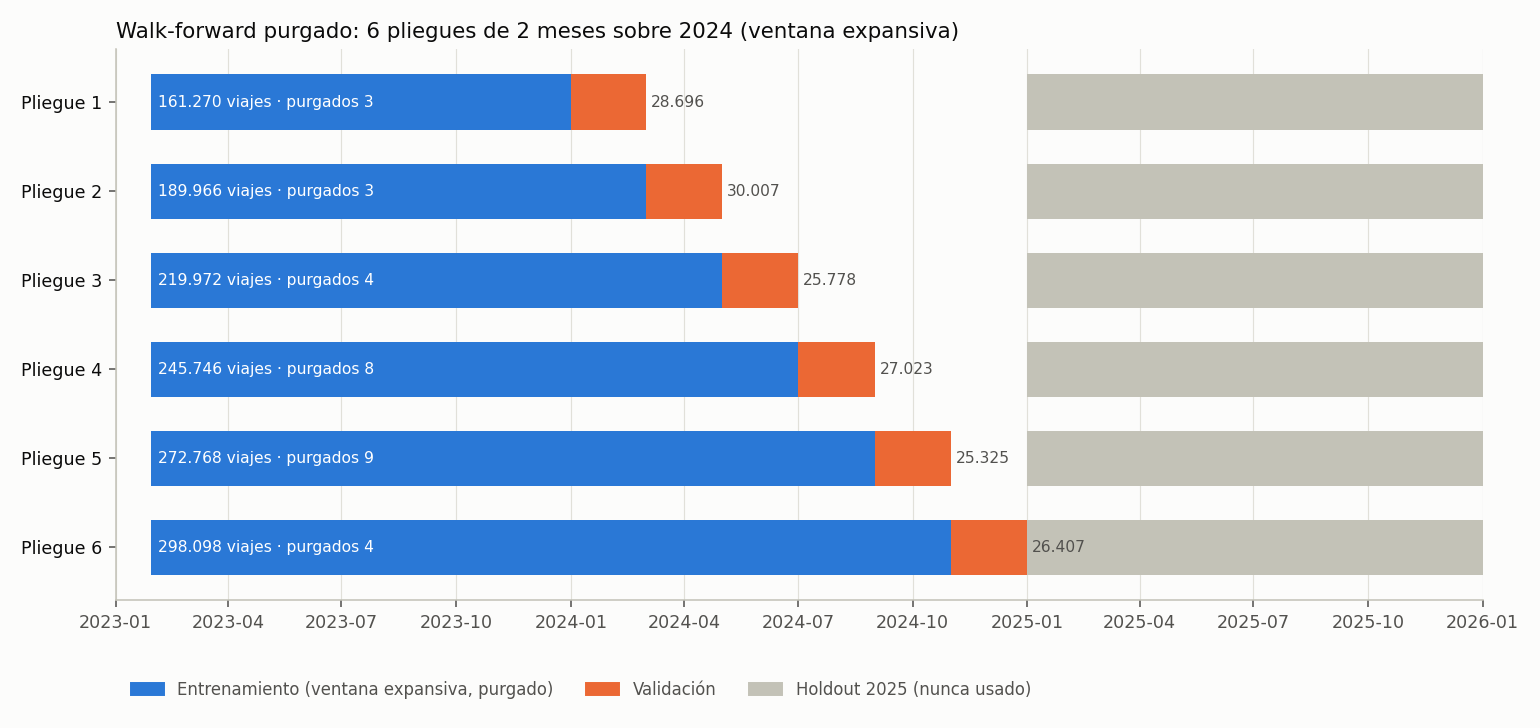

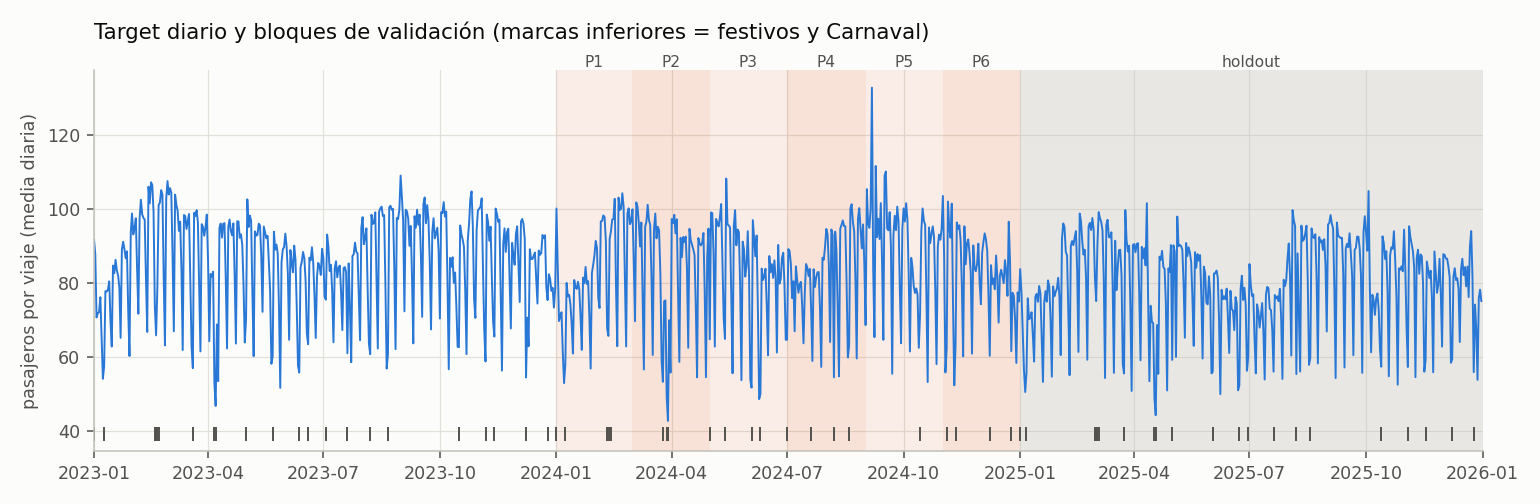

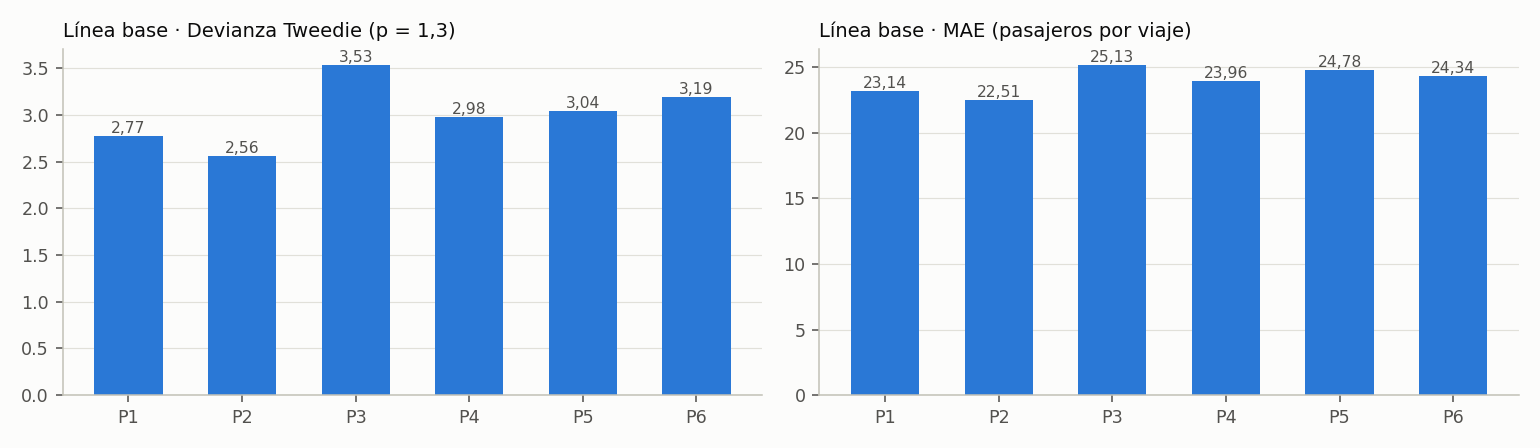

In [185]:
V.grafica_gantt(s, tabla, FIG / "gantt_pliegues.png", "Walk-forward purgado: 6 pliegues de 2 meses sobre 2024 (ventana expansiva)")
V.grafica_serie(X, s, cal, FIG / "serie_diaria_pliegues.png")
V.grafica_metricas(lb, FIG / "linea_base_por_pliegue.png")
for f in ["gantt_pliegues.png", "serie_diaria_pliegues.png", "linea_base_por_pliegue.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 5 · Figuras**
- `gantt_pliegues.png`: los 6 pliegues con ventana expansiva, la validación de 2 meses y el holdout 2025 en gris (nunca usado), con los conteos de viajes y de purgados.
- `serie_diaria_pliegues.png`: el target diario 2023–2025 con los bloques sombreados. Se ven el ciclo semanal, los picos de septiembre–octubre de 2024 (pliegue 5) y los festivos y el Carnaval marcados abajo.
- `linea_base_por_pliegue.png`: la devianza y el MAE de la línea base por pliegue. El pliegue 3 (con el apagón) es el más difícil.

## 6 · Pruebas (a–g)

In [186]:
pruebas = T.correr_todos(X, s)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)

,check,resultado,detalle
0,Test a · orden temporal,PASS,6 pliegues: entrenamiento siempre antes del corte y validación desde el corte
1,Test b · purga por cierre,PASS,0 viajes de entrenamiento con fechafin > corte; sin la purga habrían entrado 31 (control)
2,Test c · holdout intocado,PASS,"0 filas de 2025 en los pliegues; split_holdout: 324,508 de entrenamiento y 158,507 de holdout"
3,Test d · cobertura sin solapes,PASS,"163,236 viajes del período de validación cubiertos exactamente una vez"
4,Test e · ventana expansiva,PASS,"entrenamientos anidados: 161,270 ⊂ 189,966 ⊂ 219,972 ⊂ 245,746 ⊂ 272,768 ⊂ 298,098"
5,Test f · determinismo,PASS,índices idénticos entre llamadas; mismos viajes por pliegue tras barajar X
6,Test g · línea base sin fuga,PASS,perturbar la validación: 0 predicciones cambian; perturbar el entrenamiento: sí cambian (control)


**Conclusión 6 · Las 7 pruebas pasan**
- **(a)** El entrenamiento siempre termina antes del corte y la validación empieza en él.
- **(b)** 0 viajes de entrenamiento con `fechafin` posterior al corte. Sin la purga habrían entrado 31 (el test discrimina).
- **(c)** 0 filas de 2025 en los pliegues.
- **(d)** Los 163.236 viajes de 2024 quedan cubiertos exactamente una vez.
- **(e)** Los entrenamientos están anidados (161.270 ⊂ … ⊂ 298.098).
- **(f)** El resultado es determinista e invariante al orden de las filas.
- **(g)** La línea base no ve la validación: perturbarla no cambia las predicciones, y perturbar el entrenamiento sí.

## 7 · Decisión fija y checks

In [187]:
check("Configuración fija para la 7.2 y la 7.3", True,
      f"K = {s.get_n_splits()}, bloques de {s.meses_bloque} meses en 2024, ventana expansiva desde {s.calentamiento.date()}, "
      f"corte 04:00, purga por fechafin", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_7_1.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · orden temporal,PASS,6 pliegues: entrenamiento siempre antes del corte y validación desde el corte
1,Test b · purga por cierre,PASS,0 viajes de entrenamiento con fechafin > corte; sin la purga habrían entrado 31 (control)
2,Test c · holdout intocado,PASS,"0 filas de 2025 en los pliegues; split_holdout: 324,508 de entrenamiento y 158,507 de holdout"
3,Test d · cobertura sin solapes,PASS,"163,236 viajes del período de validación cubiertos exactamente una vez"
4,Test e · ventana expansiva,PASS,"entrenamientos anidados: 161,270 ⊂ 189,966 ⊂ 219,972 ⊂ 245,746 ⊂ 272,768 ⊂ 298,098"
5,Test f · determinismo,PASS,índices idénticos entre llamadas; mismos viajes por pliegue tras barajar X
6,Test g · línea base sin fuga,PASS,perturbar la validación: 0 predicciones cambian; perturbar el entrenamiento: sí cambian (control)
7,Configuración fija para la 7.2 y la 7.3,INFO,"K = 6, bloques de 2 meses en 2024, ventana expansiva desde 2023-01-29, corte 04:00, purga por fechafin"


PASS 7 · FAIL 0 · INFO 1


**Conclusión 7 · DECISIÓN FIJA para la 7.2 y la 7.3**
- **Configuración:** `WalkForwardPurgado(meses_bloque=2)`: K = 6 bloques de 2 meses sobre 2024; ventana expansiva desde el 2023-01-29; corte a las 04:00 del primer día de cada bloque; purga por `fechafin` ≤ corte. La evaluación final usa `split_holdout()`.
- **Línea base de referencia:** `datos_7/linea_base_7_1.csv` (devianza 3,013 ± 0,335).
- **Checks:** 7 en PASS, 0 en FAIL y 1 informativo.

---
# Parte 15 · Subfase 7.2 · Optuna
*Notebook original: `subfase_7_2_optuna.ipynb`*

In [188]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_7_2_optuna.ipynb")

── Inicio de subfase_7_2_optuna.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 7.2 — Pipeline LightGBM + búsqueda bayesiana con Optuna

**Persona 3 · MLOps & Model Evaluation.** Ajusta los tres modelos del Módulo 6 con la validación fija de la 7.1 y los compara contra la línea base, pliegue por pliegue.

| Elemento | Decisión |
|---|---|
| Datos | `validacion_7_1.cargar()`: 496.302 viajes (features 6.1 + 6.2 + `fechafin`) |
| Validación | `WalkForwardPurgado(meses_bloque=2)`: 6 bloques de 2 meses en 2024, purga por `fechafin`. **2025 no se toca** |
| Modelos | `modelo_0400` (33 features, principal), `modelo_intradia` (45) y `modelo_oraculo` (53, benchmark NO desplegable) |
| Algoritmo | LightGBM nativo, objetivo `tweedie` (`tweedie_variance_power` ∈ [1,1; 1,5]); `poisson` como comparación |
| Early stopping | **Interno**: las últimas 4 semanas del entrenamiento de cada pliegue, purgadas. La validación nunca elige iteraciones |
| Métrica | Devianza Tweedie con p = 1,3 **fijo**, más MAE, sesgo y desglose por `tipo_dia_cal` |
| Vara | Línea base de la 7.1: devianza 3,013 ± 0,335 (`datos_7/linea_base_7_1.csv`) |

**Ejecución.** La búsqueda completa (90 trials + comparaciones) tarda entre 1 y 3 horas según los núcleos del equipo (en la prueba: ~1,5 min por trial con 2 núcleos). Cada trial se guarda en `datos_7/optuna_7_2.db` (SQLite): **si la ejecución se interrumpe, basta con volver a ejecutar el notebook y continúa donde quedó.** Para empezar de cero, borra ese archivo.

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [189]:
import json
import os
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import lightgbm as lgb
import numpy as np
import optuna
import pandas as pd
from IPython.display import Image, display

import modelado_7_2 as M
import tests_7_2 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_7"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_7_2"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


# ---- CONFIGURACIÓN (se puede cambiar antes de ejecutar) ----
N_TRIALS = {"modelo_0400": 40, "modelo_intradia": 25, "modelo_oraculo": 25}
TIMEOUT_POR_ESTUDIO = None          # segundos; None = sin límite
NUM_THREADS = os.cpu_count()
ALMACEN = "sqlite:///datos_7/optuna_7_2.db"
if os.environ.get("SOBUSA_PRUEBA"):  # solo para la prueba de humo del desarrollador
    N_TRIALS = {"modelo_0400": 3, "modelo_intradia": 1, "modelo_oraculo": 1}
    ALMACEN = "sqlite:///datos_7/optuna_7_2_prueba.db"

X = V.cargar()
s = V.WalkForwardPurgado(meses_bloque=2)
lb = pd.read_csv(SALIDA / "linea_base_7_1.csv")
print(f"Python {platform.python_version()} · pandas {pd.__version__} · lightgbm {lgb.__version__} · optuna {optuna.__version__} · hilos {NUM_THREADS}")
print(f"Tabla {X.shape} · {s.get_n_splits()} pliegues · trials {N_TRIALS} · almacén {ALMACEN}")
T0 = time.time()

Python 3.10.0 · pandas 2.3.3 · lightgbm 4.7.0 · optuna 5.0.0 · hilos 12
Tabla (496302, 61) · 6 pliegues · trials {'modelo_0400': 40, 'modelo_intradia': 25, 'modelo_oraculo': 25} · almacén sqlite:///datos_7/optuna_7_2.db


## 1 · Espacio de búsqueda

| Hiperparámetro | Rango | Por qué |
|---|---|---|
| `learning_rate` | 0,02–0,15 (log) | Por debajo de 0,02 se necesitan miles de árboles sin ganancia en un problema de este tamaño; por encima de 0,15, el early stopping corta demasiado pronto |
| `num_leaves` | 15–255 (log) | Desde árboles simples hasta interacciones finas ruta × franja × calendario |
| `min_data_in_leaf` | 20–1.000 (log) | Hay ~150–300 mil viajes por pliegue: hojas muy chicas memorizan días puntuales |
| `feature_fraction` | 0,5–1,0 | Muchas features están correlacionadas (propias frente a espaciales y por salida frente a totales) |
| `bagging_fraction` | 0,5–1,0 (con `bagging_freq` = 1) | Reduce la varianza entre pliegues |
| `lambda_l1`, `lambda_l2` | 0,001–10 (log) | Regularización de las hojas |
| `max_bin` | 63, 127, 255 | Resolución de las features continuas (rezagos y tendencia) |
| `tweedie_variance_power` | 1,1–1,5 | Rango robusto de la 2.2 (p̂ = 1,39 sin 2025, auditoría 6.3 A3). **La métrica sigue fija en p = 1,3** |

## 2 · Búsqueda del modelo 04:00 (principal)

In [190]:
estudios = {}
estudios["modelo_0400"] = M.buscar(X, s, "modelo_0400", N_TRIALS["modelo_0400"], TIMEOUT_POR_ESTUDIO, NUM_THREADS, ALMACEN)
t0400 = M.tabla_estudio(estudios["modelo_0400"])
t0400.to_csv(SALIDA / "optuna_7_2_modelo_0400.csv", index=False)
print(t0400.state.value_counts().to_dict())
print("Mejor valor:", round(estudios["modelo_0400"].best_value, 4))
display(pd.Series(estudios["modelo_0400"].best_params, name="mejores parámetros (modelo_0400)").to_frame())

[modelo_0400] 40 trials en el almacén (0 nuevos en esta ejecución, 0 s)
{'COMPLETE': 29, 'PRUNED': 11}
Mejor valor: 2.4664


,mejores parámetros (modelo_0400)
learning_rate,0.100868
num_leaves,27.000000
min_data_in_leaf,28.000000
feature_fraction,0.687663
bagging_fraction,0.632190
lambda_l1,0.032498
lambda_l2,0.001141
max_bin,63.000000
tweedie_variance_power,1.364707


**Conclusión 2 · Búsqueda del modelo 04:00**
- 40 trials: 29 completos y 11 cortados por el MedianPruner (un trial cortado duró 0,1 min de media; uno completo, 0,6 min).
- Mejor trial: **n.º 31, devianza media 2,4664** en los 6 pliegues. El primer trial dio 2,5050, así que la búsqueda ganó un 1,5 %. Desde el trial 5 (2,4778) solo mejoró un 0,46 % más: **la búsqueda convergió** y más trials no cambiarían la conclusión.
- Mejores hiperparámetros: `learning_rate` 0,101, `num_leaves` 27, `min_data_in_leaf` 28, `feature_fraction` 0,69, `bagging_fraction` 0,63, `lambda_l1` 0,032, `lambda_l2` 0,001, `max_bin` 63 y **`tweedie_variance_power` 1,365**.
- Ese p es coherente con el estimado del Módulo 2 (p̂ = 1,40; IC95 de 1,29 a 1,50).

## 3 · Búsqueda de los modelos intradía y oráculo

In [191]:
for m in ["modelo_intradia", "modelo_oraculo"]:
    estudios[m] = M.buscar(X, s, m, N_TRIALS[m], TIMEOUT_POR_ESTUDIO, NUM_THREADS, ALMACEN)
    M.tabla_estudio(estudios[m]).to_csv(SALIDA / f"optuna_7_2_{m}.csv", index=False)
mejores = {m: M.mejores_params(e) for m, e in estudios.items()}
(SALIDA / "mejores_params_7_2.json").write_text(json.dumps(mejores, indent=2), encoding="utf-8")
display(pd.DataFrame(mejores))
display(pd.DataFrame({m: {"mejor devianza": e.best_value, "trials": len(e.trials),
                          "completos": sum(t.state.name == "COMPLETE" for t in e.trials),
                          "podados": sum(t.state.name == "PRUNED" for t in e.trials)} for m, e in estudios.items()}).round(4))

[modelo_intradia] 25 trials en el almacén (0 nuevos en esta ejecución, 0 s)


[modelo_oraculo] 25 trials en el almacén (0 nuevos en esta ejecución, 0 s)


,modelo_0400,modelo_intradia,modelo_oraculo
learning_rate,0.100868,0.027532,0.028344
num_leaves,27.000000,116.000000,192.000000
min_data_in_leaf,28.000000,56.000000,26.000000
feature_fraction,0.687663,0.773139,0.615599
bagging_fraction,0.632190,0.761107,0.852775
lambda_l1,0.032498,0.001633,0.033820
lambda_l2,0.001141,0.049691,0.001916
max_bin,63.000000,63.000000,63.000000
tweedie_variance_power,1.364707,1.408171,1.480996


,modelo_0400,modelo_intradia,modelo_oraculo
mejor devianza,2.4664,2.453,2.2969
trials,40.0000,25.000,25.0000
completos,29.0000,23.000,24.0000
podados,11.0000,2.000,1.0000


**Conclusión 3 · Búsqueda de los modelos intradía y oráculo**
- Intradía: 25 trials (23 completos y 2 cortados). Mejor trial: **n.º 22, con 2,4530**.
- Oráculo: 25 trials (24 completos y 1 cortado). Mejor trial: **n.º 15, con 2,2969**.
- Los dos prefieren árboles más grandes y lentos que el de 04:00:
  - `learning_rate` ≈ 0,028 (frente a 0,101).
  - 116 y 192 hojas (frente a 27).
  - p más alto: 1,41 y 1,48.
- Los tres modelos eligieron `max_bin` = 63.

## 4 · Los tres modelos frente a la línea base, pliegue por pliegue

Se reentrena cada modelo con sus mejores hiperparámetros y se evalúan los 6 pliegues. **Criterio de aceptación:** el `modelo_0400` debe mejorar la línea base en los 6 pliegues.

In [192]:
cvs, preds = [], []
for m in M.MODELOS:
    cv, pr = M.evaluar_cv(X, s, M.columnas(m), mejores[m], m, NUM_THREADS, guardar_pred=True)
    cvs.append(cv); preds.append(pr)
cv_todos = pd.concat(cvs, ignore_index=True)
pred_todos = pd.concat(preds, ignore_index=True)
cmp = M.vs_linea_base(cv_todos, lb)
cmp.to_csv(SALIDA / "cv_7_2.csv", index=False)
display(cmp[cmp.filas == "todas"].pivot(index="pliegue", columns="config", values=["devianza_tweedie", "mejora_dev_%"]).round(3))
resumen = cmp.groupby(["config", "filas"]).agg(devianza=("devianza_tweedie", "mean"), devianza_std=("devianza_tweedie", "std"),
                                                 mae=("mae", "mean"), sesgo=("sesgo_medio", "mean"),
                                                 mejora_dev_pct=("mejora_dev_%", "mean"), pliegues_que_mejoran=("mejora_dev", lambda v: int((v > 0).sum())),
                                                 best_iteration=("best_iteration", "mean")).round(3)
display(resumen)
acepta = int(cmp[(cmp.config == "modelo_0400") & (cmp.filas == "todas")].mejora_dev.gt(0).sum())
check("Criterio de aceptación: modelo_0400 mejora la línea base en los 6 pliegues", acepta == 6, f"{acepta}/6 pliegues")
ptd = M.por_tipo_dia(pred_todos)
ptd.to_csv(SALIDA / "cv_7_2_por_tipo_dia.csv", index=False)
display(ptd.pivot(index="tipo_dia_cal", columns="config", values="devianza_tweedie").round(3))

devianza_tweedie                                mejora_dev_%                               
config       modelo_0400 modelo_intradia modelo_oraculo  modelo_0400 modelo_intradia modelo_oraculo
pliegue                                                                                            
1                  2.148           2.121          1.957       22.540          23.533         29.457
2                  2.028           2.010          1.961       20.870          21.590         23.504
3                  2.919           2.892          2.680       17.304          18.080         24.078
4                  2.691           2.724          2.420        9.754           8.640         18.851
5                  2.464           2.453          2.361       18.844          19.201         22.227
6                  2.548           2.519          2.404       20.238          21.170         24.763

devianza  devianza_std     mae  sesgo  mejora_dev_pct  pliegues_que_mejoran  best_iteration
config          filas                                                                                                 
modelo_0400     sin flags     2.419         0.271  21.224  0.374          18.153                     6         291.167
                todas         2.466         0.333  21.279  0.486          18.258                     6         291.167
modelo_intradia sin flags     2.405         0.281  21.088 -0.438          18.638                     6         601.167
                todas         2.453         0.340  21.145 -0.326          18.702                     6         601.167
modelo_oraculo  sin flags     2.256         0.232  20.384 -0.727          23.623                     6         526.833
                todas         2.297         0.285  20.427 -0.637          23.813                     6         526.833

config,modelo_0400,modelo_intradia,modelo_oraculo
tipo_dia_cal,,,
carnaval,2.434,2.490,2.261
domingo,2.020,2.011,1.812
festivo,2.230,2.283,1.873
laboral,2.500,2.479,2.333
sabado,2.539,2.540,2.429


**Conclusión 4 · Los tres modelos frente a la línea base**
- **Criterio de aceptación cumplido:** el modelo de 04:00 mejora la línea base (3,013) en los **6 de 6 pliegues**.
  - Devianza media **2,466**, un 18,3 % de mejora media por pliegue: desde un 9,8 % (P4) hasta un 22,5 % (P1).
  - MAE de 23,98 a **21,28** pasajeros por viaje.
  - Sesgo medio de +2,10 a **+0,49**.
- Intradía: 2,453 (mejora 6/6, 18,7 %). Oráculo: 2,297 (mejora 6/6, 23,8 %).
- **Por tipo de día (modelo 04:00 frente a la línea base):** laboral −19,8 %, festivo −18,0 %, sábado −13,9 %, domingo −9,3 % y carnaval −27,1 %.
- **⚠ Carnaval:** el modelo sobrepredice +5,9 pasajeros por viaje, frente a +1,8 de la línea base (1.138 viajes). Mejora la devianza, pero el nivel queda alto.
- **⚠ P4 (jul–ago 2024):** el early stopping se detiene en **34 iteraciones**, cuando en los otros pliegues lo hace entre 264 y 483.
  - Su ventana de early stopping es del 3 al 30 de junio de 2024, que se cruza con el apagón (31 may–18 jun) y es el mes con menos lecturas.
  - Por eso el modelo probablemente queda subajustado, y P4 es el pliegue con menos ganancia. Es un riesgo directo para la 7.3.

## 5 · Comparaciones (con los mejores hiperparámetros del modelo 04:00, sin volver a buscar)

- **a)** Objetivo `tweedie` frente a `poisson`.
- **b)** Sin las features de **totales** (`pasajeros_lag*`, `pasajeros_media4sem`, `roll_*`, incluidas las espaciales de totales): mide el riesgo del sesgo de −4,5 % en 2025 (CLAUDE.md §11.9).
- **c)** Sin el **lag espacial** (`*_esp_*`): ¿aporta la 6.2?
- **d)** Los tres modelos: la brecha 04:00 → oráculo es el valor de tener datos en tiempo real.

In [193]:
base_cols = M.columnas("modelo_0400")
bp = mejores["modelo_0400"]
totales = [c for c in base_cols if ("pasajeros_lag" in c) or ("pasajeros_media4sem" in c) or ("roll_" in c)]
espaciales = [c for c in base_cols if "_esp_" in c]
print(f"Totales quitados en (b): {len(totales)} columnas · espaciales quitadas en (c): {len(espaciales)}")
variantes = {
    "a · objetivo poisson": (base_cols, {**{k: v for k, v in bp.items() if k != "tweedie_variance_power"}, "objective": "poisson"}),
    "b · sin features de totales": ([c for c in base_cols if c not in totales], bp),
    "c · sin lag espacial": ([c for c in base_cols if c not in espaciales], bp),
}
comps = [cv_todos[cv_todos.config == "modelo_0400"].assign(config="modelo_0400 (referencia)")]
for nom, (cols, prm) in variantes.items():
    comps.append(M.evaluar_cv(X, s, cols, prm, nom, NUM_THREADS)[0])
for m in ["modelo_intradia", "modelo_oraculo"]:
    comps.append(cv_todos[cv_todos.config == m].assign(config=f"d · {m}"))
comp = pd.concat(comps, ignore_index=True)
comp = M.vs_linea_base(comp, lb)
comp.to_csv(SALIDA / "comparaciones_7_2.csv", index=False)
ref = comp[(comp.config == "modelo_0400 (referencia)") & (comp.filas == "todas")].set_index("pliegue").devianza_tweedie
tab = []
for c, g in comp[comp.filas == "todas"].groupby("config"):
    d = g.set_index("pliegue").devianza_tweedie
    tab.append({"config": c, "devianza media": d.mean(), "± std": d.std(), "Δ vs referencia": d.mean() - ref.mean(),
                "pliegues peores que la referencia": int((d > ref + 1e-12).sum()), "sesgo medio": g.sesgo_medio.mean()})
display(pd.DataFrame(tab).sort_values("devianza media").round(4))

Totales quitados en (b): 13 columnas · espaciales quitadas en (c): 8


,config,devianza media,± std,Δ vs referencia,pliegues peores que la referencia,sesgo medio
4,d · modelo_oraculo,2.2969,0.2851,-0.1695,0,-0.6371
3,d · modelo_intradia,2.4530,0.3398,-0.0135,1,-0.3259
5,modelo_0400 (referencia),2.4664,0.3333,0.0000,0,0.4862
0,a · objetivo poisson,2.5102,0.3770,0.0438,4,0.4869
2,c · sin lag espacial,2.5227,0.3708,0.0563,6,0.3176
1,b · sin features de totales,2.5302,0.3581,0.0638,5,0.7821


**Conclusión 5 · Comparaciones (con los hiperparámetros del modelo 04:00)**
- **a) Poisson:** 2,510, un 1,8 % peor que Tweedie y peor en 4 de 6 pliegues. **Se mantiene Tweedie.**
- **b) Sin las features de totales:** 2,530, un 2,6 % peor y peor en 5 de 6 pliegues. **Se mantienen.** El riesgo de sesgo en 2025 (rezagos de totales −4,5 %) se mide en el holdout de la 7.3.
- **c) Sin lag espacial:** 2,523, un 2,3 % peor y peor en **6 de 6** pliegues. **El lag espacial de la 6.2 aporta y se mantiene.**
- **d) Valor de la información en tiempo real:**
  - El oráculo mejora un 6,9 % sobre el modelo de 04:00 (6/6 pliegues).
  - La cascada intradía, en cambio, solo mejora un **0,5 %** (5/6 pliegues; empeora en P4). Recupera el **7,9 %** de esa brecha: 0,013 de 0,170.
  - Casi todo el valor del tiempo real está en t−1…t−4, que no son desplegables. Con t−5…t−8, la cascada aporta poco.
  - Se mantiene, como se decidió, pero su ganancia marginal es pequeña.
- **Corrección (7.3):** el 0,5 % de la cascada estaba deprimido por el early stopping (en P4 intradía se detuvo en 87 árboles). Con rondas fijas, intradía mejora un **1,7 %** en la CV (P2–P6) y un **3,9 %** en 2025, y recupera el 26 % y el 34 % de la brecha entre 04:00 y el oráculo. **La cascada sí aporta.**

## 6 · Figuras

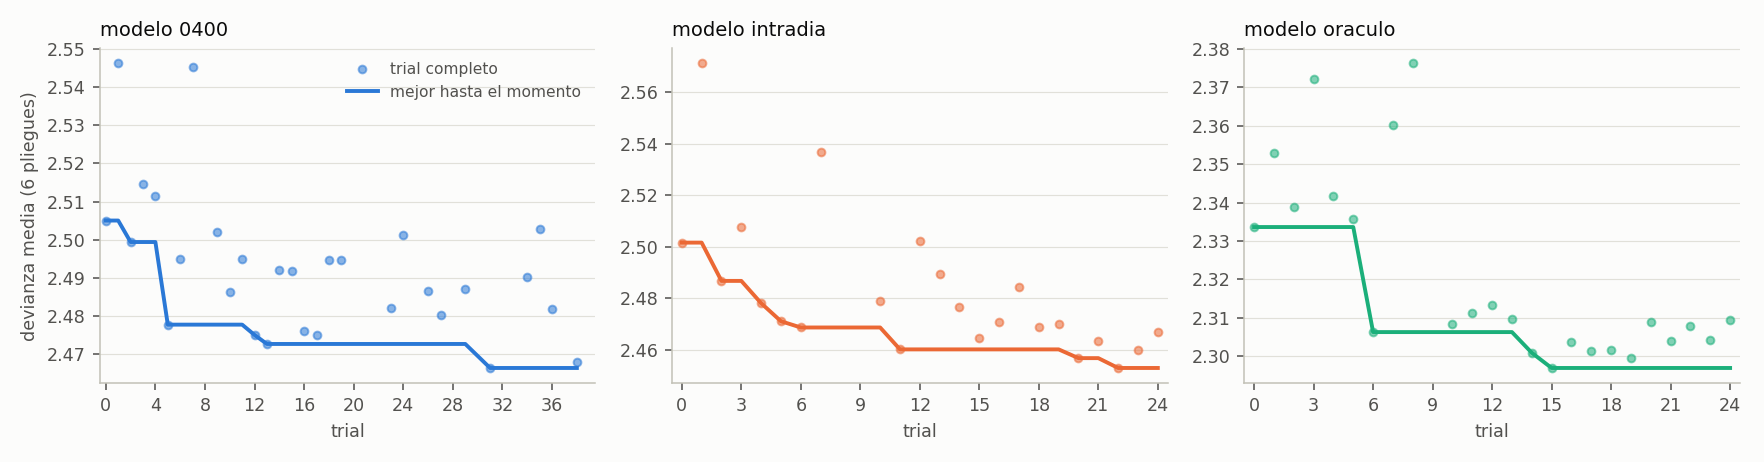

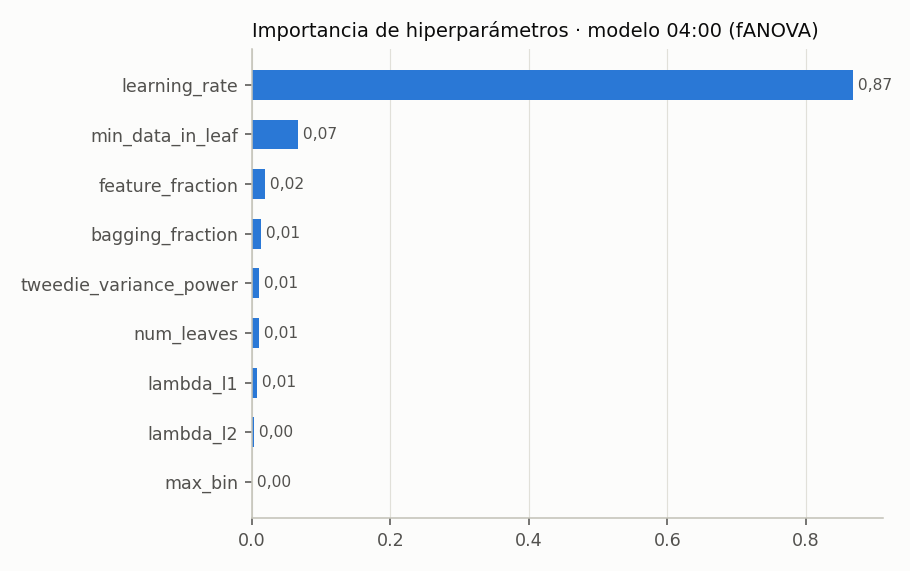

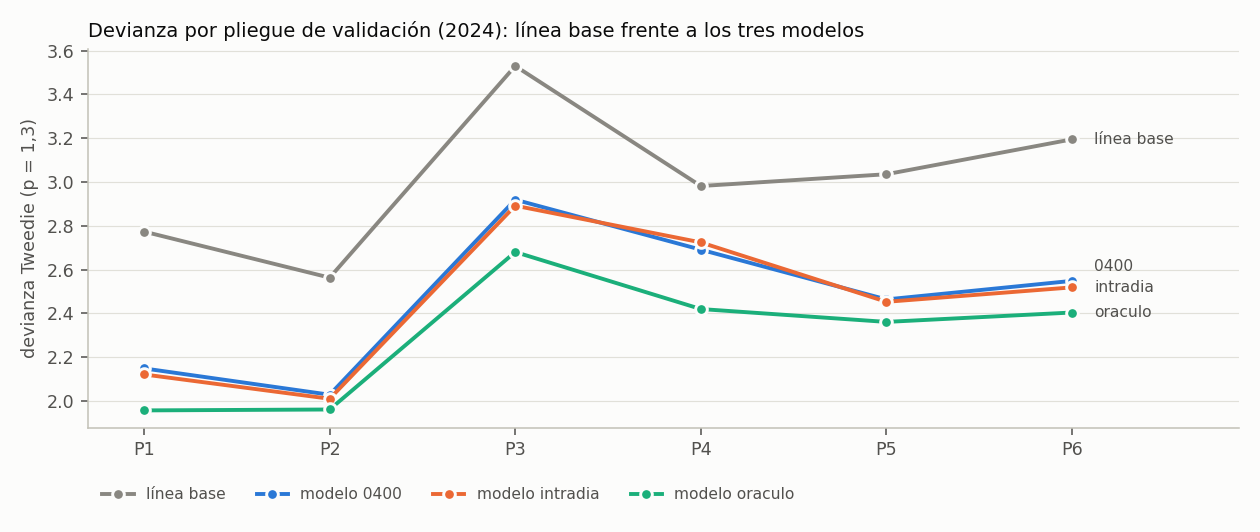

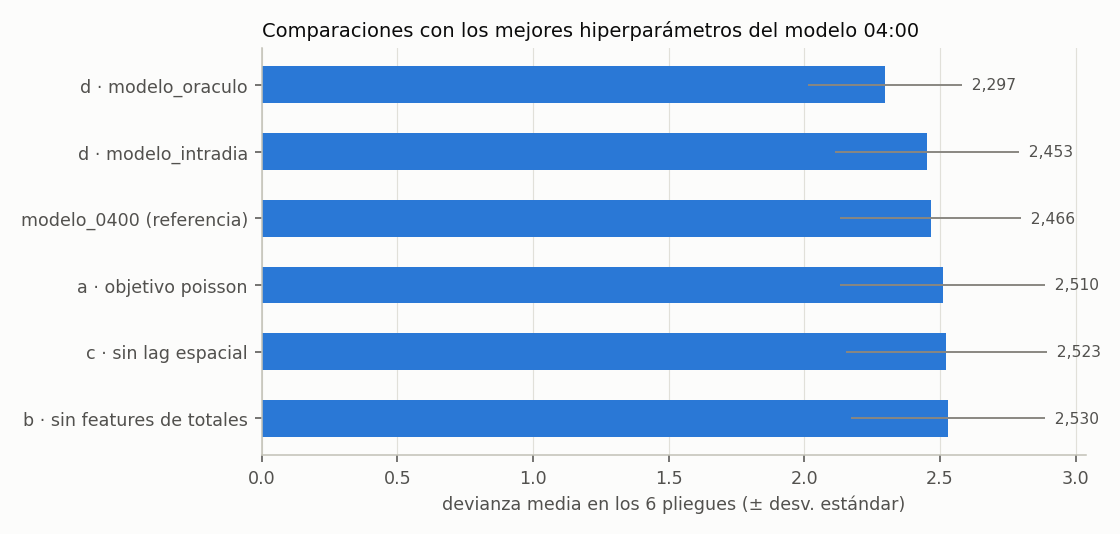

In [194]:
M.fig_historia(estudios, FIG / "historia_optuna.png")
imp = M.importancia(estudios["modelo_0400"])
imp.to_csv(SALIDA / "importancia_hiperparametros_7_2.csv")
M.fig_importancia(imp, FIG / "importancia_hiperparametros_0400.png", f"Importancia de hiperparámetros · modelo 04:00 ({imp.name})")
M.fig_pliegues(cv_todos, lb, FIG / "devianza_por_pliegue.png")
M.fig_comparaciones(comp, FIG / "comparaciones.png")
for f in ["historia_optuna.png", "importancia_hiperparametros_0400.png", "devianza_por_pliegue.png", "comparaciones.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 6 · Figuras**
- `historia_optuna.png`: las tres búsquedas se estabilizan antes de su último tercio:
  - modelo de 04:00: trial 31 de 40;
  - intradía: trial 22 de 25;
  - oráculo: trial 15 de 25.
- `importancia_hiperparametros_0400.png` (fANOVA): **`learning_rate` explica el 86,8 %** de la varianza de la devianza y `min_data_in_leaf` el 6,7 %. Cada uno de los demás aporta menos del 2 %.
  - `tweedie_variance_power` aporta solo un 1,1 %: dentro de [1,1; 1,5], la elección de p apenas cambia la devianza.
- `devianza_por_pliegue.png` y `comparaciones.png` confirman las conclusiones 4 y 5. P3 (may–jun) es el pliegue más difícil para todos los modelos y P4 el de menor ganancia.

## 7 · Pruebas (a–f)

In [195]:
pruebas = T.correr_todos(X, s, estudios)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)

,check,resultado,detalle
0,Test a · early stopping interno y purgado,PASS,"6 pliegues: early stopping = últimas 4 semanas antes del corte, ajuste purgado a su inicio; 0 índices de validación ..."
1,Test b · la validación no influye en el ajuste,PASS,mismo best_iteration (46) y predicciones idénticas con el target de validación ×10 + 7
2,Test c · columnas exactas por modelo,PASS,modelo_0400: 33; modelo_intradia: 45; modelo_oraculo: 53; el selector rechaza columnas inexistentes
3,Test d · determinismo,PASS,"28,696 predicciones idénticas en dos entrenamientos"
4,Test e · sin 2025,PASS,"0 filas de 2025 en ajuste, early stopping o validación de los 6 pliegues"
5,Test f · el estudio solo ve 2024,PASS,"90 trials con métricas registradas, todas de validaciones anteriores a 2025"


**Conclusión 7 · Pruebas**
- Pasan las **6 de 6** pruebas:
  - **a)** early stopping interno y purgado en los 6 pliegues;
  - **b)** con el target de validación multiplicado por 10 más 7, se obtienen el mismo `best_iteration` (46) y las mismas predicciones;
  - **c)** cada modelo usa exactamente sus columnas: 33, 45 y 53;
  - **d)** determinismo: 28.696 predicciones idénticas;
  - **e)** 0 filas de 2025;
  - **f)** los 90 trials registran solo métricas de validación anteriores a 2025.
- **No hay fuga de la validación ni del holdout hacia la búsqueda.**

## 8 · Decisión fija para la 7.3 y checks

In [196]:
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min con {NUM_THREADS} hilos", info=True)
check("Mejores parámetros guardados", (SALIDA / "mejores_params_7_2.json").exists(), "datos_7/mejores_params_7_2.json", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_7_2.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Criterio de aceptación: modelo_0400 mejora la línea base en los 6 pliegues,PASS,6/6 pliegues
1,Test a · early stopping interno y purgado,PASS,"6 pliegues: early stopping = últimas 4 semanas antes del corte, ajuste purgado a su inicio; 0 índices de validación ..."
2,Test b · la validación no influye en el ajuste,PASS,mismo best_iteration (46) y predicciones idénticas con el target de validación ×10 + 7
3,Test c · columnas exactas por modelo,PASS,modelo_0400: 33; modelo_intradia: 45; modelo_oraculo: 53; el selector rechaza columnas inexistentes
4,Test d · determinismo,PASS,"28,696 predicciones idénticas en dos entrenamientos"
5,Test e · sin 2025,PASS,"0 filas de 2025 en ajuste, early stopping o validación de los 6 pliegues"
6,Test f · el estudio solo ve 2024,PASS,"90 trials con métricas registradas, todas de validaciones anteriores a 2025"
7,Tiempo total de la ejecución,INFO,5.9 min con 12 hilos
8,Mejores parámetros guardados,INFO,datos_7/mejores_params_7_2.json


PASS 7 · FAIL 0 · INFO 2


**Conclusión 8 · Decisión fija para la 7.3**
- **Modelo principal:** `modelo_0400`, con `datos_7/mejores_params_7_2.json` (p = 1,365) y objetivo Tweedie.
- **Modelos de referencia:** intradía (2,453) y oráculo (2,297), con sus propios parámetros.
- **Features:** se mantienen las de totales y el lag espacial.
- **Pendiente para la 7.3 (número de rondas):** con early stopping interno, la ventana del modelo final sería diciembre de 2024 (temporada navideña), una ventana atípica como la de P4.
  - Comparar early stopping interno frente a rondas fijas: mediana de `best_iteration` en la validación cruzada = **311** para el modelo de 04:00 (283, 339, 483, 34, 344, 264).
- **Riesgos que se miden en el holdout 2025:** sesgo por cierres tardíos (rezagos de totales −4,5 %), sobrepredicción en carnaval y tendencia descendente de la demanda.
- La ejecución tardó 64,8 min con 12 hilos y todos los checks pasaron.
- **Resuelto en la 7.3:** se adoptan rondas fijas (311 / 649 / 461), que igualan o mejoran el early stopping en 4/5, 5/5 y 5/5 pliegues.

---
# Parte 16 · Subfase 7.3 · Modelo final y holdout
*Notebook original: `subfase_7_3_final.ipynb`*

In [197]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_7_3_final.ipynb")

── Inicio de subfase_7_3_final.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 7.3 — Regla de rondas, entrenamiento final, evaluación única en 2025 y sobreajuste

**Persona 3 · MLOps & Model Evaluation.** Cierra el Módulo 7: fija cuántos árboles usa cada modelo **solo con 2024**, entrena los modelos finales con 2023–2024 y los evalúa **una sola vez** en el holdout 2025.

| Elemento | Decisión |
|---|---|
| Datos | `validacion_7_1.cargar()`: 496.302 viajes. Entrenamiento final = `split_holdout()`: 324.508 viajes (2023-01-29 → 2024-12-31, purga por `fechafin` ≤ 2025-01-01 04:00). Holdout 2025: 158.507 viajes |
| Hiperparámetros | `datos_7/mejores_params_7_2.json` **sin cambios** (se verifica con su hash) |
| Regla candidata | Rondas fijas = mediana de `best_iteration` de la 7.2 (04:00: 311 · intradía: 649 · oráculo: 461), entrenando con **todo** el entrenamiento (sin apartar diciembre para early stopping) |
| Criterio (fijado antes) | Se adoptan rondas fijas si en **≥ 3 de 5** pliegues (P2–P6) su devianza ≤ la del early stopping × 1,005. Si no, early stopping interno (4 semanas). Por modelo |
| Aceptación en 2025 | El modelo 04:00 mejora la línea base en el global y en **≥ 10 de 12 meses** |
| Métrica | Devianza Tweedie con p = 1,3 **fijo**, más MAE y sesgo |

**Regla de oro.** La decisión de rondas se escribe en `datos_7/decision_rondas_7_3.json` **antes** de tocar 2025. Lo que se observe en 2025 (partes 4–7) es descriptivo y no cambia ninguna decisión; el código se niega a reescribir la decisión si ya existen métricas del holdout.

**Ejecución.** Tarda unos 10 min con 12 hilos (en la prueba: la parte A del modelo 04:00 tomó 0,9 min con 2 hilos). No usa la base de datos.

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [198]:
import json
import os
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import lightgbm as lgb
import numpy as np
import pandas as pd
from IPython.display import Image, display

import entrenamiento_7_3 as E
import modelado_7_2 as M
import tests_7_3 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_7"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_7_3"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


# ---- CONFIGURACIÓN ----
NUM_THREADS = os.cpu_count()
TOPE = None                      # None = rondas completas
SEMILLAS = (1, 2, 3)
if os.environ.get("SOBUSA_PRUEBA"):   # solo para la prueba de humo del desarrollador
    TOPE, SEMILLAS = 40, (1,)

X = V.cargar()
s = V.WalkForwardPurgado(meses_bloque=2)
params, HASH = E.cargar_params()
r72 = E.resultados_7_2()
FINALES = E.rondas_finales(r72)
print(f"Python {platform.python_version()} · pandas {pd.__version__} · lightgbm {lgb.__version__} · hilos {NUM_THREADS} · tope {TOPE}")
print(f"Tabla {X.shape} · hash de mejores_params_7_2.json: {HASH[:16]}…")
print("Rondas candidatas (mediana de best_iteration de la 7.2):", FINALES)
T0 = time.time()

Python 3.10.0 · pandas 2.3.3 · lightgbm 4.7.0 · hilos 12 · tope None
Tabla (496302, 61) · hash de mejores_params_7_2.json: 428a3fb5f20dac8d…
Rondas candidatas (mediana de best_iteration de la 7.2): {'modelo_0400': 311, 'modelo_intradia': 649, 'modelo_oraculo': 461}


## 1 · Parte A — Validación anidada de la regla de rondas (solo 2024)

En cada pliegue k ≥ 2 las rondas son la mediana de `best_iteration` de los pliegues **anteriores** (nunca del propio ni de los siguientes). Se entrena con **todo** el entrenamiento del pliegue, sin ventana de early stopping, y se compara con la devianza que obtuvo el early stopping en la 7.2. La misma pasada registra la devianza en cada iteración (curva de sensibilidad); el registro no influye en el modelo.

In [199]:
anid = pd.DataFrame({m: E.rondas_anidadas(g.sort_values("pliegue").best_iteration.tolist())
                     for m, g in r72.groupby("modelo")}).rename_axis("pliegue")
display(r72.pivot(index="pliegue", columns="modelo", values="best_iteration").rename(columns=lambda c: f"best_iter_7_2 · {c}")
        .join(anid.rename(columns=lambda c: f"regla · {c}")))
tA = time.time()
regla, curvas = E.regla_rondas(X, s, params, r72, NUM_THREADS, tope=TOPE)
regla.to_csv(SALIDA / "regla_rondas_7_3.csv", index=False)
curvas.to_csv(SALIDA / "curvas_rondas_cv_7_3.csv.gz", index=False)
print(f"Parte A: {(time.time() - tA) / 60:,.1f} min")
display(regla.dropna(subset=["dev_fijo"]).pivot(index="pliegue", columns="modelo",
        values=["rondas_regla", "dev_es_7_2", "dev_fijo", "ratio_fijo_es", "fijo_gana_o_empata"]).round(4))

,best_iter_7_2 · modelo_0400,best_iter_7_2 · modelo_intradia,best_iter_7_2 · modelo_oraculo,regla · modelo_0400,regla · modelo_intradia,regla · modelo_oraculo
pliegue,,,,,,
1,283,534,499,NaN,NaN,NaN
2,339,570,423,283.0,534.0,499.0
3,483,820,505,311.0,552.0,461.0
4,34,87,208,339.0,570.0,499.0
5,344,727,407,311.0,552.0,461.0
6,264,869,1119,339.0,570.0,423.0


[modelo_0400] P1 · 161,270 viajes · 622 rondas · 5.2 s


[modelo_0400] P2 · 189,966 viajes · 622 rondas · 6.6 s


[modelo_0400] P3 · 219,972 viajes · 622 rondas · 6.2 s


[modelo_0400] P4 · 245,746 viajes · 622 rondas · 6.7 s


[modelo_0400] P5 · 272,768 viajes · 622 rondas · 6.8 s


... (11 outputs left out)

[modelo_oraculo] P5 · 272,768 viajes · 922 rondas · 72.6 s


[modelo_oraculo] P6 · 298,098 viajes · 922 rondas · 67.5 s


Parte A: 15.1 min


rondas_regla                                 dev_es_7_2                                   dev_fijo                                ratio_fijo_es                                 \
modelo   modelo_0400 modelo_intradia modelo_oraculo modelo_0400 modelo_intradia modelo_oraculo modelo_0400 modelo_intradia modelo_oraculo   modelo_0400 modelo_intradia modelo_oraculo   
pliegue                                                                                                                                                                                  
2              283.0           534.0          499.0    2.028186         2.00973       1.960652    2.047158        2.006763       1.942356      1.009354        0.998524       0.990668   
3              311.0           552.0          461.0    2.919257        2.891857        2.68013    2.880394        2.852294       2.660556      0.986687        0.986319       0.992697   
4              339.0           570.0          499.0    2.690876        2.724097       2.419616    2.518694        2.461227       2.292082      0.936013        0.903502       0.947291   
5              311.0           552.0          461.0    2.463504        2.452679       2.360822    2.454604        2.415499       2.353138      0.996387        0.984841       0.996745   
6              339.0           570.0          423.0    2.548366        2.518602       2.403795     2.54002        2.498142       2.392195      0.996725        0.991877       0.995174   

        fijo_gana_o_empata                                 
modelo         modelo_0400 modelo_intradia modelo_oraculo  
pliegue                                                    
2                    False            True           True  
3                     True            True           True  
4                     True            True           True  
5                     True            True           True  
6                     True            True           True

,modelo,rondas_candidatas,curva media en las rondas candidatas (%),mínimo de la curva media (%),árboles del mínimo de la curva media,"tramo a ≤ 0,5 puntos del mínimo",árboles del mínimo por pliegue
0,modelo_0400,311,0.845,0.759,344,132–609,"P1=95, P2=622, P3=342, P4=142, P5=604, P6=181"
1,modelo_intradia,649,0.353,0.321,560,243–1298,"P1=235, P2=997, P3=767, P4=498, P5=1179, P6=278"
2,modelo_oraculo,461,0.188,0.176,478,225–922,"P1=304, P2=882, P3=389, P4=472, P5=907, P6=480"


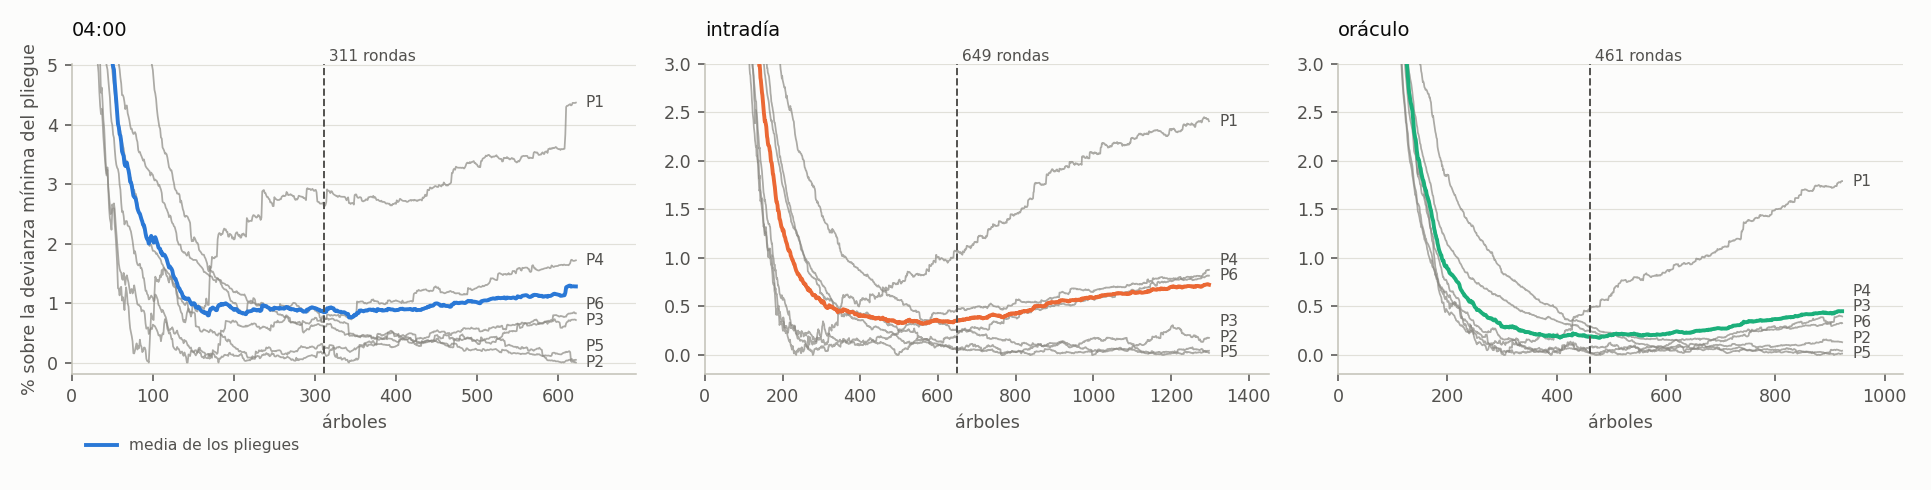

In [200]:
cr = curvas.copy()
cr["rel_%"] = (cr.devianza / cr.groupby(["modelo", "pliegue"]).devianza.transform("min") - 1) * 100
sens = []
for m, g in cr.groupby("modelo"):
    med = g.groupby("iteracion")["rel_%"].mean()
    r = FINALES[m] if TOPE is None else min(FINALES[m], TOPE)
    plano = med[med <= med.min() + 0.5].index
    sens.append({"modelo": m, "rondas_candidatas": r, "curva media en las rondas candidatas (%)": med.get(r),
                 "mínimo de la curva media (%)": med.min(), "árboles del mínimo de la curva media": int(med.idxmin()),
                 "tramo a ≤ 0,5 puntos del mínimo": f"{int(plano.min())}–{int(plano.max())}",
                 "árboles del mínimo por pliegue": ", ".join(f"P{k}={int(h.iteracion[h.devianza.idxmin()])}" for k, h in g.groupby("pliegue"))})
sens = pd.DataFrame(sens)
sens.to_csv(SALIDA / "sensibilidad_rondas_7_3.csv", index=False)
display(sens.round(3))
E.fig_curva_rondas(curvas, {"modelos": {}}, {m: (FINALES[m] if TOPE is None else min(FINALES[m], TOPE)) for m in FINALES},
                   FIG / "curva_rondas_cv_2024.png")
display(Image(filename=str(FIG / "curva_rondas_cv_2024.png")))

**Conclusión 1 · Regla de rondas en 2024**
- Con rondas fijas = mediana de los pliegues **anteriores** y entrenando con todo el pliegue, la devianza **iguala o mejora** al early stopping de la 7.2 en:
  - **04:00:** 4 de 5 pliegues. Solo pierde P2: +0,9 % con 283 rondas.
  - **intradía:** 5 de 5.
  - **oráculo:** 5 de 5.
- Ratio medio fijo/ES: 0,985 · 0,973 · 0,985.
- **P4 (jul–ago) confirma el diagnóstico de la 7.2:** las rondas fijas mejoran un **6,4 %**, un 9,6 % y un 5,3 %, porque el early stopping con la ventana de junio cortaba demasiado pronto (34, 87 y 208 árboles).
- **Las rondas candidatas caen en la zona plana:**
  - En 311, 649 y 461 árboles, la curva media queda a 0,85 %, 0,35 % y 0,19 % sobre el mínimo de cada pliegue.
  - Los mínimos de la curva media están en 344, 560 y 478 árboles.
  - El tramo a ≤ 0,5 puntos del mínimo va de 132 a 609, de 243 a 1.298 y de 225 a 922 árboles.
- P1 (ene–feb 2024) es la excepción: su mínimo está en 95, 235 y 304 árboles, y luego empeora (hasta +4,4 % en el modelo 04:00).

## 2 · Decisión de rondas (se escribe ANTES de tocar 2025)

In [201]:
decision = E.decidir(regla, r72)
decision = E.guardar_decision(decision, HASH)
print(json.dumps(decision, ensure_ascii=False, indent=2))
for m, d in decision["modelos"].items():
    check(f"Decisión de rondas · {m}", True, f"{d['regla']} ({d['rondas']}); {d['pliegues_gana_o_empata']}/{d['pliegues_evaluados']} pliegues", info=True)

{
  "criterio": "rondas fijas si en ≥ 3 de 5 pliegues (P2–P6) su devianza ≤ ES × 1.005",
  "modelos": {
    "modelo_0400": {
      "regla": "rondas_fijas",
      "rondas": 311,
      "pliegues_gana_o_empata": 4,
      "pliegues_evaluados": 5,
      "ratio_medio_fijo_es": 0.9850332975842677
    },
    "modelo_intradia": {
      "regla": "rondas_fijas",
      "rondas": 649,
      "pliegues_gana_o_empata": 5,
      "pliegues_evaluados": 5,
      "ratio_medio_fijo_es": 0.9730124536560443
    },
    "modelo_oraculo": {
      "regla": "rondas_fijas",
      "rondas": 461,
      "pliegues_gana_o_empata": 5,
      "pliegues_evaluados": 5,
      "ratio_medio_fijo_es": 0.984515146345621
    }
  },
  "hash_mejores_params_7_2": "428a3fb5f20dac8d0ed3b46f64d93381c638503c58f1f5c1d155527fbce420c8",
  "escrita": "2026-10-10T18:16:46"
}


**Conclusión 2 · Decisión**
- **Rondas fijas en los tres modelos:** **311** (04:00), **649** (intradía) y **461** (oráculo).
- La decisión quedó escrita en `datos_7/decision_rondas_7_3.json` a las 18:16:46, antes de las métricas de 2025.
- El hash de `mejores_params_7_2.json` (428a3fb5…) es el mismo en la decisión y en los tres modelos guardados.
- Con esta regla, **diciembre de 2024 entra al entrenamiento final** en vez de quedar apartado como ventana de early stopping.

## 3 · Parte B — Entrenamiento final (2023-01-29 → 2024-12-31)

In [202]:
t, ho = E.datos_final(X, s)
print(f"Entrenamiento: {len(t):,} viajes, {t.fechasalida.min()} → {t.fechasalida.max()} (último cierre {t.fechafin.max()})")
print(f"Holdout 2025: {len(ho):,} viajes")
finales_b, metas = {}, []
for m in M.MODELOS:
    t0 = time.time()
    b, n = E.entrenar_final(t, m, params[m], decision["modelos"][m], NUM_THREADS, tope=TOPE)
    E.guardar_modelo(b, n, m, params[m], decision["modelos"][m], HASH, t)
    finales_b[m] = (b, n)
    metas.append({"modelo": m, "regla": decision["modelos"][m]["regla"], "árboles": n, "columnas": len(M.columnas(m)),
                  "segundos": round(time.time() - t0, 1)})
display(pd.DataFrame(metas))

Entrenamiento: 324,508 viajes, 2023-01-29 05:00:00 → 2024-12-31 18:40:00 (último cierre 2024-12-31 21:53:44)
Holdout 2025: 158,507 viajes


,modelo,regla,árboles,columnas,segundos
0,modelo_0400,rondas_fijas,311,33,12.0
1,modelo_intradia,rondas_fijas,649,45,32.5
2,modelo_oraculo,rondas_fijas,461,53,12.6


**Conclusión 3 · Modelos finales**
- Entrenados con **324.508 viajes**:
  - salidas del 2023-01-29 05:00 al 2024-12-31 18:40;
  - último cierre: 2024-12-31 21:53, antes del corte del 2025-01-01 04:00.
- Guardados en `modelos_7_3/` con sus metadatos (columnas, parámetros, regla, número de árboles y hash):
  - `modelo_0400.txt`: 33 columnas y 311 árboles.
  - `modelo_intradia.txt`: 45 columnas y 649 árboles.
  - `modelo_oraculo.txt`: 53 columnas y 461 árboles.

## 4 · Evaluación única en el holdout 2025

Línea base = la misma de la 7.1 (media ruta × franja × `tipo_dia_cal`), estimada solo con el entrenamiento final.

,config,filas,devianza_tweedie,mae,sesgo_medio,n,mejora_dev_%
0,linea_base,todas,2.9288,23.4854,5.9553,158507,0.0000
1,linea_base,sin flags,2.9288,23.4854,5.9553,158507,0.0000
2,modelo_0400,todas,2.5028,20.7064,-2.9708,158507,14.5430
3,modelo_0400,sin flags,2.5028,20.7064,-2.9708,158507,14.5430
4,modelo_intradia,todas,2.4058,20.3800,-1.7543,158507,17.8574
5,modelo_intradia,sin flags,2.4058,20.3800,-1.7543,158507,17.8574
6,modelo_oraculo,todas,2.2216,19.6701,-0.4785,158507,24.1475
7,modelo_oraculo,sin flags,2.2216,19.6701,-0.4785,158507,24.1475


{'mejora_global_%': 14.543030686284641, 'meses_que_mejoran': 11, 'meses': 12, 'acepta': True}


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
2025-01,3.293,2.452,2.353,2.130,25.5
2025-02,2.493,2.586,2.426,2.130,-3.7
2025-03,2.522,2.405,2.295,2.087,4.6
2025-04,2.807,2.558,2.431,2.203,8.9
2025-05,2.721,2.452,2.351,2.179,9.9
2025-06,3.133,2.469,2.421,2.289,21.2
2025-07,3.293,2.386,2.363,2.250,27.5
2025-08,2.672,2.666,2.501,2.229,0.2
2025-09,2.731,2.514,2.411,2.196,8.0


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
16,2.605,2.299,2.224,2.026,11.8
2,3.428,2.842,2.695,2.511,17.1
21,3.117,2.582,2.498,2.353,17.2


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
carnaval,3.544,2.407,2.460,2.508,32.1
domingo,2.295,2.344,2.297,1.920,-2.1
festivo,2.224,1.851,1.817,1.713,16.8
laboral,3.030,2.569,2.453,2.266,15.2
sabado,2.957,2.404,2.356,2.290,18.7


,linea_base,modelo_0400,modelo_intradia,modelo_oraculo,mejora 0400 %
grupo,,,,,
04–06,3.469,3.455,3.127,2.634,0.4
07–09,2.709,2.075,2.060,1.952,23.4
10–12,3.029,2.461,2.428,2.330,18.8
13–15,2.516,2.118,2.053,1.943,15.8
16–18,2.815,2.314,2.251,2.178,17.8
19–20,2.967,2.321,2.379,2.264,21.8


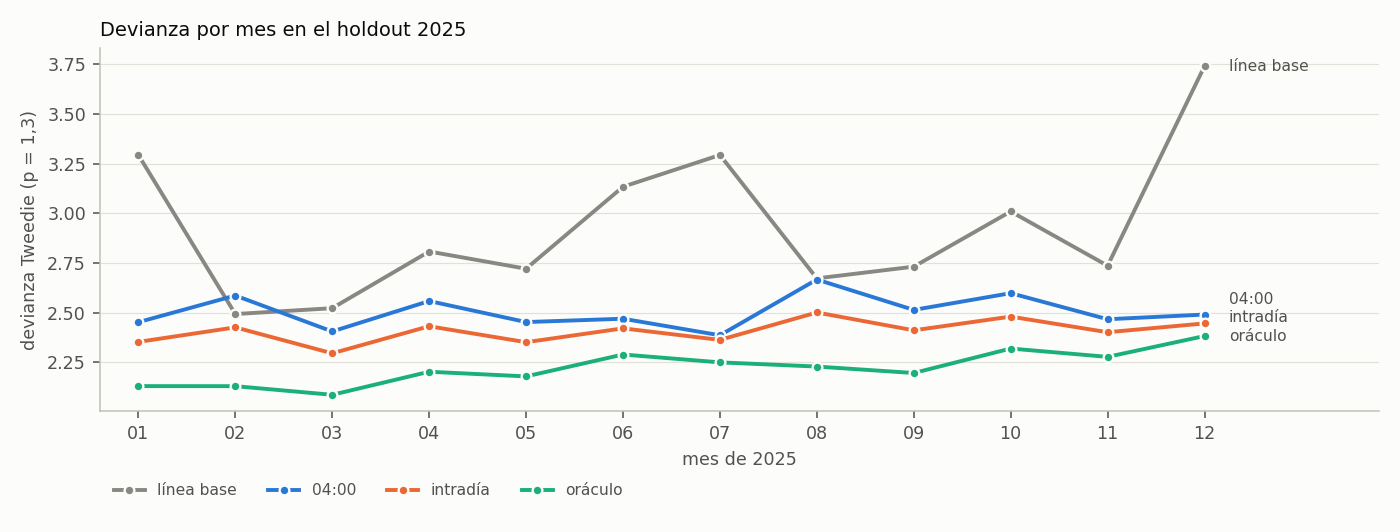

In [203]:
preds = {"linea_base": V.linea_base(t, ho)}
for m, (b, n) in finales_b.items():
    preds[m] = b.predict(ho[M.columnas(m)], num_iteration=n)
glob, des = E.evaluar_holdout(ho, preds)
des.to_csv(SALIDA / "holdout_desgloses_7_3.csv", index=False)
out = pd.DataFrame({"idprogramacion": ho.idprogramacion.to_numpy(), "idruta": ho.idruta.to_numpy(),
                    "fechasalida": ho.fechasalida.to_numpy(), "tipo_dia_cal": ho.tipo_dia_cal.astype(str).to_numpy(),
                    "y": ho.numeropasajeros.to_numpy(float), **{f"pred_{c}": p for c, p in preds.items()}})
out.to_parquet(SALIDA / "predicciones_holdout_7_3.parquet", index=False)
out.to_csv(SALIDA / "predicciones_holdout_7_3.csv.gz", index=False)
display(glob.round(4))
acc = E.criterio_aceptacion(glob, des)
check("Criterio de aceptación en 2025: modelo_0400 mejora la línea base (global y ≥ 10/12 meses)", acc["acepta"],
      f"mejora global {acc['mejora_global_%']:.1f} %; {acc['meses_que_mejoran']}/{acc['meses']} meses")
print(acc)
for dim in ["mes", "idruta", "tipo_dia_cal", "franja"]:
    display(des[des.dimension == dim].pivot(index="grupo", columns="config", values="devianza_tweedie").round(3)
            .join(des[(des.dimension == dim) & (des.config == "modelo_0400")].set_index("grupo")["mejora_dev_%"].round(1).rename("mejora 0400 %")))
E.fig_por_mes(des, "devianza_tweedie", FIG / "devianza_por_mes_2025.png", "Devianza por mes en el holdout 2025",
              "devianza Tweedie (p = 1,3)")
display(Image(filename=str(FIG / "devianza_por_mes_2025.png")))

**Conclusión 4 · Resultado en 2025 (evaluación única)**
- **Criterio de aceptación cumplido.** El modelo 04:00 logra una devianza de **2,503**, frente a 2,929 de la línea base: **−14,5 %**. Mejora en **11 de 12 meses**.
  - MAE: de 23,49 a **20,71** pasajeros por viaje.
- **Intradía:** 2,406 (−17,9 %). **Oráculo:** 2,222 (−24,1 %).
- **Mes que no cumple:** febrero empeora un 3,7 % (2,586 frente a 2,493). Agosto apenas mejora (0,2 %).
  - En ambos meses el modelo **subpredice** mucho: −7,3 y −6,5 pasajeros por viaje.
  - Hipótesis por verificar: es el regreso a clases después de vacaciones, y el calendario no tiene esa variable.
  - Los meses con más ganancia son diciembre (−33,4 %), julio (−27,5 %) y enero (−25,5 %), justo donde la línea base falla por la estacionalidad.
- **Por tipo de día:** laboral −15,2 %, sábado −18,7 %, festivo −16,8 % y carnaval −32,1 %.
  - **El domingo empeora un 2,1 %:** 2,344 frente a 2,295, con un sesgo de +10,0 pasajeros por viaje.
- **Por ruta:** 16 −11,8 %, 2 −17,1 % y 21 −17,2 %.
- **Por franja:** **04–06 h no mejora** (+0,4 %: 3,455 frente a 3,469) y subpredice −12,2 pasajeros por viaje. Las demás franjas mejoran entre un 15,8 % y un 23,4 %.
- **El modelo 04:00 queda por debajo en 2025:**
  - sesgo medio **−2,97 pasajeros por viaje** (−3,7 % de la media real de 80,63); la línea base sobrepredice +5,96;
  - la media de las predicciones es 77,66, frente a 78,88 de intradía y 80,16 del oráculo.

## 5 · Parte C — Test de sobreajuste (descriptivo)

Alertas: devianza del holdout / devianza en el ajuste > 1,5, o mejora sobre la línea base en 2025 por debajo de la del peor pliegue de la CV.

,modelo,dev_ajuste,dev_cv_media,dev_cv_std,dev_holdout,ratio_holdout_ajuste,mejora_holdout_%,peor_mejora_cv_%,alerta_ratio,alerta_mejora
0,modelo_0400,2.0134,2.4664,0.3333,2.5028,1.2431,14.5430,9.7537,False,False
1,modelo_intradia,1.8436,2.4530,0.3398,2.4058,1.3050,17.8574,8.6396,False,False
2,modelo_oraculo,1.7646,2.2969,0.2851,2.2216,1.2589,24.1475,18.8512,False,False


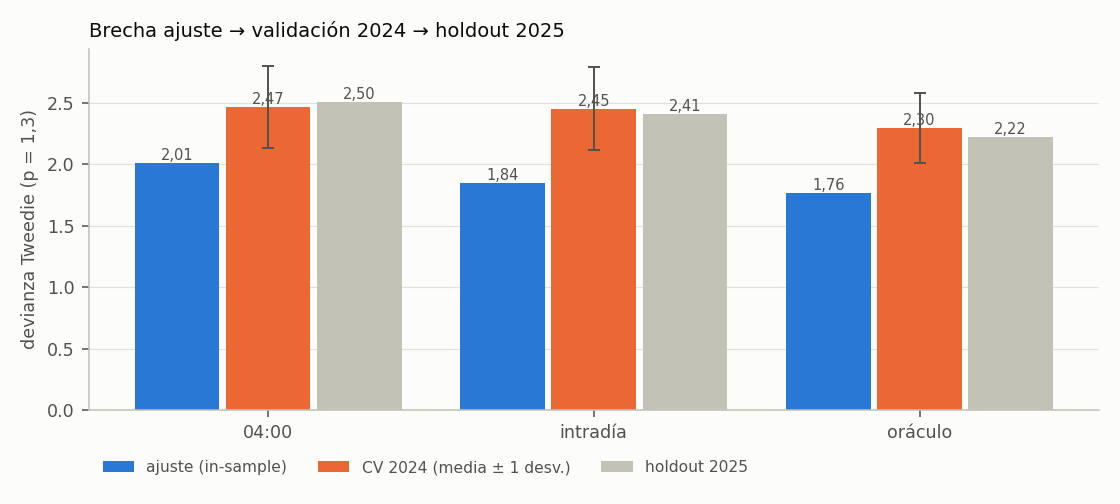

In [204]:
sob = E.sobreajuste(t, ho, finales_b, glob, r72)
sob.to_csv(SALIDA / "sobreajuste_7_3.csv", index=False)
display(sob.round(4))
for _, r in sob.iterrows():
    check(f"Sobreajuste · {r['modelo']}", not (r["alerta_ratio"] or r["alerta_mejora"]),
          f"holdout/ajuste = {r['ratio_holdout_ajuste']:.2f}; mejora 2025 {r['mejora_holdout_%']:.1f} % vs peor pliegue CV {r['peor_mejora_cv_%']:.1f} %",
          info=True)
E.fig_brecha(sob, FIG / "brecha_ajuste_cv_holdout.png")
display(Image(filename=str(FIG / "brecha_ajuste_cv_holdout.png")))

**Conclusión 5 · Sobreajuste**
- **No hay alertas.**
  - Holdout sobre ajuste: 1,24, 1,30 y 1,26 (umbral 1,5).
  - La mejora en 2025 (14,5 %, 17,9 % y 24,1 %) supera la del peor pliegue de la CV (9,8 %, 8,6 % y 18,9 %).
- **El modelo 04:00 generaliza como predijo la CV:**
  - 2025: 2,503.
  - CV 2024: 2,466 ± 0,333 con early stopping, y 2,488 en P2–P6 con rondas fijas.
  - La diferencia es del +0,6 % al +1,5 %, dentro de 1 desviación.
- La mejora sobre la línea base baja del 18,3 % (CV) al 14,5 % (2025).
- La brecha entre el ajuste (2,013) y 2025 (2,503) es la esperable para boosting: el ajuste se mide in-sample.

## 6 · Estabilidad con la semilla y curva de rondas en 2025 (descriptivas)

,modelo,semilla,n_arboles,devianza_tweedie,mae,sesgo_medio,n
0,modelo_0400,1,311,2.4720,20.6429,-2.5177,158507
1,modelo_0400,2,311,2.5124,20.7779,-3.3670,158507
2,modelo_0400,3,311,2.4840,20.6728,-2.6385,158507
3,modelo_0400,42,311,2.5028,20.7064,-2.9708,158507


Rango de la devianza 2025 entre semillas: 0.0403


,modelo,árboles usados,devianza 2025 con esos árboles,árboles del mínimo en 2025,devianza mínima 2025,% sobre el mínimo
0,modelo_0400,311,2.5028,95,2.3926,4.6088
1,modelo_intradia,649,2.4058,214,2.3534,2.2265
2,modelo_oraculo,461,2.2216,464,2.2214,0.0080


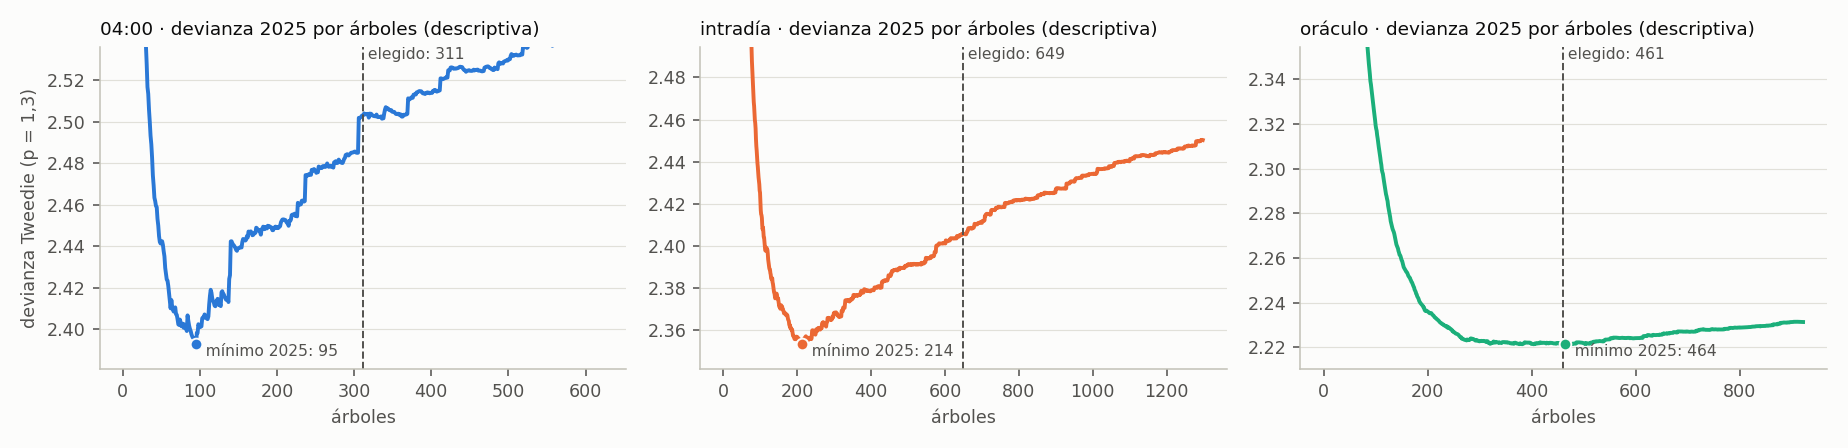

In [205]:
sem = E.semillas(t, ho, params["modelo_0400"], decision["modelos"]["modelo_0400"], NUM_THREADS, SEMILLAS, tope=TOPE)
sem = pd.concat([sem, pd.DataFrame([{"modelo": "modelo_0400", "semilla": 42, "n_arboles": finales_b["modelo_0400"][1],
                                     **V.metricas(ho.numeropasajeros.to_numpy(float), preds["modelo_0400"])}])], ignore_index=True)
sem.to_csv(SALIDA / "semillas_7_3.csv", index=False)
display(sem.round(4))
print(f"Rango de la devianza 2025 entre semillas: {sem.devianza_tweedie.max() - sem.devianza_tweedie.min():.4f}")
ch = []
for m in M.MODELOS:
    r_max = 2 * finales_b[m][1] if TOPE is None else TOPE
    ch.append(E.curva_holdout(t, ho, m, params[m], r_max, NUM_THREADS))
ch = pd.concat(ch, ignore_index=True)
ch.to_csv(SALIDA / "curva_rondas_holdout_7_3.csv.gz", index=False)
res = []
for m, g in ch.groupby("modelo"):
    n = finales_b[m][1]
    res.append({"modelo": m, "árboles usados": n, "devianza 2025 con esos árboles": float(g.devianza.iloc[n - 1]),
                "árboles del mínimo en 2025": int(g.iteracion[g.devianza.idxmin()]), "devianza mínima 2025": float(g.devianza.min()),
                "% sobre el mínimo": float(g.devianza.iloc[n - 1] / g.devianza.min() - 1) * 100})
display(pd.DataFrame(res).round(4))
E.fig_curva_holdout(ch, {m: n for m, (_, n) in finales_b.items()}, FIG / "curva_rondas_holdout_2025.png")
display(Image(filename=str(FIG / "curva_rondas_holdout_2025.png")))

**Conclusión 6 · Semillas y rondas en 2025 (descriptivas; no cambian ninguna decisión)**
- **Semillas (modelo 04:00):**
  - Devianza en 2025: 2,472 (semilla 1), 2,512 (2), 2,484 (3) y 2,503 (42).
  - Rango: **0,040 (1,6 %)**. Media: 2,493.
  - Las diferencias entre modelos en 2025 (intradía −0,097) superan ese rango. Para el Diebold-Mariano del Módulo 8 conviene usar la media de semillas o reportar este rango.
- **Rondas en 2025:**
  - **04:00:** 311 árboles quedan un **4,6 % por encima** del mínimo de 2025, que está en **95 árboles** (2,393).
  - **intradía:** 649 árboles quedan un 2,2 % por encima del mínimo, que está en 214.
  - **oráculo:** óptimo (464 frente a 461; 0,01 %).
- **Saltos en la curva del modelo 04:00:** la curva sube a saltos (cerca de 135, 250 y 310 árboles). Algunos árboles empeoran 2025 de golpe. Es el mismo patrón de P1 en la CV.
- **Hipótesis para el Módulo 8:** el *drift* de 2025 y la extrapolación de `tendencia_meses`, que en 2025 queda fuera del rango de entrenamiento y los árboles tratan como constante.
  - Se verifica con SHAP en la 8.2.
  - No se reajustan las rondas mirando 2025 (regla de oro).

## 7 · Riesgos de CLAUDE.md medidos en 2025 (descriptivos)

- **§11.9** Cierres tardíos: sesgo medio por mes y sensibilidad «sin features de totales» (solo informativa: la decisión de la 7.2 no cambia).
- **§11.12** Carnaval.
- **§5.11** Tendencia descendente: sesgo por mes a lo largo de 2025.

config,linea_base,modelo_0400,modelo_intradia,modelo_oraculo
grupo,,,,
2025-01,15.13,0.55,0.63,0.53
2025-02,-0.39,-7.28,-4.94,-2.39
2025-03,0.51,-4.39,-2.25,-0.59
2025-04,6.82,-2.37,-0.79,0.32
2025-05,4.53,-3.94,-2.14,-0.65
2025-06,11.99,-0.32,0.42,0.35
2025-07,14.18,-1.52,-1.22,-0.49
2025-08,-0.43,-6.51,-4.63,-2.15
2025-09,-0.20,-4.08,-2.81,-0.43


config,linea_base,modelo_0400,modelo_intradia,modelo_oraculo
grupo,,,,
carnaval,-10.31,-3.03,-2.20,-1.68
domingo,5.05,10.01,9.25,3.85
festivo,3.50,-2.71,-0.77,-0.79
laboral,6.56,-5.54,-3.92,-1.22
sabado,4.53,1.62,1.93,0.59


,config,devianza_tweedie,mae,sesgo_medio,n,columnas
0,modelo_0400,2.5028,20.7064,-2.9708,158507,NaN
1,modelo_0400 sin totales (informativo),2.5272,20.8537,-2.9276,158507,20.0


,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
con totales,0.55,-7.28,-4.39,-2.37,-3.94,-0.32,-1.52,-6.51,-4.08,-1.79,-2.54,-1.64
sin totales,2.05,-9.58,-6.20,-3.17,-4.36,0.61,-0.09,-6.97,-4.36,-1.16,-2.04,-0.11


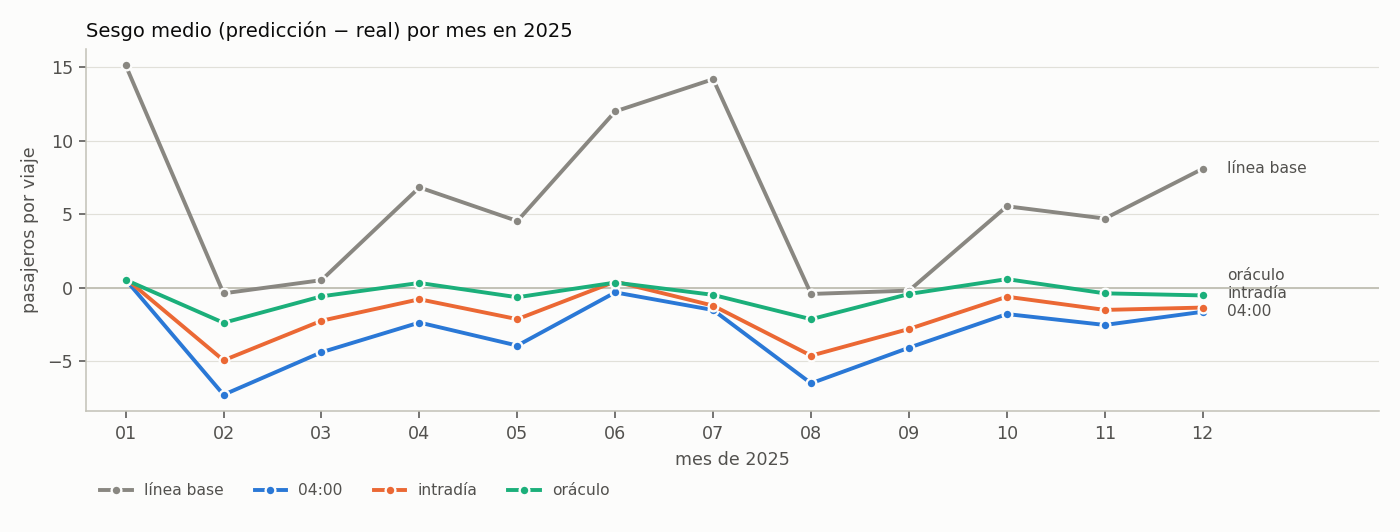

In [206]:
display(des[des.dimension == "mes"].pivot(index="grupo", columns="config", values="sesgo_medio").round(2))
display(des[des.dimension == "tipo_dia_cal"].pivot(index="grupo", columns="config", values="sesgo_medio").round(2))
cols_st = [c for c in M.columnas("modelo_0400") if c not in E.columnas_totales(M.columnas("modelo_0400"))]
bst, nst = E.entrenar_final(t, "modelo_0400", params["modelo_0400"], decision["modelos"]["modelo_0400"], NUM_THREADS,
                            cols=cols_st, tope=TOPE)
pst = bst.predict(ho[cols_st], num_iteration=nst)
y25 = ho.numeropasajeros.to_numpy(float)
mes = ho.fechasalida.dt.strftime("%Y-%m").to_numpy()
riesgo = pd.DataFrame([{"config": "modelo_0400", **V.metricas(y25, preds["modelo_0400"])},
                       {"config": "modelo_0400 sin totales (informativo)", "columnas": len(cols_st), **V.metricas(y25, pst)}])
riesgo.to_csv(SALIDA / "riesgo_totales_2025_7_3.csv", index=False)
display(riesgo.round(4))
display(pd.DataFrame({"con totales": pd.Series(preds["modelo_0400"] - y25).groupby(mes).mean(),
                      "sin totales": pd.Series(pst - y25).groupby(mes).mean()}).round(2).T)
E.fig_por_mes(des, "sesgo_medio", FIG / "sesgo_por_mes_2025.png", "Sesgo medio (predicción − real) por mes en 2025",
              "pasajeros por viaje", cero=True)
display(Image(filename=str(FIG / "sesgo_por_mes_2025.png")))

**Conclusión 7 · Riesgos de CLAUDE.md medidos en 2025**
- **§11.9 · cierres tardíos:** sin las features de totales, el modelo empeora en 2025 (2,527 frente a 2,503; +1,0 %) y el sesgo casi no cambia (−2,93 frente a −2,97).
  - **Las features de totales siguen aportando, y la subpredicción no viene de ellas.**
  - Se mantienen.
- **§11.12 · carnaval: el riesgo de la 7.2 no se repite en 2025.**
  - El modelo 04:00 **subpredice** −3,0 pasajeros por viaje en carnaval (826 viajes), cuando en la CV 2024 sobrepredecía +5,9.
  - La devianza mejora un 32,1 %.
  - Se corrige el riesgo §11.12: el sesgo de carnaval cambia de signo entre años, porque hay solo ~4 días por año.
- **§5.11 · tendencia:**
  - La línea base sobrepredice todo el año (+5,96 de media; hasta +15,1 en enero), porque no tiene tendencia.
  - El modelo 04:00 corrige ese exceso, pero se pasa al otro lado: subpredice en 11 de 12 meses (de −0,3 a −7,3).
  - El sesgo sistemático es ahora negativo: **−2,97 pasajeros por viaje**.
- **Pendientes para el Módulo 8 (residuos):** franja 04–06 h (−12,2), domingos (+10,0) y febrero/agosto.
- **Precisión (8.1):** el sesgo de −2,97 no es uniforme. El modelo 04:00 subpredice de lunes a viernes (+4,2 a +8,3 pasajeros por viaje) y sobrepredice el domingo (−9,6): comprime el contraste semanal (domingo/laboral predicho 0,842 frente a 0,671 real). Ver la 8.1, conclusión 5.

## 8 · Pruebas (a–f) y checks

In [207]:
pruebas = T.correr_todos(X, s)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min con {NUM_THREADS} hilos", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_7_3.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · regla de rondas anidada sin leakage,PASS,"alterar el pliegue k y posteriores no cambia la regla de k · modelo_0400: P2=283, P3=311, P4=339, P5=311, P6=339 · m..."
1,Test b · el modelo final no ve 2025,PASS,"324.508 viajes de entrenamiento: última salida 2024-12-31 18:40:00, último cierre 2024-12-31 21:53:44 (≤ 2025-01-01 ..."
2,Test c · parámetros de la 7.2 y decisión antes del holdout,PASS,hash 428a3fb5f20d… idéntico en la decisión y en los 3 modelos; decisión escrita antes de holdout_7_3.csv
3,Test d · determinismo del modelo final,PASS,158.507 predicciones idénticas en dos entrenamientos finales
4,Test e · columnas exactas por modelo,PASS,"modelo_0400: 33 columnas, 311 árboles; modelo_intradia: 45 columnas, 649 árboles; modelo_oraculo: 53 columnas, 461 á..."
5,Test f · predicciones del holdout completas,PASS,"158.507 filas por modelo, sin NaN, todas > 0; el modelo 04:00 guardado reproduce sus predicciones"


,check,resultado,detalle
0,Decisión de rondas · modelo_0400,INFO,rondas_fijas (311); 4/5 pliegues
1,Decisión de rondas · modelo_intradia,INFO,rondas_fijas (649); 5/5 pliegues
2,Decisión de rondas · modelo_oraculo,INFO,rondas_fijas (461); 5/5 pliegues
3,Criterio de aceptación en 2025: modelo_0400 mejora la línea base (global y ≥ 10/12 meses),PASS,mejora global 14.5 %; 11/12 meses
4,Sobreajuste · modelo_0400,INFO,holdout/ajuste = 1.24; mejora 2025 14.5 % vs peor pliegue CV 9.8 %
5,Sobreajuste · modelo_intradia,INFO,holdout/ajuste = 1.30; mejora 2025 17.9 % vs peor pliegue CV 8.6 %
6,Sobreajuste · modelo_oraculo,INFO,holdout/ajuste = 1.26; mejora 2025 24.1 % vs peor pliegue CV 18.9 %
7,Test a · regla de rondas anidada sin leakage,PASS,"alterar el pliegue k y posteriores no cambia la regla de k · modelo_0400: P2=283, P3=311, P4=339, P5=311, P6=339 · m..."
8,Test b · el modelo final no ve 2025,PASS,"324.508 viajes de entrenamiento: última salida 2024-12-31 18:40:00, último cierre 2024-12-31 21:53:44 (≤ 2025-01-01 ..."
9,Test c · parámetros de la 7.2 y decisión antes del holdout,PASS,hash 428a3fb5f20d… idéntico en la decisión y en los 3 modelos; decisión escrita antes de holdout_7_3.csv


PASS 7 · FAIL 0 · INFO 7


**Conclusión 8 · Cierre del Módulo 7**
- **Pasan las 6 de 6 pruebas:**
  - **a)** la regla de rondas es anidada y no tiene leakage;
  - **b)** el modelo final no ve 2025;
  - **c)** el hash de los parámetros se conserva y la decisión se escribió antes del holdout;
  - **d)** determinismo: 158.507 predicciones idénticas;
  - **e)** cada modelo tiene sus columnas exactas (33, 45 y 53) y sus árboles (311, 649 y 461);
  - **f)** predicciones completas.
- Criterio de aceptación en 2025: **PASS**. Ejecución: 7,0 min con 12 hilos.
- **Corrección a la 7.2:** la ganancia de la cascada intradía no era del 0,5 %.
  - Ese valor estaba deprimido por el early stopping, que en P4 cortó intradía en 87 árboles.
  - Con rondas fijas, intradía mejora un **1,7 %** sobre el modelo 04:00 en la CV (P2–P6) y un **3,9 %** en 2025.
  - Recupera el 26 % (CV) y el **34 %** (2025) de la brecha entre 04:00 y el oráculo.
  - **La cascada sí aporta.**
- **Insumos para el Módulo 8:**
  - `datos_7/predicciones_holdout_7_3.parquet`: y, más las predicciones de la línea base y de los 3 modelos para los 158.507 viajes.
  - `modelos_7_3/*.txt`: para SHAP (TreeSHAP).

---
# Parte 17 · Subfase 8.1 · Residuos
*Notebook original: `subfase_8_1_residuos.ipynb`*

In [208]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_8_1_residuos.ipynb")

── Inicio de subfase_8_1_residuos.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 8.1 — Diagnóstico fino de residuos (Ljung-Box, McLeod-Li, BDS)

**Persona 3 · MLOps & Model Evaluation.** Diagnostica los residuos del holdout 2025 de los modelos finales de la 7.3 (y de la línea base, como contraste). **No reentrena ni corrige nada**: 2025 ya se usó para evaluar; cualquier propuesta queda para el Entregable 2.

| Elemento | Decisión |
|---|---|
| Insumo | `datos_7/predicciones_holdout_7_3.parquet` (158.507 viajes de 2025) + covariables de `validacion_7_1.cargar()` solo para desgloses |
| Residuos | crudo e = y − ŷ (pasajeros), de Pearson r = (y − ŷ)/√ŷ^1,3 y de devianza (p = 1,3, la de la métrica, para comparar modelos) |
| Escalas | **Diaria** por ruta (365 días × 3, equiespaciada) y **por viaje** (por ruta, ordenados por salida; también solo dentro de cada día) |
| Tests | Ljung-Box (autocorrelación), McLeod-Li (Ljung-Box sobre r²: volatilidad agrupada), BDS (dependencia no lineal, tras filtrar un AR(k) por AIC) |
| Criterio | Con n grande todo es «significativo»: se decide por **magnitud**. \|ρ\| ≥ 0,10 relevante; 0,05–0,10 débil. En tests por bloques, proporción de bloques que rechazan con Benjamini-Hochberg |
| Implementación | numpy + `scipy.stats`; verificada contra statsmodels (Ljung-Box, ACF, PACF y BDS idénticos) en `tests_8_1.py` |

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [209]:
import json
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import Image, display

import residuos_8_1 as R
import tests_8_1 as T
import validacion_7_1 as V

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_8"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_8_1"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


T0 = time.time()
HASH_ANTES = T.hashes()
X = V.cargar()
d = R.cargar_residuos(X)
cols = ["idprogramacion", "idruta", "fechasalida", "fecha", "tipo_dia_cal", "dia_semana", "hora", "y"] + \
       [f"{k}_{c}" for c in R.CONFIGS for k in ("pred", "e", "r", "rd", "dev")]
d[cols].to_parquet(SALIDA / "residuos_8_1.parquet", index=False)
print(f"Python {platform.python_version()} · pandas {pd.__version__} · statsmodels para verificar: {T.HAY_SM}")
print(f"{len(d):,} viajes de 2025 · por ruta: {d.groupby('idruta').size().to_dict()} · días: {d.fecha.nunique()}")

Python 3.10.0 · pandas 2.3.3 · statsmodels para verificar: True
158,507 viajes de 2025 · por ruta: {2: 44910, 16: 85558, 21: 28039} · días: 365


## 1 · Residuos, función de varianza y calibración

,config,residuo medio e (pas.),sesgo ŷ − y,MAE,φ = media(r²),devianza media
0,linea_base,-5.955,5.955,23.485,2.618,2.929
1,modelo_0400,2.971,-2.971,20.706,2.642,2.503
2,modelo_intradia,1.754,-1.754,20.380,2.470,2.406
3,modelo_oraculo,0.478,-0.478,19.670,2.216,2.222


media_pred                                               media_y                                                 sesgo                                                   phi              \
config linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400   
decil                                                                                                                                                                                             
0           49.99       42.15           43.13          42.31      45.86       44.15           43.43          41.66       4.14       -2.00           -0.30           0.65       2.47        3.29   
1           59.99       54.03           55.01          54.57      56.07       57.22           56.63          54.17       3.92       -3.19           -1.62           0.41       2.45        3.34   
2           70.23       62.59           63.13          62.26      65.89       62.60           62.11          62.21       4.35       -0.01            1.02           0.04       2.88        3.05   
3           82.76       69.46           69.85          69.81      75.67       70.18           70.55          69.87       7.09       -0.72           -0.70          -0.06       2.84        2.79   
4           87.73       75.35           75.98          76.88      80.51       77.06           76.45          77.54       7.23       -1.70           -0.46          -0.66       2.88        2.63   
5           92.37       80.90           81.87          83.60      86.24       84.02           83.92          84.33       6.13       -3.12           -2.05          -0.74       3.02        2.58   
6           97.39       86.48           87.93          90.43      91.89       90.69           91.17          91.51       5.50       -4.21           -3.24          -1.08       2.75        2.44   
7          102.75       92.49           94.39          97.50      97.01       98.20           98.25          98.57       5.74       -5.71           -3.85          -1.07       2.56        2.31   
8          107.90       99.38          101.69         105.18     101.69      104.90          105.64         106.72       6.21       -5.52           -3.94          -1.54       2.20        2.12   
9          116.10      113.82          115.81         119.03     106.86      117.34          118.21         119.77       9.24       -3.52           -2.40          -0.75       2.08        1.87   

                                       
config modelo_intradia modelo_oraculo  
decil                                  
0                 2.84           2.35  
1                 3.09           2.38  
2                 2.79           2.58  
3                 2.70           2.51  
4                 2.57           2.41  
5                 2.41           2.33  
6                 2.33           2.17  
7                 2.17           1.90  
8                 2.02           1.89  
9                 1.77           1.64

,p empírico de la varianza residual (pendiente log-log)
linea_base,1.175
modelo_0400,0.668
modelo_intradia,0.749
modelo_oraculo,0.943


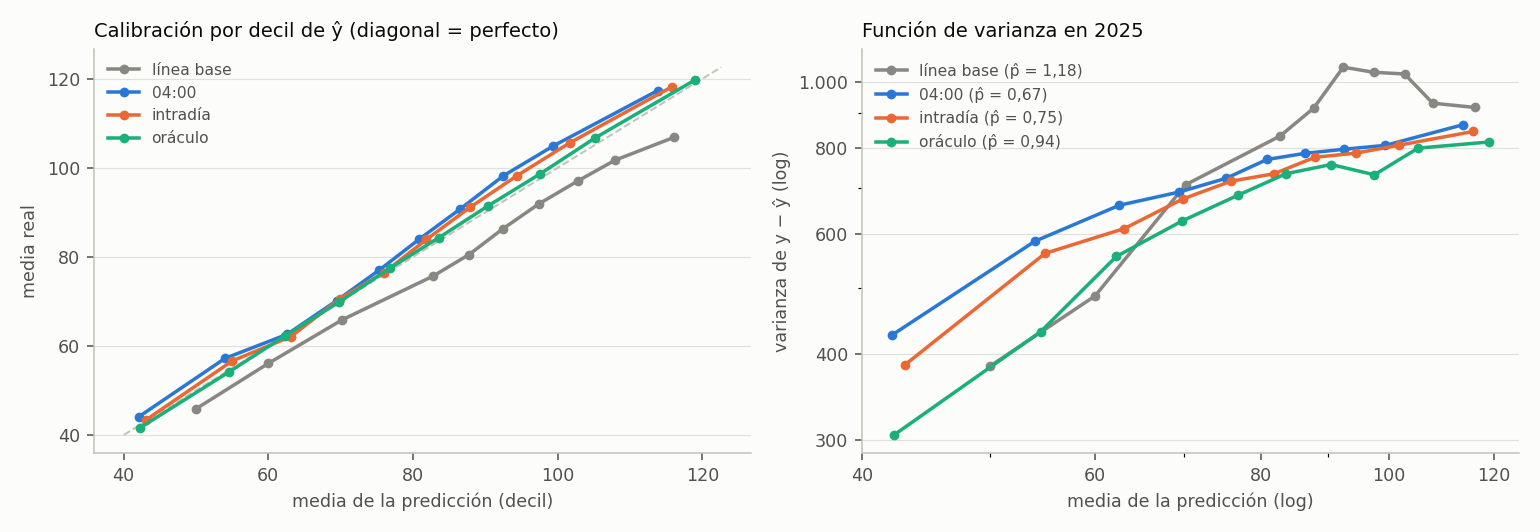

In [210]:
res = pd.DataFrame([{"config": c, "residuo medio e (pas.)": d[f"e_{c}"].mean(), "sesgo ŷ − y": -d[f"e_{c}"].mean(),
                     "MAE": d[f"e_{c}"].abs().mean(), "φ = media(r²)": float(np.mean(d[f"r_{c}"] ** 2)),
                     "devianza media": d[f"dev_{c}"].mean()} for c in R.CONFIGS])
display(res.round(3))
var, pend = [], {}
for c in R.CONFIGS:
    t, p = R.funcion_varianza(d, c)
    var.append(t); pend[c] = p
var = pd.concat(var, ignore_index=True)
var.to_csv(SALIDA / "varianza_calibracion_8_1.csv", index=False)
display(var.pivot(index="decil", columns="config", values=["media_pred", "media_y", "sesgo", "phi"]).round(2))
display(pd.Series(pend, name="p empírico de la varianza residual (pendiente log-log)").round(3).to_frame())
R.fig_calibracion(var, pend, FIG / "calibracion_varianza.png")
display(Image(filename=str(FIG / "calibracion_varianza.png")))

**Conclusión 1 · Residuos, varianza y calibración**
- **Residuo medio (real − predicho, pasajeros por viaje):**

  | Modelo | Residuo medio | φ = media(r²) | Lectura |
  |---|---:|---:|---|
  | Línea base | −5,96 | 2,62 | sobrepredice |
  | 04:00 | **+2,97** | 2,64 | subpredice |
  | Intradía | +1,75 | 2,47 | subpredice |
  | Oráculo | +0,48 | 2,22 | casi sin sesgo |

- **Calibración (por decil de la predicción):**
  - El modelo 04:00 **subpredice en 9 de 10 deciles**, sobre todo con ŷ de 86 a 114 (sesgo ŷ − y de −3,5 a −5,7).
  - La línea base sobrepredice en todos los deciles (+3,9 a +9,2) y su curva es más plana: discrimina menos.
  - El oráculo está calibrado: |sesgo| ≤ 1,5.
- **Función de varianza:**
  - En el modelo 04:00, φ baja de 3,29 (decil más bajo) a 1,87 (más alto).
  - p empírico de la varianza residual: 0,67 (04:00), 0,75 (intradía) y 0,94 (oráculo), frente a 1,18 de la línea base.
  - La varianza de los errores crece más despacio que μ^1,3: los errores relativos pesan más en los viajes de baja demanda.
  - La métrica no cambia (p = 1,3 fijo).

## 2 · Autocorrelación lineal — Ljung-Box

**Escala diaria:** residuo de Pearson medio por ruta × día (365 días; sin días vacíos). **Escala de viaje:** por ruta, viajes ordenados por salida (serie completa), y la ACF solo **dentro del mismo día** (Box-Pierce agrupado). Además, el residuo **intradía** = r − media de su ruta × día, que quita el componente común del día y deja solo los shocks entre viajes.

diaria


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.627        0.420            0.340           0.278
       7            0.438        0.549            0.432           0.222
       14           0.328        0.527            0.418           0.161
       28           0.114        0.426            0.337           0.086
16     1            0.603        0.298            0.254           0.274
       7            0.307        0.656            0.660           0.429
       14           0.246        0.649            0.670           0.489
       28           0.041        0.568            0.596           0.359
21     1            0.549        0.408            0.350           0.302
       7            0.305        0.504            0.399           0.214
       14           0.273        0.497            0.395           0.246
       28           0.157        0.472            0.392           0.251

viaje (serie completa)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.217        0.139            0.105           0.022
       5            0.129        0.113            0.080           0.006
       10           0.086        0.088            0.059           0.008
       20           0.047        0.042            0.025           0.007
16     1            0.284        0.253            0.241           0.162
       5            0.120        0.109            0.092          -0.023
       10           0.107        0.119            0.101           0.015
       20           0.066        0.088            0.074           0.008
21     1            0.110        0.032            0.012          -0.064
       5            0.067        0.096            0.079           0.019
       10           0.037        0.054            0.040           0.009
       20           0.061        0.041            0.028           0.013

viaje (dentro del día)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.218        0.142            0.107           0.023
       5            0.137        0.123            0.089           0.007
       10           0.094        0.109            0.077           0.012
       20           0.048        0.067            0.045           0.008
16     1            0.285        0.255            0.243           0.163
       5            0.126        0.114            0.097          -0.022
       10           0.113        0.127            0.109           0.015
       20           0.075        0.105            0.089           0.010
21     1            0.113        0.035            0.015          -0.064
       5            0.078        0.111            0.092           0.025
       10           0.036        0.070            0.054           0.009
       20           0.081        0.063            0.050           0.020

viaje intradía (sin media del día)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.145        0.084            0.067           0.009
       5            0.053        0.064            0.049          -0.008
       10           0.006        0.050            0.037          -0.002
       20          -0.046        0.007            0.005          -0.006
16     1            0.227        0.191            0.190           0.150
       5            0.055        0.037            0.032          -0.040
       10           0.040        0.050            0.044          -0.001
       20          -0.002        0.027            0.022          -0.007
21     1            0.046       -0.033           -0.036          -0.088
       5            0.007        0.047            0.045           0.002
       10          -0.038        0.003            0.005          -0.013
       20           0.010        0.002            0.005          -0.001

p-valores de la escala diaria (Ljung-Box):


config        linea_base modelo_0400 modelo_intradia modelo_oraculo
idruta rezago                                                      
2      1         2.8e-33     8.4e-16         6.7e-11        9.4e-08
       7         8.6e-94     2.0e-40         7.5e-24        1.3e-12
       14       7.3e-138     4.9e-68         6.0e-37        1.3e-11
       28       8.7e-159    3.4e-121         2.6e-67        3.2e-11
16     1         5.4e-31     1.1e-08         1.1e-06        1.4e-07
       7         6.7e-94     4.6e-46         8.6e-45        7.7e-21
       14       1.3e-125     1.4e-87         8.6e-88        4.6e-38
       28       2.8e-131    2.0e-166        7.2e-168        2.7e-60
21     1         5.6e-26     4.7e-15         1.9e-11        6.7e-09
       7         4.6e-69     7.2e-35         1.1e-21        1.1e-10
       14        1.5e-94     8.6e-60         9.3e-35        2.5e-13
       28       1.8e-103    6.6e-115         5.5e-66        1.1e-20

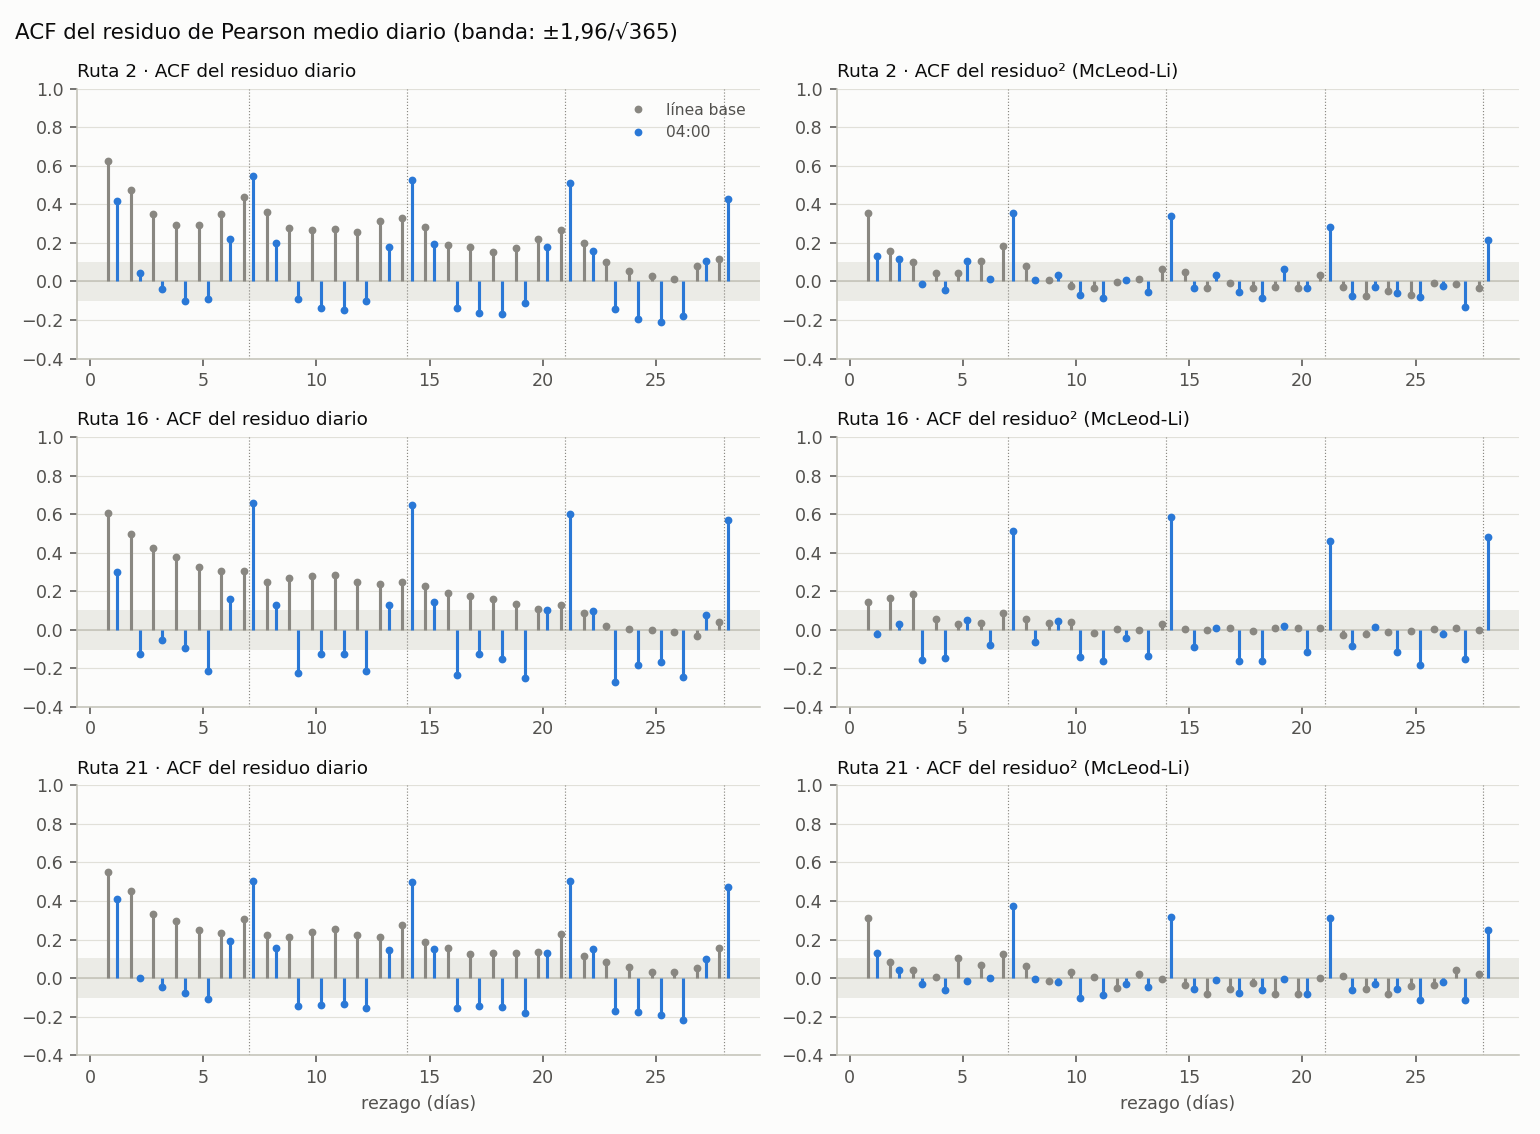

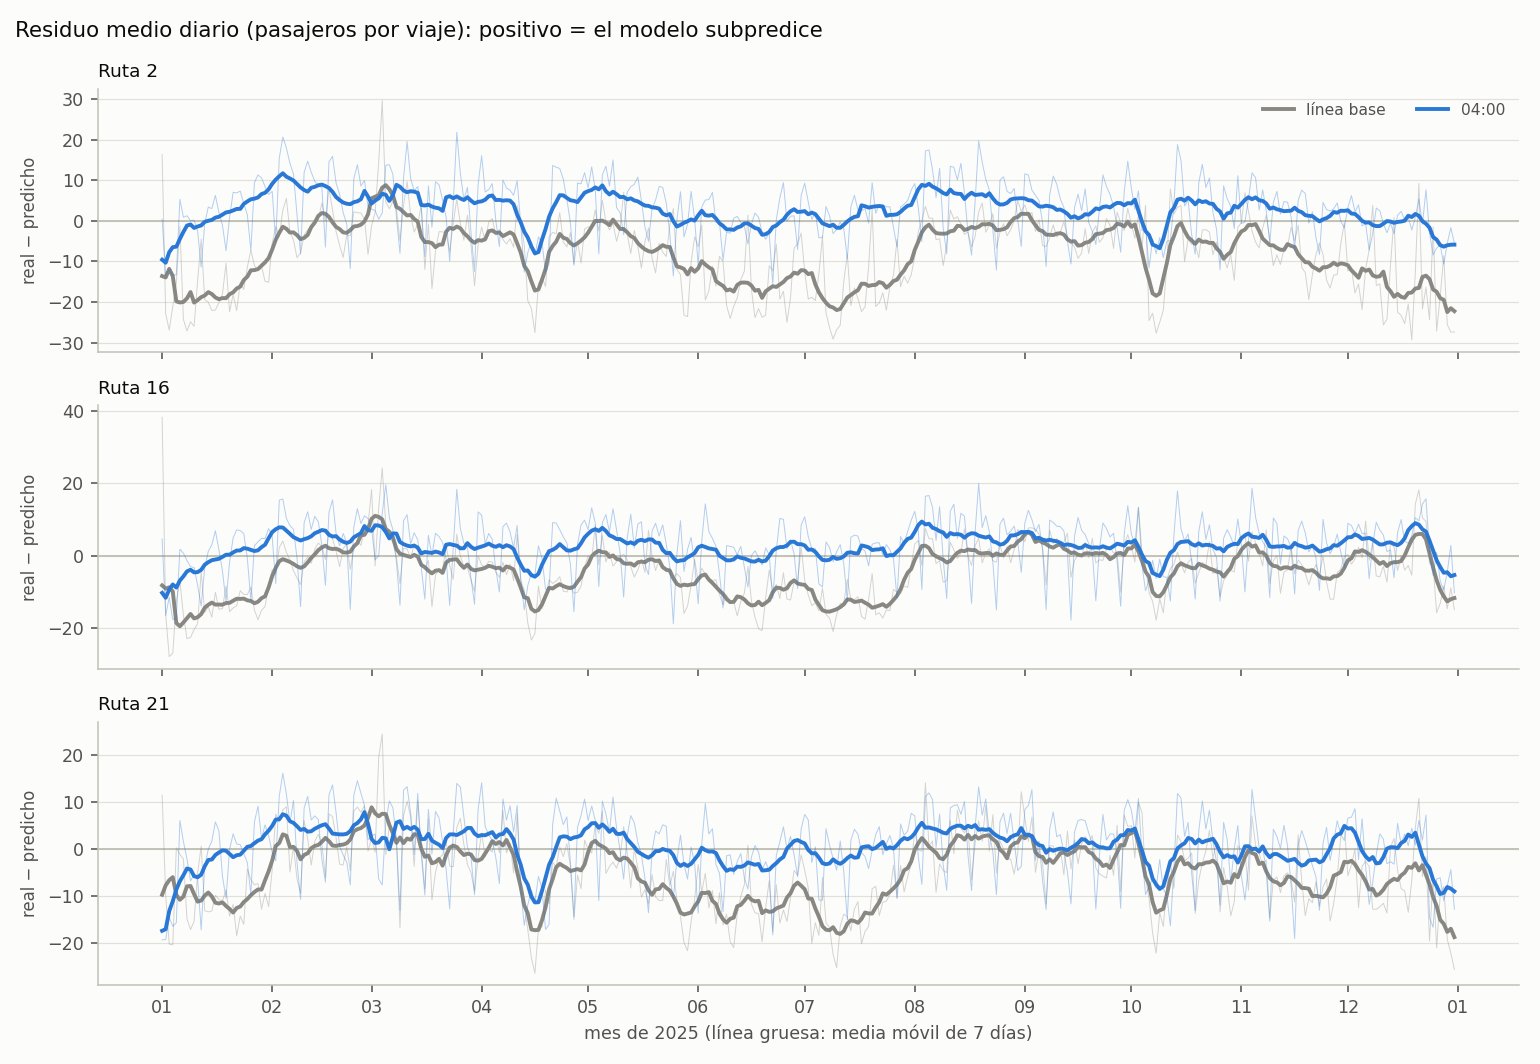

In [211]:
LAGS_D, LAGS_V = [1, 7, 14, 28], [1, 5, 10, 20]
lb, acfs = [], {}
for c in R.CONFIGS:
    sd = R.serie_diaria(d, f"r_{c}")
    for rt, g in sd.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        acfs.setdefault(rt, {})[f"acf_{c}"] = R.acf(x, 28)
        acfs[rt][f"acf2_{c}"] = R.acf((x - x.mean()) ** 2, 28)
        lb.append(R.ljung_box(x, LAGS_D).assign(config=c, idruta=rt, escala="diaria"))
for c in R.CONFIGS:
    for rt, g in d.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        dia = (g.idruta.astype(str) + "_" + g.fecha.astype(str)).to_numpy()
        intradia = x - pd.Series(x).groupby(dia).transform("mean").to_numpy()
        lb.append(R.ljung_box(x, LAGS_V).assign(config=c, idruta=rt, escala="viaje (serie completa)"))
        lb.append(R.box_pierce_agrupado(x, dia, LAGS_V).assign(config=c, idruta=rt, escala="viaje (dentro del día)"))
        lb.append(R.box_pierce_agrupado(intradia, dia, LAGS_V).assign(config=c, idruta=rt, escala="viaje intradía (sin media del día)"))
lb = pd.concat(lb, ignore_index=True)
lb["magnitud_rho_h"] = lb.rho_h.map(R.magnitud)
lb.to_csv(SALIDA / "ljungbox_8_1.csv", index=False)
for esc in lb.escala.unique():
    print(esc)
    display(lb[lb.escala == esc].pivot_table(index=["idruta", "rezago"], columns="config", values="rho_h").round(3))
print("p-valores de la escala diaria (Ljung-Box):")
display(lb[lb.escala == "diaria"].pivot_table(index=["idruta", "rezago"], columns="config", values="p_valor").map(lambda p: f"{p:.1e}"))
n_dias = 365
R.fig_acf_diaria(acfs, n_dias, FIG / "acf_residuo_diario.png", "ACF del residuo de Pearson medio diario (banda: ±1,96/√365)")
display(Image(filename=str(FIG / "acf_residuo_diario.png")))
diario_e = pd.concat([R.serie_diaria(d, f"e_{c}").set_index(["idruta", "fecha"]) for c in R.CONFIGS], axis=1).reset_index()
R.fig_residuo_diario(diario_e, FIG / "residuo_diario_2025.png")
display(Image(filename=str(FIG / "residuo_diario_2025.png")))

**Conclusión 2 · Autocorrelación (Ljung-Box)**
- **Todos los tests rechazan** (p < 1e-8 en la escala diaria), así que se lee la magnitud.
- **Persistencia del nivel (rezago de 1 día):** el modelo 04:00 la reduce de 0,55–0,63 (línea base) a **0,30–0,42**. Sigue siendo relevante: queda un nivel que dura varios días (*drift*).
- **Patrón semanal (rezago de 7 días):**
  - El modelo 04:00 lo **aumenta**: de 0,31–0,44 en la línea base a **0,50–0,66**.
  - Se repite en 14 y 28 días (0,43–0,65).
  - El modelo deja un error que se repite cada semana, el mismo día de la semana.
  - El oráculo lo reduce a 0,21–0,43.
- **Por viaje:**
  - ACF entre viajes consecutivos: 0,14 (ruta 2), 0,25 (ruta 16) y 0,03 (ruta 21). Es casi igual si solo se miran pares del mismo día.
  - Al quitar la media de cada ruta × día queda 0,08 / **0,19** / −0,03.
  - La correlación entre viajes es sobre todo el componente común del día. Solo en la ruta 16 quedan shocks propios entre viajes seguidos.

## 3 · Volatilidad agrupada — McLeod-Li y dispersión por segmento

In [212]:
ml = []
for c in R.CONFIGS:
    sd = R.serie_diaria(d, f"r_{c}")
    for rt, g in sd.groupby("idruta"):
        ml.append(R.mcleod_li(g[f"r_{c}"].to_numpy(), LAGS_D).assign(config=c, idruta=rt, escala="diaria"))
    for rt, g in d.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        dia = (g.idruta.astype(str) + "_" + g.fecha.astype(str)).to_numpy()
        intradia = x - pd.Series(x).groupby(dia).transform("mean").to_numpy()
        ml.append(R.mcleod_li(x, LAGS_V).assign(config=c, idruta=rt, escala="viaje (serie completa)"))
        r2 = (intradia - intradia.mean()) ** 2
        ml.append(R.box_pierce_agrupado(r2, dia, LAGS_V).assign(config=c, idruta=rt, escala="viaje intradía (sin media del día)"))
ml = pd.concat(ml, ignore_index=True)
ml["magnitud_rho_h"] = ml.rho_h.map(R.magnitud)
ml.to_csv(SALIDA / "mcleodli_8_1.csv", index=False)
for esc in ml.escala.unique():
    print(esc)
    display(ml[ml.escala == esc].pivot_table(index=["idruta", "rezago"], columns="config", values="rho_h").round(3))
franja = pd.cut(d.hora, [3, 6, 9, 12, 15, 18, 21], labels=["04–06", "07–09", "10–12", "13–15", "16–18", "19–20"])
disp = []
for nom, g in [("franja", franja.astype(str)), ("tipo_dia_cal", d.tipo_dia_cal.astype(str)),
               ("mes", d.fechasalida.dt.strftime("%m")), ("idruta", d.idruta.astype(str))]:
    for c in ["linea_base", "modelo_0400"]:
        t = (d[f"r_{c}"] ** 2).groupby(g.to_numpy()).mean()
        disp.append(pd.DataFrame({"dimension": nom, "grupo": t.index, "config": c, "phi": t.values}))
disp = pd.concat(disp, ignore_index=True)
display(disp.pivot_table(index=["dimension", "grupo"], columns="config", values="phi").round(2))

diaria


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.356        0.130            0.160           0.057
       7            0.185        0.353            0.275           0.054
       14           0.062        0.340            0.253           0.010
       28          -0.034        0.216            0.138           0.049
16     1            0.146       -0.022           -0.047           0.046
       7            0.086        0.513            0.548           0.287
       14           0.030        0.583            0.657           0.465
       28          -0.001        0.479            0.581           0.388
21     1            0.314        0.132            0.139           0.071
       7            0.123        0.373            0.232           0.077
       14          -0.003        0.319            0.208           0.063
       28           0.019        0.249            0.138           0.038

viaje (serie completa)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.090        0.074            0.068           0.048
       5            0.031        0.049            0.043           0.015
       10           0.008        0.022            0.013           0.001
       20          -0.008       -0.022           -0.021          -0.018
16     1            0.180        0.079            0.086           0.090
       5            0.060        0.037            0.029           0.012
       10           0.045        0.036            0.022           0.010
       20           0.034        0.021            0.019           0.009
21     1            0.122        0.073            0.071           0.066
       5            0.051        0.083            0.081           0.058
       10           0.014        0.010            0.005           0.001
       20           0.006       -0.010           -0.005          -0.004

viaje intradía (sin media del día)


config         linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta rezago                                                          
2      1            0.091        0.066            0.062           0.047
       5            0.033        0.044            0.040           0.018
       10           0.010        0.022            0.014           0.004
       20          -0.001       -0.007           -0.008          -0.012
16     1            0.154        0.080            0.089           0.091
       5            0.052        0.033            0.028           0.013
       10           0.038        0.029            0.020           0.010
       20           0.022        0.017            0.015           0.006
21     1            0.127        0.084            0.081           0.077
       5            0.046        0.085            0.084           0.061
       10           0.012        0.015            0.011           0.004
       20           0.009       -0.001            0.004          -0.000

config                 linea_base  modelo_0400
dimension    grupo                            
franja       04–06           3.05         4.28
             07–09           2.38         2.13
             10–12           2.75         2.42
             13–15           2.20         2.00
             16–18           2.63         2.29
             19–20           2.68         2.07
idruta       16              2.39         2.42
             2               2.96         3.07
             21              2.76         2.65
mes          01              2.64         2.49
             02              2.44         2.92
             03              2.47         2.58
             04              2.49         2.71
             05              2.47         2.59
             06              2.59         2.50
             07              2.67         2.45
             08              2.61         2.95
             09              2.61         2.66
             10              2.70         2.72
             11              2.49         2.59
             12              3.26         2.55
tipo_dia_cal carnaval        4.06         2.43
             domingo         2.07         1.95
             festivo         2.06         1.94
             laboral         2.68         2.83
             sabado          2.72         2.30

**Conclusión 3 · Volatilidad (McLeod-Li)**
- **Volatilidad semanal:** los errores grandes se repiten el mismo día de la semana.
  - ACF de r² diario a 7 días: **0,35–0,51** en el modelo 04:00, frente a 0,09–0,19 en la línea base.
  - A 1 día es baja: −0,02 a 0,13.
- **Por viaje:** la volatilidad agrupada es débil (0,07–0,08 a 1 viaje).
- **Dispersión φ del modelo 04:00 por segmento:**
  - **Franja 04–06 h: 4,28**, frente a 3,05 de la línea base. Es la única franja donde el modelo dispersa más que la línea base.
  - Laboral 2,83 (línea base 2,68).
  - Febrero 2,92 y agosto 2,95: los meses más dispersos.
  - Mejora frente a la línea base en carnaval (2,43 frente a 4,06) y en diciembre (2,55 frente a 3,26).

## 4 · Dependencia no lineal — BDS

Primero se quita la dependencia **lineal** con un AR(k), k ≤ 7 por AIC (incluye el rezago semanal); el BDS sobre esos residuos filtrados detecta dependencia **no lineal**. ε = 0,5 y 1,0 desviaciones estándar; m = 2–5. Escala diaria por ruta (n = 365) y por viaje en bloques consecutivos de 2.000 viajes por ruta (con Benjamini-Hochberg).

In [213]:
bd = []
for c in R.CONFIGS:
    sd = R.serie_diaria(d, f"r_{c}")
    for rt, g in sd.groupby("idruta"):
        x = g[f"r_{c}"].to_numpy()
        k, _, filt = R.ar_filtrar(x, 7)
        for dist in (0.5, 1.0):
            bd.append(R.bds(x, 5, dist).assign(config=c, idruta=rt, escala="diaria", filtro="sin filtrar", k_ar=0))
            bd.append(R.bds(filt, 5, dist).assign(config=c, idruta=rt, escala="diaria", filtro=f"AR({k})", k_ar=k))
bd = pd.concat(bd, ignore_index=True)
display(bd[bd.distancia == 1.0].pivot_table(index=["idruta", "filtro", "m"], columns="config", values="estadistico").round(2))
bloq = []
for c in R.CONFIGS:
    for rt, g in d.groupby("idruta"):
        for i, b in enumerate(R.bloques(g[f"r_{c}"].to_numpy(), 2000)):
            k, _, filt = R.ar_filtrar(b, 7)
            t = R.bds(filt, 5, 1.0)
            bloq.append(t.assign(config=c, idruta=rt, bloque=i, k_ar=k))
bloq = pd.concat(bloq, ignore_index=True)
bloq["rechaza_BH"] = False
for (c, m), idx in bloq.groupby(["config", "m"]).groups.items():
    bloq.loc[idx, "rechaza_BH"] = R.bh(bloq.loc[idx, "p_valor"].to_numpy())
pd.concat([bd, bloq.assign(escala="viaje (bloques de 2.000, AR filtrado)", filtro="AR por bloque", distancia=1.0)],
          ignore_index=True).to_csv(SALIDA / "bds_8_1.csv", index=False)
res_b = bloq.groupby(["config", "m"]).agg(bloques=("bloque", "size"), rechazan_BH=("rechaza_BH", "mean"),
                                          z_mediana=("estadistico", "median")).reset_index()
display(res_b.pivot(index="m", columns="config", values=["rechazan_BH", "z_mediana"]).round(2))

config                linea_base  modelo_0400  modelo_intradia  modelo_oraculo
idruta filtro      m                                                          
2      AR(7)       2        4.40         5.91             4.24            2.30
                   3        5.51         6.22             4.92            3.02
                   4        5.96         5.54             4.47            2.80
                   5        5.60         4.76             4.02            2.71
       sin filtrar 2       35.24        14.01            11.59            4.69
                   3       41.45        15.09            12.21            5.33
                   4       47.27        15.06            10.94            5.10
                   5       54.25        15.47             9.79            4.63
16     AR(3)       2        5.05          NaN              NaN             NaN
                   3        4.38          NaN              NaN             NaN
                   4        3.87          NaN              NaN             NaN
                   5        3.72          NaN              NaN             NaN
       AR(7)       2         NaN         3.75             3.35            2.90
                   3         NaN         3.95             3.32            2.71
                   4         NaN         3.92             3.06            2.44
                   5         NaN         3.83             2.74            2.41
       sin filtrar 2       26.11         5.91             5.89            5.76
                   3       30.32         6.77             6.60            4.93
                   4       33.06         5.53             5.38            3.39
                   5       36.21         5.11             4.67            2.16
21     AR(7)       2        1.81         5.14             3.84            2.72
                   3        1.16         5.10             3.77            2.67
                   4        0.69         4.82             3.84            2.95
                   5        0.38         4.24             3.41            2.75
       sin filtrar 2       16.86        12.81            10.50            5.34
                   3       19.42        13.74            10.75            5.33
                   4       20.02        13.28             9.85            5.05
                   5       20.34        13.04             8.65            3.94

rechazan_BH                                             z_mediana                                           
config  linea_base modelo_0400 modelo_intradia modelo_oraculo linea_base modelo_0400 modelo_intradia modelo_oraculo
m                                                                                                                  
2             0.85        0.83            0.81           0.74       4.15        3.43            3.44           2.95
3             0.90        0.85            0.82           0.74       5.08        4.13            3.94           3.60
4             0.91        0.87            0.88           0.76       5.59        4.38            4.19           3.47
5             0.95        0.88            0.87           0.74       5.89        4.24            4.15           3.45

**Conclusión 4 · Dependencia no lineal (BDS)**
- **Sin filtrar:** todo rechaza (z = 2,2–54), dominado por la dependencia lineal de las conclusiones 2 y 3.
- **Tras filtrar un AR(k)** (k = 7 por AIC en los modelos, que incluye el rezago semanal):
  - Escala diaria:
    - el modelo 04:00 sigue rechazando la independencia (z = 3,8–6,2 en m = 2–5);
    - el oráculo queda en 2,3–3,0;
    - la línea base de la ruta 21 no rechaza (z = 0,4–1,8).
  - Por viaje, en bloques de 2.000, rechazan con BH:
    - 83–88 % de los bloques en el modelo 04:00;
    - 74–76 % en el oráculo;
    - 85–95 % en la línea base.
- **Interpretación:**
  - El BDS también es sensible a la **heterocedasticidad condicional**, y McLeod-Li ya mostró volatilidad semanal y por franja.
  - El rechazo es coherente con dependencia en la **varianza** de los errores, no necesariamente con no linealidad en la media: los árboles ya modelan las no linealidades de las covariables.
  - Lo que queda son errores que no son independientes en el tiempo.

## 5 · Dónde está la estructura que queda

Residuo crudo medio (real − predicho, en pasajeros por viaje) por día de la semana, hora × tipo de día, headway y mes; contraste semanal real frente al predicho; y dos comprobaciones de la causa: ¿los rezagos conservan el contraste? ¿los cierres tardíos (§11.9) se reparten distinto por tipo de día?

,e_linea_base,e_modelo_0400,e_modelo_intradia,e_modelo_oraculo
dia_semana,,,,
lun,-4.97,5.17,4.11,1.46
mar,-6.13,8.30,5.99,1.71
mié,-7.04,5.01,3.52,0.82
jue,-7.15,4.47,2.74,0.82
vie,-6.54,4.17,2.64,1.18
sáb,-4.32,-1.51,-1.81,-0.52
dom,-4.96,-9.58,-8.91,-3.62


,y,linea_base,modelo_0400,modelo_intradia,modelo_oraculo
tipo_dia_cal,,,,,
carnaval,0.988,0.805,1.018,1.008,0.982
domingo,0.671,0.678,0.842,0.816,0.726
festivo,0.655,0.647,0.667,0.677,0.655
laboral,1.000,1.000,1.000,1.000,1.000
sabado,0.887,0.873,0.968,0.953,0.907


,tipo_dia_cal,sesgo ŷ − y en CV 2024 (7.2)
0,carnaval,5.88
1,domingo,1.70
2,festivo,1.75
3,laboral,0.20
4,sabado,0.91


tipo_dia_cal,carnaval,domingo,festivo,laboral,sabado
anio,,,,,
2023,1.11,1.06,1.04,1.08,1.17
2024,1.23,1.11,1.11,1.39,1.30
2025,2.18,4.91,4.56,5.59,5.77


,numeropasajeros,p_pas_por_salida_lag672,p_pas_por_salida_media4sem
tipo_dia_cal,,,
carnaval,84.47,84.250000,81.540001
domingo,57.36,58.400002,58.080002
festivo,56.04,85.540001,83.160004
laboral,85.54,86.599998,85.059998
sabado,75.85,78.589996,76.559998


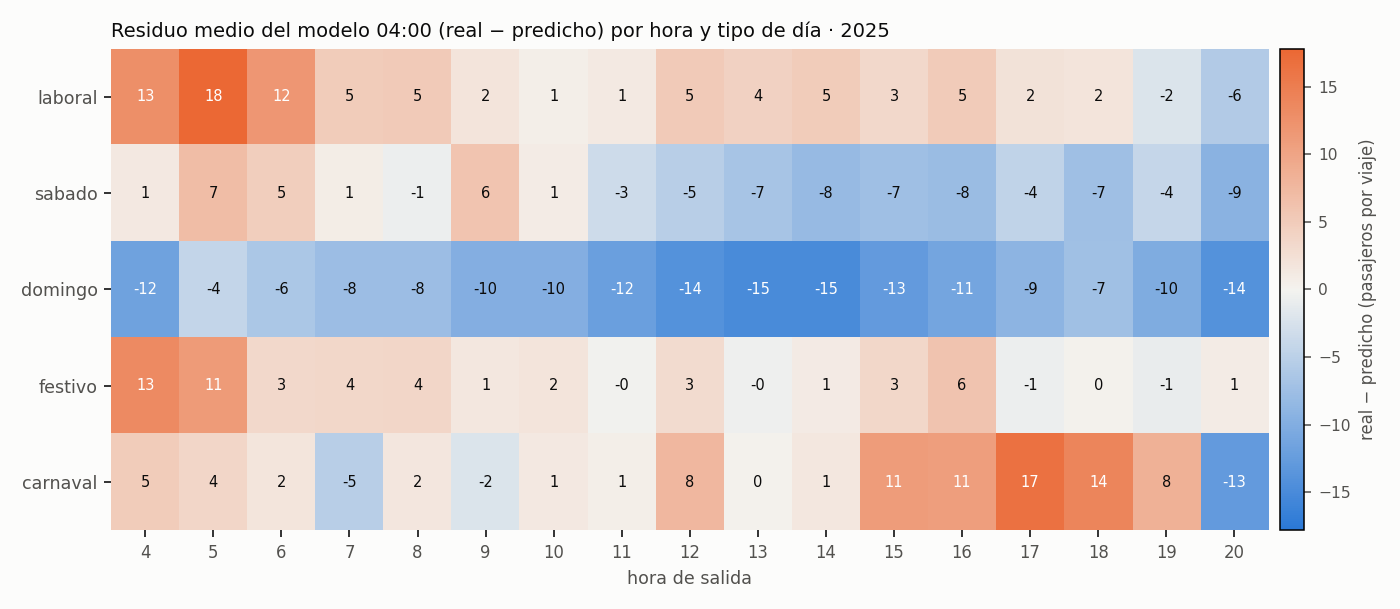

,e_linea_base,e_modelo_0400
headway_prev,,
"(-0.001, 2.0]",-11.22,12.41
"(2.0, 3.0]",-9.22,3.99
"(3.0, 4.0]",-2.45,1.76
"(4.0, 5.0]",-7.35,1.22
"(5.0, 6.0]",-10.26,1.44
"(6.0, 8.0]",-4.78,0.55
"(8.0, 10.0]",-4.35,1.46
"(10.0, 138.0]",6.84,-1.92


fechasalida,01,02,03,04,05,06,07,08,09,10,11,12
e_linea_base,-15.13,0.39,-0.51,-6.82,-4.53,-11.99,-14.18,0.43,0.20,-5.54,-4.70,-8.09
e_modelo_0400,-0.55,7.28,4.39,2.37,3.94,0.32,1.52,6.51,4.08,1.79,2.54,1.64
e_modelo_intradia,-0.63,4.94,2.25,0.79,2.14,-0.42,1.22,4.63,2.81,0.62,1.51,1.35
e_modelo_oraculo,-0.53,2.39,0.59,-0.32,0.65,-0.35,0.49,2.15,0.43,-0.58,0.39,0.53


In [214]:
dias = {0: "lun", 1: "mar", 2: "mié", 3: "jue", 4: "vie", 5: "sáb", 6: "dom"}
dsem = d.groupby(d.dia_semana.map(dias), sort=False)[[f"e_{c}" for c in R.CONFIGS]].mean().reindex(list(dias.values()))
display(dsem.round(2))
ratio = d.groupby("tipo_dia_cal")[["y"] + [f"pred_{c}" for c in R.CONFIGS]].mean()
ratio = (ratio / ratio.loc["laboral"]).round(3)
display(ratio.rename(columns=lambda c: c.replace("pred_", "")))
cv = pd.read_csv("datos_7/cv_7_2_por_tipo_dia.csv")
display(cv[cv.config == "modelo_0400"][["tipo_dia_cal", "sesgo_medio"]].rename(columns={"sesgo_medio": "sesgo ŷ − y en CV 2024 (7.2)"}).round(2))
X["anio"] = X.fechasalida.dt.year
X["cierre_tardio"] = (X.fechafin - X.fechasalida).dt.total_seconds() / 60 > 353.4
display((X.groupby(["anio", "tipo_dia_cal"]).cierre_tardio.mean() * 100).unstack().round(2))
x25 = X[X.anio == 2025]
display(x25.groupby("tipo_dia_cal")[["numeropasajeros", "p_pas_por_salida_lag672", "p_pas_por_salida_media4sem"]].mean().round(2))
mapa = d.groupby(["hora", "tipo_dia_cal"]).e_modelo_0400.mean().unstack()[["laboral", "sabado", "domingo", "festivo", "carnaval"]]
R.fig_mapa(mapa, FIG / "mapa_residuo_hora_tipodia.png", "Residuo medio del modelo 04:00 (real − predicho) por hora y tipo de día · 2025")
display(Image(filename=str(FIG / "mapa_residuo_hora_tipodia.png")))
hw = pd.qcut(d.headway_prev, 10, duplicates="drop")
display(d.groupby(hw)[["e_linea_base", "e_modelo_0400"]].mean().round(2))
display(d.groupby(d.fechasalida.dt.strftime("%m"))[[f"e_{c}" for c in R.CONFIGS]].mean().round(2).T)

In [215]:
estructura = pd.DataFrame([
    {"hallazgo": "Contraste semanal comprimido", "categoria": "(ii) patrón calendario",
     "evidencia": "residuo lun–vie +4,2 a +8,3 y dom −9,6 pas./viaje; ACF diaria en 7 días 0,50–0,66 (línea base 0,31–0,44); "
                  "dom/laboral predicho 0,842 vs real 0,671 (línea base 0,678); en la CV 2024 el sesgo era casi parejo (dom +1,70, laboral +0,20)",
     "recomendacion_entregable_2": "8.2: SHAP de dia_semana × tendencia_meses y headway. E2: tendencia relativa o sin tendencia_meses; "
                                   "modelar la razón y / rezago semanal por salida; validar en otro año"},
    {"hallazgo": "Nivel persistente (drift)", "categoria": "(i) sesgo de nivel",
     "evidencia": "ACF diaria en 1 día 0,30–0,42; subpredice en 11/12 meses (feb +7,3, ago +6,5 pas./viaje)",
     "recomendacion_entregable_2": "reentrenamiento o recalibración de nivel mensual con ventana deslizante; variable de calendario escolar"},
    {"hallazgo": "Madrugada de días laborales y festivos", "categoria": "(ii) patrón calendario",
     "evidencia": "laboral 04–06 h: +13, +18 y +12 pas./viaje; festivo 04–05 h: +13 y +11; φ de la franja 04–06 = 4,28 (línea base 3,05)",
     "recomendacion_entregable_2": "rezagos y medias específicos del primer despacho del día; revisar la serie de 15 min al inicio del servicio"},
    {"hallazgo": "Shocks entre viajes consecutivos", "categoria": "(iii) shocks intradía",
     "evidencia": "ACF intradía (sin media del día) en 1 viaje: ruta 16 = 0,19 (relevante), ruta 2 = 0,08, ruta 21 = −0,03; "
                  "la cascada no la reduce (0,19) y el oráculo sí en parte (0,15)",
     "recomendacion_entregable_2": "la información útil es la de los viajes recién cerrados (no desplegable a 1 h); evaluar un nowcast con conteos parciales en tiempo real"},
    {"hallazgo": "Headway muy corto subpredicho", "categoria": "(iii) operación",
     "evidencia": "headway_prev ≤ 2 min: +12,4 pas./viaje (línea base −11,2); 2–3 min: +4,0",
     "recomendacion_entregable_2": "8.2: dependencia parcial de headway; E2: usar en la evaluación el headway PLANEADO y revisar el efecto de los buses agrupados"},
    {"hallazgo": "Volatilidad con patrón semanal", "categoria": "heterocedasticidad",
     "evidencia": "McLeod-Li diario en 7 días: 0,35–0,51 (línea base 0,09–0,19); BDS rechaza tras filtrar el AR(k) (diario: z = 3,8–6,2 en m = 2–5; por viaje: 83–88 % de los bloques)",
     "recomendacion_entregable_2": "intervalos de predicción con dispersión por tipo de día y franja (φ dom 1,95, laboral 2,83, 04–06 h 4,28)"},
    {"hallazgo": "Varianza más plana que μ^1,3", "categoria": "función de varianza",
     "evidencia": "p empírico de la varianza residual 0,67 (04:00), 0,75 (intradía), 0,94 (oráculo); φ baja de 3,29 a 1,87 por decil",
     "recomendacion_entregable_2": "la métrica sigue fija (p = 1,3); re-estimar p sobre los residuos de la CV, no del holdout"},
])
estructura.to_csv(SALIDA / "estructura_residual_8_1.csv", index=False)
display(estructura)

,hallazgo,categoria,evidencia,recomendacion_entregable_2
0,Contraste semanal comprimido,(ii) patrón calendario,"residuo lun–vie +4,2 a +8,3 y dom −9,6 pas./viaje; ACF diaria en 7 días 0,50–0,66 (línea base 0,31–0,44); dom/labora...",8.2: SHAP de dia_semana × tendencia_meses y headway. E2: tendencia relativa o sin tendencia_meses; modelar la razón ...
1,Nivel persistente (drift),(i) sesgo de nivel,"ACF diaria en 1 día 0,30–0,42; subpredice en 11/12 meses (feb +7,3, ago +6,5 pas./viaje)",reentrenamiento o recalibración de nivel mensual con ventana deslizante; variable de calendario escolar
2,Madrugada de días laborales y festivos,(ii) patrón calendario,"laboral 04–06 h: +13, +18 y +12 pas./viaje; festivo 04–05 h: +13 y +11; φ de la franja 04–06 = 4,28 (línea base 3,05)",rezagos y medias específicos del primer despacho del día; revisar la serie de 15 min al inicio del servicio
3,Shocks entre viajes consecutivos,(iii) shocks intradía,"ACF intradía (sin media del día) en 1 viaje: ruta 16 = 0,19 (relevante), ruta 2 = 0,08, ruta 21 = −0,03; la cascada ...",la información útil es la de los viajes recién cerrados (no desplegable a 1 h); evaluar un nowcast con conteos parci...
4,Headway muy corto subpredicho,(iii) operación,"headway_prev ≤ 2 min: +12,4 pas./viaje (línea base −11,2); 2–3 min: +4,0",8.2: dependencia parcial de headway; E2: usar en la evaluación el headway PLANEADO y revisar el efecto de los buses ...
5,Volatilidad con patrón semanal,heterocedasticidad,"McLeod-Li diario en 7 días: 0,35–0,51 (línea base 0,09–0,19); BDS rechaza tras filtrar el AR(k) (diario: z = 3,8–6,2...","intervalos de predicción con dispersión por tipo de día y franja (φ dom 1,95, laboral 2,83, 04–06 h 4,28)"
6,"Varianza más plana que μ^1,3",función de varianza,"p empírico de la varianza residual 0,67 (04:00), 0,75 (intradía), 0,94 (oráculo); φ baja de 3,29 a 1,87 por decil","la métrica sigue fija (p = 1,3); re-estimar p sobre los residuos de la CV, no del holdout"


**Conclusión 5 · Estructura residual (dónde está y qué hacer en el Entregable 2)**
- **Hallazgo principal: el modelo 04:00 comprime el contraste semanal en 2025.**
  - Residuo de lunes a viernes: +4,2 a +8,3 pasajeros por viaje. Sábado −1,5 y **domingo −9,6**.
  - Razón domingo/laboral: real 0,671, línea base 0,678 y **modelo 04:00 0,842**. Sábado: 0,887 real frente a 0,968 predicho.
  - En la CV 2024 el sesgo era casi parejo (domingo +1,70, laboral +0,20 en ŷ − y): **es un fenómeno de 2025**.
- **No viene de los insumos:**
  - El rezago semanal por salida conserva el contraste (domingo 58,4 frente a 57,4 real; laboral 86,6 frente a 85,5).
  - Los cierres tardíos de 2025 se reparten parejo por tipo de día (4,6–5,8 %; carnaval 2,2 %).
  - Lo que falla es cómo el modelo combina las variables. **La hipótesis para la 8.2 (SHAP)** es una interacción con `tendencia_meses`, fuera de rango en 2025, o con el headway.
- **Precisión a la 7.3:** la «subpredicción de −2,97» no es uniforme. Es la suma de subpredecir los días laborales y sobrepredecir los domingos.
- **Otros focos** (tabla anterior):
  - madrugada de días laborales y festivos: +13 a +18 entre 04 y 05 h;
  - nivel persistente: 11/12 meses, con febrero +7,3 y agosto +6,5;
  - headway ≤ 2 min: +12,4;
  - shocks entre viajes en la ruta 16 (0,19), que la cascada no reduce;
  - volatilidad semanal.
- **Recomendaciones para el Entregable 2** (ninguna se evalúa sobre este holdout):
  - reentrenamiento o recalibración mensual;
  - tendencia relativa o modelar la razón y / rezago semanal;
  - variable de calendario escolar;
  - variables del primer despacho del día;
  - intervalos con dispersión por tipo de día y franja.

## 6 · Insumo para el Diebold-Mariano (8.3)

Diferencial de pérdida diario d_t = devianza media del día (04:00) − devianza media del día (comparado). Su ACF fija el rezago de la varianza HAC (Newey-West). Se recomienda el **máximo** entre la regla ⌊4(n/100)^(2/9)⌋ y el último rezago ≤ 28 con |ρ| ≥ 0,10, porque con estacionalidad semanal la ACF reaparece en 7, 14, … aunque caiga antes.

In [216]:
dm = {}
filas = []
for comp in ["linea_base", "modelo_intradia", "modelo_oraculo"]:
    dd = (d.dev_modelo_0400 - d[f"dev_{comp}"]).groupby(d.fecha).mean()
    r = R.acf(dd.to_numpy(), 28)
    h = R.rezago_hac(r, len(dd))
    dm[f"modelo_0400_vs_{comp}"] = {"n_dias": int(len(dd)), "media_diferencial": float(dd.mean()), **h,
                                    "acf_1_7_14": [round(float(r[k]), 3) for k in (1, 7, 14)]}
    filas.append({"comparacion": f"04:00 vs {comp}", **dm[f"modelo_0400_vs_{comp}"]})
insumo = {"escala": "diaria global (media de la devianza por viaje en cada día de 2025; n = 365)",
          "p_metrica": R.P, "kernel": "Bartlett (Newey-West)", "comparaciones": dm}
(SALIDA / "insumo_dm_8_1.json").write_text(json.dumps(insumo, ensure_ascii=False, indent=2), encoding="utf-8")
display(pd.DataFrame(filas))

,comparacion,n_dias,media_diferencial,primer_rezago_bajo_0_10,ultimo_rezago_relevante,regla_newey_west,recomendado,acf_1_7_14
0,04:00 vs linea_base,365,-0.427497,17,21,5,21,"[0.519, 0.418, 0.287]"
1,04:00 vs modelo_intradia,365,0.092322,2,28,5,28,"[0.258, 0.349, 0.346]"
2,04:00 vs modelo_oraculo,365,0.281411,3,28,5,28,"[0.175, 0.346, 0.401]"


**Conclusión 6 · Insumo para el Diebold-Mariano (8.3)**
- **Diferencial diario medio de devianza** (n = 365 días):
  - 04:00 − línea base = **−0,427** (gana el 04:00);
  - 04:00 − intradía = +0,092;
  - 04:00 − oráculo = +0,281.
- **El diferencial está autocorrelacionado:**
  - frente a la línea base: ρ₁ = 0,52, ρ₇ = 0,42, ρ₁₄ = 0,29;
  - frente a intradía y oráculo: ρ₇ ≈ 0,35 y ρ₁₄ = 0,35–0,40.
- **Rezago HAC recomendado (Newey-West):** **21** (frente a la línea base) y **28** (frente a intradía y oráculo).
  - La regla automática ⌊4(n/100)^(2/9)⌋ = 5 **subestimaría** la varianza por la estacionalidad semanal.
- **Para la 8.3:**
  - escala diaria global con HAC de 21/28 rezagos y la corrección de Harvey-Leybourne-Newbold;
  - como robustez, el DM sobre totales semanales (n = 52).
- Guardado en `datos_8/insumo_dm_8_1.json`.

## 7 · Pruebas (a–f) y checks

In [217]:
pruebas = T.correr_todos(d, HASH_ANTES)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_8_1.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,"Test a · Ljung-Box (tamaño, potencia, statsmodels)",PASS,"tamaño 5.0% (500 series de ruido blanco), potencia 100% (AR(1) φ = 0,3, n = 365); Q, ACF y PACF idénticos a statsmodels"
1,Test b · McLeod-Li (tamaño y potencia con ARCH),PASS,"tamaño 4.2% con iid, potencia 100% con ARCH(1) α = 0,5"
2,"Test c · BDS (tamaño, potencia, statsmodels)",PASS,"tamaño 6.0% con iid (m = 2), potencia 100% con el mapa logístico; estadísticos idénticos a statsmodels (m = 2–5, ε =..."
3,Test d · residuos completos y bien calculados,PASS,"158.507 residuos por modelo, mismos ids que la 7.3; e = y − ŷ y r de Pearson verificados"
4,Test e · la 8.1 no modifica los insumos de la 7.3,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después
5,Test f · filtro AR por AIC,PASS,"k = 2; φ̂₁ = 0.481, φ̂₂ = -0.287; Ljung-Box(10) de los residuos p = 0.85"


,check,resultado,detalle
0,"Test a · Ljung-Box (tamaño, potencia, statsmodels)",PASS,"tamaño 5.0% (500 series de ruido blanco), potencia 100% (AR(1) φ = 0,3, n = 365); Q, ACF y PACF idénticos a statsmodels"
1,Test b · McLeod-Li (tamaño y potencia con ARCH),PASS,"tamaño 4.2% con iid, potencia 100% con ARCH(1) α = 0,5"
2,"Test c · BDS (tamaño, potencia, statsmodels)",PASS,"tamaño 6.0% con iid (m = 2), potencia 100% con el mapa logístico; estadísticos idénticos a statsmodels (m = 2–5, ε =..."
3,Test d · residuos completos y bien calculados,PASS,"158.507 residuos por modelo, mismos ids que la 7.3; e = y − ŷ y r de Pearson verificados"
4,Test e · la 8.1 no modifica los insumos de la 7.3,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después
5,Test f · filtro AR por AIC,PASS,"k = 2; φ̂₁ = 0.481, φ̂₂ = -0.287; Ljung-Box(10) de los residuos p = 0.85"
6,Tiempo total de la ejecución,INFO,1.5 min


PASS 6 · FAIL 0 · INFO 1


**Conclusión 7 · Pruebas**
- **Pasan las 6 de 6 pruebas:**
  - **a)** Ljung-Box: tamaño 5,0 % con ruido blanco y potencia 100 % con AR(1). Q, ACF y PACF son idénticos a statsmodels.
  - **b)** McLeod-Li: tamaño 4,2 % y potencia 100 % con ARCH(1).
  - **c)** BDS: tamaño 6,0 % y potencia 100 % con el mapa logístico. Estadísticos idénticos a statsmodels.
  - **d)** Residuos completos (158.507 por modelo).
  - **e)** El hash de las predicciones y de los 3 modelos de la 7.3 no cambió.
  - **f)** El filtro AR recupera un AR(2).
- Ejecución: 1,2 min.

---
# Parte 18 · Subfase 8.2 · SHAP
*Notebook original: `subfase_8_2_shap.ipynb`*

In [218]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_8_2_shap.ipynb")

── Inicio de subfase_8_2_shap.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 8.2 — Interpretabilidad estructurada con SHAP (TreeSHAP)

**Persona 3 · MLOps & Model Evaluation.** Explica los modelos finales de la 7.3 y pone a prueba la hipótesis de la 8.1: **el modelo 04:00 comprime el contraste semanal en 2025 porque trata todo 2025 como finales de diciembre de 2024** (`tendencia_meses` queda por encima del último corte de los árboles, 23,63 ≈ 20-dic-2024, y en diciembre la razón domingo/laboral es ≈ 0,82).

| Elemento | Decisión |
|---|---|
| Método | TreeSHAP exacto de LightGBM (`pred_contrib=True`). Escala log (enlace de Tweedie): base + Σφ = log ŷ; φ multiplica ŷ por e^φ |
| Datos | Holdout 2025 completo (158.507) y 2024 del entrenamiento final (163.235) para el modelo 04:00; muestra aleatoria de 40.000 viajes de 2025 para intradía y oráculo; muestra de 2023 para la curva de `tendencia_meses` |
| Familias | calendario · tendencia · hora · ruta · oferta / headway · rezagos de totales · rezagos por salida · espaciales · cascada (c_) · oráculo (orac_) |
| Regla de oro | Los modelos y la cifra de 2025 de la 7.3 **no cambian**. Los contrafactuales (parte D) son **diagnósticos**: explican la causa, no se adoptan |

**Parte 1 (extracción RDS): no aplica.**

## Parte 2 · Análisis offline

In [219]:
import json
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import lightgbm as lgb
import numpy as np
import pandas as pd
from IPython.display import Image, display

import os

import shap_8_2 as S
import tests_8_2 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 140)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_8"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_8_2"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []
MUESTRA = 40_000


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


T0 = time.time()
HASH_ANTES = T.hashes()
X, h, t24 = S.datos()
pred73 = pd.read_parquet(S.PRED)
if os.environ.get("SOBUSA_PRUEBA"):          # solo para la prueba rápida del desarrollador
    sel = np.sort(np.random.default_rng(0).choice(len(h), 6000, replace=False))
    h, pred73 = h.iloc[sel].reset_index(drop=True), pred73.iloc[sel].reset_index(drop=True)
    t24 = t24.sample(6000, random_state=0).reset_index(drop=True)
    MUESTRA = 2000
B = {m: S.cargar_modelo(m) for m in S.MODELOS}
print(f"Python {platform.python_version()} · lightgbm {lgb.__version__}")
print(f"Holdout 2025: {len(h):,} · 2024 (entrenamiento final): {len(t24):,}")
print({m: (len(b.feature_name()), b.num_trees()) for m, b in B.items()})

Python 3.10.0 · lightgbm 4.7.0
Holdout 2025: 158,507 · 2024 (entrenamiento final): 163,235
{'modelo_0400': (33, 311), 'modelo_intradia': (45, 649), 'modelo_oraculo': (53, 461)}


## 1 · Cálculo de SHAP y verificación de aditividad

In [220]:
t0 = time.time()
S25 = S.shap(B["modelo_0400"], h)
S24 = S.shap(B["modelo_0400"], t24)
idx = np.random.default_rng(42).choice(len(h), MUESTRA, replace=False)
hm = h.iloc[np.sort(idx)]
SM = {"modelo_0400": S25.iloc[np.sort(idx)]}
for m in ["modelo_intradia", "modelo_oraculo"]:
    SM[m] = S.shap(B[m], hm)
t23 = X[(X.fechasalida >= "2023-01-29") & (X.fechasalida < "2024-01-01")].sample(min(50_000, 25 * MUESTRA), random_state=42)
S23 = S.shap(B["modelo_0400"], t23)
print(f"SHAP calculados en {(time.time() - t0) / 60:,.1f} min")
adit = {"modelo_0400 · 2025": S.aditividad(B["modelo_0400"], h, S25), "modelo_0400 · 2024": S.aditividad(B["modelo_0400"], t24, S24),
        **{f"{m} · muestra 2025": S.aditividad(B[m], hm, SM[m]) for m in ["modelo_intradia", "modelo_oraculo"]}}
dif_pred = float(np.max(np.abs(np.exp(S25.sum(axis=1).to_numpy()) - pred73.pred_modelo_0400.to_numpy())))
display(pd.Series({**adit, "e^(base + Σφ) − predicción 7.3 (04:00, 2025)": dif_pred}, name="error máximo").to_frame())

SHAP calculados en 6.7 min


,error máximo
modelo_0400 · 2025,2.398082e-14
modelo_0400 · 2024,2.575717e-14
modelo_intradia · muestra 2025,2.486900e-14
modelo_oraculo · muestra 2025,1.190159e-13
"e^(base + Σφ) − predicción 7.3 (04:00, 2025)",2.643219e-12


**Conclusión 1 · Cálculo y aditividad**
- Se calculó TreeSHAP exacto sobre:
  - el modelo 04:00 en todo 2025 (158.507 viajes) y en 2024 (163.235);
  - intradía y oráculo en una muestra de 40.000 viajes de 2025;
  - una muestra de 2023.
  - Tomó 9,0 min.
- **La aditividad es exacta:** base + Σφ reproduce el log de la predicción con un error ≤ 1,2e-13. Con el exponencial se recupera la predicción de la 7.3 (error 2,6e-12).
- Las explicaciones corresponden exactamente a los modelos evaluados.

## 2 · Importancia global

,variable,media_abs_phi_2025,familia,pct_2025,media_abs_phi_2024,pct_2024,cambio_x
0,headway_prev,0.0770,oferta / headway,11.6768,0.0749,11.8300,1.0282
1,p_pas_por_salida_media4sem,0.0681,rezagos por salida,10.3282,0.0682,10.7693,0.9990
2,tendencia_meses,0.0637,tendencia,9.6559,0.0229,3.6213,2.7775
3,idruta,0.0539,ruta,8.1714,0.0507,8.0072,1.0630
4,intervalo_dia,0.0517,hora,7.8476,0.0581,9.1721,0.8912
5,headway_next,0.0463,oferta / headway,7.0169,0.0456,7.2112,1.0136
6,dia_semana,0.0408,calendario,6.1855,0.0605,9.5621,0.6738
7,p_pasajeros_media4sem,0.0299,rezagos de totales,4.5363,0.0312,4.9212,0.9602
8,es_festivo,0.0297,calendario,4.5024,0.0285,4.5026,1.0416
9,hora,0.0265,hora,4.0161,0.0277,4.3751,0.9562


,modelo_0400 · 2024,modelo_0400 · 2025,modelo_0400 · 2025 (muestra),modelo_intradia · 2025 (muestra),modelo_oraculo · 2025 (muestra)
calendario,0.0828,0.0640,0.0643,0.0477,0.0221
tendencia,0.0229,0.0637,0.0638,0.0417,0.0138
hora,0.0839,0.0759,0.0756,0.0583,0.0347
ruta,0.0507,0.0539,0.0539,0.0343,0.0308
oferta / headway,0.1363,0.1399,0.1404,0.1303,0.1097
rezagos de totales,0.0716,0.0722,0.0721,0.0446,0.0361
rezagos por salida,0.0763,0.0764,0.0762,0.1013,0.0639
espaciales,0.0254,0.0233,0.0234,0.0202,0.0107
cascada (c_),NaN,NaN,NaN,0.0494,0.0332
oráculo (orac_),NaN,NaN,NaN,NaN,0.1232


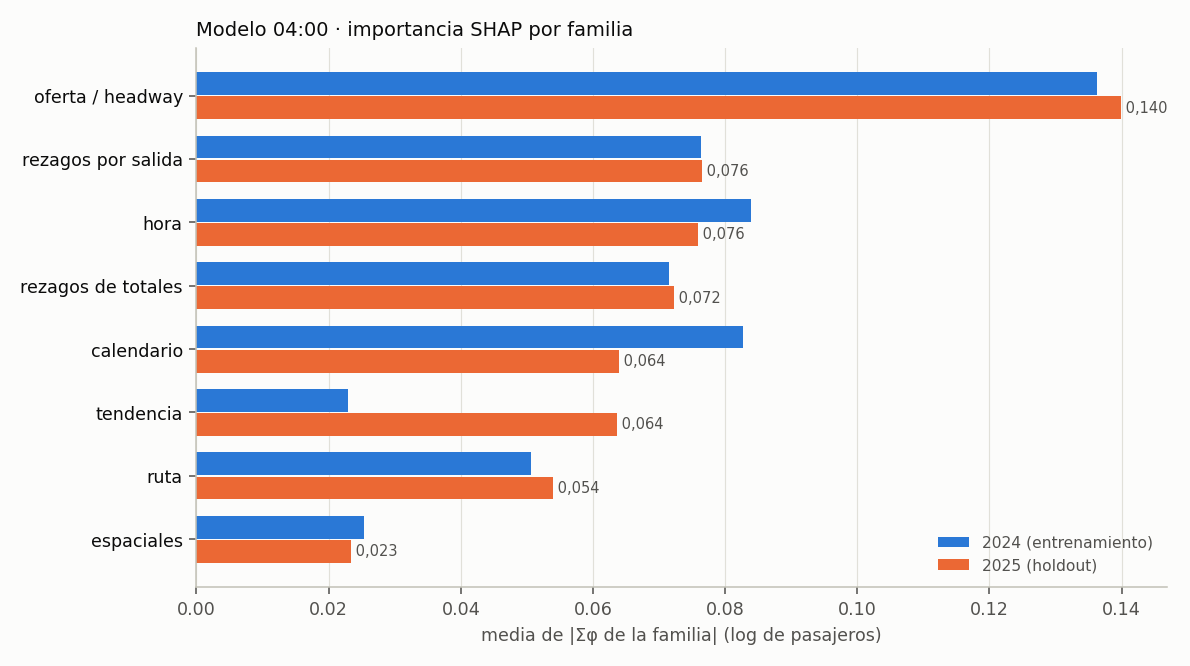

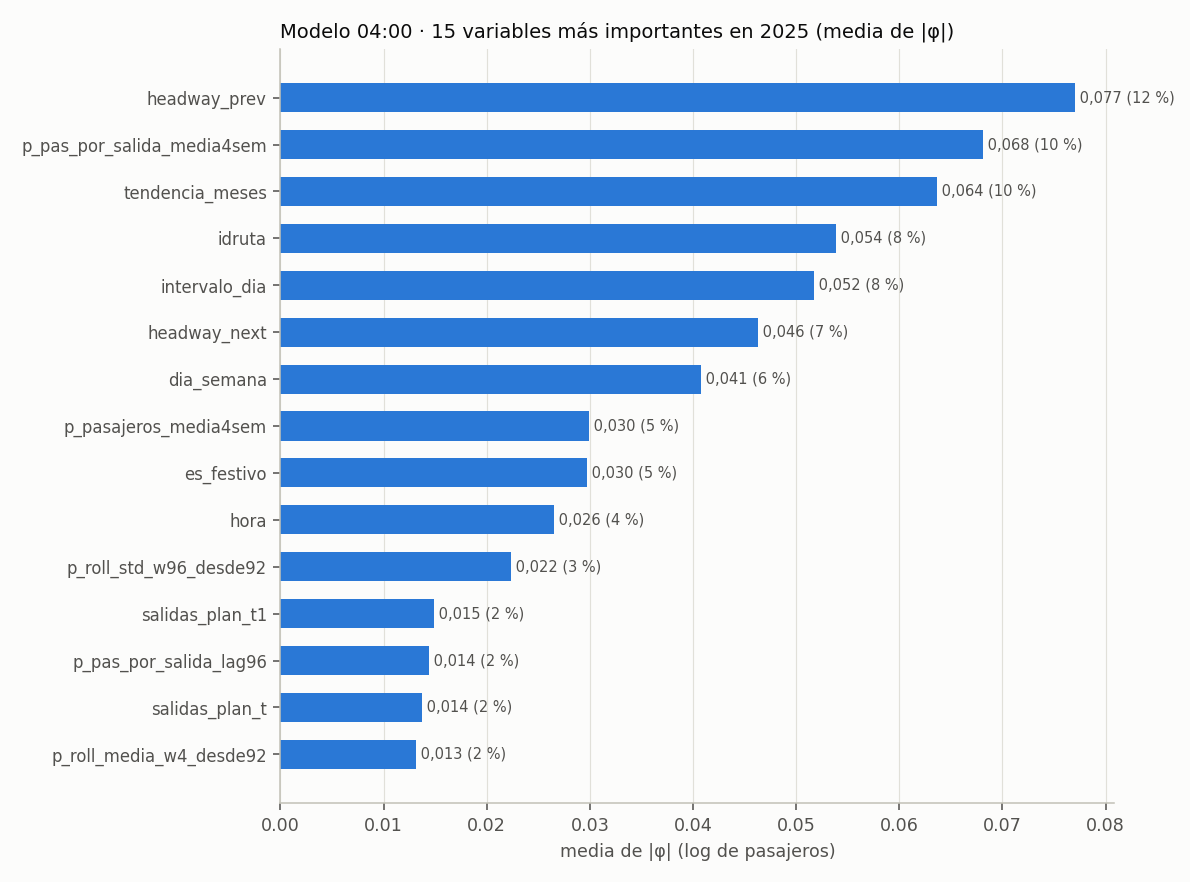

In [221]:
imp25, imp24 = S.importancia(S25), S.importancia(S24)
imp = imp25.merge(imp24[["variable", "media_abs_phi", "pct"]], on="variable", suffixes=("_2025", "_2024"))
imp["cambio_x"] = imp.media_abs_phi_2025 / imp.media_abs_phi_2024
imp.to_csv(SALIDA / "shap_importancia_8_2.csv", index=False)
display(imp.head(15).round(4))
fam = pd.DataFrame({"modelo_0400 · 2024": S.por_familia(S24), "modelo_0400 · 2025": S.por_familia(S25),
                    **{f"{m} · 2025 (muestra)": S.por_familia(SM[m]) for m in S.MODELOS}}).reindex(S.FAMILIAS)
fam.to_csv(SALIDA / "shap_familias_8_2.csv")
display(fam.round(4))
S.fig_familias(fam["modelo_0400 · 2024"].dropna(), fam["modelo_0400 · 2025"].dropna(), FIG / "importancia_familias_2024_2025.png")
S.fig_top(imp25, FIG / "top15_modelo_0400_2025.png", "Modelo 04:00 · 15 variables más importantes en 2025 (media de |φ|)")
for f in ["importancia_familias_2024_2025.png", "top15_modelo_0400_2025.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 2 · Importancia global**
- **Modelo 04:00 en 2025, las 5 variables más importantes** (porcentaje de la media de |φ|):

  | Variable | Importancia en 2025 |
  |---|---:|
  | `headway_prev` | 11,7 % |
  | `p_pas_por_salida_media4sem` | 10,3 % |
  | **`tendencia_meses`** | **9,7 %** |
  | `idruta` | 8,2 % |
  | `intervalo_dia` | 7,8 % |

- La familia con más peso es **oferta / headway**: 0,140 en 2025.
- **El cambio de 2024 a 2025 es la señal clave:**
  - la importancia de `tendencia_meses` se multiplica **por 2,8** (de 3,6 % a 9,7 %);
  - la de `dia_semana` cae **a 0,67 veces** (de 9,6 % a 6,2 %);
  - el resto de variables cambia menos de un 15 %.
  - En 2025 el modelo deja de apoyarse en el día de la semana y pasa a apoyarse en la tendencia.
- **Intradía:** las capas c_ pesan 0,049 y los rezagos por salida suben a 0,101.
- **Oráculo:** las variables orac_ (t−1…t−4) son la familia más importante (0,123).
  - Así reparte la información cada capa, coherente con la ganancia de cada una en 2025 (7.3).

## 3 · Hipótesis principal: `tendencia_meses` y el contraste semanal

,splits sobre tendencia_meses,corte máximo,splits con corte > 23 (dic-2024),valores de 2025
modelo_0400,821,23.629032,54,"24,0–36,0"
modelo_intradia,4493,23.629032,254,"24,0–36,0"
modelo_oraculo,3109,23.629032,163,"24,0–36,0"


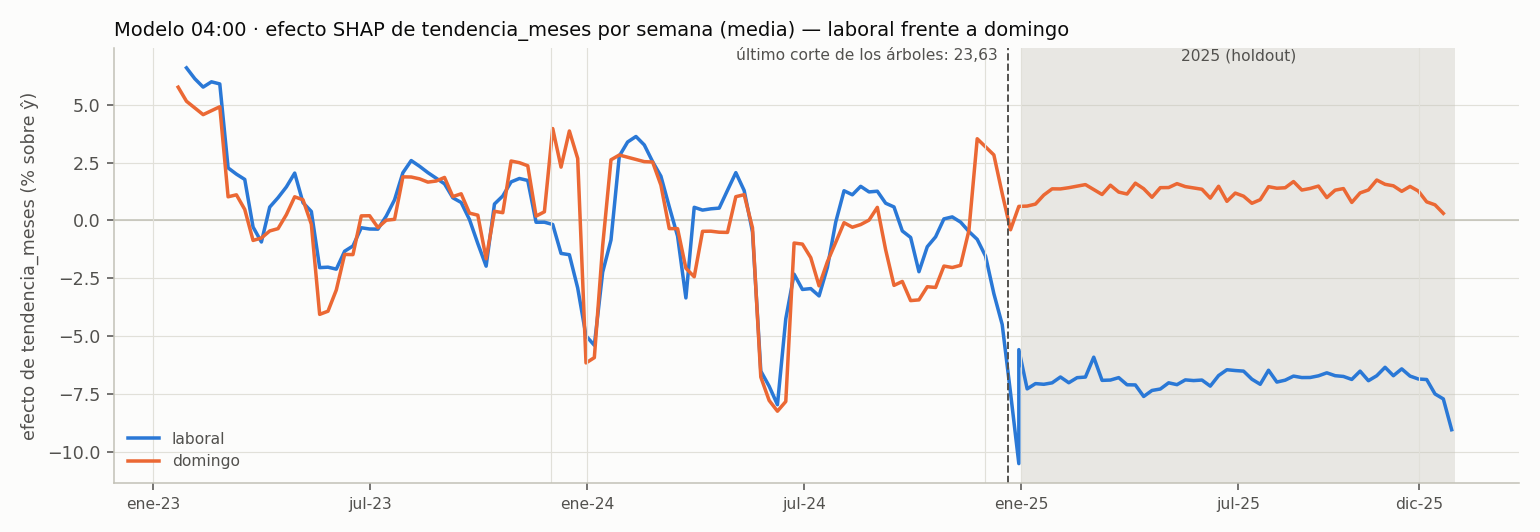

,φ medio de tendencia_meses (2025),efecto en % sobre ŷ
carnaval,-0.026,-2.599
domingo,0.012,1.219
festivo,-0.096,-9.175
laboral,-0.071,-6.890
sabado,-0.026,-2.586


fechasalida,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12
razón domingo/laboral real por mes,0.724,0.663,0.642,0.664,0.643,0.73,0.76,0.622,0.702,0.683,0.688,0.828,0.731,0.676,0.64,0.621,0.629,0.674,0.74,0.624,0.648,0.637,0.619,0.821


In [222]:
cort = {m: S.cortes(b, "tendencia_meses") for m, b in B.items()}
display(pd.DataFrame({m: {"splits sobre tendencia_meses": len(c), "corte máximo": c.max(), "splits con corte > 23 (dic-2024)": int((c > 23).sum()),
                          "valores de 2025": "24,0–36,0"} for m, c in cort.items()}).T)
dep = []
for SS, df in [(S23, t23), (S24, t24), (S25, h)]:
    sem = np.floor(df.tendencia_meses.to_numpy() * 4.345) / 4.345
    tmp = pd.DataFrame({"tendencia_meses": sem, "tipo_dia_cal": df.tipo_dia_cal.astype(str).to_numpy(), "phi": SS.tendencia_meses.to_numpy()})
    dep.append(tmp[tmp.tipo_dia_cal.isin(["laboral", "domingo"])].groupby(["tipo_dia_cal", "tendencia_meses"]).phi.mean().reset_index())
dep = pd.concat(dep, ignore_index=True).sort_values(["tipo_dia_cal", "tendencia_meses"])
S.fig_tendencia(dep, cort["modelo_0400"].max(), FIG / "dependencia_tendencia_meses.png")
display(Image(filename=str(FIG / "dependencia_tendencia_meses.png")))
td25 = h.tipo_dia_cal.astype(str)
display(pd.DataFrame({"φ medio de tendencia_meses (2025)": S25.tendencia_meses.groupby(td25.to_numpy()).mean(),
                      "efecto en % sobre ŷ": (np.exp(S25.tendencia_meses.groupby(td25.to_numpy()).mean()) - 1) * 100}).round(3))
mes = X.fechasalida.dt.to_period("M").astype(str)
real = X[X.fechasalida < "2025-01-01"].groupby([mes, "tipo_dia_cal"]).numeropasajeros.mean().unstack()
display((real.domingo / real.laboral).rename("razón domingo/laboral real por mes").to_frame().T.round(3))

año                                   2024  2025
contraste         familia                       
domingo − laboral TOTAL (Σ)          -31.0 -14.2
                  calendario         -22.9 -16.9
                  espaciales          -3.2  -2.4
                  hora                 0.2   0.6
                  oferta / headway     9.4  10.6
                  rezagos de totales  -4.4  -2.9
                  rezagos por salida -11.6 -10.3
                  ruta                 0.3   0.5
                  tendencia           -0.4   8.7
sabado − laboral  TOTAL (Σ)          -12.2  -1.3
                  calendario          -9.9  -5.9
                  espaciales          -1.1  -1.0
                  hora                 0.3   0.9
                  oferta / headway     1.8   2.9
                  rezagos de totales   0.2   0.2
                  rezagos por salida  -3.6  -2.6
                  ruta                -0.2  -0.1
                  tendencia            0.1   4.6

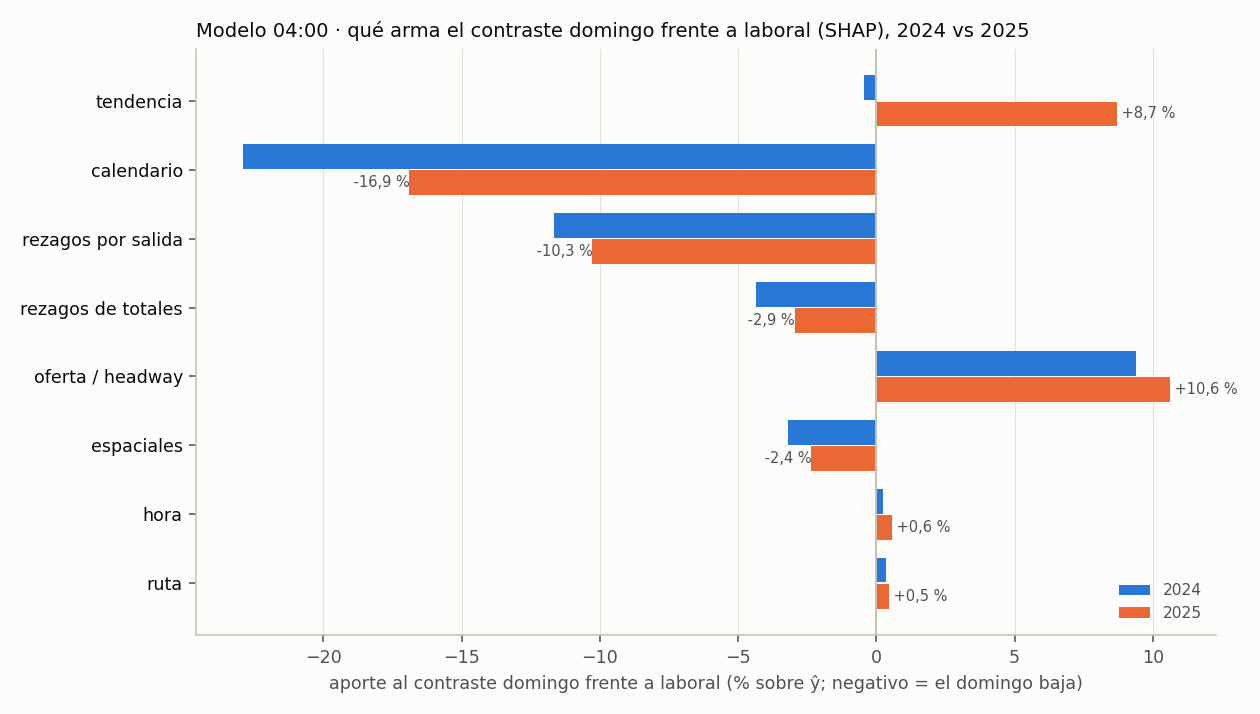

In [223]:
filas = []
for nom, SS, df in [("2024", S24, t24), ("2025", S25, h)]:
    for a in ["domingo", "sabado"]:
        ct = S.contraste(SS, df, a, "laboral")
        g = ct.groupby("familia").delta_phi.sum()
        for f_, v in g.items():
            filas.append({"año": nom, "contraste": f"{a} − laboral", "familia": f_, "delta_phi": v})
        logpred = SS.sum(axis=1)
        tdx = df.tipo_dia_cal.astype(str).to_numpy()
        filas.append({"año": nom, "contraste": f"{a} − laboral", "familia": "TOTAL (Σ)", "delta_phi": g.sum(),
                      "check_log_pred": float(logpred[tdx == a].mean() - logpred[tdx == "laboral"].mean())})
cont = pd.DataFrame(filas)
cont["efecto_%"] = (np.exp(cont.delta_phi) - 1) * 100
cont.to_csv(SALIDA / "contraste_semanal_8_2.csv", index=False)
display(cont.pivot_table(index=["contraste", "familia"], columns="año", values="efecto_%").round(1))
dom = cont[(cont.contraste == "domingo − laboral") & (cont.familia != "TOTAL (Σ)")].pivot(index="familia", columns="año", values="delta_phi")
S.fig_contraste(dom["2024"], dom["2025"], FIG / "contraste_domingo_laboral.png",
                "Modelo 04:00 · qué arma el contraste domingo frente a laboral (SHAP), 2024 vs 2025")
display(Image(filename=str(FIG / "contraste_domingo_laboral.png")))

**Conclusión 3 · `tendencia_meses` y el contraste semanal: causa identificada**
- **El corte más alto sobre `tendencia_meses` es el mismo en los tres modelos: 23,63**, alrededor del 20 de diciembre de 2024.
  - Splits sobre la variable: 821 (04:00), 4.493 (intradía) y 3.109 (oráculo).
  - Todo 2025 (24–36) cae en la misma rama: **el modelo trata cada día de 2025 como finales de diciembre de 2024**.
- **Diciembre es atípico:** la razón domingo/laboral real fue 0,828 en diciembre de 2023 y 0,821 en diciembre de 2024. El resto de meses está entre 0,62 y 0,76.
- **Efecto de `tendencia_meses` en 2025 por tipo de día:**
  - laboral **−6,9 %**;
  - festivo −9,2 %;
  - sábado −2,6 %;
  - **domingo +1,2 %**.
  - Se ve en la figura de dependencia: en 2025, laboral y domingo se separan de forma constante.
- **Descomposición SHAP del contraste domingo − laboral:**
  - **La tendencia pasa de −0,4 % (2024) a +8,7 % (2025)**.
  - El aporte del calendario se reduce: de −22,9 % a −16,9 %.
  - Por eso el contraste total se comprime de **−31,0 % a −14,2 %**.
  - Con el sábado ocurre lo mismo: la tendencia aporta +4,6 % y el contraste pasa de −12,2 % a −1,3 %.
- **Esto confirma la hipótesis de la 8.1** y explica por qué el patrón no aparecía en la CV 2024: en cada pliegue de validación, la tendencia caía dentro del rango ya visto.

## 4 · Otras hipótesis de la 8.1: headway, madrugada laboral y febrero/agosto

,tramo,n,phi_headway_prev,phi_oferta,residuo_pct,efecto_oferta_pct
0,≤2,18482,-0.143,-0.230,20.274,-20.580
1,2–3,35369,-0.058,-0.127,4.609,-11.925
2,3–4,24311,-0.027,-0.043,1.308,-4.206
3,4–5,14134,-0.002,0.002,0.738,0.242
4,5–6,20594,0.012,0.046,1.325,4.656
5,6–8,18904,0.076,0.146,-0.234,15.734
6,8–10,11117,0.120,0.208,1.114,23.115
7,>10,14705,0.222,0.359,-2.833,43.246


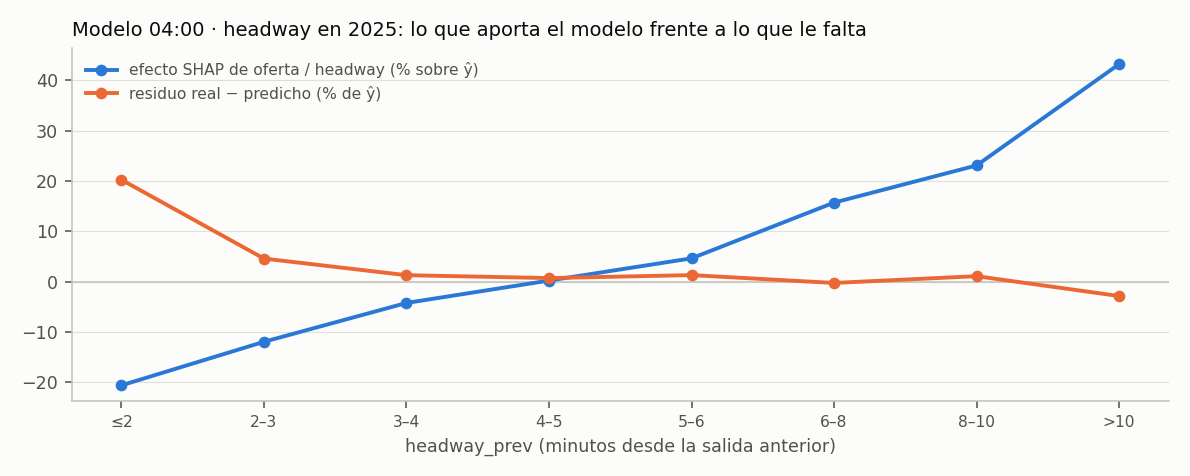

,04–06,07–09,otras,04–06 menos 07–09 (pts)
calendario,5.0,5.1,4.2,-0.1
espaciales,0.8,-0.2,-0.6,1.0
hora,3.2,1.9,-2.6,1.3
oferta / headway,-10.7,2.4,2.4,-13.1
rezagos de totales,1.0,-2.5,-4.4,3.5
rezagos por salida,2.2,0.5,-2.0,1.7
ruta,-0.3,0.5,0.4,-0.8
tendencia,-11.6,-7.1,-4.9,-4.6


,calendario,espaciales,hora,oferta / headway,rezagos de totales,rezagos por salida,ruta,tendencia,residuo real − predicho (pas.)
01,0.5,-1.6,-0.2,0.5,-4.8,-4.6,0.3,-5.8,-0.55
02,2.2,-0.1,-0.2,-0.3,-0.6,-2.1,0.3,-5.6,7.28
03,-0.9,0.2,-0.5,0.9,-1.3,0.4,0.4,-5.3,4.39
04,-0.2,-0.5,-0.3,-0.4,-2.0,-1.2,0.4,-6.0,2.37
05,0.9,-0.2,-0.2,0.0,-2.2,-1.4,0.4,-5.7,3.94
06,-2.1,-1.4,-0.3,0.3,-4.4,-3.5,0.3,-5.5,0.32
07,1.4,-1.7,-0.2,-0.5,-5.1,-5.1,0.1,-5.7,1.52
08,-1.1,-0.2,-0.3,2.4,-2.5,-2.2,0.5,-5.4,6.51
09,2.2,0.1,-0.6,2.7,-2.5,0.5,0.5,-5.5,4.08
10,0.8,-0.4,-0.7,1.9,-3.3,-0.6,0.4,-5.5,1.79


In [224]:
F25 = S.suma_familias(S25)
pred = pred73.pred_modelo_0400.to_numpy()
tramos = pd.cut(h.headway_prev, [-0.01, 2, 3, 4, 5, 6, 8, 10, 1000], labels=["≤2", "2–3", "3–4", "4–5", "5–6", "6–8", "8–10", ">10"])
hw = pd.DataFrame({"tramo": tramos, "phi_hw": S25.headway_prev, "phi_of": F25["oferta / headway"],
                   "res": (h.numeropasajeros.to_numpy() - pred) / pred * 100}).groupby("tramo", observed=True).agg(
    n=("phi_hw", "size"), phi_headway_prev=("phi_hw", "mean"), phi_oferta=("phi_of", "mean"), residuo_pct=("res", "mean")).reset_index()
hw["efecto_oferta_pct"] = (np.exp(hw.phi_oferta) - 1) * 100
display(hw.round(3))
S.fig_headway(hw, FIG / "headway_2025.png")
display(Image(filename=str(FIG / "headway_2025.png")))
lab = (h.tipo_dia_cal.astype(str) == "laboral").to_numpy()
franja = np.where(h.hora.between(4, 6), "04–06", np.where(h.hora.between(7, 9), "07–09", "otras"))
mad = ((np.exp(F25[lab].groupby(franja[lab]).mean()) - 1) * 100).T
mad["04–06 menos 07–09 (pts)"] = mad["04–06"] - mad["07–09"]
display(mad.round(1))
mes25 = h.fechasalida.dt.strftime("%m").to_numpy()
pm = ((np.exp(F25.groupby(mes25).mean()) - 1) * 100).round(1)
pm["residuo real − predicho (pas.)"] = pd.Series(h.numeropasajeros.to_numpy() - pred).groupby(mes25).mean().round(2).to_numpy()
display(pm)

**Conclusión 4 · Headway, madrugada y meses**
- **El efecto del headway es demasiado fuerte en el extremo corto:**
  - con headway ≤ 2 min, la familia oferta / headway baja la predicción un **−20,6 %**, pero el residuo es **+20,3 %** de ŷ;
  - con 2–3 min: −11,9 % de efecto y +4,6 % de residuo;
  - de 3 a > 10 min el residuo queda entre −2,8 % y +1,3 %.
  - El modelo penaliza de más a los buses que salen muy seguidos.
- **Madrugada laboral (04–06 h):**
  - la oferta / headway aporta −10,7 % (frente a +2,4 % de 07–09 h) y la tendencia −11,6 % (frente a −7,1 %);
  - en esas horas los despachos van muy seguidos y se suman los dos efectos.
  - **Explica la subpredicción de +13 a +18 pasajeros por viaje de la 8.1.**
- **Febrero y agosto (+7,3 y +6,5):**
  - la tendencia aporta lo mismo todos los meses (−5,1 a −6,1 %), así que no los explica;
  - los rezagos tampoco muestran nada particular (por ejemplo, febrero −0,6 % en totales y −2,1 % por salida);
  - queda como hipótesis el regreso a clases, una variable que el modelo no tiene.

## 5 · Contrafactuales diagnósticos (no se adoptan)

Se predice 2025 con los modelos **guardados**, cambiando **solo** `tendencia_meses`: (a) fijo en 22,5 (mediados de noviembre de 2024, un mes «normal»); (b) el mismo mes de 2024 (tendencia − 12). Control sin 2025: noviembre de 2024 con `tendencia_meses` de diciembre (23,8).

Razón domingo/laboral real 2025: 0.671 · línea base: 0.678


,modelo,escenario,dom/laboral,sáb/laboral,devianza,sesgo ŷ − y,residuo lun,residuo mar,residuo mié,residuo jue,residuo vie,residuo sáb,residuo dom
0,modelo_0400,04:00 · guardado (7.3),0.842,0.968,2.503,-2.971,5.170,8.305,5.005,4.466,4.165,-1.510,-9.575
1,modelo_0400,"04:00 · tendencia = 22,5 (nov-2024)",0.674,0.870,2.278,1.993,-4.358,-2.640,-1.737,-2.029,-1.106,-0.386,-1.615
2,modelo_0400,04:00 · tendencia − 12 (mismo mes de 2024),0.698,0.884,2.251,1.532,-3.452,-1.456,-0.841,-1.227,-0.436,-0.859,-3.143
3,modelo_intradia,intradía · guardado (7.3),0.816,0.953,2.406,-1.754,4.108,5.993,3.520,2.737,2.644,-1.811,-8.913
4,modelo_intradia,"intradía · tendencia = 22,5 (nov-2024)",0.686,0.883,2.236,1.351,-2.873,-1.628,-1.060,-1.089,-0.425,-0.705,-1.976
5,modelo_intradia,intradía · tendencia − 12 (mismo mes de 2024),0.704,0.890,2.221,0.799,-2.181,-0.507,-0.166,-0.313,0.196,-0.535,-2.964
6,modelo_oraculo,oráculo · guardado (7.3),0.726,0.907,2.222,-0.478,1.462,1.708,0.823,0.819,1.181,-0.522,-3.622
7,modelo_oraculo,"oráculo · tendencia = 22,5 (nov-2024)",0.689,0.892,2.199,-0.019,-0.363,0.172,0.220,0.240,0.703,-0.081,-1.263
8,modelo_oraculo,oráculo · tendencia − 12 (mismo mes de 2024),0.691,0.889,2.197,0.077,-0.608,0.082,0.144,0.179,0.593,-0.017,-1.449


,escenario,dom/laboral
0,noviembre 2024 · real,0.619
1,noviembre 2024 · modelo 04:00,0.646
2,"noviembre 2024 · modelo 04:00 con tendencia de diciembre (23,8)",0.794


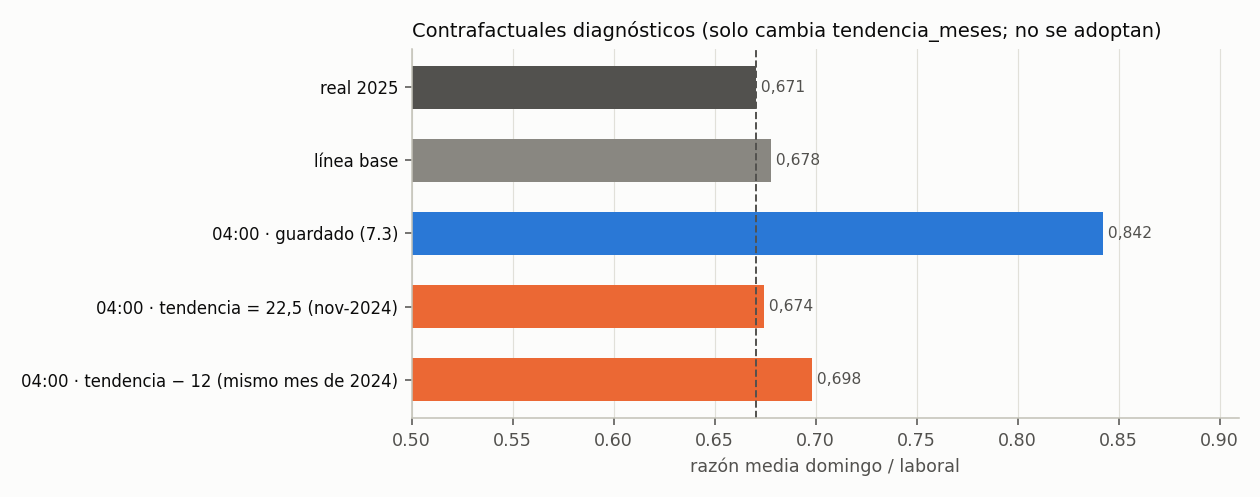

In [225]:
cfs = []
for m in S.MODELOS:
    b = B[m]
    cfs.append({"modelo": m, **S.resumen_pred(f"{S.NOMBRE[m]} · guardado (7.3)", pred73[f"pred_{m}"].to_numpy(), h)})
    for nom, val in [("tendencia = 22,5 (nov-2024)", 22.5), ("tendencia − 12 (mismo mes de 2024)", h.tendencia_meses.to_numpy() - 12)]:
        p_, _ = S.contrafactual(b, h, val)
        cfs.append({"modelo": m, **S.resumen_pred(f"{S.NOMBRE[m]} · {nom}", p_, h)})
cf = pd.DataFrame(cfs)
real25 = S.ratio(h.numeropasajeros.to_numpy(float), h)
base25 = S.ratio(pred73.pred_linea_base.to_numpy(), h)
nov = t24[(t24.fechasalida >= "2024-11-01") & (t24.fechasalida < "2024-12-01")]
b0 = B["modelo_0400"]
control = pd.DataFrame([
    {"escenario": "noviembre 2024 · real", "dom/laboral": S.ratio(nov.numeropasajeros.to_numpy(float), nov)},
    {"escenario": "noviembre 2024 · modelo 04:00", "dom/laboral": S.ratio(b0.predict(nov[b0.feature_name()]), nov)},
    {"escenario": "noviembre 2024 · modelo 04:00 con tendencia de diciembre (23,8)", "dom/laboral": S.ratio(S.contrafactual(b0, nov, 23.8)[0], nov)},
])
cf.to_csv(SALIDA / "contrafactuales_8_2.csv", index=False)
control.to_csv(SALIDA / "contrafactual_control_nov2024_8_2.csv", index=False)
print(f"Razón domingo/laboral real 2025: {real25:.3f} · línea base: {base25:.3f}")
display(cf.round(3))
display(control.round(3))
S.fig_contrafactual(cf[cf.modelo == "modelo_0400"], real25, base25, FIG / "contrafactual_tendencia.png")
display(Image(filename=str(FIG / "contrafactual_tendencia.png")))

**Conclusión 5 · Contrafactuales: causa confirmada (diagnóstico; no se adoptan)**
- **Cambiando solo `tendencia_meses` con el modelo 04:00 guardado:**

  | Escenario | Domingo/laboral | Devianza 2025 | Residuo de lunes a viernes |
  |---|---:|---:|---:|
  | Modelo guardado | 0,842 | 2,503 | +4,2 a +8,3 |
  | Tendencia = 22,5 (noviembre de 2024) | **0,674** | 2,278 | −4,4 a −1,1 |
  | Tendencia − 12 (mismo mes de 2024) | 0,698 | 2,251 | — |

  - El valor real es 0,671 y la línea base da 0,678.
- **Lo mismo pasa con los otros modelos** (domingo/laboral):
  - intradía: 0,816 → 0,686 / 0,704;
  - oráculo: 0,726 → 0,689 / 0,691.
- **Control sin usar 2025:** en noviembre de 2024, el modelo da 0,646 (real 0,619). Si se le pone la tendencia de diciembre, la razón sube a **0,794**. El mecanismo se reproduce dentro del entrenamiento.
- **Lectura correcta de las devianzas:**
  - las devianzas contrafactuales del modelo 04:00 son 9–10 % menores; intradía 7–8 % y oráculo 1 %;
  - **no reemplazan la cifra de la 7.3 (2,503; −14,5 % frente a la línea base)**, porque el arreglo se encontró mirando 2025;
  - indican cuánto se podría ganar en el Entregable 2, validado con datos nuevos.

## 6 · Síntesis para el informe

In [226]:
c0 = cf[cf.modelo == "modelo_0400"].set_index("escenario")
g0, ga, gb = c0.iloc[0], c0.iloc[1], c0.iloc[2]
cmax = cort["modelo_0400"]
dd = cont[(cont.contraste == "domingo − laboral")].pivot(index="familia", columns="año", values="efecto_%")
r_imp = imp.set_index("variable")
sintesis = pd.DataFrame([
    {"hallazgo": "2025 se trata como finales de diciembre de 2024",
     "evidencia_shap": f"{len(cmax)} splits sobre tendencia_meses; corte máximo {cmax.max():.2f} (todo 2025 ≥ 24 cae en la misma rama); "
                       f"importancia de tendencia_meses ×{r_imp.loc['tendencia_meses', 'cambio_x']:.1f} de 2024 a 2025",
     "accion_entregable_2": "quitar tendencia_meses o reemplazarla por un nivel relativo (rezagos por salida, media de 4 semanas) "
                            "y una indicadora de temporada (diciembre, vacaciones escolares)"},
    {"hallazgo": "Contraste semanal comprimido",
     "evidencia_shap": f"aporte de la tendencia al contraste domingo − laboral: {dd.loc['tendencia', '2024']:+.1f} % (2024) → "
                       f"{dd.loc['tendencia', '2025']:+.1f} % (2025); contraste total {dd.loc['TOTAL (Σ)', '2024']:+.1f} % → {dd.loc['TOTAL (Σ)', '2025']:+.1f} %",
     "accion_entregable_2": "validar en un esquema donde el último bloque de validación caiga después del fin del entrenamiento (como en producción)"},
    {"hallazgo": "Causa confirmada por contrafactual",
     "evidencia_shap": f"domingo/laboral: guardado {g0['dom/laboral']:.3f} → {ga['dom/laboral']:.3f} (tendencia 22,5) y {gb['dom/laboral']:.3f} (tendencia − 12); "
                       f"real {real25:.3f}; control nov-2024 con tendencia de diciembre: {control['dom/laboral'].iloc[1]:.3f} → {control['dom/laboral'].iloc[2]:.3f}",
     "accion_entregable_2": "no adoptar el contrafactual (se vio con 2025); reentrenar sin la extrapolación de tendencia y evaluar en datos nuevos"},
    {"hallazgo": "Oferta / headway es la familia más importante",
     "evidencia_shap": f"headway_prev es la 1.ª variable ({r_imp.loc['headway_prev', 'pct_2025']:.1f} % de la importancia en 2025); "
                       f"con headway ≤ 2 min el residuo es {hw.residuo_pct.iloc[0]:+.1f} % de ŷ",
     "accion_entregable_2": "en producción usar el headway PLANEADO; revisar el efecto de buses agrupados"},
])
sintesis.to_csv(SALIDA / "sintesis_8_2.csv", index=False)
display(sintesis)

,hallazgo,evidencia_shap,accion_entregable_2
0,2025 se trata como finales de diciembre de 2024,821 splits sobre tendencia_meses; corte máximo 23.63 (todo 2025 ≥ 24 cae en la misma rama); importancia de tendencia_meses ×2.8 de 2024 ...,"quitar tendencia_meses o reemplazarla por un nivel relativo (rezagos por salida, media de 4 semanas) y una indicadora de temporada (dici..."
1,Contraste semanal comprimido,aporte de la tendencia al contraste domingo − laboral: -0.4 % (2024) → +8.7 % (2025); contraste total -31.0 % → -14.2 %,validar en un esquema donde el último bloque de validación caiga después del fin del entrenamiento (como en producción)
2,Causa confirmada por contrafactual,"domingo/laboral: guardado 0.842 → 0.674 (tendencia 22,5) y 0.698 (tendencia − 12); real 0.671; control nov-2024 con tendencia de diciemb...",no adoptar el contrafactual (se vio con 2025); reentrenar sin la extrapolación de tendencia y evaluar en datos nuevos
3,Oferta / headway es la familia más importante,headway_prev es la 1.ª variable (11.7 % de la importancia en 2025); con headway ≤ 2 min el residuo es +20.3 % de ŷ,en producción usar el headway PLANEADO; revisar el efecto de buses agrupados


**Conclusión 6 · Síntesis para el informe**
1. **Causa raíz del error sistemático de 2025:** `tendencia_meses` queda fuera del rango de entrenamiento. Los árboles no extrapolan: aplican a todo 2025 el patrón de finales de diciembre de 2024 (fiestas), que comprime el contraste semanal.
   - **Acción para el Entregable 2:** quitar `tendencia_meses` o reemplazarla por un nivel relativo (los rezagos por salida y la media de 4 semanas ya llevan el nivel) y por indicadoras de temporada (diciembre, vacaciones escolares).
2. **Lección de validación:** en la walk-forward de 2024 la tendencia siempre caía dentro del rango visto. Para variables monótonas en el tiempo, la CV debe incluir un escenario en el que la tendencia quede fuera de rango, como en producción.
3. **El headway corto está sobrecastigado:** −20,6 % de efecto con +20,3 % de residuo en ≤ 2 min, y explica la madrugada laboral.
   - **Acción:** revisar el efecto de los buses agrupados y usar el headway **planeado** en producción.
4. **Febrero y agosto siguen sin explicación** con las variables actuales. **Acción:** probar una variable de calendario escolar.
- **Nada de esto cambia la evaluación oficial de la 7.3:** el modelo 04:00 mejora un 14,5 % a la línea base en 2025.

## 7 · Pruebas (a–e) y checks

In [227]:
pruebas = T.correr_todos(h, B, S25, SM, hm, cont, HASH_ANTES, pred73)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_8_2.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · aditividad de TreeSHAP,PASS,modelo_0400: 2.4e-14; modelo_intradia: 2.5e-14; modelo_oraculo: 1.2e-13
1,Test b · predicciones = 7.3,PASS,error máximo frente a la 7.3: modelo_0400 0.0e+00; modelo_intradia 0.0e+00; modelo_oraculo 0.0e+00
2,Test c · el contrafactual solo cambia tendencia_meses,PASS,32 columnas idénticas byte a byte; solo cambia tendencia_meses
3,Test d · la descomposición del contraste cuadra,PASS,"4 contrastes (domingo y sábado frente a laboral, 2024 y 2025); error máximo 1.4e-15"
4,Test e · los insumos de la 7.3 no cambian,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después


,check,resultado,detalle
0,Test a · aditividad de TreeSHAP,PASS,modelo_0400: 2.4e-14; modelo_intradia: 2.5e-14; modelo_oraculo: 1.2e-13
1,Test b · predicciones = 7.3,PASS,error máximo frente a la 7.3: modelo_0400 0.0e+00; modelo_intradia 0.0e+00; modelo_oraculo 0.0e+00
2,Test c · el contrafactual solo cambia tendencia_meses,PASS,32 columnas idénticas byte a byte; solo cambia tendencia_meses
3,Test d · la descomposición del contraste cuadra,PASS,"4 contrastes (domingo y sábado frente a laboral, 2024 y 2025); error máximo 1.4e-15"
4,Test e · los insumos de la 7.3 no cambian,PASS,4 archivos (predicciones y modelos de la 7.3) con el mismo SHA-256 antes y después
5,Tiempo total de la ejecución,INFO,7.1 min


PASS 5 · FAIL 0 · INFO 1


**Conclusión 7 · Pruebas**
- **Pasan las 5 de 5 pruebas:**
  - **a)** aditividad de TreeSHAP ≤ 1,2e-13;
  - **b)** las predicciones de los modelos guardados son idénticas a las de la 7.3 (error 0);
  - **c)** el contrafactual solo cambia `tendencia_meses` (32 columnas idénticas byte a byte);
  - **d)** la descomposición del contraste cuadra (error 1,2e-15);
  - **e)** las predicciones y los modelos de la 7.3 no cambiaron (mismo SHA-256).
- Ejecución: 9,5 min en el PC de la Persona 3 (Python 3.12, lightgbm 4.7).

---
# Parte 19 · Subfase 8.3 · Diebold-Mariano
*Notebook original: `subfase_8_3_dm.ipynb`*

In [228]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("subfase_8_3_dm.ipynb")

── Inicio de subfase_8_3_dm.ipynb (kernel reiniciado: variables, opciones y módulos)


# SOBUSA · Subfase 8.3 — Significancia estadística (Diebold-Mariano)

**Persona 3 · MLOps & Model Evaluation.** ¿Las diferencias de devianza del holdout 2025 (7.3) son estadísticamente significativas, o podrían ser ruido de un año particular? 2025 ya se evaluó una sola vez en la 7.3: aquí **no se reentrena ni se elige nada**, solo se prueba.

| Elemento | Decisión |
|---|---|
| Pérdida | Devianza unitaria de Tweedie (p = 1,3) por viaje; diferencial diario d_t = media del día de L(A) − L(B), n = 365 |
| Comparaciones | 04:00 vs línea base (principal) · intradía vs 04:00 (¿aporta la cascada?) · intradía vs línea base · oráculo vs 04:00 (bilateral, benchmark) |
| Estadístico | DM con varianza HAC de Newey-West (Bartlett), rezago 21 / 28 (fijado en la 8.1), p con t(n−1) y corrección HLN; Holm sobre las 4 |
| Calibración | Como d_t es muy persistente, se calcula además un **p calibrado por simulación** (sieve bootstrap AR(k), 10.000 series bajo H0 con la misma dependencia) |
| Robustez | rezagos 7–28, escala semanal, por ruta, por trimestre, pérdida MAE, bootstrap por bloques (28 y 56 días), semillas |
| Veredicto | «significativo y robusto» si el p calibrado con Holm < 0,05, ambos IC bootstrap excluyen 0 y el signo se mantiene en todas las variantes |

**Parte 1 (extracción RDS): no aplica.** El informe ejecutivo del Entregable 1 se redacta aparte, al final.

## Parte 2 · Análisis offline

In [229]:
import json
import platform
import time
import warnings
from pathlib import Path
from typing import Dict, List

import numpy as np
import pandas as pd
from IPython.display import Image, display

import dm_8_3 as D
import tests_8_3 as T

pd.set_option("display.max_columns", None); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
warnings.filterwarnings("ignore", category=FutureWarning)
SALIDA = Path("datos_8"); SALIDA.mkdir(exist_ok=True)
FIG = Path("resultados_8_3"); FIG.mkdir(exist_ok=True)
CHECKS: List[Dict] = []


def check(nombre: str, ok: bool, detalle: str = "", info: bool = False) -> None:
    CHECKS.append({"check": nombre, "resultado": "INFO" if info else ("PASS" if ok else "FAIL"), "detalle": detalle})


T0 = time.time()
HASH_ANTES = T.hashes()
d = D.cargar()
print(f"Python {platform.python_version()} · {len(d):,} viajes de 2025 · {d.fecha.nunique()} días")
print("Rezagos HAC (8.1):", {D.etiqueta(a, b): D.rezago_hac(a, b) for a, b, _ in D.COMPARACIONES})

Python 3.10.0 · 158,507 viajes de 2025 · 365 días
Rezagos HAC (8.1): {'04:00 vs línea base': 21, 'intradía vs 04:00': 28, 'intradía vs línea base': 28, 'oráculo vs 04:00': 28}


## 1 · Diebold-Mariano: tabla principal

In [230]:
t = D.tabla_principal(d, reps=10_000)
rob = D.robustez(d)
t["veredicto"] = [D.veredicto(f, rob) for _, f in t.iterrows()]
t.to_csv(SALIDA / "dm_8_3.csv", index=False)
vista = t[["comparacion", "alternativa", "devianza_A", "devianza_B", "mejora_%", "media_d", "rezago", "DM_HLN", "p_HLN", "p_Holm",
           "k_ar", "suma_phi", "tamano_NW_al_5%", "p_calibrado", "p_Holm_calibrado", "IC95_boot_lo", "IC95_boot_hi",
           "IC95_boot56_lo", "IC95_boot56_hi", "veredicto"]]
display(vista.round(4))
for _, f in t.iterrows():
    check(f"DM · {f.comparacion}", f.veredicto != "no significativo",
          f"{f['mejora_%']:.1f} % · DM-HLN {f.DM_HLN:.2f} · p calibrado (Holm) {f.p_Holm_calibrado:.4f} · {f.veredicto}", info=True)

,comparacion,alternativa,devianza_A,devianza_B,mejora_%,media_d,rezago,DM_HLN,p_HLN,p_Holm,k_ar,suma_phi,tamano_NW_al_5%,p_calibrado,p_Holm_calibrado,IC95_boot_lo,IC95_boot_hi,IC95_boot56_lo,IC95_boot56_hi,veredicto
0,04:00 vs línea base,menor,2.5028,2.9288,14.5430,-0.4275,21,-4.6120,0.0,0.0,7,0.9154,0.2362,0.0348,0.0414,-0.6511,-0.2363,-0.6701,-0.2292,significativo y robusto
1,intradía vs 04:00,menor,2.4058,2.5028,3.8784,-0.0923,28,-8.7648,0.0,0.0,7,0.5026,0.0927,0.0001,0.0004,-0.1114,-0.0718,-0.1114,-0.0701,significativo y robusto
2,intradía vs línea base,menor,2.4058,2.9288,17.8574,-0.5198,28,-5.6724,0.0,0.0,7,0.9290,0.2419,0.0207,0.0414,-0.7347,-0.3412,-0.7492,-0.3363,significativo y robusto
3,oráculo vs 04:00,bilateral,2.2216,2.5028,11.2390,-0.2814,28,-10.6058,0.0,0.0,7,0.5937,0.1349,0.0001,0.0004,-0.3306,-0.2308,-0.3329,-0.2255,significativo y robusto


**Conclusión 1 · Significancia de las diferencias**

| Comparación | Mejora en 2025 | DM-HLN | p calibrado (Holm) | IC95 bootstrap de la diferencia diaria (28 días) | Veredicto |
|---|---:|---:|---:|---|---|
| **04:00 vs línea base** | **−14,5 %** (2,503 frente a 2,929) | −4,61 | **0,041** | [−0,651; −0,236] | **significativo y robusto** |
| **Intradía vs 04:00** | −3,9 % (2,406 frente a 2,503) | −8,76 | 0,0004 | [−0,111; −0,072] | significativo y robusto |
| Intradía vs línea base | −17,9 % | −5,67 | 0,041 | [−0,735; −0,341] | significativo y robusto |
| Oráculo vs 04:00 (benchmark) | −11,2 % | −10,61 | 0,0004 | [−0,331; −0,231] | significativo y robusto |

- **El modelo 04:00 supera a la línea base en 2025 de forma estadísticamente significativa**, aun con el defecto de `tendencia_meses` (8.2).
- **La ganancia de la cascada intradía también es significativa:** respalda con una prueba formal la corrección de la 7.3 a la 7.2.
- Con bloques de 56 días, el IC tampoco incluye el 0 en ninguna comparación.

## 2 · Por qué hace falta calibrar el p-valor

In [231]:
cal = t[["comparacion", "suma_phi", "tamano_NW_al_5%", "DM_HLN", "critico_calibrado_5%", "p_HLN", "p_calibrado"]].copy()
cal["el DM supera el crítico calibrado"] = np.where(t.alternativa == "bilateral", cal.DM_HLN.abs() > cal["critico_calibrado_5%"].abs(),
                                                     cal.DM_HLN < cal["critico_calibrado_5%"])
display(cal.round(4))

,comparacion,suma_phi,tamano_NW_al_5%,DM_HLN,critico_calibrado_5%,p_HLN,p_calibrado,el DM supera el crítico calibrado
0,04:00 vs línea base,0.9154,0.2362,-4.6120,-4.0356,0.0,0.0348,True
1,intradía vs 04:00,0.5026,0.0927,-8.7648,-2.0809,0.0,0.0001,True
2,intradía vs línea base,0.9290,0.2419,-5.6724,-4.2898,0.0,0.0207,True
3,oráculo vs 04:00,0.5937,0.1349,-10.6058,-2.6763,0.0,0.0001,True


**Conclusión 2 · Calibración: los p-valores clásicos exageran la evidencia frente a la línea base**
- El diferencial frente a la línea base es **muy persistente**: la suma de los coeficientes del AR(7) ajustado es 0,92–0,93.
  - La razón es que la línea base no tiene tendencia y su error se desplaza a lo largo del año.
- Con esa dependencia, el DM con Newey-West rechaza la hipótesis nula en un **24 %** de los casos bajo H0, cuando debería ser un 5 %.
  - Por eso su p ≈ 3e-6 sobrestima la evidencia.
- **Con el p calibrado por simulación:**
  - el crítico al 5 % pasa de −1,65 a **−4,04** (04:00) y −4,29 (intradía);
  - el DM observado (−4,61 y −5,67) lo supera, pero por poco: p = 0,035 y 0,021.
  - El test b muestra que el p calibrado sigue siendo algo liberal (≈ 7–8 % de rechazo a un nivel nominal del 5 %).
  - **Lectura honesta:** la mejora sobre la línea base es significativa al 5 %, con p ≈ 0,03–0,05. Es real, no abrumadora.
- **Frente al modelo 04:00 la conclusión es contundente:**
  - la persistencia es moderada (0,50–0,59) y el tamaño del DM con Newey-West, de 9–13 %;
  - el DM (−8,76 y −10,61) supera con holgura el crítico calibrado (−2,08 y −2,68 bilateral).

## 3 · Robustez

In [232]:
rob.to_csv(SALIDA / "dm_robustez_8_3.csv", index=False)
display(rob.pivot_table(index="variante", columns="comparacion", values="media_d", sort=False).round(3))
display(rob.pivot_table(index="variante", columns="comparacion", values="DM_HLN", sort=False).round(2))
display(rob.pivot_table(index="variante", columns="comparacion", values="p_HLN", sort=False).map(lambda p: f"{p:.1e}"))
sem = pd.read_csv("datos_7/semillas_7_3.csv")
rango = sem.devianza_tweedie.max() - sem.devianza_tweedie.min()
display(pd.DataFrame({"comparación": t.comparacion, "|diferencia global|": t.dif_global.abs(), "rango entre semillas del 04:00 (7.3)": rango,
                      "veces el rango": t.dif_global.abs() / rango}).round(3))
print(f"Intradía (2,406) frente a las 4 semillas del 04:00 ({sem.devianza_tweedie.min():.3f}–{sem.devianza_tweedie.max():.3f}): "
      f"{'mejor que todas' if t.devianza_A.iloc[1] < sem.devianza_tweedie.min() else 'no mejor que todas'}")

comparacion,04:00 vs línea base,intradía vs 04:00,intradía vs línea base,oráculo vs 04:00
variante,,,,
rezago HAC 7,-0.427,-0.092,-0.520,-0.281
rezago HAC 14,-0.427,-0.092,-0.520,-0.281
rezago HAC 21,-0.427,-0.092,-0.520,-0.281
rezago HAC 28,-0.427,-0.092,-0.520,-0.281
semanal,-0.469,-0.098,-0.567,-0.282
ruta 2,-0.573,-0.146,-0.719,-0.324
ruta 16,-0.311,-0.067,-0.378,-0.279
ruta 21,-0.514,-0.085,-0.600,-0.232
trimestre 1,-0.334,-0.119,-0.453,-0.356


comparacion,04:00 vs línea base,intradía vs 04:00,intradía vs línea base,oráculo vs 04:00
variante,,,,
rezago HAC 7,-6.33,-11.56,-8.21,-15.08
rezago HAC 14,-5.15,-10.21,-6.68,-12.73
rezago HAC 21,-4.61,-9.27,-6.01,-11.38
rezago HAC 28,-4.34,-8.76,-5.67,-10.61
semanal,-4.06,-8.56,-5.24,-9.72
ruta 2,-3.82,-9.20,-4.84,-8.97
ruta 16,-4.26,-6.79,-5.11,-11.47
ruta 21,-7.04,-7.54,-8.61,-9.40
trimestre 1,-2.09,-8.29,-2.88,-11.35


comparacion,04:00 vs línea base,intradía vs 04:00,intradía vs línea base,oráculo vs 04:00
variante,,,,
rezago HAC 7,3.5e-10,7.5e-27,2.0e-15,3.0e-40
rezago HAC 14,2.1e-07,5.4e-22,4.4e-11,5.7e-31
rezago HAC 21,2.8e-06,8.1e-19,2.3e-09,6.8e-26
rezago HAC 28,9.3e-06,3.6e-17,1.4e-08,4.4e-23
semanal,8.2e-05,8.3e-12,1.5e-06,2.8e-13
ruta 2,7.9e-05,1.4e-18,9.8e-07,1.6e-17
ruta 16,1.3e-05,2.3e-11,2.6e-07,3.2e-26
ruta 21,4.7e-12,1.9e-13,1.1e-16,6.2e-19
trimestre 1,2.0e-02,5.5e-13,2.5e-03,5.4e-19


,comparación,|diferencia global|,rango entre semillas del 04:00 (7.3),veces el rango
0,04:00 vs línea base,0.426,0.04,10.565
1,intradía vs 04:00,0.097,0.04,2.408
2,intradía vs línea base,0.523,0.04,12.972
3,oráculo vs 04:00,0.281,0.04,6.977


Intradía (2,406) frente a las 4 semillas del 04:00 (2.472–2.512): mejor que todas


**Conclusión 3 · Robustez**
- **El signo de la diferencia es el mismo en las 13 variantes de las 4 comparaciones:**
  - rezagos HAC de 7 a 28;
  - escala semanal (n = 53);
  - las 3 rutas;
  - los 4 trimestres;
  - pérdida MAE.
- **04:00 vs línea base:**
  - Lo más débil es el primer trimestre (DM −2,09; p 0,020). La ruta 16 es la de menor diferencia (−0,311), aunque su DM es −4,26.
  - Lo más fuerte es el cuarto trimestre (−0,646, por diciembre, donde la línea base falla más) y la ruta 21 (DM −7,04).
  - En MAE equivale a **−2,66 pasajeros por viaje**.
- **Frente a la variación por semilla de la 7.3** (rango 0,040):
  - la diferencia 04:00 − línea base es **10,6 veces** ese rango;
  - intradía − 04:00 es 2,4 veces;
  - intradía (2,406) es mejor que las 4 semillas del modelo 04:00 (2,472–2,512).
  - **La conclusión no depende de la semilla.**

## 4 · Figuras

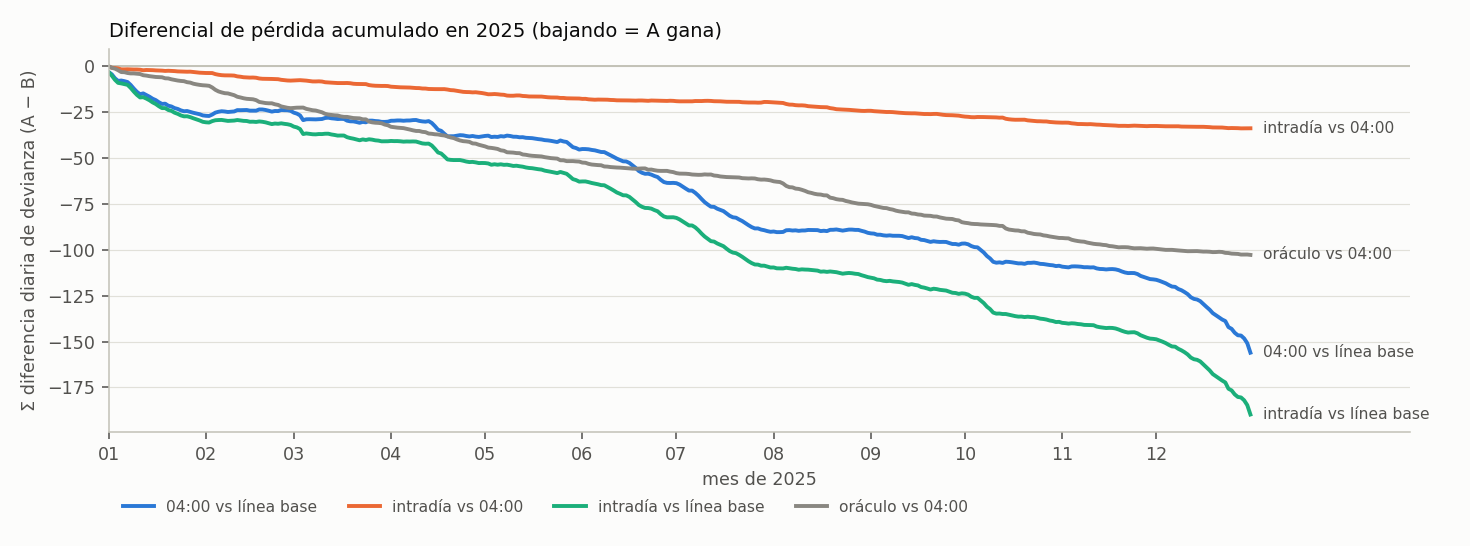

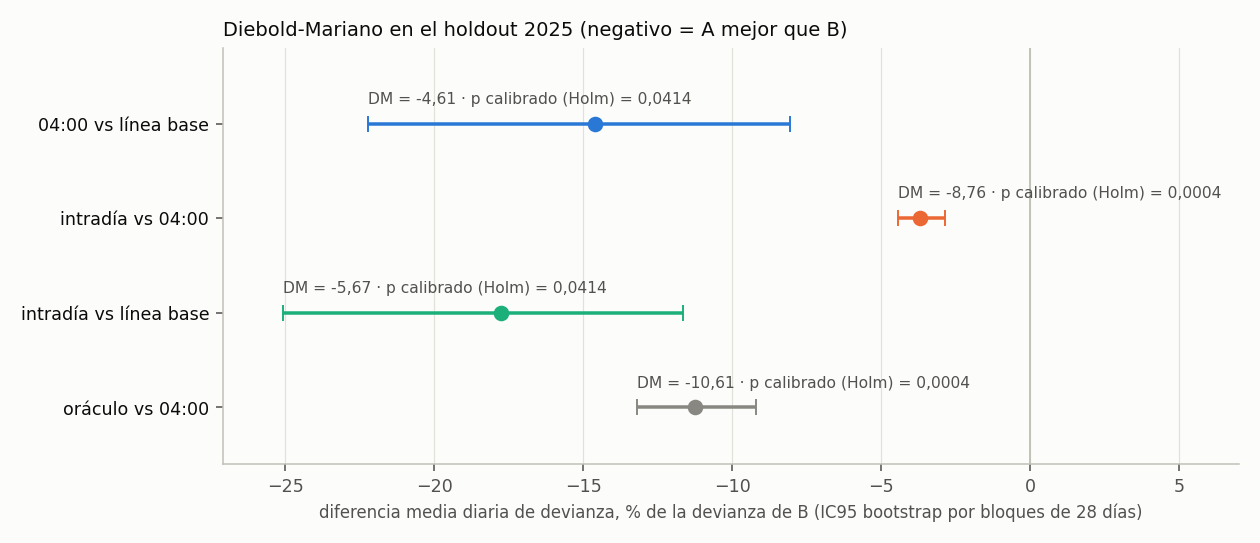

In [233]:
D.fig_acumulado(d, FIG / "diferencial_acumulado_2025.png")
D.fig_dm(t, FIG / "dm_intervalos.png")
for f in ["diferencial_acumulado_2025.png", "dm_intervalos.png"]:
    display(Image(filename=str(FIG / f)))

**Conclusión 4 · Figuras**
- **Diferencial acumulado 04:00 vs línea base:** la ganancia se acumula en enero, de abril a julio, en octubre y sobre todo en diciembre, con tramos casi planos en febrero–marzo y agosto–septiembre.
  - Esos tramos planos son los meses de mayor subpredicción en la 8.1.
- **Intradía vs 04:00:** acumula casi en línea recta todo el año. **La ventaja de la cascada es constante, no depende de unos pocos días.**
- **Oráculo vs 04:00:** también estable. Cuantifica el valor de los datos en tiempo real (−11,2 %), que no es desplegable.

## 5 · Pruebas (a–e) y checks

In [234]:
pruebas = T.correr_todos(d, t, HASH_ANTES)
for _, f in pruebas.iterrows():
    check(f.check, f.resultado == "PASS", f.detalle)
display(pruebas)
check("Tiempo total de la ejecución", True, f"{(time.time() - T0) / 60:,.1f} min", info=True)
checks = pd.DataFrame(CHECKS)
checks.to_csv(SALIDA / "checks_8_3.csv", index=False)
display(checks)
print(f"PASS {int((checks.resultado == 'PASS').sum())} · FAIL {int((checks.resultado == 'FAIL').sum())} · INFO {int((checks.resultado == 'INFO').sum())}")

,check,resultado,detalle
0,Test a · Newey-West = statsmodels,PASS,"varianza de la media idéntica a statsmodels con rezagos 5, 21 y 28 (error máx. 1.9e-17)"
1,Test b · tamaño y potencia del DM,PASS,"φ = 0,3: tamaño 7,7%, potencia 99%; φ = 0,9: tamaño DM-NW 12% frente a 8% con el p calibrado"
2,Test c · agregación diaria = diferencia global,PASS,error máximo 1.0e-15; la diferencia 04:00 − línea base (-0.4259) coincide con holdout_7_3.csv
3,Test d · bootstrap reproducible,PASS,IC95 [-0.654; -0.238] idéntico con la misma semilla y contiene la media -0.427
4,Test e · los insumos no cambian,PASS,"6 archivos (predicciones 7.3, insumo DM y residuos 8.1, modelos) con el mismo SHA-256"


,check,resultado,detalle
0,DM · 04:00 vs línea base,INFO,14.5 % · DM-HLN -4.61 · p calibrado (Holm) 0.0414 · significativo y robusto
1,DM · intradía vs 04:00,INFO,3.9 % · DM-HLN -8.76 · p calibrado (Holm) 0.0004 · significativo y robusto
2,DM · intradía vs línea base,INFO,17.9 % · DM-HLN -5.67 · p calibrado (Holm) 0.0414 · significativo y robusto
3,DM · oráculo vs 04:00,INFO,11.2 % · DM-HLN -10.61 · p calibrado (Holm) 0.0004 · significativo y robusto
4,Test a · Newey-West = statsmodels,PASS,"varianza de la media idéntica a statsmodels con rezagos 5, 21 y 28 (error máx. 1.9e-17)"
5,Test b · tamaño y potencia del DM,PASS,"φ = 0,3: tamaño 7,7%, potencia 99%; φ = 0,9: tamaño DM-NW 12% frente a 8% con el p calibrado"
6,Test c · agregación diaria = diferencia global,PASS,error máximo 1.0e-15; la diferencia 04:00 − línea base (-0.4259) coincide con holdout_7_3.csv
7,Test d · bootstrap reproducible,PASS,IC95 [-0.654; -0.238] idéntico con la misma semilla y contiene la media -0.427
8,Test e · los insumos no cambian,PASS,"6 archivos (predicciones 7.3, insumo DM y residuos 8.1, modelos) con el mismo SHA-256"
9,Tiempo total de la ejecución,INFO,0.2 min


PASS 5 · FAIL 0 · INFO 5


**Conclusión 5 · Pruebas**
- **Pasan las 5 de 5 pruebas:**
  - **a)** la varianza de Newey-West es idéntica a la de statsmodels (error 1e-17);
  - **b)** tamaño 7,7 % y potencia 99 % con AR(1) φ = 0,3. Con φ = 0,9, el DM con Newey-West rechaza un 12 % y el p calibrado un 8 %: la calibración corrige la mayor parte de la distorsión, pero no toda;
  - **c)** la agregación diaria reproduce exactamente la diferencia global de la 7.3;
  - **d)** el bootstrap es reproducible;
  - **e)** ningún insumo cambió.
- Ejecución: 0,2 min.

---
# Parte 20 · Scripts independientes
Se ejecutan desde el código unificado, igual que `python <script>.py` en la raíz.

In [235]:
%reset -f
__import__("sobusa_codigo_unificado").nuevo_notebook("scripts")

── Inicio de scripts (kernel reiniciado: variables, opciones y módulos)


In [236]:
import sobusa_codigo_unificado as SOBUSA
# Subfase 6.0 · Parte 1: extracción de fecharegistro. Si datos_6/fecharegistro.csv existe, no consulta la RDS.
SOBUSA.ejecutar_script("extraer_fecharegistro_6_0")

Ya existe C:\Users\samit\AppData\Local\Temp\sobusa_unif\B\datos_6\fecharegistro.csv: no se vuelve a consultar la RDS.


In [237]:
import sobusa_codigo_unificado as SOBUSA
# Subfase 8.3: verifica que las cifras del informe ejecutivo salgan de los archivos recién generados.
SOBUSA.ejecutar_script("verificar_informe_8_3")

                         cifra    valor_fuente resultado
      viajes válidos (maestra)         497.371      PASS
           viajes en el modelo         496.302      PASS
            viajes del holdout         158.507      PASS
      devianza línea base 2025           2,929      PASS
           devianza 04:00 2025           2,503      PASS
        devianza intradía 2025           2,406      PASS
         devianza oráculo 2025           2,222      PASS
                  mejora 04:00          14,5 %      PASS
               mejora intradía          17,9 %      PASS
                mejora oráculo          24,1 %      PASS
                     MAE 04:00           20,71      PASS
                MAE línea base           23,49      PASS
              meses que mejora  11 de 12 meses      PASS
p calibrado Holm 04:00 vs base           0,041      PASS
     p calibrado 04:00 vs base           0,035      PASS
      p Holm intradía vs 04:00          0,0004      PASS
   mejora intradía sobre 04:00 